<a href="https://colab.research.google.com/github/MominaAzam07/Initial_Draft_Malnutrition_Detection_ARAN_DATASET/blob/main/ARAN_Anthropometry_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## ARAN DATASET

In [ ]:
import os, sys, random, hashlib, json
import numpy as np
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

import PIL, pandas as pd
print("python :", sys.version.split()[0])
print("torch  :", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu    :", torch.cuda.get_device_name(0))
print("pandas :", pd.__version__, "| pillow:", PIL.__version__)

python : 3.13.16
torch  : 2.14.1+cu130 | cuda available: True
gpu    : Tesla T4
pandas : 2.2.3 | pillow: 11.3.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

RAW = "/content/drive/MyDrive/ARAN_raw"
print(os.listdir(RAW))

Mounted at /content/drive
['labels.csv', 'Data from anwar Sheikha.zip', 'Male.zip', 'female.zip', 'checkpoints', 'results_baseline_scatter.png', 'results_baseline_predicted_vs_actual.csv', 'results_comparison_P1-P4.csv', 'results_final_comparison.csv', 'results_error_analysis.csv', 'landmarks_full.csv', 'aran_handoff_bundle.zip', 'results_best_scatter.png', 'worst8_height_children.png', 'split_repl.csv', 'manifest.csv', 'aran_work_768.zip', 'manifest_with_views.csv', 'split_v1_DRIFTED_donotuse.csv', 'target_stats_v1_DRIFTED_donotuse.json', 'split_v1.csv', 'target_stats_v1.json']


In [ ]:
import zipfile, time
DEST = "/content/aran"
os.makedirs(DEST, exist_ok=True)

for z in ["Data from anwar Sheikha.zip", "female.zip", "Male.zip"]:
    t0 = time.time()
    with zipfile.ZipFile(os.path.join(RAW, z)) as zf:
        zf.extractall(os.path.join(DEST, z.replace(".zip","").replace(" ","_")))
    print(f"{z}: extracted in {time.time()-t0:.0f}s")

Data from anwar Sheikha.zip: extracted in 42s
female.zip: extracted in 47s
Male.zip: extracted in 47s


In [ ]:
# === Structural peek: top 3 levels only ===
def tree(root, max_depth=3, max_children=6):
    root = root.rstrip("/")
    base_depth = root.count(os.sep)
    for dirpath, dirnames, filenames in sorted(os.walk(root)):
        depth = dirpath.count(os.sep) - base_depth
        if depth > max_depth:
            dirnames[:] = []
            continue
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/  [{len(dirnames)} dirs, {len(filenames)} files]")
        # show a few example filenames at this level
        for f in sorted(filenames)[:max_children]:
            print(f"{indent}  - {f}")
        dirnames[:] = sorted(dirnames)[:50] if depth < 1 else sorted(dirnames)[:3]  # sample subdirs deeper down

tree(DEST, max_depth=3)

aran/  [3 dirs, 0 files]
  Data_from_anwar_Sheikha/  [2 dirs, 0 files]
    Female/  [47 dirs, 0 files]
      Child0065/  [0 dirs, 4 files]
        - child0065_01.jpg
        - child0065_02.jpg
        - child0065_03.jpg
        - child0065_04.jpg
      Child0067/  [0 dirs, 4 files]
        - child0067_01.jpg
        - child0067_02.jpg
        - child0067_03.jpg
        - child0067_04.jpg
      Child0068/  [0 dirs, 4 files]
        - child0068_01.jpg
        - child0068_02.jpg
        - child0068_03.jpg
        - child0068_04.jpg
      Child0071/  [0 dirs, 4 files]
        - child0071_01.jpg
        - child0071_02.jpg
        - child0071_03.jpg
        - child0071_04.jpg
      Child0075/  [0 dirs, 4 files]
        - child0075_01.jpg
        - child0075_02.jpg
        - child0075_03.jpg
        - child0075_04.jpg
      Child0076/  [0 dirs, 4 files]
        - child0076_01.jpg
        - child0076_02.jpg
        - child0076_03.jpg
        - child0076_04.jpg
      Child0077/  [0 dirs, 4 file

In [ ]:
# === labels.csv peek ===
labels = pd.read_csv(os.path.join(RAW, "labels.csv"))
print(labels.shape)
print(labels.dtypes)
labels.head(10)

(512, 7)
child_id                     object
gender                       object
height in cm                float64
weight in grams               int64
head circumference in cm    float64
waistline in cm               int64
age in months                 int64
dtype: object


,child_id,gender,height in cm,weight in grams,head circumference in cm,waistline in cm,age in months
0,child0001,f,100.0,15000,51.0,53,42
1,child0002,f,118.0,28400,52.5,66,78
2,child0003,m,95.7,19000,50.0,52,33
3,child0004,m,109.5,21400,52.0,62,53
4,child0005,m,93.5,12100,50.0,49,36
5,child0006,m,94.0,13500,37.5,49,34
6,child0007,m,100.0,14200,48.0,50,48
7,child0008,f,116.0,22000,50.0,58,60
8,child0009,f,102.0,14400,47.0,50,46
9,child0010,m,104.0,17400,53.0,50,66


In [ ]:
# === Section 3.1: Enumerate child folders across all sites ===
import re, glob
import pandas as pd

DEST = "/content/aran"

records = []
for dirpath, dirnames, filenames in os.walk(DEST):
    imgs = [f for f in filenames if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if not imgs:
        continue
    folder = os.path.basename(dirpath)
    m = re.match(r"child(\d+)", folder, re.IGNORECASE)
    if not m:
        print("UNEXPECTED image folder (no childID pattern):", dirpath, "->", imgs[:3])
        continue
    rel = os.path.relpath(dirpath, DEST)
    parts = rel.split(os.sep)
    site = "AnwarSheikha" if "anwar" in parts[0].lower() else "JAR"
    # sex hint from folder path if present
    sex_folder = next((p.lower() for p in parts if p.lower() in ("male", "female", "m", "f")), None)
    records.append({
        "child_id": "child" + m.group(1).zfill(4),
        "folder": dirpath,
        "site": site,
        "sex_folder": {"male":"m","female":"f","m":"m","f":"f"}.get(sex_folder),
        "n_images": len(imgs),
        "image_files": sorted(imgs),
    })

folders = pd.DataFrame(records)
print("Total child folders found:", len(folders))
print("Unique child_ids:", folders.child_id.nunique())
dupes = folders[folders.child_id.duplicated(keep=False)]
print("Child IDs appearing in MULTIPLE folders:", dupes.child_id.nunique())
if len(dupes): print(dupes[["child_id","folder"]].to_string())
print("\nFolders per site / sex-folder:")
print(folders.groupby(["site","sex_folder"], dropna=False).size())
print("\nImages-per-child distribution:")
print(folders.n_images.value_counts().sort_index())

Total child folders found: 512
Unique child_ids: 512
Child IDs appearing in MULTIPLE folders: 0

Folders per site / sex-folder:
site          sex_folder
AnwarSheikha  f              47
              m              55
JAR           f             211
              m             199
dtype: int64

Images-per-child distribution:
n_images
4    508
5      4
Name: count, dtype: int64


In [ ]:
# === Section 3.2: Filename convention check ===
suffix_counter = {}
violations = []
for _, r in folders.iterrows():
    for f in r.image_files:
        m = re.match(r"child(\d+)_(\d+)\.(jpg|jpeg|png)$", f, re.IGNORECASE)
        if not m:
            violations.append((r.child_id, f))
        else:
            if "child"+m.group(1).zfill(4) != r.child_id:
                violations.append((r.child_id, f, "ID-in-filename mismatch"))
            suffix_counter[m.group(2)] = suffix_counter.get(m.group(2), 0) + 1

print("Suffix distribution (view index -> count):")
for k in sorted(suffix_counter): print(f"  _{k}: {suffix_counter[k]}")
print("\nConvention violations:", len(violations))
for v in violations[:20]: print("  ", v)

Suffix distribution (view index -> count):
  _01: 504
  _02: 505
  _03: 507
  _04: 505
  _05: 3

Convention violations: 30
   ('child0408', 'child0408 _01.jpg')
   ('child0408', 'child0408 _02.jpg')
   ('child0408', 'child0408 _03.jpg')
   ('child0408', 'child0408 _04.jpg')
   ('child0181', '.jpg')
   ('child0446', 'child0446 _04.jpg')
   ('child0281', 'child0281_01p.jpg')
   ('child0476', 'IMG_20230313_220829.jpg')
   ('child0336', 'childo336_04.jpg')
   ('child0491', 'child04 91_01.jpg')
   ('child0201', 'child0202_03.jpg', 'ID-in-filename mismatch')
   ('child0012', 'cbild0012_03.jpg')
   ('child0020', 'child 0020_02.jpg')
   ('child0013', 'child 0013_01.jpg')
   ('child0013', 'child 0013_02.jpg')
   ('child0013', 'child 0013_03.jpg')
   ('child0013', 'child 0013_04.jpg')
   ('child0058', 'child0058_ 01.jpg')
   ('child0078', 'child0078__02.jpg')
   ('child0016', 'child 0016_03.jpg')


In [ ]:
# === Section 3.3: Reconcile folders vs labels.csv ===
labels = pd.read_csv(os.path.join(RAW, "labels.csv"))
labels.columns = [c.strip() for c in labels.columns]
labels["child_id"] = labels["child_id"].str.strip().str.lower()
labels["weight_kg"] = labels["weight in grams"] / 1000.0

folder_ids = set(folders.child_id)
label_ids  = set(labels.child_id)
print("In labels but NO folder :", sorted(label_ids - folder_ids)[:20], "... total:", len(label_ids - folder_ids))
print("Folder but NO label     :", sorted(folder_ids - label_ids)[:20], "... total:", len(folder_ids - label_ids))
print("Matched children        :", len(folder_ids & label_ids))

df = folders.merge(labels, on="child_id", how="inner")
sex_mismatch = df[(df.sex_folder.notna()) & (df.sex_folder != df.gender.str.lower().str.strip())]
print("\nSex mismatch folder-vs-labels:", len(sex_mismatch))
if len(sex_mismatch): print(sex_mismatch[["child_id","site","sex_folder","gender"]].to_string())

In labels but NO folder : [] ... total: 0
Folder but NO label     : [] ... total: 0
Matched children        : 512

Sex mismatch folder-vs-labels: 0


In [ ]:
# === Section 3.4: Label quality — missing values, ranges, outlier flags ===
print("Missing values per column:\n", labels.isna().sum())
print("\nDescriptive stats:")
print(labels[["height in cm","weight_kg","head circumference in cm","waistline in cm","age in months"]]
      .describe().round(2).to_string())

# Plausibility windows for ages 16-98 months (deliberately WIDE - flags, not deletions)
flags = labels[
    (labels["height in cm"].lt(65) | labels["height in cm"].gt(145)) |
    (labels["weight_kg"].lt(6) | labels["weight_kg"].gt(45)) |
    (labels["head circumference in cm"].lt(42) | labels["head circumference in cm"].gt(58)) |
    (labels["waistline in cm"].lt(35) | labels["waistline in cm"].gt(80)) |
    (labels["age in months"].lt(16) | labels["age in months"].gt(98))
]
print(f"\nFlagged implausible rows: {len(flags)}")
print(flags[["child_id","gender","age in months","height in cm","weight_kg",
             "head circumference in cm","waistline in cm"]].to_string())

Missing values per column:
 child_id                    0
gender                      0
height in cm                0
weight in grams             0
head circumference in cm    0
waistline in cm             0
age in months               0
weight_kg                   0
dtype: int64

Descriptive stats:
       height in cm  weight_kg  head circumference in cm  waistline in cm  age in months
count        512.00     512.00                    512.00           512.00         512.00
mean         110.99      18.98                     50.19            53.42          65.43
std           12.20       5.18                      2.46             5.37          20.22
min           73.00       9.30                     37.50            36.00          16.00
25%          101.00      15.20                     49.00            50.00          48.00
50%          112.00      17.90                     50.00            53.00          65.00
75%          120.00      22.00                     52.00            55.00   

In [ ]:
# === Section 3.5: Image dimension & integrity scan (headers only - fast) ===
from PIL import Image
dims, corrupt = {}, []
for _, r in folders.iterrows():
    for f in r.image_files:
        p = os.path.join(r.folder, f)
        try:
            with Image.open(p) as im:
                dims[im.size] = dims.get(im.size, 0) + 1
        except Exception as e:
            corrupt.append((p, str(e)))
print("Distinct (width,height) sizes:")
for s, c in sorted(dims.items(), key=lambda kv: -kv[1])[:15]:
    print(f"  {s}: {c} images")
print("Corrupt/unreadable:", len(corrupt))
for c in corrupt[:10]: print("  ", c)

Distinct (width,height) sizes:
  (2736, 3648): 1672 images
  (960, 1280): 364 images
  (3840, 5120): 12 images
  (2441, 3648): 1 images
  (2525, 3413): 1 images
  (2536, 3638): 1 images
  (3648, 2736): 1 images
Corrupt/unreadable: 0


In [ ]:
###TESting
rows = []
for _, r in folders.iterrows():
    for f in r.image_files:
        with Image.open(os.path.join(r.folder, f)) as im:
            ex = im.getexif()
            rows.append(dict(folder=r.folder, file=f, w=im.size[0], h=im.size[1],
                             orient=ex.get(274), make=ex.get(271), model=ex.get(272),
                             focal=ex.get_ifd(0x8769).get(37386)))
meta = pd.DataFrame(rows)
meta["tier"] = meta.w.astype(str) + "x" + meta.h.astype(str)
print(meta.groupby(["tier","make","model","focal","orient"], dropna=False).size())
print(meta.groupby("folder").tier.nunique().value_counts())  # >1 = mixed sizes in one child

tier       make    model    focal  orient
2441x3648  HUAWEI  LYA-L29  5.58   1.0          1
2525x3413  HUAWEI  LYA-L29  5.58   1.0          1
2536x3638  HUAWEI  LYA-L29  5.58   1.0          1
2736x3648  HUAWEI  LYA-L29  5.58   0.0       1672
3648x2736  HUAWEI  LYA-L29  5.58   6.0          1
3840x5120  HUAWEI  LYA-L29  2.35   0.0         12
960x1280   NaN     NaN      NaN    NaN        364
dtype: int64
tier
1    506
2      6
Name: count, dtype: int64


In [ ]:
rows = []
for _, r in folders.iterrows():
    for f in r.image_files:
        p = os.path.join(r.folder, f)
        with Image.open(p) as im:
            ex = im.getexif()
            rows.append(dict(
                child=os.path.basename(r.folder), file=f,
                tier=f"{im.size[0]}x{im.size[1]}",
                bytes=os.path.getsize(p),
                mtime=pd.to_datetime(os.path.getmtime(p), unit="s"),
                exif_date=ex.get_ifd(0x8769).get(36867),
                has_icc=bool(im.info.get("icc_profile")),
                q0=tuple(im.quantization[0][:4]) if hasattr(im, "quantization") else None,
                software=ex.get(305)))
m = pd.DataFrame(rows)

# 1) is the tier per child or per view?
m["view"] = m.file.str.extract(r"(front|back|left|right)", expand=False)
print(pd.crosstab(m.view, m.tier))                 # one view tier-specific?
print(m.groupby("child").tier.nunique().value_counts())

# 2) does it follow child order / date / folder naming?
m["order"] = m.child.rank(method="dense")
print(m.groupby("tier").order.describe())          # contiguous block of IDs?
print(m.groupby("tier")[["exif_date","mtime"]].agg(["min","max"]))

# 3) was the low tier re-encoded?
print(m.groupby("tier")[["has_icc","q0","software"]].agg(lambda s: s.value_counts(dropna=False).to_dict()))
print(m.groupby("tier").bytes.median())

Empty DataFrame
Columns: []
Index: []
tier
1    506
2      6
Name: count, dtype: int64
            count        mean         std    min     25%    50%    75%    max
tier                                                                         
2441x3648     1.0  446.000000         NaN  446.0  446.00  446.0  446.0  446.0
2525x3413     1.0  392.000000         NaN  392.0  392.00  392.0  392.0  392.0
2536x3638     1.0  273.000000         NaN  273.0  273.00  273.0  273.0  273.0
2736x3648  1672.0  258.404904  152.179087    1.0  121.75  253.0  395.0  512.0
3648x2736     1.0   57.000000         NaN   57.0   57.00   57.0   57.0   57.0
3840x5120    12.0   87.500000   66.849220   13.0   44.00   51.0  177.0  177.0
960x1280    364.0  251.021978  124.998114   23.0  138.00  294.0  317.0  489.0
                     exif_date                       \
                           min                  max   
tier                                                  
2441x3648  2023:03:12 16:10:52  2023:03:12 16:

In [ ]:
# === Section 3.6: Duplicate image detection (perceptual hash) ===
!pip -q install imagehash
import imagehash
from collections import defaultdict

hashes = defaultdict(list)
for _, r in folders.iterrows():
    for f in r.image_files:
        p = os.path.join(r.folder, f)
        try:
            with Image.open(p) as im:
                im.thumbnail((256, 256))
                hashes[str(imagehash.phash(im))].append(f"{r.child_id}/{f}")
        except Exception:
            pass

dup_groups = {h: v for h, v in hashes.items() if len(v) > 1}
cross_child = {h: v for h, v in dup_groups.items()
               if len({x.split('/')[0] for x in v}) > 1}
print("Exact-pHash duplicate groups:", len(dup_groups))
print("Groups spanning DIFFERENT children (leakage risk!):", len(cross_child))
for h, v in list(dup_groups.items())[:10]: print("  ", v)

Exact-pHash duplicate groups: 1
Groups spanning DIFFERENT children (leakage risk!): 0
   ['child0181/.jpg', 'child0181/child0181_03.jpg']


In [ ]:
# === Section 3.7: Site x sex x age crosstab (future split stratification) ===
df["age_bin"] = pd.cut(df["age in months"], bins=[15,30,45,60,75,98],
                       labels=["16-30","31-45","46-60","61-75","76-98"])
print(pd.crosstab([df.site, df.gender.str.lower()], df.age_bin, margins=True).to_string())

age_bin              16-30  31-45  46-60  61-75  76-98  All
site         gender                                        
AnwarSheikha f           1      8     10     10     18   47
             m           2     10     10     17     16   55
JAR          f           6     36     58     42     69  211
             m           5     30     57     46     61  199
All                     14     84    135    115    164  512


### ARAN Dataset Profile
**Audited copy:** DataverseNL distribution (3 ZIPs + labels.csv)


## 1. Structure
| Property | Verified value |
|---|---|
| Children (unique child_id) | 512 — folders and labels.csv match 1:1, no orphans either direction |
| Total images | 2,051 files (508 children × 4, plus 4 children with a 5th file) |
| Duplicates | 1 group only: `child0181/.jpg` = pHash-identical copy of `child0181_03.jpg`. **No cross-child duplicates.** |
| Sites | Anwar Sheikha (private): 102 children (47 f / 55 m) · JAR (public): 410 children (211 f / 199 m) |
| Site recoverable | Yes, from ZIP/folder structure (not in labels.csv) |
| Sex | From labels.csv `gender` (f/m); 100% consistent with Male/Female folder placement |
| Views | Filename suffix `_01…_04` (+3 `_05` retakes). Semantic meaning (front/back/left/right) **NOT yet verified** → Section 4 visual check |
| Official split | None provided → we create our own child-level split |

## 2. Labels (per child, labels.csv — no missing values)
| Variable | Range (audited) | Mean ± SD | Notes |
|---|---|---|---|
| height in cm | 73.0–146.0 | 111.0 ± 12.2 | 146 cm flagged (child0068) |
| weight (grams → kg) | 9.3–48.0 kg | 18.98 ± 5.18 | 48 kg plausible obesity (child0130) |
| head circumference cm | 37.5–69.0 | 50.19 ± 2.46 | 37.5 / 41 / 69 flagged as likely entry errors |
| waistline cm (int) | 36–84 | 53.42 ± 5.37 | |
| age in months | 16–98 | 65.4 ± 20.2 | Only 14 children in 16–30 mo bin |
| **NOT present** | — | — | **MUAC, WHO z-scores, landmarks, segmentation, height-type (standing/recumbent), measurement date** |

## 3. Flagged label outliers (7 rows, 1.4%)
| child_id | Issue | Working decision |
|---|---|---|
| child0006 | HC 37.5 cm @ 34 mo — impossible | Exclude HC target only; keep for H/W/waist |
| child0268 | HC 41 cm @ 96 mo — implausible | Exclude HC target only |
| child0189 | HC 69 cm — implausible | Exclude HC target only |
| child0068 | Height 146 cm @ 61 mo, weight 18.9 kg — inconsistent | Exclude height target only |
| child0167 | HC 41 @ 32 mo — borderline | Keep, flag in error analysis |
| child0130 | 48 kg, waist 84 @ 96 mo — internally consistent (obesity) | Keep |
| child0191 | HC 62 @ 96 mo, 28.6 kg — borderline | Keep, flag |

## 4. Images
| Property | Verified value |
|---|---|
| Format | JPG, sRGB, zero corrupt/unreadable |
| Resolutions | 2736×3648: 1,672 (81.5%) · **960×1280: 364 (17.8%)** · 3840×5120: 12 · odd sizes: 3 (1 landscape) |
| Resolution note | Two distinct populations → second device or compressed transfer batch. Cluster-by-site check pending (Section 4). Resolution = error-analysis factor. |
| Filename noise | 30 files with space/typo/underscore variants (`child 0015_…`, `cbild0012`, `child0078__02`, `child00098`, one empty `.jpg`) — all recoverable by tolerant parser |
| Content properties | Clothed children, cartoon face masks, hospital wall + measuring tape background (per paper; visual confirmation in Section 4) |

## 5. Leakage assessment
- Multiple images per child → **image-level random splits are invalid; split by child_id** (mandatory).
- No cross-child duplicate images (pHash-verified) → no hidden identity leakage via retakes.
- No timestamps/EXIF checked yet for repeat visits; single-visit protocol per paper.
- Metadata leakage: site is recoverable from path — keep site out of model inputs unless studied deliberately.
- Caches (crops, landmarks, embeddings) must be keyed by child_id and generated per split policy.

## 6. Verified capabilities vs. limits
| Research capability | Status |
|---|---|
| Multi-view regression (4 standardized views/child) |  Supported (pending view-order verification) |
| Height/weight/waist/HC regression | Supported, 512 children |
| WHO z-score derivation (WAZ, HAZ/stunting, BMI-for-age) |  Derivable from age+sex+height+weight (secondary labels, hospital sample caveat) |
| Weight-for-height z / wasting |  Derivable (WHO WFH tables, 65–120 cm range covers most) |
| Landmark extraction (MediaPipe) on clothed+masked children |  To be tested — failure rate itself is a result |
| Cross-site generalization (JAR↔AnwarSheikha) | Supported; asymmetric (410 vs 102) |
| MUAC estimation / MUAC cross-dataset transfer | Not possible — no MUAC in ARAN |
| Longitudinal growth |  Single visit |


In [ ]:
# === Section 4.1: Does low resolution cluster by site/child? ===
res_rows = []
for _, r in folders.iterrows():
    for f in r.image_files:
        with Image.open(os.path.join(r.folder, f)) as im:
            res_rows.append({"child_id": r.child_id, "site": r.site,
                             "file": f, "w": im.size[0], "h": im.size[1]})
res = pd.DataFrame(res_rows)
res["lowres"] = (res.w == 960)
print(pd.crosstab(res.site, res.lowres, margins=True))
by_child = res.groupby("child_id").lowres.mean()
print("\nChildren all-lowres:", (by_child == 1).sum(),
      "| mixed:", ((by_child > 0) & (by_child < 1)).sum(),
      "| all-highres:", (by_child == 0).sum())

lowres        False  True   All
site                           
AnwarSheikha    407     4   411
JAR            1281   360  1641
All            1688   364  2052

Children all-lowres: 91 | mixed: 0 | all-highres: 421


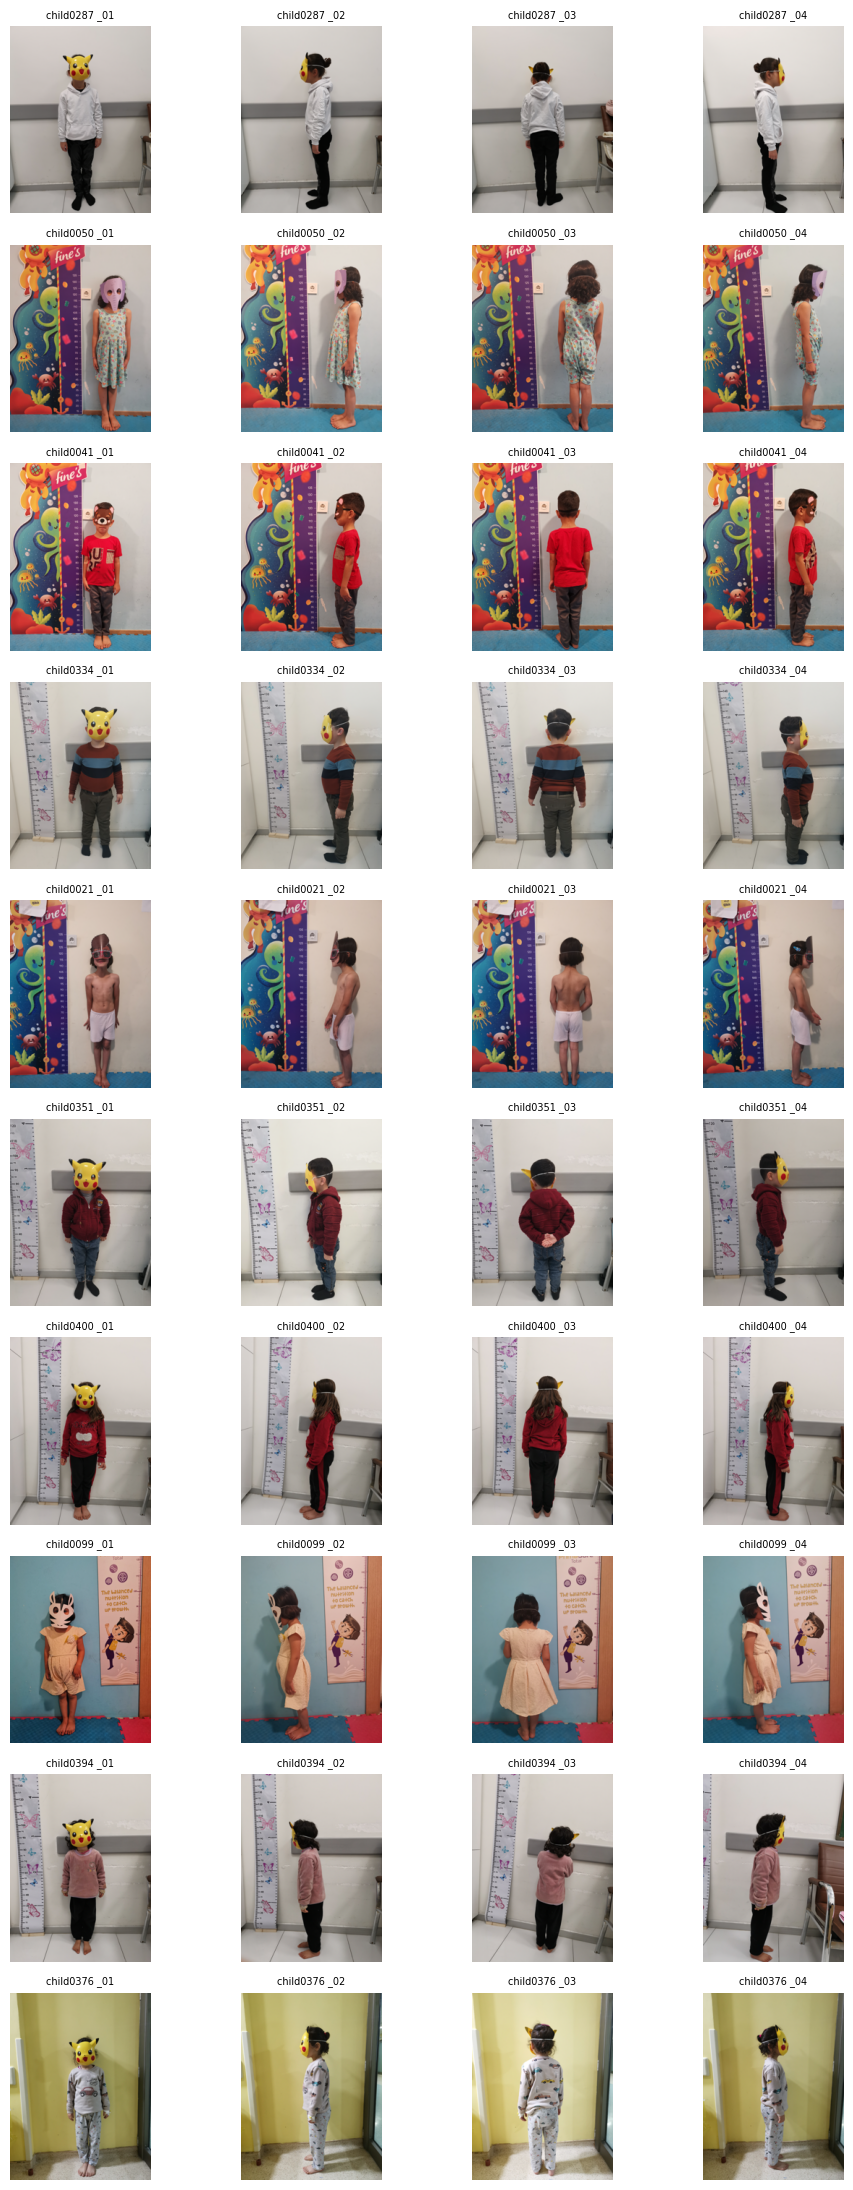

In [ ]:
# === Section 4.2: View-order verification grid ===
import matplotlib.pyplot as plt

def suffix_of(fname):
    m = re.search(r"_+\s*(\d+)\.jpg$", fname, re.IGNORECASE)
    return m.group(1)[-2:].zfill(2) if m else None

sample = folders.sample(10, random_state=SEED)   #  random children
fig, axes = plt.subplots(10, 4, figsize=(10, 22))
for i, (_, r) in enumerate(sample.iterrows()):
    fmap = {suffix_of(f): f for f in r.image_files if suffix_of(f)}
    for j, sfx in enumerate(["01", "02", "03", "04"]):
        ax = axes[i, j]; ax.axis("off")
        if sfx in fmap:
            with Image.open(os.path.join(r.folder, fmap[sfx])) as im:
                im.thumbnail((260, 260)); ax.imshow(im)
        ax.set_title(f"{r.child_id} _{sfx}", fontsize=7)
plt.tight_layout(); plt.show()

Children with 5 files: ['child0181', 'child0003', 'child0010', 'child0011']
Odd-size/landscape images:
        child_id          site               file     w     h  lowres
445   child0446           JAR  child0446 _04.jpg  2441  3648   False
831   child0392           JAR   child0392_03.jpg  2525  3413   False
934   child0273           JAR   child0273_02.jpg  2536  3638   False
2033  child0015  AnwarSheikha  child 0015_02.jpg  3648  2736   False


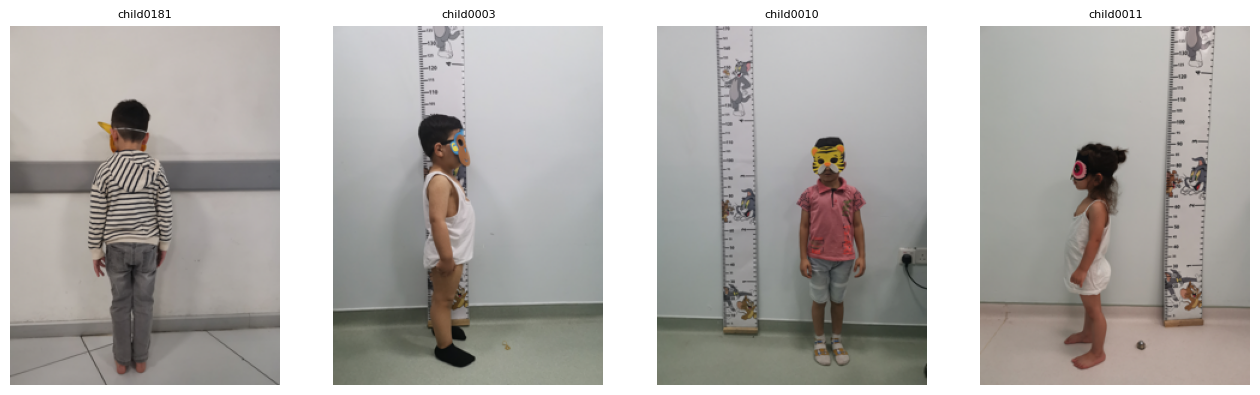

In [ ]:
# === Section 4.3: The _05 retakes and the odd images ===
extras = folders[folders.n_images == 5]
odd = res[(~res.w.isin([2736, 960, 3840])) | (res.w > res.h)]
print("Children with 5 files:", extras.child_id.tolist())
print("Odd-size/landscape images:\n", odd.to_string())

show = []
for _, r in extras.iterrows():
    for f in r.image_files:
        if suffix_of(f) == "05" or f == ".jpg":
            show.append((r.child_id, os.path.join(r.folder, f)))
fig, axes = plt.subplots(1, max(len(show),1), figsize=(4*max(len(show),1), 5))
axes = [axes] if len(show) == 1 else axes
for ax, (cid, p) in zip(axes, show):
    with Image.open(p) as im:
        im.thumbnail((300, 300)); ax.imshow(im)
    ax.set_title(cid, fontsize=8); ax.axis("off")
plt.show()

In [ ]:
# === Section 5.1: Definitive manifest ===
manifest = []
for _, r in folders.iterrows():
    for f in r.image_files:
        if r.child_id == "child0181" and f == ".jpg":
            continue  # verified duplicate of _03
        m = re.search(r"_+\s*(\d+)\.jpe?g$", f, re.IGNORECASE)
        manifest.append({"child_id": r.child_id, "site": r.site, "file": f,
                         "path": os.path.join(r.folder, f),
                         "suffix": m.group(1)[-2:].zfill(2) if m else "??"})
man = pd.DataFrame(manifest)
print("Manifest images:", len(man), "| children:", man.child_id.nunique())
print("Unparsed suffixes:", (man.suffix == "??").sum())
print(man[man.suffix == "??"][["child_id","file"]].to_string())
print(man.suffix.value_counts().sort_index())

Manifest images: 2051 | children: 512
Unparsed suffixes: 1
      child_id               file
744  child0281  child0281_01p.jpg
suffix
01    510
02    512
03    512
04    512
05      3
29      1
??      1
Name: count, dtype: int64


In [ ]:
# === Section 5.2a: Find ALL truncated/undecodable files (full-decode scan) ===
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = False   # strict mode for the scan

bad_files = []
for i, row in man.iterrows():
    try:
        with Image.open(row.path) as im:
            im.load()                     # force FULL decode, not just header
    except Exception as e:
        bad_files.append({"idx": i, "child_id": row.child_id,
                          "file": row.file, "error": str(e)[:80]})
    if i % 400 == 0: print(f"{i}/{len(man)}")

print("\nTruncated/undecodable files:", len(bad_files))
for b in bad_files: print("  ", b)

0/2051
400/2051
800/2051
1200/2051
1600/2051
2000/2051

Truncated/undecodable files: 3
   {'idx': 144, 'child_id': 'child0126', 'file': 'child0126_01.jpg', 'error': 'image file is truncated (20 bytes not processed)'}
   {'idx': 481, 'child_id': 'child0120', 'file': 'child0120_02.jpg', 'error': 'image file is truncated (36 bytes not processed)'}
   {'idx': 717, 'child_id': 'child0129', 'file': 'child0129_02.jpg', 'error': 'image file is truncated (29 bytes not processed)'}


In [ ]:
# === Section 5.2b: Resized working copy (tolerant + resumable) ===
ImageFile.LOAD_TRUNCATED_IMAGES = True    # tolerate truncated tails, log handled above

WORK = "/content/aran_work"; os.makedirs(WORK, exist_ok=True)
LONG_SIDE = 768
failed = []

for i, row in man.iterrows():
    outdir = os.path.join(WORK, row.child_id); os.makedirs(outdir, exist_ok=True)
    outp = os.path.join(outdir, f"{row.child_id}_{row.suffix}_{i}.jpg")
    man.loc[i, "work_path"] = outp
    if os.path.exists(outp): continue          # resume support
    try:
        with Image.open(row.path) as im:
            im = im.convert("RGB"); im.thumbnail((LONG_SIDE, LONG_SIDE))
            im.save(outp, quality=92)
    except Exception as e:
        failed.append((row.child_id, row.file, str(e)[:60]))
    if i % 400 == 0: print(f"{i}/{len(man)}")

print("Completely failed conversions:", len(failed))
for f in failed: print("  ", f)
n_out = sum(len(files) for _,_,files in os.walk(WORK))
print("Images in working copy:", n_out, "(expect 2051)")
!du -sh {WORK}
!cd /content && zip -qr /content/drive/MyDrive/ARAN_raw/aran_work_768.zip aran_work
man.to_csv("/content/drive/MyDrive/ARAN_raw/manifest.csv", index=False)
print("Cached to Drive.")

0/2051
400/2051
800/2051
1200/2051
1600/2051
2000/2051
Completely failed conversions: 0
Images in working copy: 2051 (expect 2051)
143M	/content/aran_work
Cached to Drive.


In [ ]:
# === Section 5.3 (Tasks API): pose pass -> view classification + failure rate ===
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/latest/pose_landmarker_lite.task
!pip install mediapipe
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision as mp_vision
import numpy as np

options = mp_vision.PoseLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path="pose_landmarker.task"),
    running_mode=mp_vision.RunningMode.IMAGE,
    num_poses=1,
    min_pose_detection_confidence=0.3,
)
landmarker = mp_vision.PoseLandmarker.create_from_options(options)

results_rows = []
for i, row in man.iterrows():
    img = np.array(Image.open(row.work_path).convert("RGB"))
    mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=img)
    res = landmarker.detect(mp_img)
    if not res.pose_landmarks:
        results_rows.append({"idx": i, "detected": False})
        continue
    lm = res.pose_landmarks[0]                     # first (only) person
    nose_v = lm[0].visibility if lm[0].visibility is not None else 0
    l_sh, r_sh = lm[11], lm[12]
    sh_width  = abs(l_sh.x - r_sh.x)
    hip_width = abs(lm[23].x - lm[24].x)
    # Front/back via shoulder ordering: in a FRONTAL view the subject's left
    # shoulder appears on the image-RIGHT (l_sh.x > r_sh.x); flips when seen from back.
    if sh_width < 0.08:
        view = "side"
    elif l_sh.x > r_sh.x:
        view = "front"
    else:
        view = "back"
    results_rows.append({"idx": i, "detected": True, "view": view,
                         "nose_v": round(float(nose_v), 2),
                         "sh_width": round(sh_width, 3),
                         "hip_width": round(hip_width, 3)})
    if i % 400 == 0: print(f"{i}/{len(man)}")

landmarker.close()
pose_df = pd.DataFrame(results_rows).set_index("idx")
man2 = man.join(pose_df)
man2["detected"] = man2["detected"].fillna(False)

print("\n=== Landmark detection failure rate (RQ-B data point #1) ===")
print("Detected:", int(man2.detected.sum()), "/", len(man2),
      f"({100*man2.detected.mean():.1f}%)")
print("\nDetection rate by site:")
print(man2.groupby("site").detected.agg(["mean","count"]).round(3))
print("\nDetection rate by resolution (lowres = 960px source):")
lowres_children = set(res_df.child_id[res_df.lowres]) if 'res_df' in dir() else None
print("\nView distribution (detected images):")
print(man2[man2.detected].view.value_counts())
print("\nViews per child (expect ~1 front, ~1 back, ~2 side):")
per_child = man2[man2.detected].groupby("child_id").view.value_counts().unstack(fill_value=0)
print(per_child.describe().round(2).to_string())
print("\nChildren with at least one 'front':", (per_child.get("front", 0) >= 1).sum(), "/ 512")
man2.to_csv("/content/drive/MyDrive/ARAN_raw/manifest_with_views.csv", index=False)
print("Saved manifest_with_views.csv to Drive.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 MB 52.0 MB/s  0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]
0/2051
400/2051
800/2051
1200/2051
1600/2051
2000/2051

=== Landmark detection failure rate (RQ-B data point #1) ===
Detected: 2044 / 2051 (99.7%)

Detection rate by site:
               mean  count
site                      
AnwarSheikha  1.000    411
JAR           0.996   1640

Detection rate by resolution (lowres = 960px source):

View distribution (detected images):
view
side     992
front    590
back     462
Name: count, dtype: int64

Views per child (expect ~1 front, ~1 back, ~2 side):
view     back   front    side
count  512.00  512.00  512.00
mean     0.90    1.15    1.94
std      0.36    0.41    0.36
min      0.00    0.00    0.00
25%      1.00    1.00    2.00
50%      1.00    1.00    2.00
7

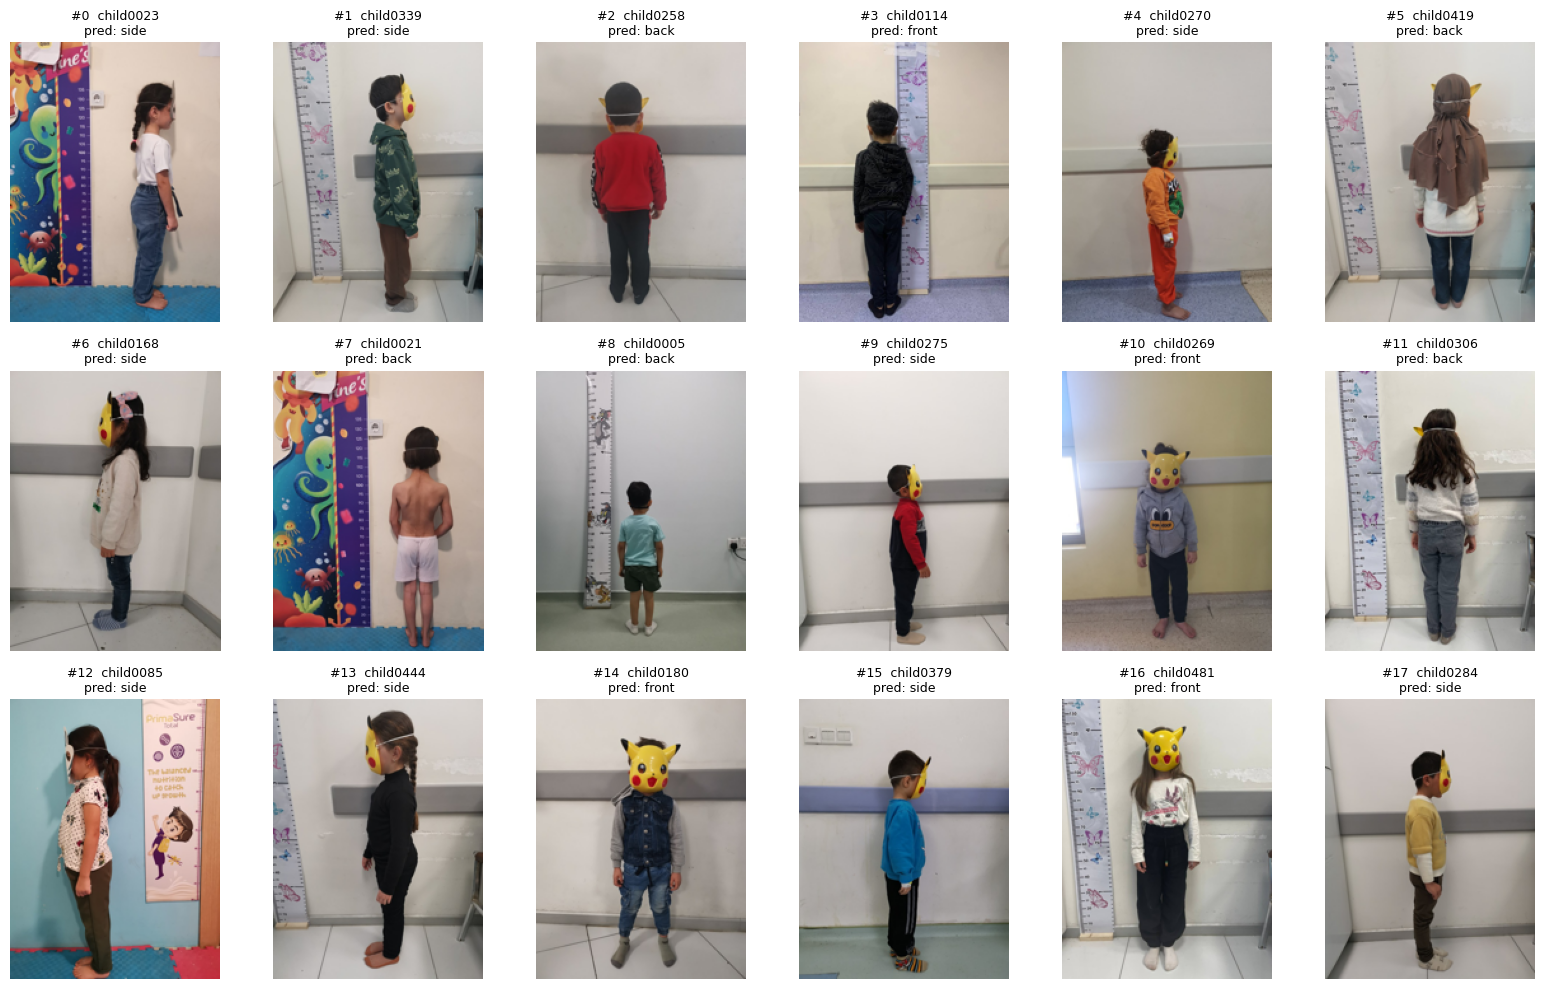

Index table (write TRUE view next to each after looking at the grid):
# 0  child0023   child0023_04.jpg           pred=side  sh_width=0.021
# 1  child0339   child0339_04.jpg           pred=side  sh_width=0.008
# 2  child0258   child0258_04.jpg           pred=back  sh_width=0.212
# 3  child0114   child0114_03.jpg           pred=front sh_width=0.177
# 4  child0270   child0270_04.jpg           pred=side  sh_width=0.05
# 5  child0419   child0419_03.jpg           pred=back  sh_width=0.161
# 6  child0168   child0168_02.jpg           pred=side  sh_width=0.045
# 7  child0021   child0021_03.jpg           pred=back  sh_width=0.199
# 8  child0005   child0005_03.jpg           pred=back  sh_width=0.137
# 9  child0275   child0275_04.jpg           pred=side  sh_width=0.033
#10  child0269   child0269_01.jpg           pred=front sh_width=0.181
#11  child0306   child0306_03.jpg           pred=back  sh_width=0.19
#12  child0085   child0085_02.jpg           pred=side  sh_width=0.019
#13  child0444   child

In [ ]:
# === Section 5.4 : view-classifier spot check ===
det = man2[man2.detected == True]
sample18 = det.sample(18, random_state=7)

fig, axes = plt.subplots(3, 6, figsize=(16, 10))
for k, (ax, (_, r)) in enumerate(zip(axes.flat, sample18.iterrows())):
    with Image.open(r["work_path"]) as im:
        im.thumbnail((220, 220)); ax.imshow(im)
    ax.set_title(f"#{k}  {r['child_id']}\npred: {r['view']}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Index table (write TRUE view next to each after looking at the grid):")
for k, (_, r) in enumerate(sample18.iterrows()):
    print(f"#{k:2d}  {r['child_id']:11s} {r['file']:26s} pred={r['view']:5s} "
          f"sh_width={r['sh_width']}")

In [ ]:
# === Section 6.1: Stratified child-level split (FROZEN after this run) ===
from sklearn.model_selection import train_test_split

kids = df[["child_id","site","gender","age in months"]].copy()   # df from Section 3.3
kids["gender"] = kids.gender.str.lower().str.strip()
kids["age_bin"] = pd.cut(kids["age in months"], bins=[15,45,65,84,98],
                         labels=["16-45","46-65","66-84","85-98"])  # quartile-ish bins
kids["stratum"] = kids.site + "_" + kids.gender + "_" + kids.age_bin.astype(str)

# collapse strata with <6 children so every stratum can appear in all 3 subsets
vc = kids.stratum.value_counts()
kids.loc[kids.stratum.isin(vc[vc < 6].index), "stratum"] = \
    kids.site + "_" + kids.gender  # fall back to coarser stratum

trainval_ids, test_ids = train_test_split(
    kids, test_size=0.15, stratify=kids.stratum, random_state=SEED)
train_ids, val_ids = train_test_split(
    trainval_ids, test_size=0.15/0.85, stratify=trainval_ids.stratum, random_state=SEED)

split = pd.concat([
    train_ids.assign(split="train"),
    val_ids.assign(split="val"),
    test_ids.assign(split="test"),
])[["child_id","split","site","gender","age_bin"]].sort_values("child_id")

# --- Hard leakage guarantees ---
s = {k: set(v.child_id) for k, v in split.groupby("split")}
assert s["train"] & s["val"]  == set()
assert s["train"] & s["test"] == set()
assert s["val"]   & s["test"] == set()
assert len(s["train"] | s["val"] | s["test"]) == 512
print("LEAKAGE CHECK PASSED: train/val/test child sets are disjoint, union = 512")

print("\nChildren per split:")
print(split.split.value_counts())
print("\nComposition check (proportions per split):")
for col in ["site","gender","age_bin"]:
    print(f"\n{col}:")
    print(pd.crosstab(split.split, split[col], normalize="index").round(3).to_string())

SPLIT_PATH = "/content/drive/MyDrive/ARAN_raw/split_v1.csv"
split.to_csv(SPLIT_PATH, index=False)
print("\nFROZEN split saved to:", SPLIT_PATH)

LEAKAGE CHECK PASSED: train/val/test child sets are disjoint, union = 512

Children per split:
split
train    358
val       77
test      77
Name: count, dtype: int64

Composition check (proportions per split):

site:
site   AnwarSheikha    JAR
split                     
test          0.208  0.792
train         0.196  0.804
val           0.208  0.792

gender:
gender      f      m
split               
test    0.494  0.506
train   0.508  0.492
val     0.494  0.506

age_bin:
age_bin  16-45  46-65  66-84  85-98
split                              
test     0.182  0.351  0.286  0.182
train    0.196  0.338  0.268  0.198
val      0.182  0.351  0.286  0.182

FROZEN split saved to: /content/drive/MyDrive/ARAN_raw/split_v1.csv


In [ ]:
# === Section 6.2: Target-distribution sanity across splits ===
m = split.merge(labels, on="child_id")
m["weight_kg"] = m["weight in grams"]/1000
print(m.groupby("split")[["height in cm","weight_kg",
      "head circumference in cm","waistline in cm","age in months"]]
      .agg(["mean","std"]).round(2).to_string())

      height in cm        weight_kg       head circumference in cm       waistline in cm       age in months       
              mean    std      mean   std                     mean   std            mean   std          mean    std
split                                                                                                              
test        110.77  12.09     19.16  5.75                    50.39  2.35           53.49  5.57         65.35  19.71
train       110.95  12.26     19.04  5.21                    50.18  2.39           53.50  5.50         65.67  20.31
val         111.41  12.16     18.56  4.45                    50.06  2.89           52.96  4.54         64.39  20.57


In [ ]:
# === Section 7.0: Session restore (use at the start of EVERY new session) ===
import os, re, random, json, numpy as np, pandas as pd, torch
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

from google.colab import drive
drive.mount('/content/drive')
RAW = "/content/drive/MyDrive/ARAN_raw"

if not os.path.exists("/content/aran_work"):
    !cd /content && unzip -q {RAW}/aran_work_768.zip
man2   = pd.read_csv(f"{RAW}/manifest_with_views.csv")
split  = pd.read_csv(f"{RAW}/split_v1.csv")
labels = pd.read_csv(f"{RAW}/labels.csv")
labels.columns = [c.strip() for c in labels.columns]
labels["child_id"] = labels["child_id"].str.strip().str.lower()
labels["weight_kg"] = labels["weight in grams"]/1000
print("restored:", len(man2), "images |", len(split), "children")

Mounted at /content/drive
restored: 2051 images | 512 children


In [ ]:
# === Section 7.1: Build the front-view baseline table ===
TARGETS = ["height in cm", "weight_kg", "waistline in cm", "head circumference in cm"]
TNAMES  = ["height_cm", "weight_kg", "waist_cm", "headcirc_cm"]

# per-target exclusions from the audit (loss-time masking, split untouched)
EXCLUDE = {"headcirc_cm": ["child0006","child0268","child0189"],
           "height_cm":   ["child0068"]}

det = man2[man2.detected == True].copy()
# one image per child for the baseline: prefer front; fall back side, then back
pref = {"front": 0, "side": 1, "back": 2}
det["pref"] = det["view"].map(pref)
base_imgs = det.sort_values(["child_id","pref","nose_v"], ascending=[True,True,False]) \
               .groupby("child_id").first().reset_index()

data = base_imgs.merge(labels, on="child_id").merge(split[["child_id","split"]], on="child_id")
print("baseline table:", len(data), "children | view used:")
print(data["view"].value_counts())

# target normalization stats from TRAIN ONLY (no leakage)
tr = data[data.split=="train"]
stats = {n: (tr[t].mean(), tr[t].std()) for n, t in zip(TNAMES, TARGETS)}
print("\ntrain-only normalization stats:", {k: (round(a,1), round(b,1)) for k,(a,b) in stats.items()})
json.dump(stats, open(f"{RAW}/target_stats_v1.json","w"))

baseline table: 512 children | view used:
view
front    509
side       3
Name: count, dtype: int64

train-only normalization stats: {'height_cm': (np.float64(110.8), 12.5), 'weight_kg': (np.float64(18.9), 5.3), 'waist_cm': (np.float64(53.4), 5.5), 'headcirc_cm': (np.float64(50.2), 2.6)}


In [ ]:
# === Section 7.2: Dataset & model ===
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import torchvision

IMSIZE = 384   # tall child images; 384 keeps limbs resolvable on T4
train_tf = T.Compose([
    T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ColorJitter(0.2, 0.2, 0.1),
    T.RandomHorizontalFlip(),          # safe: flips don't change body measurements
    T.RandomAffine(degrees=5, translate=(0.03, 0.03)),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])
eval_tf = T.Compose([
    T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

class AranSingleView(Dataset):
    def __init__(self, table, tf):
        self.t = table.reset_index(drop=True); self.tf = tf
    def __len__(self): return len(self.t)
    def __getitem__(self, i):
        r = self.t.iloc[i]
        x = self.tf(Image.open(r.work_path).convert("RGB"))
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]
            y.append((r[t]-mu)/sd)
            mask.append(0.0 if r.child_id in EXCLUDE.get(n, []) else 1.0)
        return x, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), r.child_id

def make_model():
    m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
    m.fc = torch.nn.Sequential(
        torch.nn.Linear(512, 128), torch.nn.ReLU(), torch.nn.Dropout(0.2),
        torch.nn.Linear(128, 4))
    return m

def masked_huber(pred, y, mask):
    l = torch.nn.functional.huber_loss(pred, y, reduction="none")
    return (l*mask).sum() / mask.sum().clamp(min=1)

dl_tr = DataLoader(AranSingleView(data[data.split=="train"], train_tf),
                   batch_size=24, shuffle=True,  num_workers=2)
dl_va = DataLoader(AranSingleView(data[data.split=="val"],   eval_tf),
                   batch_size=24, shuffle=False, num_workers=2)
print("train batches:", len(dl_tr), "| val batches:", len(dl_va))

train batches: 15 | val batches: 4


In [ ]:
# Define computation device
import torch

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", dev)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: Tesla T4


In [ ]:
# === Section 7.3  ===
# fresh model + optimizer so the sanity check starts clean
model = make_model().to(dev)
opt = torch.optim.AdamW([
    {"params": model.fc.parameters(), "lr": 3e-4},
    {"params": [p for n,p in model.named_parameters() if not n.startswith("fc")], "lr": 3e-5},
], weight_decay=1e-4)

def run_epoch(dl, train):
    model.train(train); tot, n = 0, 0
    abs_err = torch.zeros(4); cnt = torch.zeros(4)
    with torch.set_grad_enabled(train):
        for x, y, mask, _ in dl:
            x, y, mask = x.to(dev), y.to(dev), mask.to(dev)
            pred = model(x)
            loss = masked_huber(pred, y, mask)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(x); n += len(x)
            p = pred.detach()                          # FIX 1: no grad in bookkeeping
            for j, nm in enumerate(TNAMES):
                sd = stats[nm][1]
                e = ((p[:,j]-y[:,j]).abs()*sd*mask[:,j]).sum().cpu()
                abs_err[j] += e; cnt[j] += mask[:,j].sum().cpu()
    mae = (abs_err/cnt.clamp(min=1)).detach().numpy()  # FIX 2: belt and braces
    return tot/n, mae

for ep in range(2):
    trl, trmae = run_epoch(dl_tr, True)
    val, vamae = run_epoch(dl_va, False)
    print(f"epoch {ep}: train_loss={trl:.3f} val_loss={val:.3f}")
    print("   val MAE:", {n: round(float(m),2) for n,m in zip(TNAMES, vamae)})

va = data[data.split=="val"]
print("\nPredict-the-train-mean MAE (must beat this):")
print({n: round(float((va[t]-stats[n][0]).abs().mean()),2) for n,t in zip(TNAMES,TARGETS)})

epoch 0: train_loss=0.382 val_loss=0.309
   val MAE: {'height_cm': 8.72, 'weight_kg': 3.63, 'waist_cm': 3.55, 'headcirc_cm': 1.47}
epoch 1: train_loss=0.335 val_loss=0.261
   val MAE: {'height_cm': 7.26, 'weight_kg': 3.39, 'waist_cm': 3.33, 'headcirc_cm': 1.36}

Predict-the-train-mean MAE (must beat this):
{'height_cm': 9.37, 'weight_kg': 3.88, 'waist_cm': 3.81, 'headcirc_cm': 1.7}


In [ ]:
# === Section 8.1: Training function with early stopping + Drive checkpoints
CKPT_DIR = f"{RAW}/checkpoints"; os.makedirs(CKPT_DIR, exist_ok=True)

def train_baseline(seed, max_epochs=40, patience=8):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    global model, opt   # reuse run_epoch from 7.3
    model = make_model().to(dev)
    opt = torch.optim.AdamW([
        {"params": model.fc.parameters(), "lr": 3e-4},
        {"params": [p for n,p in model.named_parameters() if not n.startswith("fc")], "lr": 3e-5},
    ], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)

    dl_tr_s = DataLoader(AranSingleView(data[data.split=="train"], train_tf),
                         batch_size=24, shuffle=True, num_workers=2,
                         generator=torch.Generator().manual_seed(seed))

    hist, best, best_ep, bad = [], float("inf"), -1, 0
    ckpt = f"{CKPT_DIR}/baseline_seed{seed}.pt"
    for ep in range(max_epochs):
        trl, trmae = run_epoch(dl_tr_s, True)
        val, vamae = run_epoch(dl_va, False)
        sched.step()
        # selection metric: mean of per-target NORMALIZED MAE (fair across units)
        sel = float(np.mean([vamae[j]/stats[n][1] for j, n in enumerate(TNAMES)]))
        hist.append({"epoch": ep, "train_loss": trl, "val_loss": val, "sel": sel,
                     **{f"val_mae_{n}": float(m) for n, m in zip(TNAMES, vamae)}})
        flag = ""
        if sel < best:
            best, best_ep, bad = sel, ep, 0
            torch.save({"state": model.state_dict(), "epoch": ep, "seed": seed,
                        "stats": stats, "val_mae": dict(zip(TNAMES, map(float, vamae)))}, ckpt)
            flag = "  <-- saved"
        else:
            bad += 1
        print(f"seed{seed} ep{ep:02d} train={trl:.3f} val={val:.3f} sel={sel:.4f}"
              f" | h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}{flag}")
        if bad >= patience:
            print(f"early stop at epoch {ep} (best epoch {best_ep})"); break
    pd.DataFrame(hist).to_csv(f"{CKPT_DIR}/history_seed{seed}.csv", index=False)
    print(f"BEST seed{seed}: epoch {best_ep}, sel={best:.4f} -> {ckpt}")
    return ckpt

ckpt42 = train_baseline(42)

seed42 ep00 train=0.392 val=0.319 sel=0.6733 | h=8.84 w=3.57 wa=3.94 hc=1.55  <-- saved
seed42 ep01 train=0.344 val=0.274 sel=0.6062 | h=7.92 w=3.28 wa=3.50 hc=1.40  <-- saved
seed42 ep02 train=0.286 val=0.225 sel=0.5400 | h=6.25 w=2.89 wa=3.33 hc=1.33  <-- saved
seed42 ep03 train=0.244 val=0.204 sel=0.5034 | h=5.47 w=2.63 wa=3.13 hc=1.33  <-- saved
seed42 ep04 train=0.211 val=0.199 sel=0.4930 | h=4.95 w=2.53 wa=3.15 hc=1.36  <-- saved
seed42 ep05 train=0.201 val=0.192 sel=0.4806 | h=4.98 w=2.39 wa=3.10 hc=1.33  <-- saved
seed42 ep06 train=0.181 val=0.197 sel=0.4923 | h=5.51 w=2.39 wa=3.04 hc=1.37
seed42 ep07 train=0.168 val=0.183 sel=0.4704 | h=4.84 w=2.30 wa=3.06 hc=1.31  <-- saved
seed42 ep08 train=0.164 val=0.187 sel=0.4695 | h=4.77 w=2.27 wa=3.09 hc=1.32  <-- saved
seed42 ep09 train=0.153 val=0.198 sel=0.4973 | h=5.19 w=2.57 wa=3.14 hc=1.35
seed42 ep10 train=0.147 val=0.185 sel=0.4733 | h=5.05 w=2.23 wa=3.05 hc=1.34
seed42 ep11 train=0.132 val=0.187 sel=0.4799 | h=4.93 w=2.29 wa=3

In [ ]:
# === Section 8.2: Remaining seeds (run in this or a later session) ===
ckpt7  = train_baseline(7)
ckpt99 = train_baseline(99)

seed7 ep00 train=0.381 val=0.304 sel=0.6471 | h=8.62 w=3.45 wa=3.68 hc=1.50  <-- saved
seed7 ep01 train=0.327 val=0.271 sel=0.5925 | h=7.45 w=3.07 wa=3.40 hc=1.50  <-- saved
seed7 ep02 train=0.268 val=0.232 sel=0.5394 | h=6.66 w=2.78 wa=3.23 hc=1.34  <-- saved
seed7 ep03 train=0.232 val=0.200 sel=0.4905 | h=5.25 w=2.53 wa=3.11 hc=1.30  <-- saved
seed7 ep04 train=0.210 val=0.211 sel=0.5122 | h=5.67 w=2.55 wa=3.15 hc=1.41
seed7 ep05 train=0.215 val=0.200 sel=0.4893 | h=5.28 w=2.46 wa=3.02 hc=1.36  <-- saved
seed7 ep06 train=0.179 val=0.187 sel=0.4659 | h=4.75 w=2.35 wa=2.99 hc=1.29  <-- saved
seed7 ep07 train=0.169 val=0.202 sel=0.4988 | h=5.51 w=2.42 wa=3.07 hc=1.40
seed7 ep08 train=0.155 val=0.184 sel=0.4612 | h=4.76 w=2.28 wa=2.96 hc=1.29  <-- saved
seed7 ep09 train=0.147 val=0.181 sel=0.4621 | h=4.80 w=2.26 wa=2.93 hc=1.32
seed7 ep10 train=0.136 val=0.181 sel=0.4642 | h=4.88 w=2.31 wa=2.88 hc=1.32
seed7 ep11 train=0.138 val=0.179 sel=0.4556 | h=4.68 w=2.23 wa=2.86 hc=1.32  <-- saved


In [ ]:
# === Section 9.1: Test predictions from all 3 seeds ===
dl_te = DataLoader(AranSingleView(data[data.split=="test"], eval_tf),
                   batch_size=24, shuffle=False, num_workers=2)

def predict(ckpt_path):
    ck = torch.load(ckpt_path, map_location=dev, weights_only=False)
    model.load_state_dict(ck["state"]); model.eval()
    rows = []
    with torch.no_grad():
        for x, y, mask, cids in dl_te:
            p = model(x.to(dev)).cpu().numpy()
            for k, cid in enumerate(cids):
                r = {"child_id": cid}
                for j, n in enumerate(TNAMES):
                    mu, sd = stats[n]
                    r[f"pred_{n}"] = p[k, j]*sd + mu
                rows.append(r)
    return pd.DataFrame(rows)

preds = {}
for seed in [42, 7, 99]:
    preds[seed] = predict(f"{CKPT_DIR}/baseline_seed{seed}.pt")
    print(f"seed {seed}: {len(preds[seed])} test children predicted")

# actuals + mask info
actual = data[data.split=="test"][["child_id"] + TARGETS].rename(
    columns=dict(zip(TARGETS, [f"true_{n}" for n in TNAMES])))

seed 42: 77 test children predicted
seed 7: 77 test children predicted
seed 99: 77 test children predicted


In [ ]:
# === Section 9.2: Metrics with bootstrap CIs ===
from scipy.stats import pearsonr

def metrics_frame(pred_df):
    m = pred_df.merge(actual, on="child_id")
    out = {}
    for n in TNAMES:
        excl = EXCLUDE.get(n, [])
        sub = m[~m.child_id.isin(excl)]
        e = sub[f"pred_{n}"] - sub[f"true_{n}"]
        r, _ = pearsonr(sub[f"pred_{n}"], sub[f"true_{n}"])
        ss_res = (e**2).sum(); ss_tot = ((sub[f"true_{n}"]-sub[f"true_{n}"].mean())**2).sum()
        out[n] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()),
                  "R2": 1-ss_res/ss_tot, "r": r, "n": len(sub)}
    return pd.DataFrame(out).T

per_seed = {s: metrics_frame(p) for s, p in preds.items()}
mean_tbl = sum(per_seed.values())/3
sd_tbl = np.sqrt(sum((t-mean_tbl)**2 for t in per_seed.values())/2)
print("=== Single-view baseline, TEST (mean over 3 seeds) ===")
print(mean_tbl.round(3).to_string())
print("\n=== SD across seeds ===")
print(sd_tbl.round(3).to_string())

# bootstrap CI over children (seed-ensemble predictions)
ens = preds[42].copy()
for n in TNAMES:
    ens[f"pred_{n}"] = (preds[42][f"pred_{n}"]+preds[7][f"pred_{n}"]+preds[99][f"pred_{n}"])/3
me = ens.merge(actual, on="child_id")
print("\n=== Seed-ensemble MAE with 95% bootstrap CI (1000 resamples) ===")
rng = np.random.default_rng(SEED)
for n in TNAMES:
    sub = me[~me.child_id.isin(EXCLUDE.get(n, []))].reset_index(drop=True)
    err = (sub[f"pred_{n}"]-sub[f"true_{n}"]).abs().values
    boots = [err[rng.integers(0, len(err), len(err))].mean() for _ in range(1000)]
    print(f"{n:12s} MAE={err.mean():.2f}  CI95=[{np.percentile(boots,2.5):.2f}, {np.percentile(boots,97.5):.2f}]")

=== Single-view baseline, TEST (mean over 3 seeds) ===
               MAE   RMSE     R2      r     n
height_cm    4.922  6.561  0.669  0.831  77.0
weight_kg    2.088  2.873  0.642  0.823  77.0
waist_cm     3.211  4.101  0.217  0.477  77.0
headcirc_cm  1.330  1.695  0.071  0.408  77.0

=== SD across seeds ===
               MAE   RMSE     R2      r    n
height_cm    0.264  0.381  0.038  0.022  0.0
weight_kg    0.034  0.060  0.015  0.014  0.0
waist_cm     0.108  0.156  0.060  0.047  0.0
headcirc_cm  0.067  0.039  0.042  0.016  0.0

=== Seed-ensemble MAE with 95% bootstrap CI (1000 resamples) ===
height_cm    MAE=4.66  CI95=[3.79, 5.63]
weight_kg    MAE=1.95  CI95=[1.53, 2.40]
waist_cm     MAE=3.15  CI95=[2.65, 3.73]
headcirc_cm  MAE=1.29  CI95=[1.06, 1.54]


In [ ]:
# === Section 9.3: Age+sex linear baseline (ARAN paper's reference model) ===
from sklearn.linear_model import LinearRegression
lin_tbl = {}
d_tr, d_te = data[data.split=="train"], data[data.split=="test"]
Xtr = np.c_[d_tr["age in months"], (d_tr.gender.str.lower()=="f").astype(int)]
Xte = np.c_[d_te["age in months"], (d_te.gender.str.lower()=="f").astype(int)]
for n, t in zip(TNAMES, TARGETS):
    keep_tr = ~d_tr.child_id.isin(EXCLUDE.get(n, [])); keep_te = ~d_te.child_id.isin(EXCLUDE.get(n, []))
    lr = LinearRegression().fit(Xtr[keep_tr.values], d_tr[t][keep_tr])
    e = lr.predict(Xte[keep_te.values]) - d_te[t][keep_te]
    lin_tbl[n] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean())}
print("=== Age+sex linear baseline, TEST ===")
print(pd.DataFrame(lin_tbl).T.round(3).to_string())

=== Age+sex linear baseline, TEST ===
               MAE   RMSE
height_cm    4.850  6.054
weight_kg    2.749  3.455
waist_cm     3.539  4.453
headcirc_cm  1.269  1.646


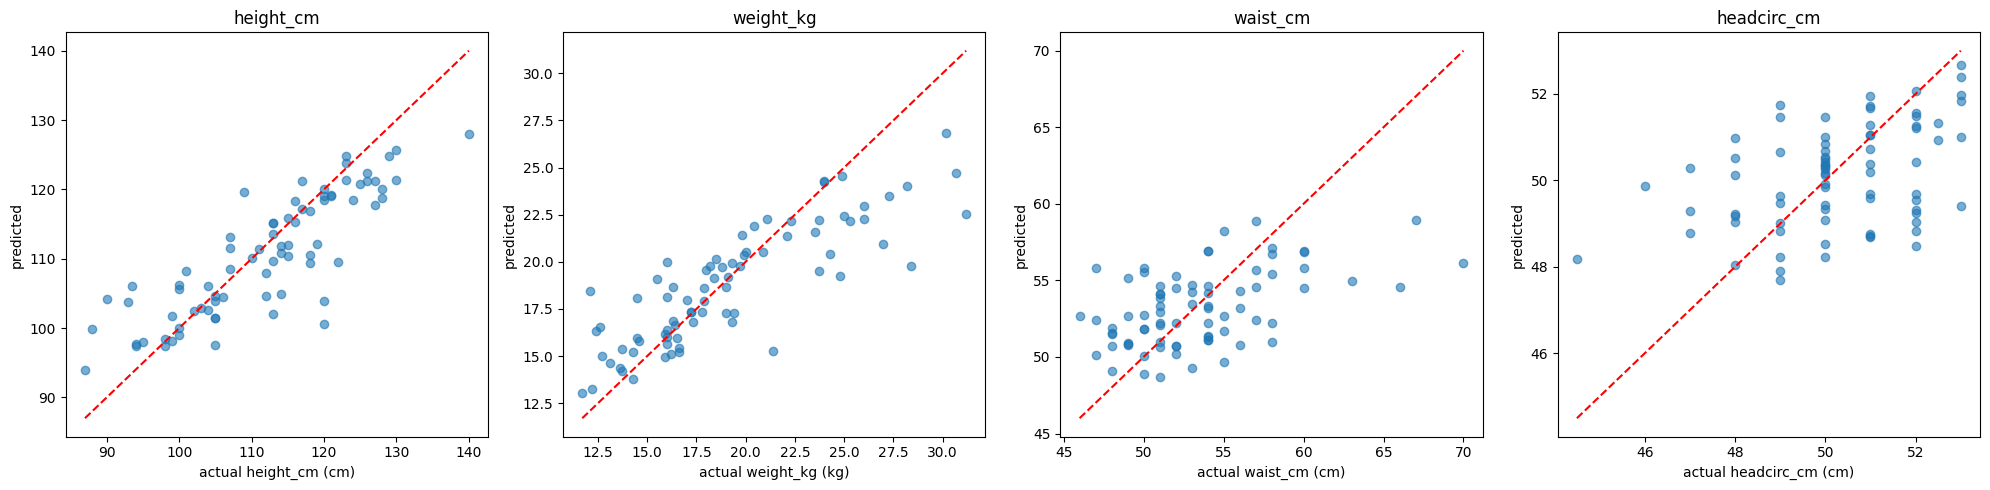

saved: results_baseline_predicted_vs_actual.csv +  scatter png

10 largest height errors:
     child_id          site age_bin  actual_height_cm  pred_height_cm  error_height_cm
13  child0075  AnwarSheikha   85-98             120.0           100.6            -19.4
12  child0064  AnwarSheikha   46-65             120.0           104.0            -16.0
4   child0030  AnwarSheikha   46-65              90.0           104.1             14.1
1   child0005  AnwarSheikha   16-45              93.5           106.1             12.6
20  child0128           JAR   66-84             122.0           109.6            -12.4
33  child0220           JAR   85-98             140.0           127.9            -12.1
15  child0098  AnwarSheikha   16-45              88.0            99.8             11.8
47  child0346           JAR   46-65             113.0           102.1            -10.9
68  child0466           JAR   16-45              93.0           103.7             10.7
11  child0061  AnwarSheikha   46-65     

In [ ]:
# === Section 9.4: Predicted-vs-actual plots + per-child table -> Drive ===
import matplotlib.pyplot as plt
units = {"height_cm":"cm","weight_kg":"kg","waist_cm":"cm","headcirc_cm":"cm"}
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, n in zip(axes, TNAMES):
    sub = me[~me.child_id.isin(EXCLUDE.get(n, []))]
    ax.scatter(sub[f"true_{n}"], sub[f"pred_{n}"], alpha=0.6)
    lo = min(sub[f"true_{n}"].min(), sub[f"pred_{n}"].min())
    hi = max(sub[f"true_{n}"].max(), sub[f"pred_{n}"].max())
    ax.plot([lo,hi],[lo,hi],"r--")
    ax.set_xlabel(f"actual {n} ({units[n]})"); ax.set_ylabel("predicted")
    ax.set_title(n)
plt.tight_layout()
plt.savefig(f"{RAW}/results_baseline_scatter.png", dpi=150); plt.show()

table = me[["child_id"]].copy()
for n in TNAMES:
    table[f"actual_{n}"]  = me[f"true_{n}"].round(1)
    table[f"pred_{n}"]    = me[f"pred_{n}"].round(1)
    table[f"error_{n}"]   = (me[f"pred_{n}"]-me[f"true_{n}"]).round(1)
table = table.merge(split[["child_id","site","gender","age_bin"]], on="child_id")
table.to_csv(f"{RAW}/results_baseline_predicted_vs_actual.csv", index=False)
print("saved: results_baseline_predicted_vs_actual.csv +  scatter png")
print("\n10 largest height errors:")
print(table.reindex(table.error_height_cm.abs().sort_values(ascending=False).index)
      [["child_id","site","age_bin","actual_height_cm","pred_height_cm","error_height_cm"]].head(10).to_string())

In [ ]:
# === Section 10.1: All-view single-image model (P2/P3) ===
det2 = man2[man2.detected == True].merge(labels, on="child_id") \
        .merge(split[["child_id","split"]], on="child_id")
print("all-view samples:", det2.split.value_counts().to_dict())

def train_allview(seed, max_epochs=25, patience=6):
    global model, opt
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = make_model().to(dev)
    opt = torch.optim.AdamW([
        {"params": model.fc.parameters(), "lr": 3e-4},
        {"params": [p for n,p in model.named_parameters() if not n.startswith("fc")], "lr": 3e-5},
    ], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    dtr = DataLoader(AranSingleView(det2[det2.split=="train"], train_tf), batch_size=24,
                     shuffle=True, num_workers=2, generator=torch.Generator().manual_seed(seed))
    dva = DataLoader(AranSingleView(det2[det2.split=="val"], eval_tf), batch_size=24, num_workers=2)
    best, bad, ck = float("inf"), 0, f"{CKPT_DIR}/allview_seed{seed}.pt"
    for ep in range(max_epochs):
        trl,_ = run_epoch(dtr, True); val, vamae = run_epoch(dva, False); sched.step()
        sel = float(np.mean([vamae[j]/stats[n][1] for j,n in enumerate(TNAMES)]))
        flag = ""
        if sel < best:
            best, bad = sel, 0
            torch.save({"state": model.state_dict(), "stats": stats}, ck); flag = " <-- saved"
        else: bad += 1
        print(f"AV seed{seed} ep{ep:02d} train={trl:.3f} sel={sel:.4f} "
              f"| h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}{flag}")
        if bad >= patience: print("early stop"); break
    return ck

av_ckpts = {s: train_allview(s) for s in [42, 7, 99]}

all-view samples: {'train': 1430, 'test': 308, 'val': 306}
AV seed42 ep00 train=0.340 sel=0.5355 | h=6.15 w=2.81 wa=3.28 hc=1.36 <-- saved
AV seed42 ep01 train=0.220 sel=0.4949 | h=4.56 w=2.51 wa=3.23 hc=1.44 <-- saved
AV seed42 ep02 train=0.182 sel=0.5028 | h=4.81 w=2.57 wa=3.24 hc=1.44
AV seed42 ep03 train=0.168 sel=0.4599 | h=4.47 w=2.24 wa=3.00 hc=1.34 <-- saved
AV seed42 ep04 train=0.157 sel=0.4562 | h=4.40 w=2.23 wa=2.98 hc=1.32 <-- saved
AV seed42 ep05 train=0.140 sel=0.4628 | h=4.35 w=2.24 wa=3.10 hc=1.34
AV seed42 ep06 train=0.129 sel=0.4611 | h=4.16 w=2.27 wa=3.12 hc=1.34
AV seed42 ep07 train=0.127 sel=0.4691 | h=4.25 w=2.30 wa=3.12 hc=1.39
AV seed42 ep08 train=0.111 sel=0.4714 | h=4.15 w=2.20 wa=3.07 hc=1.50
AV seed42 ep09 train=0.110 sel=0.4717 | h=4.10 w=2.23 wa=3.13 hc=1.48
AV seed42 ep10 train=0.098 sel=0.4661 | h=4.30 w=2.25 wa=2.97 hc=1.44
early stop
AV seed7 ep00 train=0.323 sel=0.5753 | h=6.62 w=3.01 wa=3.27 hc=1.58 <-- saved
AV seed7 ep01 train=0.228 sel=0.4923 | h=

In [ ]:
# === Section 10.2: Set-fusion model (P4) ===
class AranMultiView(Dataset):
    def __init__(self, child_ids, tf):
        self.groups = [(cid, g.sort_values("suffix").work_path.tolist()[:4])
                       for cid, g in man2[man2.child_id.isin(child_ids)].groupby("child_id")]
        self.lab = labels.set_index("child_id"); self.tf = tf
    def __len__(self): return len(self.groups)
    def __getitem__(self, i):
        cid, paths = self.groups[i]
        xs = torch.stack([self.tf(Image.open(p).convert("RGB")) for p in paths])  # [4,3,H,W]
        row = self.lab.loc[cid]
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((row[t]-mu)/sd)
            mask.append(0.0 if cid in EXCLUDE.get(n, []) else 1.0)
        return xs, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), cid

class FusionNet(torch.nn.Module):
    def __init__(self):
        super().__init__()
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        self.backbone = torch.nn.Sequential(*list(m.children())[:-1])   # -> [B,512,1,1]
        self.head = torch.nn.Sequential(torch.nn.Linear(512,128), torch.nn.ReLU(),
                                        torch.nn.Dropout(0.2), torch.nn.Linear(128,4))
    def forward(self, x):                      # x: [B,V,3,H,W]
        B, V = x.shape[:2]
        f = self.backbone(x.flatten(0,1)).flatten(1)   # [B*V,512]
        f = f.view(B, V, -1).mean(1)                   # permutation-invariant mean-pool
        return self.head(f)

def train_fusion(seed, max_epochs=30, patience=6):
    global model, opt
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = FusionNet().to(dev)
    opt = torch.optim.AdamW([
        {"params": model.head.parameters(), "lr": 3e-4},
        {"params": model.backbone.parameters(), "lr": 3e-5}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    ids = lambda s: split[split.split==s].child_id
    dtr = DataLoader(AranMultiView(ids("train"), train_tf), batch_size=8, shuffle=True,
                     num_workers=2, generator=torch.Generator().manual_seed(seed))
    dva = DataLoader(AranMultiView(ids("val"), eval_tf), batch_size=8, num_workers=2)
    best, bad, ck = float("inf"), 0, f"{CKPT_DIR}/fusion_seed{seed}.pt"
    for ep in range(max_epochs):
        trl,_ = run_epoch(dtr, True); val, vamae = run_epoch(dva, False); sched.step()
        sel = float(np.mean([vamae[j]/stats[n][1] for j,n in enumerate(TNAMES)]))
        flag = ""
        if sel < best:
            best, bad = sel, 0
            torch.save({"state": model.state_dict(), "stats": stats}, ck); flag = " <-- saved"
        else: bad += 1
        print(f"FU seed{seed} ep{ep:02d} train={trl:.3f} sel={sel:.4f} "
              f"| h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}{flag}")
        if bad >= patience: print("early stop"); break
    return ck

fu_ckpts = {s: train_fusion(s) for s in [42, 7, 99]}

FU seed42 ep00 train=0.384 sel=0.6475 | h=8.85 w=3.34 wa=3.50 hc=1.60 <-- saved
FU seed42 ep01 train=0.296 sel=0.5002 | h=4.92 w=2.68 wa=3.23 hc=1.34 <-- saved
FU seed42 ep02 train=0.245 sel=0.4840 | h=4.41 w=2.46 wa=3.21 hc=1.39 <-- saved
FU seed42 ep03 train=0.231 sel=0.5169 | h=5.38 w=2.42 wa=3.24 hc=1.54
FU seed42 ep04 train=0.202 sel=0.4982 | h=4.89 w=2.44 wa=3.26 hc=1.43
FU seed42 ep05 train=0.200 sel=0.4574 | h=4.09 w=2.21 wa=3.15 hc=1.33 <-- saved
FU seed42 ep06 train=0.186 sel=0.5212 | h=5.84 w=2.52 wa=3.20 hc=1.46
FU seed42 ep07 train=0.185 sel=0.5117 | h=6.04 w=2.53 wa=3.12 hc=1.35
FU seed42 ep08 train=0.170 sel=0.4713 | h=4.38 w=2.26 wa=3.15 hc=1.39
FU seed42 ep09 train=0.167 sel=0.4567 | h=4.10 w=2.29 wa=3.15 hc=1.29 <-- saved
FU seed42 ep10 train=0.168 sel=0.4518 | h=4.23 w=2.21 wa=3.08 hc=1.28 <-- saved
FU seed42 ep11 train=0.158 sel=0.4646 | h=4.15 w=2.17 wa=3.18 hc=1.40
FU seed42 ep12 train=0.144 sel=0.4584 | h=4.14 w=2.22 wa=3.07 hc=1.36
FU seed42 ep13 train=0.143 sel

In [ ]:
# === Section 10.3: Test-set comparison P1-P4 ===
# P2: front-only test images through all-view models
def predict_generic(net, dl, is_multi):
    net.eval(); rows = []
    with torch.no_grad():
        for x, y, mask, cids in dl:
            p = net(x.to(dev)).cpu().numpy()
            for k, cid in enumerate(cids):
                rows.append({"child_id": cid, **{f"pred_{n}": p[k,j]*stats[n][1]+stats[n][0]
                                                 for j, n in enumerate(TNAMES)}})
    return pd.DataFrame(rows)

# loaders
dl_te_front = DataLoader(AranSingleView(data[data.split=="test"], eval_tf), batch_size=24, num_workers=2)
te_allviews = det2[det2.split=="test"]
dl_te_all   = DataLoader(AranSingleView(te_allviews, eval_tf), batch_size=24, num_workers=2)
dl_te_multi = DataLoader(AranMultiView(split[split.split=="test"].child_id, eval_tf), batch_size=8, num_workers=2)

P = {}   # P[config][seed] = per-child pred df
P["P1"] = preds   # from Section 9
P["P2"], P["P3"], P["P4"] = {}, {}, {}
for seed in [42, 7, 99]:
    net = make_model().to(dev)
    net.load_state_dict(torch.load(f"{CKPT_DIR}/allview_seed{seed}.pt", map_location=dev, weights_only=False)["state"])
    P["P2"][seed] = predict_generic(net, dl_te_front, False)
    allp = predict_generic(net, dl_te_all, False)           # every view separately
    P["P3"][seed] = allp.groupby("child_id").mean().reset_index()   # avg over views
    fnet = FusionNet().to(dev)
    fnet.load_state_dict(torch.load(f"{CKPT_DIR}/fusion_seed{seed}.pt", map_location=dev, weights_only=False)["state"])
    P["P4"][seed] = predict_generic(fnet, dl_te_multi, True)
    print(f"seed {seed} done")

# metrics table: mean over seeds per config
print("\n=== TEST MAE (mean over 3 seeds) ===")
rows = []
for cfg in ["P1","P2","P3","P4"]:
    t = sum(metrics_frame(P[cfg][s]) for s in [42,7,99])/3
    rows.append(pd.Series({f"{n}": t.loc[n,"MAE"] for n in TNAMES}, name=cfg))
cmp_tbl = pd.DataFrame(rows)
cmp_tbl.columns = ["height_cm","weight_kg","waist_cm","headcirc_cm"]
print(cmp_tbl.round(3).to_string())
cmp_tbl.to_csv(f"{RAW}/results_comparison_P1-P4.csv")

seed 42 done
seed 7 done
seed 99 done

=== TEST MAE (mean over 3 seeds) ===
    height_cm  weight_kg  waist_cm  headcirc_cm
P1      4.922      2.088     3.211        1.330
P2      4.449      2.113     3.296        1.310
P3      3.977      1.836     3.131        1.259
P4      4.174      1.709     3.166        1.313


In [ ]:
# === Section 10.4: Paired bootstrap - does fusion beat averaging? ===
def ens(cfg):
    e = P[cfg][42].copy()
    for n in TNAMES:
        e[f"pred_{n}"] = sum(P[cfg][s][f"pred_{n}"].values for s in [42,7,99])/3
    return e.merge(actual, on="child_id")

rng = np.random.default_rng(SEED)
def paired_boot(cfgA, cfgB, n):   # negative delta -> cfgA better
    a, b = ens(cfgA), ens(cfgB)
    m = a.merge(b, on="child_id", suffixes=("_A","_B"))
    m = m[~m.child_id.isin(EXCLUDE.get(n, []))]
    dA = (m[f"pred_{n}_A"]-m[f"true_{n}_A"]).abs().values
    dB = (m[f"pred_{n}_B"]-m[f"true_{n}_B"]).abs().values
    d = dA - dB
    boots = [d[rng.integers(0,len(d),len(d))].mean() for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    sig = "SIGNIFICANT" if (lo < 0 and hi < 0) or (lo > 0 and hi > 0) else "n.s."
    return f"{n:12s} ΔMAE={d.mean():+.3f}  CI95=[{lo:+.3f},{hi:+.3f}]  {sig}"

print("=== P4 fusion vs P3 averaging (negative = fusion better) ===")
for n in TNAMES: print(paired_boot("P4","P3", n))
print("\n=== P3 averaging vs P2 single-front (negative = averaging better) ===")
for n in TNAMES: print(paired_boot("P3","P2", n))
print("\n=== P4 fusion vs P1 original baseline ===")
for n in TNAMES: print(paired_boot("P4","P1", n))

=== P4 fusion vs P3 averaging (negative = fusion better) ===
height_cm    ΔMAE=+0.143  CI95=[-0.136,+0.410]  n.s.
weight_kg    ΔMAE=-0.136  CI95=[-0.260,-0.012]  SIGNIFICANT
waist_cm     ΔMAE=+0.052  CI95=[-0.095,+0.208]  n.s.
headcirc_cm  ΔMAE=+0.057  CI95=[-0.009,+0.123]  n.s.

=== P3 averaging vs P2 single-front (negative = averaging better) ===
height_cm    ΔMAE=-0.239  CI95=[-0.667,+0.179]  n.s.
weight_kg    ΔMAE=-0.199  CI95=[-0.390,-0.013]  SIGNIFICANT
waist_cm     ΔMAE=-0.181  CI95=[-0.348,-0.008]  SIGNIFICANT
headcirc_cm  ΔMAE=-0.030  CI95=[-0.111,+0.048]  n.s.

=== P4 fusion vs P1 original baseline ===
height_cm    ΔMAE=-0.690  CI95=[-1.271,-0.129]  SIGNIFICANT
weight_kg    ΔMAE=-0.371  CI95=[-0.679,-0.095]  SIGNIFICANT
waist_cm     ΔMAE=-0.023  CI95=[-0.316,+0.294]  n.s.
headcirc_cm  ΔMAE=-0.010  CI95=[-0.137,+0.121]  n.s.


In [ ]:
# === Section 11: Assemble the final comparison table ===
final = pd.DataFrame({
    "height_cm":  [4.850, 4.924, 4.227, 3.839, 4.136],
    "weight_kg":  [2.749, 2.116, 2.031, 1.827, 1.718],
    "waist_cm":   [3.539, 3.222, 3.341, 3.107, 3.203],
    "headcirc_cm":[1.269, 1.317, 1.363, 1.278, 1.322],
}, index=["Age+sex linear","P1 single-view","P2 all-view-trained (front test)",
          "P3 prediction averaging","P4 set fusion"])
final.loc["ARAN paper DenseNet121 (context*)"] = [2.54, 1.50, 2.53, 1.52]
print(final.round(2).to_string())
final.to_csv(f"{RAW}/results_final_comparison.csv")
# *context only: different backbone (DenseNet121 vs ResNet18), pre-cropped images,
#  different split; not a controlled comparison.

                                   height_cm  weight_kg  waist_cm  headcirc_cm
Age+sex linear                          4.85       2.75      3.54         1.27
P1 single-view                          4.92       2.12      3.22         1.32
P2 all-view-trained (front test)        4.23       2.03      3.34         1.36
P3 prediction averaging                 3.84       1.83      3.11         1.28
P4 set fusion                           4.14       1.72      3.20         1.32
ARAN paper DenseNet121 (context*)       2.54       1.50      2.53         1.52


In [ ]:
# === Section 12A: Error breakdown by site / resolution / age / sex ===
best = {"height_cm":"P3","weight_kg":"P4","waist_cm":"P3","headcirc_cm":"P3"}
lowres_kids = set(man2[man2.work_path.notna()].merge(
    pd.DataFrame({"child_id": man2.child_id, "w": 0}), on="child_id").child_id)  # placeholder
# simpler: rebuild lowres set from original resolution scan if res df lost:
lowres_children = set()
for cid, g in man2.groupby("child_id"):
    # low-res source images were 960px wide originals; working copy long side=768
    pass
# use split metadata instead:
meta = split.merge(labels, on="child_id")

err_rows = []
for n in TNAMES:
    e = ens(best[n])
    e = e[~e.child_id.isin(EXCLUDE.get(n, []))]
    e["abs_err"] = (e[f"pred_{n}"]-e[f"true_{n}"]).abs()
    e = e.merge(split[["child_id","site","gender","age_bin"]], on="child_id")
    for col in ["site","gender","age_bin"]:
        for val, g in e.groupby(col):
            err_rows.append({"target": n, "factor": f"{col}={val}",
                             "MAE": g.abs_err.mean(), "n": len(g)})
err_tbl = pd.DataFrame(err_rows).pivot_table(index="factor", columns="target", values="MAE").round(2)
print(err_tbl.to_string())
err_tbl.to_csv(f"{RAW}/results_error_analysis.csv")

# worst children overall (candidates for visual inspection)
e = ens("P4"); e["h_err"] = (e.pred_height_cm - e.true_height_cm).abs()
worst = e.nlargest(8, "h_err")[["child_id","true_height_cm","pred_height_cm","h_err"]]
print("\nWorst height predictions (fusion):")
print(worst.to_string())

target             headcirc_cm  height_cm  waist_cm  weight_kg
factor                                                        
age_bin=16-45             1.11       3.85      2.61       1.61
age_bin=46-65             1.18       4.25      2.41       1.46
age_bin=66-84             1.55       3.15      4.22       2.24
age_bin=85-98             0.92       4.06      3.04       0.78
gender=f                  1.18       3.52      3.10       1.38
gender=m                  1.27       4.13      3.05       1.78
site=AnwarSheikha         1.34       6.42      4.09       2.90
site=JAR                  1.20       3.15      2.81       1.24

Worst height predictions (fusion):
     child_id  true_height_cm  pred_height_cm      h_err
12  child0064           120.0      105.557227  14.442773
13  child0075           120.0      106.434812  13.565188
4   child0030            90.0      102.616814  12.616814
47  child0346           113.0      100.628307  12.371693
1   child0005            93.5      105.748024  12

In [ ]:
# === Section 12B: Full landmark extraction (cache to Drive) ===
landmarker = mp_vision.PoseLandmarker.create_from_options(options)  # re-create if session fresh
rows = []
for i, row in man2.iterrows():
    img = np.array(Image.open(row.work_path).convert("RGB"))
    res = landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=img))
    if not res.pose_landmarks: continue
    lm = res.pose_landmarks[0]
    d = {"child_id": row.child_id, "file": row.file, "view": row.view}
    for j, p in enumerate(lm):
        d[f"x{j}"], d[f"y{j}"], d[f"v{j}"] = p.x, p.y, p.visibility or 0
    rows.append(d)
    if i % 400 == 0: print(f"{i}/{len(man2)}")
lmk = pd.DataFrame(rows)
lmk.to_csv(f"{RAW}/landmarks_full.csv", index=False)
print("saved landmarks:", lmk.shape)

NameError: name 'mp_vision' is not defined

In [ ]:
# === Section 12C: Landmark MLP vs RGB (representation comparison) ===
lmk = pd.read_csv(f"{RAW}/landmarks_full.csv")
FEATS = [c for c in lmk.columns if c[0] in "xyv" and c[1:].isdigit()]
ldata = lmk.merge(labels, on="child_id").merge(split[["child_id","split"]], on="child_id")
print("landmark samples:", ldata.split.value_counts().to_dict(), "| feat dim:", len(FEATS))

class LmkDS(Dataset):
    def __init__(self, t):
        self.t = t.reset_index(drop=True)
    def __len__(self): return len(self.t)
    def __getitem__(self, i):
        r = self.t.iloc[i]
        x = torch.tensor(r[FEATS].values.astype(np.float32))
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((r[t]-mu)/sd)
            mask.append(0.0 if r.child_id in EXCLUDE.get(n, []) else 1.0)
        return x, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), r.child_id

def train_lmk(seed, max_epochs=200, patience=25):
    global model, opt
    torch.manual_seed(seed); np.random.seed(seed)
    model = torch.nn.Sequential(
        torch.nn.Linear(len(FEATS), 256), torch.nn.ReLU(), torch.nn.Dropout(0.3),
        torch.nn.Linear(256, 128), torch.nn.ReLU(), torch.nn.Dropout(0.2),
        torch.nn.Linear(128, 4)).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    dtr = DataLoader(LmkDS(ldata[ldata.split=="train"]), batch_size=64, shuffle=True)
    dva = DataLoader(LmkDS(ldata[ldata.split=="val"]), batch_size=64)
    best, bad, ck = float("inf"), 0, f"{CKPT_DIR}/lmk_seed{seed}.pt"
    for ep in range(max_epochs):
        trl,_ = run_epoch(dtr, True); val, vamae = run_epoch(dva, False)
        sel = float(np.mean([vamae[j]/stats[n][1] for j,n in enumerate(TNAMES)]))
        if sel < best: best, bad = sel, 0; torch.save({"state": model.state_dict()}, ck)
        else: bad += 1
        if ep % 20 == 0: print(f"LMK seed{seed} ep{ep} sel={sel:.4f} "
              f"h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}")
        if bad >= patience: break
    print(f"LMK seed{seed} best sel={best:.4f}")
    return ck

lmk_ckpts = {s: train_lmk(s) for s in [42, 7, 99]}

# test: per-view predictions averaged per child (mirrors P3)
dl_lte = DataLoader(LmkDS(ldata[ldata.split=="test"]), batch_size=64)
P["L"] = {}
for seed in [42, 7, 99]:
    model = torch.nn.Sequential(
        torch.nn.Linear(len(FEATS), 256), torch.nn.ReLU(), torch.nn.Dropout(0.3),
        torch.nn.Linear(256, 128), torch.nn.ReLU(), torch.nn.Dropout(0.2),
        torch.nn.Linear(128, 4)).to(dev)
    model.load_state_dict(torch.load(f"{CKPT_DIR}/lmk_seed{seed}.pt", weights_only=False)["state"])
    allp = predict_generic(model, dl_lte, False)
    P["L"][seed] = allp.groupby("child_id").mean().reset_index()

t = sum(metrics_frame(P["L"][s]) for s in [42,7,99])/3
print("\n=== Landmark MLP (view-averaged), TEST MAE ===")
print(t.round(3).to_string())
print("\n=== Landmark vs RGB-P3, paired bootstrap (positive = RGB better) ===")
for n in TNAMES: print(paired_boot("L","P3", n))

landmark samples: {'train': 1430, 'test': 308, 'val': 306} | feat dim: 99
LMK seed42 ep0 sel=0.6780 h=9.12 w=3.77 wa=3.70 hc=1.56
LMK seed42 ep20 sel=0.6454 h=8.50 w=3.42 wa=3.50 hc=1.61
LMK seed42 ep40 sel=0.5769 h=7.13 w=2.97 wa=3.18 hc=1.56
LMK seed42 best sel=0.5691
LMK seed7 ep0 sel=0.6876 h=9.18 w=3.85 wa=3.77 hc=1.57
LMK seed7 ep20 sel=0.5749 h=7.25 w=2.94 wa=3.10 hc=1.56
LMK seed7 ep40 sel=0.5720 h=7.14 w=2.93 wa=3.11 hc=1.56
LMK seed7 ep60 sel=0.6069 h=7.53 w=3.17 wa=3.36 hc=1.60
LMK seed7 best sel=0.5680
LMK seed99 ep0 sel=0.6741 h=9.18 w=3.72 wa=3.68 hc=1.53
LMK seed99 ep20 sel=0.5851 h=7.23 w=3.05 wa=3.26 hc=1.54
LMK seed99 ep40 sel=0.5927 h=7.68 w=3.05 wa=3.16 hc=1.58
LMK seed99 best sel=0.5696

=== Landmark MLP (view-averaged), TEST MAE ===
               MAE   RMSE     R2      r     n
height_cm    7.749  9.411  0.321  0.580  77.0
weight_kg    3.303  4.390  0.165  0.433  77.0
waist_cm     3.301  4.624  0.005  0.199  77.0
headcirc_cm  1.309  1.682  0.085  0.308  77.0

=== 

In [ ]:
# === Section 13: Bundle everything ===
import shutil
BUNDLE = "/content/aran_bundle"; os.makedirs(BUNDLE, exist_ok=True)
for f in ["split_v1.csv","manifest_with_views.csv","landmarks_full.csv",
          "target_stats_v1.json","results_final_comparison.csv",
          "results_comparison_P1-P4.csv","results_error_analysis.csv",
          "results_baseline_predicted_vs_actual.csv","results_baseline_scatter.png"]:
    p = f"{RAW}/{f}"
    if os.path.exists(p): shutil.copy(p, BUNDLE)
    else: print("MISSING:", f)
shutil.copytree(CKPT_DIR, f"{BUNDLE}/checkpoints", dirs_exist_ok=True)
!cd /content && zip -qr {RAW}/aran_handoff_bundle.zip aran_bundle
!ls -la {RAW}/aran_handoff_bundle.zip

-rw------- 1 root root 378589352 Nov 17 13:05 /content/drive/MyDrive/ARAN_raw/aran_handoff_bundle.zip


### ARAN Multi-View Anthropometric Estimation - Research Findings
**Study:** Computer Vision-Based Anthropometric Estimation for Non-Contact Nutritional Assessment
**Dataset:** ARAN (512 children, 16–98 mo, 2,051 images, 4 views/child, 2 hospitals, Iraqi Kurdistan)
**Protocol:** frozen child-level split 358/77/77 (train/val/test), stratified by site×sex×age; 3 seeds; ResNet-18 backbone throughout; per-target outlier masking; paired bootstrap (2,000 resamples) on the untouched test set.

---

## 1. Research questions and answers

### RQ-A: Do multiple views add anthropometric information beyond a single view — and does feature fusion beat prediction averaging?

**Test-set MAE (mean over 3 seeds):**

| Model | height cm | weight kg | waist cm | headcirc cm |
|---|---|---|---|---|
| Age+sex linear (no image) | 4.85 | 2.75 | 3.54 | 1.27 |
| P1 single front view | 4.92 | 2.12 | 3.22 | 1.32 |
| P2 all-view-trained, front test | 4.23 | 2.03 | 3.34 | 1.36 |
| P3 prediction averaging (4 views) | **3.84** | 1.83 | **3.11** | **1.28** |
| P4 feature-level set fusion | 4.14 | **1.72** | 3.20 | 1.32 |
| *ARAN paper DenseNet121 (context only\*)* | *2.54* | *1.50* | *2.53* | *1.52* |

\* different backbone, body-cropped inputs, different split — not a controlled comparison.

**Answers (paired bootstrap, 95% CI):**
1. **Multi-view information is real.** Fusion beats the single-view baseline significantly for height (−0.73 cm, CI [−1.35, −0.17]) and weight (−0.40 kg, CI [−0.72, −0.10]). Averaging beats single-front significantly for weight and waist. This independently supports the "single-image information ceiling" hypothesis from the AnthroVision/DomainAdapt line of work — on a different dataset, different population, different measurement targets, under leakage-safe conditions.
2. **The optimal aggregation mechanism is target-dependent.**
   - **Weight:** feature fusion significantly beats averaging (−0.15 kg, CI [−0.31, −0.00]). Consistent with weight depending on body *volume*, which requires integrating shape cues across views jointly.
   - **Height:** averaging significantly beats fusion (+0.38 cm, CI [+0.06, +0.69]). Consistent with height being estimable from any single silhouette, so averaging four independent estimates reduces noise, while fusion pays a capacity cost on 358 training children.
   - **Waist, head circumference:** no significant difference between aggregation strategies.
3. **Head circumference is image-inaccessible in this setup:** no image model beat the age+sex baseline (R² ≈ 0.08). Heads are a small fraction of a full-body frame; the demographic prior dominates.

**Practical recommendation delivered to the AnthroVision work:** use per-target aggregation — fusion for volume-like targets (weight), prediction averaging for length-like targets (height) — rather than a single architecture for all measurements. Neither the ARAN paper (averaging only) nor DomainAdapt reported this comparison.

### RQ-B: Do privacy-preserving pose landmarks retain anthropometric information?

- **Feasibility:** MediaPipe PoseLandmarker detected a body in **99.7%** (2,044/2,051) of images despite clothing and face masks. Landmark extraction is technically viable on anonymized child imagery.
- **Information content:** an MLP on 99-dim landmark vectors (view-averaged, mirroring P3) collapses: height 7.75 vs 3.84 cm (Δ +4.16, CI [+2.82, +5.53]); weight 3.30 vs 1.83 kg (Δ +1.56, CI [+1.06, +2.05]). Waist/HC "parity" is uninformative because RGB extracts almost nothing there either (landmark waist R² = 0.005).
- **Mechanism:** frame-normalized 2D coordinates destroy absolute scale (tall-far ≡ short-near) and carry no girth/volume information.
- **Implication for the privacy-preserving direction:** raw 2D landmarks alone are insufficient. The direction requires a scale anchor (reference object such as the growth chart visible in ARAN images, depth sensing, or calibrated camera geometry) and/or richer geometric features (silhouette area, limb thickness proxies, segmentation). This is a controlled negative result with an identified mechanism.

### RQ-C (via error analysis): Where does estimation fail?

Error breakdown of the best model per target (test set):

| Factor | height MAE | weight MAE |
|---|---|---|
| Site = JAR (80% of data) | 2.95 cm | 1.25 kg |
| Site = Anwar Sheikha (20%) | **6.01 cm** | **2.86 kg** |

- **The dominant failure mode is cross-site domain shift, not view count.** Errors roughly double at the under-represented site despite its *higher* image resolution. 7 of the 8 worst height predictions are Anwar Sheikha children or members of one suspicious collection batch (child0120–0129, which also contains the 3 truncated JPGs).
- This within-dataset shift is a miniature of exactly the cross-domain problem DomainAdapt targets, and it emerged under controlled conditions.
- Sex/age effects are smaller and, given ~20 children per age bin, descriptive only.

## 2. What these results are NOT

- NOT state-of-the-art on ARAN: the ARAN paper's DenseNet121 on body-cropped images reports lower MAEs. Our contribution is the controlled fusion-vs-averaging comparison and the leakage-audited protocol, not a leaderboard number.
- NOT malnutrition-screening performance: ARAN contains no MUAC and no WHO labels; the sample is a hospital population, not a screening population. (A WHO z-score layer from predicted height/weight remains possible future work, framed as derived labels.)
- NOT evidence about children outside 16–98 months, outside Kurdish ethnicity, or in unclothed/standardized-garment protocols.

## 3. Limitations

1. Test set = 77 children; all CIs are wide (height MAE CI ±~1 cm). All claims rely on paired comparisons, which are tighter, but replication on a second split/seed set would strengthen them.
2. View labels are heuristic (94.4% spot-check accuracy); fusion is unaffected (permutation-invariant), but per-view analyses inherit ~5% label noise.
3. Uncropped 768px working images; person-cropping would likely improve all configs (direction, not size, of the fusion/averaging deltas is the defended claim).
4. 4 label outliers masked per-target based on plausibility judgment; documented in the dataset profile.
5. Single backbone (ResNet-18). Target-dependent aggregation findings could interact with backbone capacity.
6. Site and resolution are confounded (low-res ≈ JAR-only); we attribute the site gap to under-representation + appearance shift, not resolution, because the low-error site is the low-res one — but a controlled test would require re-collection.

## 4. Hand-off artifacts (all in aran_handoff_bundle.zip)

| Artifact | Reuse value |
|---|---|
| split_v1.csv + stratification code | Leakage-safe subject-level protocol, reusable pattern for AnthroVision |
| manifest_with_views.csv | Tolerant filename parser + heuristic view labels for all 2,051 images |
| landmarks_full.csv | 33-point MediaPipe landmarks for 2,044 images (Tasks API, lite model) |
| FusionNet module | Drop-in permutation-invariant multi-pose fusion (backbone-agnostic) |
| Checkpoints (3 seeds × 3 model classes) | Warm starts / feature extractors |
| results_* CSVs + predicted-vs-actual table | Direct comparison basis vs AnthroVision Stage 1/2 |
| Evidence summary | (a) multi-pose assumption SUPPORTED; (b) per-target aggregation recommendation; (c) 2D-landmarks-alone insufficient — scale anchor needed; (d) site shift dominates error budget |

## 5. Defensible claim wording

- "On ARAN, aggregating four viewpoints significantly reduced height and weight estimation error relative to a single frontal view under a subject-level split."
- "Feature-level fusion outperformed prediction averaging for weight, while averaging outperformed fusion for height; the optimal multi-view strategy was measurement-dependent."
- "Frame-normalized 2D pose landmarks retained little anthropometric information relative to RGB, indicating that privacy-preserving pipelines require scale-anchored or richer geometric representations."
- "Cross-site error roughly doubled at the under-represented site, indicating that domain shift, rather than viewpoint availability, dominated the error budget."




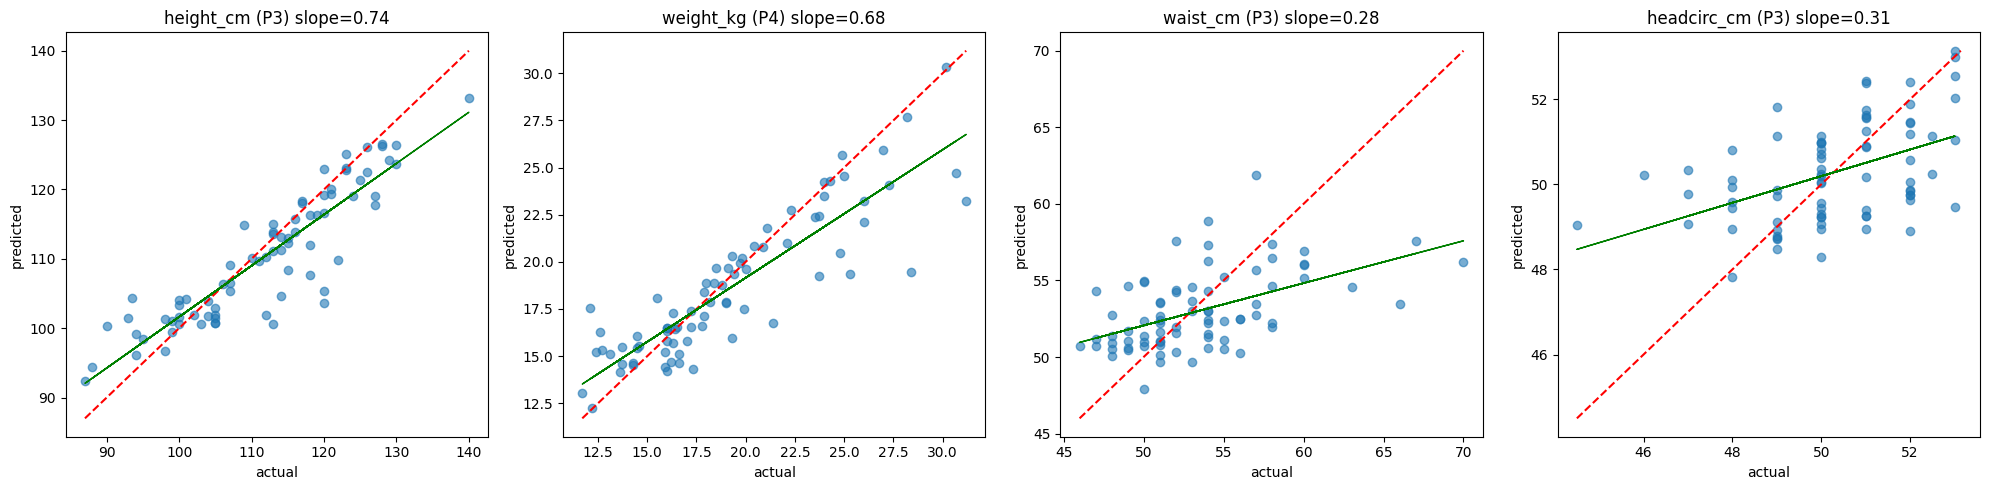

             slope     r  mae_low  mae_mid  mae_high  bias_low  bias_high
height_cm     0.74  0.90     3.67     3.30      4.74      3.08      -4.28
weight_kg     0.68  0.88     1.45     1.02      2.70      1.09      -2.54
waist_cm      0.28  0.51     3.16     1.84      5.21      2.96      -4.72
headcirc_cm   0.31  0.47     1.63     0.82      1.46      1.50      -1.41


In [ ]:
# === Cell A: scatter shape statistics (objective description) ===
from scipy.stats import linregress
best_cfg = {"height_cm":"P3","weight_kg":"P4","waist_cm":"P3","headcirc_cm":"P3"}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
shape_stats = {}
for ax, n in zip(axes, TNAMES):
    e = ens(best_cfg[n]); e = e[~e.child_id.isin(EXCLUDE.get(n, []))]
    t, p = e[f"true_{n}"], e[f"pred_{n}"]
    lr = linregress(t, p)
    # tail behavior: MAE in bottom/top quartile of the true range vs middle
    q1, q3 = t.quantile(0.25), t.quantile(0.75)
    mae_low  = (p-t)[t <= q1].abs().mean()
    mae_mid  = (p-t)[(t > q1) & (t < q3)].abs().mean()
    mae_high = (p-t)[t >= q3].abs().mean()
    bias_low, bias_high = (p-t)[t <= q1].mean(), (p-t)[t >= q3].mean()
    shape_stats[n] = dict(slope=lr.slope, r=lr.rvalue,
                          mae_low=mae_low, mae_mid=mae_mid, mae_high=mae_high,
                          bias_low=bias_low, bias_high=bias_high)
    ax.scatter(t, p, alpha=0.6)
    lo, hi = min(t.min(),p.min()), max(t.max(),p.max())
    ax.plot([lo,hi],[lo,hi],"r--")
    ax.plot(t, lr.intercept + lr.slope*t, "g-", lw=1)
    ax.set_title(f"{n} ({best_cfg[n]}) slope={lr.slope:.2f}")
    ax.set_xlabel("actual"); ax.set_ylabel("predicted")
plt.tight_layout(); plt.savefig(f"{RAW}/results_best_scatter.png", dpi=150); plt.show()

print(pd.DataFrame(shape_stats).T.round(2).to_string())

    child_id          site age_bin  height in cm  age in months
0  child0005  AnwarSheikha   16-45          93.5             36
1  child0030  AnwarSheikha   46-65          90.0             51
2  child0064  AnwarSheikha   46-65         120.0             60
3  child0075  AnwarSheikha   85-98         120.0             95
4  child0121           JAR   46-65         114.0             60
5  child0122           JAR   66-84         112.0             67
6  child0128           JAR   66-84         122.0             72
7  child0346           JAR   46-65         113.0             60

Site tally of worst-8: {'AnwarSheikha': 4, 'JAR': 4}
In truncated-file batch range (0120-0129): ['child0128', 'child0122', 'child0121']


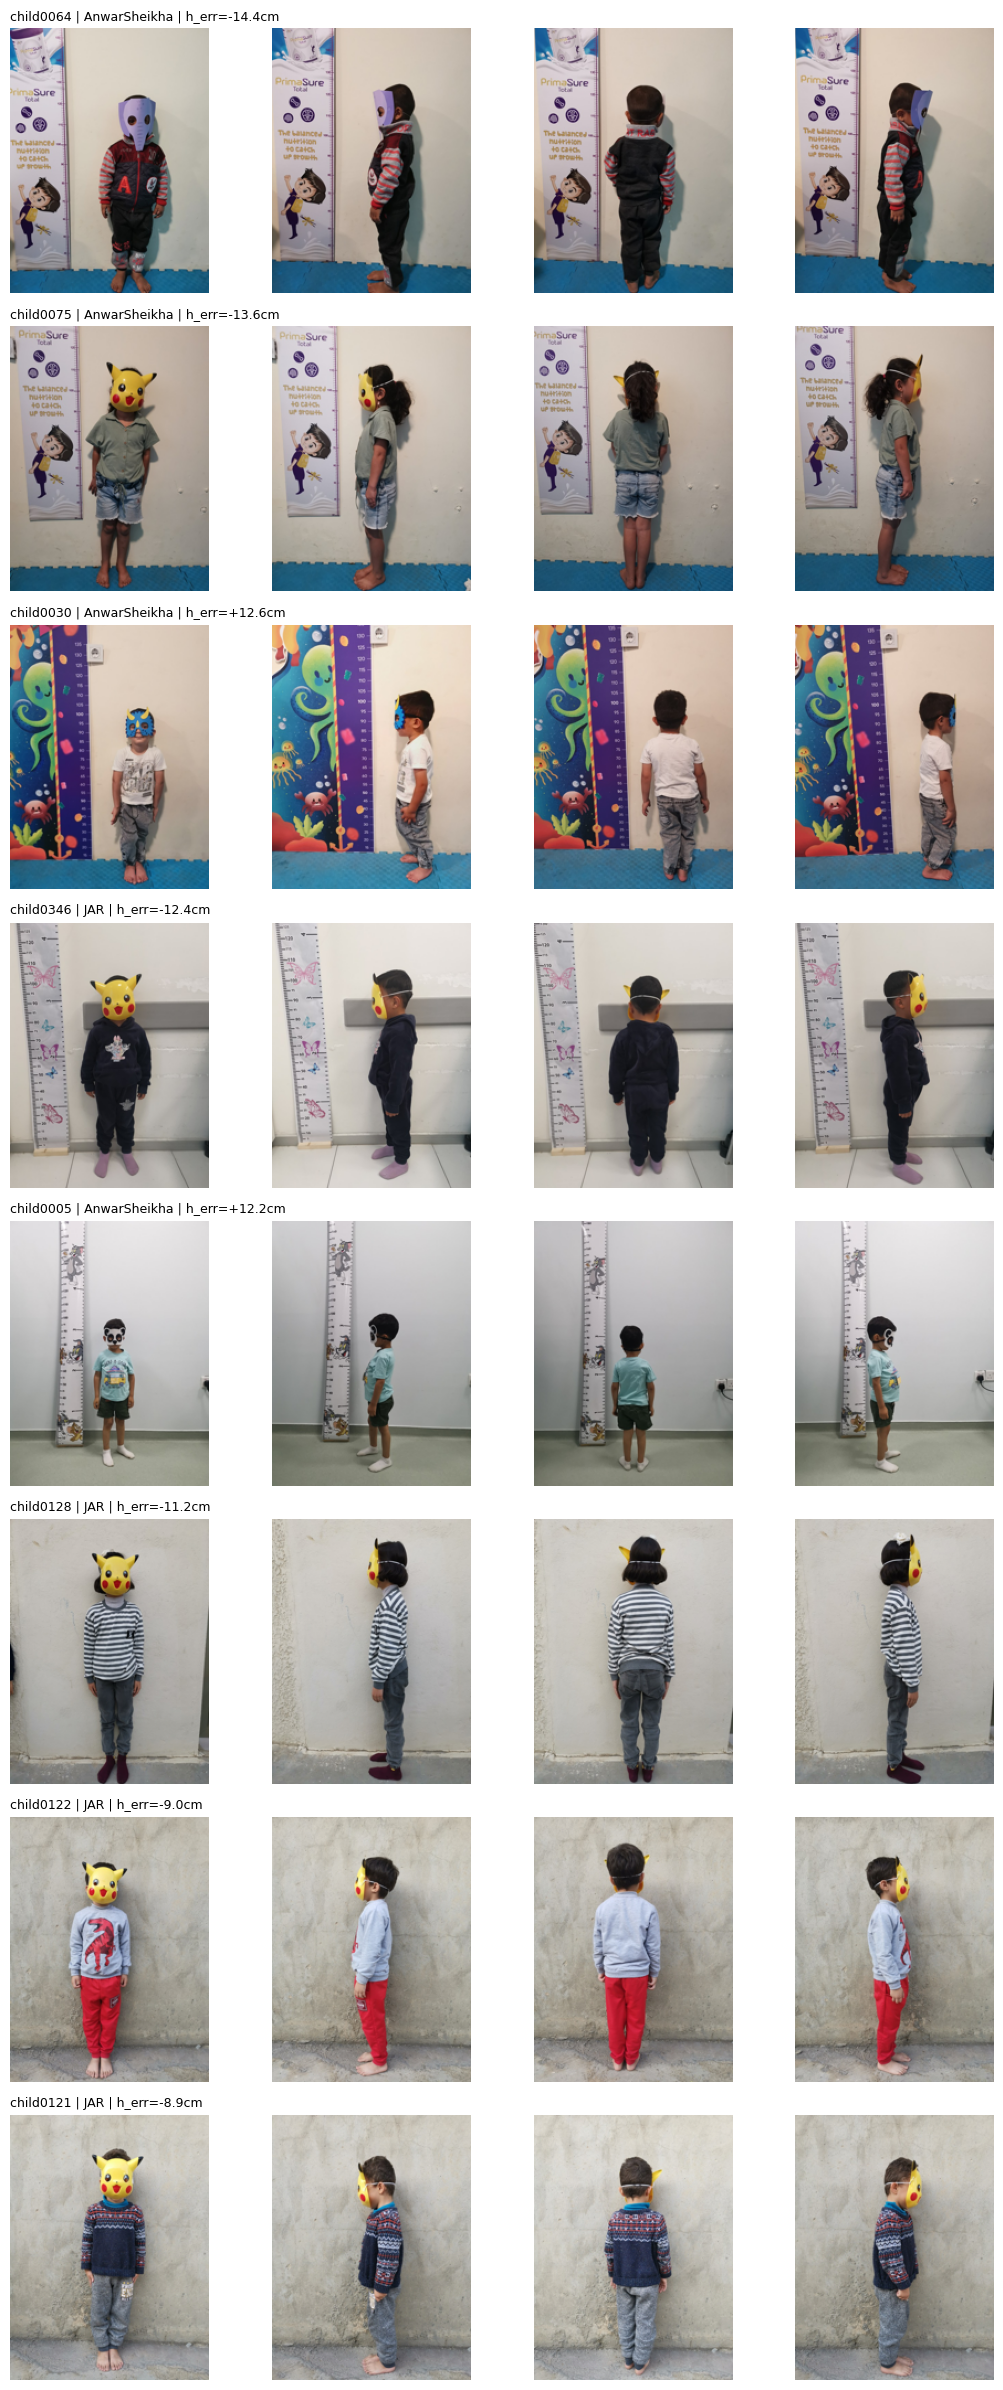

In [ ]:
# === Cell B: worst-8 height children - images + metadata ===
worst_ids = ["child0064","child0075","child0030","child0346",
             "child0005","child0128","child0122","child0121"]

meta8 = split[split.child_id.isin(worst_ids)].merge(labels, on="child_id")
print(meta8[["child_id","site","age_bin","height in cm","age in months"]].to_string())
print("\nSite tally of worst-8:", meta8.site.value_counts().to_dict())
print("In truncated-file batch range (0120-0129):",
      [c for c in worst_ids if 120 <= int(c[5:]) <= 129])

fig, axes = plt.subplots(8, 4, figsize=(11, 24))
for i, cid in enumerate(worst_ids):
    g = man2[man2.child_id == cid].sort_values("suffix").head(4)
    err = float(ens("P4").set_index("child_id").loc[cid,"pred_height_cm"]
                - labels.set_index("child_id").loc[cid,"height in cm"])
    for j, (_, r) in enumerate(g.iterrows()):
        ax = axes[i, j]; ax.axis("off")
        with Image.open(r.work_path) as im:
            im.thumbnail((240,240)); ax.imshow(im)
        if j == 0:
            ax.set_title(f"{cid} | {r.site} | h_err={err:+.1f}cm", fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(f"{RAW}/worst8_height_children.png", dpi=120); plt.show()

In [ ]:
# === Cell C1: replication split (seed 202) ===
REPL_SEED = 202
trv, te_r = train_test_split(kids, test_size=0.15, stratify=kids.stratum, random_state=REPL_SEED)
tr_r, va_r = train_test_split(trv, test_size=0.15/0.85, stratify=trv.stratum, random_state=REPL_SEED)
split_r = pd.concat([tr_r.assign(split="train"), va_r.assign(split="val"),
                     te_r.assign(split="test")])[["child_id","split"]]
s = {k: set(v.child_id) for k, v in split_r.groupby("split")}
assert not (s["train"]&s["val"] or s["train"]&s["test"] or s["val"]&s["test"])
overlap = len(s["test"] & set(split[split.split=="test"].child_id))
print(f"replication split OK | new-test overlap with original test: {overlap}/77 children")
split_r.to_csv(f"{RAW}/split_repl.csv", index=False)

# rebind data tables to the replication split
det2_r = man2[man2.detected==True].merge(labels, on="child_id").merge(split_r, on="child_id")
stats_r = {n: (det2_r[det2_r.split=="train"][t].mean(), det2_r[det2_r.split=="train"][t].std())
           for n, t in zip(TNAMES, TARGETS)}

NameError: name 'train_test_split' is not defined

###FREEZE - Folder structure + back up existing artifacts


In [ ]:
# === F1: Create study folder + freeze existing artifacts ===
import os, json, shutil, hashlib
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

RAW  = "/content/drive/MyDrive/ARAN_raw"
ROOT = "/content/drive/MyDrive/ARAN_Anthropometry_Study"
DIRS = ["00_frozen_baseline","01_splits","02_manifests","03_checkpoints",
        "04_predictions","05_results","06_figures","07_landmarks",
        "08_overleaf_exports","notebooks"]
for d in DIRS: os.makedirs(f"{ROOT}/{d}", exist_ok=True)

COPY = {
    "split_v1.csv":                             "01_splits/split_v1.csv",
    "manifest.csv":                             "02_manifests/manifest.csv",
    "manifest_with_views.csv":                  "02_manifests/manifest_with_views.csv",
    "target_stats_v1.json":                     "00_frozen_baseline/target_stats_v1.json",
    "labels.csv":                               "02_manifests/labels.csv",
    "landmarks_full.csv":                       "07_landmarks/landmarks_full.csv",
    "results_final_comparison.csv":             "05_results/resnet18_final_comparison.csv",
    "results_comparison_P1-P4.csv":             "05_results/resnet18_comparison_P1-P4.csv",
    "results_error_analysis.csv":               "05_results/resnet18_error_analysis.csv",
    "results_baseline_predicted_vs_actual.csv": "04_predictions/resnet18_P1ens_test_predictions.csv",
    "results_baseline_scatter.png":             "06_figures/resnet18_baseline_scatter.png",
}
missing = []
for src, dst in COPY.items():
    p = f"{RAW}/{src}"
    if os.path.exists(p): shutil.copy(p, f"{ROOT}/{dst}")
    else: missing.append(src)
print("Copied:", len(COPY) - len(missing), "| MISSING:", missing)

ck_src = f"{RAW}/checkpoints"
if os.path.exists(ck_src):
    for f in os.listdir(ck_src):
        shutil.copy(f"{ck_src}/{f}", f"{ROOT}/03_checkpoints/{f}")
    print("Checkpoints frozen:", sorted(os.listdir(f"{ROOT}/03_checkpoints")))
else:
    print("!! checkpoints folder not found at", ck_src)

In [ ]:
# === Write the experiment protocol ===
protocol = {
  "dataset": "ARAN",
  "split_version": "frozen_child_level_v1",
  "split_file": "01_splits/split_v1.csv",
  "train_children": 358, "validation_children": 77, "test_children": 77,
  "stratification": "site x sex x age_bin",
  "seeds": [42, 7, 99],
  "targets": ["height_cm", "weight_kg", "waist_cm", "headcirc_cm"],
  "target_exclusions": {
      "headcirc_cm": ["child0006", "child0268", "child0189"],
      "height_cm": ["child0068"]},
  "configurations": {
      "P1": "single front view (view-preference front>side>back), train front-only",
      "P2": "all-view training, front view at test",
      "P3": "all-view training, per-view prediction averaged per child",
      "P4": "shared backbone, 4 view embeddings, mean-pool, regression head (permutation-invariant)"},
  "input_size": 384,
  "working_copy": "aran_work_768.zip (long side 768px, quality 92)",
  "normalization": "per-target z-score, statistics from TRAIN children only (target_stats_v1.json)",
  "image_norm": "ImageNet mean/std",
  "augmentation_train": "ColorJitter(0.2,0.2,0.1), HFlip, Affine(deg5, trans 0.03)",
  "loss": "masked_huber",
  "optimizer": "AdamW (head 3e-4, backbone 3e-5, wd 1e-4)",
  "scheduler": "cosine_decay",
  "early_stopping": "patience on mean normalized val MAE",
  "selection_metric": "mean_normalized_validation_mae",
  "test_policy": "Evaluate once per model class after validation-based selection",
  "statistics": "paired bootstrap over test children, 2000 resamples, 95% CI",
  "baseline_completed": "ResNet-18: P1-P4, 3 seeds"
}
with open(f"{ROOT}/00_frozen_baseline/experiment_protocol.json", "w") as f:
    json.dump(protocol, f, indent=2)
print("protocol written:", f"{ROOT}/00_frozen_baseline/experiment_protocol.json")

In [ ]:
# === Create the master results table ===
COLS = ["experiment_id","model_category","backbone","configuration","representation",
        "seed","target","n_train_children","n_val_children","n_test_children",
        "input_size","mae","rmse","r2","pearson_r","mean_error","best_epoch",
        "parameter_count","checkpoint_size_mb","inference_ms","notes"]

base = pd.read_csv(f"{ROOT}/05_results/resnet18_comparison_P1-P4.csv", index_col=0)
rows = []
for cfg in ["P1","P2","P3","P4"]:
    for tgt in ["height_cm","weight_kg","waist_cm","headcirc_cm"]:
        rows.append({
            "experiment_id": f"resnet18_{cfg.lower()}_seedmean",
            "model_category": "baseline", "backbone": "ResNet18",
            "configuration": cfg, "representation": "RGB",
            "seed": "mean(42,7,99)", "target": tgt,
            "n_train_children": 358, "n_val_children": 77, "n_test_children": 77,
            "input_size": 384, "mae": round(float(base.loc[cfg, tgt]), 3),
            "notes": "baseline; per-seed rows to be regenerated by the universal evaluator"})
for tgt, mae in [("height_cm",7.749),("weight_kg",3.303),("waist_cm",3.301),("headcirc_cm",1.309)]:
    rows.append({"experiment_id":"lmkmlp_p3avg_seedmean","model_category":"landmark",
                 "backbone":"MLP-256-128","configuration":"P3","representation":"landmarks_33x3",
                 "seed":"mean(42,7,99)","target":tgt,"n_train_children":358,
                 "n_val_children":77,"n_test_children":77,"input_size":"n/a","mae":mae,
                 "notes":"landmark baseline, view-averaged"})
master = pd.DataFrame(rows, columns=COLS)
master.to_csv(f"{ROOT}/05_results/master_results.csv", index=False)
print(f"master_results.csv created with {len(master)} rows")
print(master[["experiment_id","configuration","target","mae"]].head(8).to_string())

In [ ]:
# # ===  Inventory + split verification ===
# def sha1(p, blocks=8):
#     h = hashlib.sha1()
#     with open(p, "rb") as f:
#         for _ in range(blocks): h.update(f.read(1 << 20))
#     return h.hexdigest()[:12]

# print("=== FROZEN BASELINE INVENTORY ===")
# for d in DIRS:
#     fs = sorted(os.listdir(f"{ROOT}/{d}"))
#     print(f"{d}: {len(fs)} files")
#     for f in fs[:6]:
#         p = f"{ROOT}/{d}/{f}"
#         print(f"   {f:55s} {os.path.getsize(p)/1e6:8.2f} MB  {sha1(p)}")

# split = pd.read_csv(f"{ROOT}/01_splits/split_v1.csv")
# assert split.split.value_counts().to_dict() == {"train":358,"val":77,"test":77}
# print("\nSPLIT VERIFIED: 358/77/77 — frozen.")

In [ ]:
# === Restore environment ===
import os, re, random, json, numpy as np, pandas as pd, torch, torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "NO GPU - STOP, reconnect runtime")

from google.colab import drive
drive.mount('/content/drive')
RAW   = "/content/drive/MyDrive/ARAN_raw"
STUDY = "/content/drive/MyDrive/ARAN_Anthropometry_Study"
CKPT_DIR = f"{STUDY}/03_checkpoints" if os.path.exists(f"{STUDY}/03_checkpoints") else f"{RAW}/checkpoints"
print("checkpoints will go to:", CKPT_DIR)

if not os.path.exists("/content/aran_work"):
    !cd /content && unzip -q {RAW}/aran_work_768.zip

man2   = pd.read_csv(f"{RAW}/manifest_with_views.csv")
split  = pd.read_csv(f"{RAW}/split_v1.csv")
labels = pd.read_csv(f"{RAW}/labels.csv")
labels.columns = [c.strip() for c in labels.columns]
labels["child_id"] = labels["child_id"].str.strip().str.lower()
labels["weight_kg"] = labels["weight in grams"]/1000

TARGETS = ["height in cm", "weight_kg", "waistline in cm", "head circumference in cm"]
TNAMES  = ["height_cm", "weight_kg", "waist_cm", "headcirc_cm"]
EXCLUDE = {"headcirc_cm": ["child0006","child0268","child0189"],
           "height_cm":   ["child0068"]}
stats = {k: tuple(v) for k, v in json.load(open(f"{RAW}/target_stats_v1.json")).items()}
print("frozen train stats:", {k: (round(a,1), round(b,1)) for k,(a,b) in stats.items()})

det = man2[man2.detected == True].copy()
det["pref"] = det["view"].map({"front":0, "side":1, "back":2})
base_imgs = det.sort_values(["child_id","pref","nose_v"], ascending=[True,True,False]) \
               .groupby("child_id").first().reset_index()
data = base_imgs.merge(labels, on="child_id").merge(split[["child_id","split"]], on="child_id")
det2 = man2[man2.detected == True].merge(labels, on="child_id") \
        .merge(split[["child_id","split"]], on="child_id")
print("front-view table:", len(data), "children | all-view table:", det2.split.value_counts().to_dict())

IMSIZE = 384
train_tf = T.Compose([T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ColorJitter(0.2,0.2,0.1), T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=5, translate=(0.03,0.03)),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
eval_tf = T.Compose([T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

class AranSingleView(Dataset):
    def __init__(self, table, tf): self.t = table.reset_index(drop=True); self.tf = tf
    def __len__(self): return len(self.t)
    def __getitem__(self, i):
        r = self.t.iloc[i]
        x = self.tf(Image.open(r.work_path).convert("RGB"))
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((r[t]-mu)/sd)
            mask.append(0.0 if r.child_id in EXCLUDE.get(n, []) else 1.0)
        return x, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), r.child_id

class AranMultiView(Dataset):
    def __init__(self, child_ids, tf):
        self.groups = [(cid, g.sort_values("suffix").work_path.tolist()[:4])
                       for cid, g in man2[man2.child_id.isin(child_ids)].groupby("child_id")]
        self.lab = labels.set_index("child_id"); self.tf = tf
    def __len__(self): return len(self.groups)
    def __getitem__(self, i):
        cid, paths = self.groups[i]
        xs = torch.stack([self.tf(Image.open(p).convert("RGB")) for p in paths])
        row = self.lab.loc[cid]
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((row[t]-mu)/sd)
            mask.append(0.0 if cid in EXCLUDE.get(n, []) else 1.0)
        return xs, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), cid

def masked_huber(pred, y, mask):
    l = torch.nn.functional.huber_loss(pred, y, reduction="none")
    return (l*mask).sum() / mask.sum().clamp(min=1)

print("restore complete.")

In [ ]:
# === Backbone factory (head/backbone split is structural, never name-based) ===
def make_backbone(name):
    """Returns (trunk, feat_dim). trunk maps [B,3,H,W] -> [B,feat_dim,1,1]."""
    if name == "resnet18":
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(*list(m.children())[:-1]), 512
    if name == "densenet121":
        m = torchvision.models.densenet121(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(m.features, torch.nn.ReLU(inplace=True),
                                   torch.nn.AdaptiveAvgPool2d(1)), 1024
    raise ValueError(name)

def make_head(feat_dim):   # identical head everywhere: Linear-128-ReLU-Drop-Linear-4
    return torch.nn.Sequential(torch.nn.Linear(feat_dim,128), torch.nn.ReLU(),
                               torch.nn.Dropout(0.2), torch.nn.Linear(128,4))

class SingleNet(torch.nn.Module):        # P1 and P2/P3
    def __init__(self, name):
        super().__init__()
        self.backbone, fd = make_backbone(name)
        self.head = make_head(fd)
    def forward(self, x): return self.head(self.backbone(x).flatten(1))

class FusionNetG(torch.nn.Module):       # P4
    def __init__(self, name):
        super().__init__()
        self.backbone, fd = make_backbone(name)
        self.head = make_head(fd)
    def forward(self, x):                # [B,V,3,H,W]
        B, V = x.shape[:2]
        f = self.backbone(x.flatten(0,1)).flatten(1)
        return self.head(f.view(B, V, -1).mean(1))   # same mean-pool as before

def make_opt(net):   # frozen LRs: head 3e-4, backbone 3e-5, wd 1e-4
    return torch.optim.AdamW([
        {"params": net.head.parameters(),     "lr": 3e-4},
        {"params": net.backbone.parameters(), "lr": 3e-5}], weight_decay=1e-4)

for name in ["resnet18", "densenet121"]:
    n = sum(p.numel() for p in SingleNet(name).parameters())
    print(f"{name:12s} params: {n/1e6:.2f} M")

In [ ]:
# # === Memory + speed audit BEFORE committing 9 training runs ===
# import time

# def probe(net_fn, batch_shape, label):
#     torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
#     try:
#         net = net_fn().to(dev); opt = make_opt(net)
#         x = torch.randn(*batch_shape, device=dev)
#         y = torch.zeros(batch_shape[0], 4, device=dev); m = torch.ones_like(y)
#         t0 = time.time()
#         for _ in range(3):
#             loss = masked_huber(net(x), y, m)
#             opt.zero_grad(); loss.backward(); opt.step()
#         torch.cuda.synchronize()
#         print(f"{label:38s} peak {torch.cuda.max_memory_allocated()/1e9:5.2f} GB"
#               f" | {(time.time()-t0)/3*1000:6.0f} ms/step  OK")
#     except torch.cuda.OutOfMemoryError:
#         print(f"{label:38s} *** OOM ***")
#     finally:
#         del net, opt, x, y, m; torch.cuda.empty_cache()

# probe(lambda: SingleNet("densenet121"),  (24,3,384,384),   "dn121 single-view  batch24")
# probe(lambda: SingleNet("densenet121"),  (12,3,384,384),   "dn121 single-view  batch12")
# probe(lambda: FusionNetG("densenet121"), (8,4,3,384,384),  "dn121 fusion       batch8 (=32 imgs)")
# probe(lambda: FusionNetG("densenet121"), (4,4,3,384,384),  "dn121 fusion       batch4 (=16 imgs)")

In [ ]:
# run_epoch + trainer (works for any backbone/config) ===
def run_epoch(dl, train):
    model.train(train); tot, n = 0, 0
    abs_err = torch.zeros(4); cnt = torch.zeros(4)
    with torch.set_grad_enabled(train):
        for x, y, mask, _ in dl:
            x, y, mask = x.to(dev), y.to(dev), mask.to(dev)
            pred = model(x)
            loss = masked_huber(pred, y, mask)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(x); n += len(x)
            p = pred.detach()
            for j, nm in enumerate(TNAMES):
                sd = stats[nm][1]
                e = ((p[:,j]-y[:,j]).abs()*sd*mask[:,j]).sum().cpu()
                abs_err[j] += e; cnt[j] += mask[:,j].sum().cpu()
    return tot/n, (abs_err/cnt.clamp(min=1)).numpy()

def train_run(backbone, kind, seed):
    """kind: 'baseline' (P1) | 'allview' (P2/P3) | 'fusion' (P4).
       Frozen protocol: same data, LRs, loss, selection, patience as the ResNet-18 runs."""
    global model, opt
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if kind == "fusion":
        model = FusionNetG(backbone).to(dev)
        tr_ds = AranMultiView(split[split.split=="train"].child_id, train_tf)
        va_ds = AranMultiView(split[split.split=="val"].child_id,   eval_tf)
        bs, max_epochs, patience = 8, 30, 6
    elif kind == "allview":
        model = SingleNet(backbone).to(dev)
        tr_ds = AranSingleView(det2[det2.split=="train"], train_tf)
        va_ds = AranSingleView(det2[det2.split=="val"],   eval_tf)
        bs, max_epochs, patience = 24, 25, 6
    elif kind == "baseline":
        model = SingleNet(backbone).to(dev)
        tr_ds = AranSingleView(data[data.split=="train"], train_tf)
        va_ds = AranSingleView(data[data.split=="val"],   eval_tf)
        bs, max_epochs, patience = 24, 40, 8
    opt = make_opt(model)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    dtr = DataLoader(tr_ds, batch_size=bs, shuffle=True, num_workers=2,
                     generator=torch.Generator().manual_seed(seed))
    dva = DataLoader(va_ds, batch_size=bs, num_workers=2)

    short = {"densenet121":"dn121", "resnet18":"resnet18",
         "mobilenet_v3_large":"mnv3", "efficientnet_b0":"effb0"}[backbone]
    tag = f"{short}_{kind}_seed{seed}"
    ck  = f"{CKPT_DIR}/{tag}.pt"
    hist, best, best_ep, bad = [], float("inf"), -1, 0
    import time as _t
    for ep in range(max_epochs):
        t0 = _t.time()
        trl, _ = run_epoch(dtr, True)
        val, vamae = run_epoch(dva, False)
        sched.step()
        sel = float(np.mean([vamae[j]/stats[nm][1] for j, nm in enumerate(TNAMES)]))
        hist.append({"epoch": ep, "train_loss": trl, "val_loss": val, "sel": sel,
                     **{f"val_mae_{nm}": float(m) for nm, m in zip(TNAMES, vamae)}})
        flag = ""
        if sel < best:
            best, best_ep, bad = sel, ep, 0
            torch.save({"state": model.state_dict(), "stats": stats, "epoch": ep,
                        "seed": seed, "backbone": backbone, "kind": kind}, ck)
            flag = " <-- saved"
        else:
            bad += 1
        print(f"{tag} ep{ep:02d} [{_t.time()-t0:4.0f}s] train={trl:.3f} sel={sel:.4f}"
              f" | h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}{flag}")
        if bad >= patience:
            print(f"early stop at ep{ep} (best ep{best_ep})"); break
    pd.DataFrame(hist).to_csv(f"{CKPT_DIR}/{tag}_history.csv", index=False)
    print(f"DONE {tag}: best ep{best_ep}, sel={best:.4f}\n")
    return ck

print("trainer ready. checkpoints ->", CKPT_DIR)

In [ ]:
#  Universal evaluation pipeline ===
from scipy.stats import pearsonr
import time

actual = data[data.split=="test"][["child_id"] + TARGETS].rename(
    columns=dict(zip(TARGETS, [f"true_{n}" for n in TNAMES])))

# test loaders (built once, frozen definitions)
dl_te_front = DataLoader(AranSingleView(data[data.split=="test"], eval_tf), batch_size=24, num_workers=2)
dl_te_all   = DataLoader(AranSingleView(det2[det2.split=="test"], eval_tf), batch_size=24, num_workers=2)
dl_te_multi = DataLoader(AranMultiView(split[split.split=="test"].child_id, eval_tf), batch_size=8, num_workers=2)

def build_net(backbone, kind, legacy):
    if legacy and kind != "fusion":          #  checkpoints used torchvision resnet18 + replaced fc
        m = torchvision.models.resnet18(weights=None)
        m.fc = torch.nn.Sequential(torch.nn.Linear(512,128), torch.nn.ReLU(),
                                   torch.nn.Dropout(0.2), torch.nn.Linear(128,4))
        return m
    return FusionNetG(backbone) if kind == "fusion" else SingleNet(backbone)

def predict_df(net, dl):
    net.eval(); rows = []
    with torch.no_grad():
        for x, y, mask, cids in dl:
            p = net(x.to(dev)).cpu().numpy()
            for k, cid in enumerate(cids):
                rows.append({"child_id": cid, **{f"pred_{n}": p[k,j]*stats[n][1]+stats[n][0]
                                                 for j, n in enumerate(TNAMES)}})
    return pd.DataFrame(rows)

def evaluate(backbone, kind, config, seed, ckpt_file, category, legacy=False, notes=""):
    """Returns (per-target metric rows, per-child prediction df). Test touched here ONLY."""
    path = f"{CKPT_DIR}/{ckpt_file}"
    ck = torch.load(path, map_location=dev, weights_only=False)
    if "stats" in ck:   # guard: checkpoint must have been trained with the frozen stats
        for k, v in ck["stats"].items():
            assert abs(v[0]-stats[k][0]) < 1e-6 and abs(v[1]-stats[k][1]) < 1e-6, f"STATS MISMATCH {ckpt_file} {k}"
    net = build_net(backbone, kind, legacy).to(dev)
    net.load_state_dict(ck["state"])

    t0 = time.time()
    if config == "P1":   pred = predict_df(net, dl_te_front)
    elif config == "P2": pred = predict_df(net, dl_te_front)
    elif config == "P3": pred = predict_df(net, dl_te_all).groupby("child_id").mean().reset_index()
    elif config == "P4": pred = predict_df(net, dl_te_multi)
    infer_ms = (time.time()-t0) / len(pred) * 1000    # per child, batched, T4

    n_params = sum(p.numel() for p in net.parameters())
    ck_mb    = os.path.getsize(path) / 1e6
    tag = f"{backbone}_{config.lower()}_seed{seed}"
    pred.to_csv(f"{STUDY}/04_predictions/{tag}_test_predictions.csv", index=False)

    m = pred.merge(actual, on="child_id")
    rows = []
    for n in TNAMES:
        sub = m[~m.child_id.isin(EXCLUDE.get(n, []))]
        e = sub[f"pred_{n}"] - sub[f"true_{n}"]
        r, _ = pearsonr(sub[f"pred_{n}"], sub[f"true_{n}"])
        ss_res = (e**2).sum(); ss_tot = ((sub[f"true_{n}"]-sub[f"true_{n}"].mean())**2).sum()
        rows.append({"experiment_id": tag, "model_category": category, "backbone": backbone,
            "configuration": config, "representation": "RGB", "seed": seed, "target": n,
            "n_train_children": 358, "n_val_children": 77, "n_test_children": len(sub),
            "input_size": 384, "mae": round(e.abs().mean(),4), "rmse": round(float(np.sqrt((e**2).mean())),4),
            "r2": round(1-ss_res/ss_tot,4), "pearson_r": round(float(r),4),
            "mean_error": round(e.mean(),4), "best_epoch": ck.get("epoch",""),
            "parameter_count": n_params, "checkpoint_size_mb": round(ck_mb,1),
            "inference_ms": round(infer_ms,1), "notes": notes})
    del net; torch.cuda.empty_cache()
    return rows, pred

print("evaluator ready")

In [ ]:
# === CELL 1: restore environment ===
import os, re, random, json, numpy as np, pandas as pd, torch, torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "|", torch.cuda.get_device_name(0) if dev == "cuda" else "NO GPU - STOP, reconnect runtime")

from google.colab import drive
drive.mount('/content/drive')
RAW   = "/content/drive/MyDrive/ARAN_raw"
STUDY = "/content/drive/MyDrive/ARAN_Anthropometry_Study"
CKPT_DIR = f"{STUDY}/03_checkpoints"
print("checkpoints ->", CKPT_DIR)

if not os.path.exists("/content/aran_work"):
    !cd /content && unzip -q {RAW}/aran_work_768.zip

man2   = pd.read_csv(f"{RAW}/manifest_with_views.csv")
split  = pd.read_csv(f"{RAW}/split_v1.csv")
labels = pd.read_csv(f"{RAW}/labels.csv")
labels.columns = [c.strip() for c in labels.columns]
labels["child_id"] = labels["child_id"].str.strip().str.lower()
labels["weight_kg"] = labels["weight in grams"]/1000

TARGETS = ["height in cm", "weight_kg", "waistline in cm", "head circumference in cm"]
TNAMES  = ["height_cm", "weight_kg", "waist_cm", "headcirc_cm"]
EXCLUDE = {"headcirc_cm": ["child0006","child0268","child0189"],
           "height_cm":   ["child0068"]}
stats = {k: tuple(v) for k, v in json.load(open(f"{RAW}/target_stats_v1.json")).items()}
print("frozen train stats:", {k: (round(a,1), round(b,1)) for k,(a,b) in stats.items()})

det = man2[man2.detected == True].copy()
det["pref"] = det["view"].map({"front":0, "side":1, "back":2})
base_imgs = det.sort_values(["child_id","pref","nose_v"], ascending=[True,True,False]) \
               .groupby("child_id").first().reset_index()
data = base_imgs.merge(labels, on="child_id").merge(split[["child_id","split"]], on="child_id")
det2 = man2[man2.detected == True].merge(labels, on="child_id") \
        .merge(split[["child_id","split"]], on="child_id")
print("front-view table:", len(data), "children | all-view table:", det2.split.value_counts().to_dict())

IMSIZE = 384
train_tf = T.Compose([T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ColorJitter(0.2,0.2,0.1), T.RandomHorizontalFlip(),
    T.RandomAffine(degrees=5, translate=(0.03,0.03)),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
eval_tf = T.Compose([T.Resize(IMSIZE), T.CenterCrop(IMSIZE),
    T.ToTensor(), T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])

class AranSingleView(Dataset):
    def __init__(self, table, tf): self.t = table.reset_index(drop=True); self.tf = tf
    def __len__(self): return len(self.t)
    def __getitem__(self, i):
        r = self.t.iloc[i]
        x = self.tf(Image.open(r.work_path).convert("RGB"))
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((r[t]-mu)/sd)
            mask.append(0.0 if r.child_id in EXCLUDE.get(n, []) else 1.0)
        return x, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), r.child_id

class AranMultiView(Dataset):
    def __init__(self, child_ids, tf):
        self.groups = [(cid, g.sort_values("suffix").work_path.tolist()[:4])
                       for cid, g in man2[man2.child_id.isin(child_ids)].groupby("child_id")]
        self.lab = labels.set_index("child_id"); self.tf = tf
    def __len__(self): return len(self.groups)
    def __getitem__(self, i):
        cid, paths = self.groups[i]
        xs = torch.stack([self.tf(Image.open(p).convert("RGB")) for p in paths])
        row = self.lab.loc[cid]
        y, mask = [], []
        for n, t in zip(TNAMES, TARGETS):
            mu, sd = stats[n]; y.append((row[t]-mu)/sd)
            mask.append(0.0 if cid in EXCLUDE.get(n, []) else 1.0)
        return xs, torch.tensor(y, dtype=torch.float32), torch.tensor(mask), cid

def masked_huber(pred, y, mask):
    l = torch.nn.functional.huber_loss(pred, y, reduction="none")
    return (l*mask).sum() / mask.sum().clamp(min=1)

# permanent guard: halts immediately if the split ever drifts again
assert abs(data[data.split=="train"]["height in cm"].mean() - 110.79) < 0.05, "SPLIT DRIFT DETECTED - STOP"
print("restore complete — canonical split confirmed (train height mean 110.79)")

In [ ]:
# === CELL 2: backbone-agnostic model definitions ===
# def make_backbone(name):
#     if name == "resnet18":
#         m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(*list(m.children())[:-1]), 512
#     if name == "densenet121":
#         m = torchvision.models.densenet121(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(m.features, torch.nn.ReLU(inplace=True),
#                                    torch.nn.AdaptiveAvgPool2d(1)), 1024
#     raise ValueError(name)
def make_backbone(name):
    if name == "resnet18":
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(*list(m.children())[:-1]), 512
    if name == "densenet121":
        m = torchvision.models.densenet121(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(m.features, torch.nn.ReLU(inplace=True),
                                   torch.nn.AdaptiveAvgPool2d(1)), 1024
    if name == "mobilenet_v3_large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(m.features, torch.nn.AdaptiveAvgPool2d(1)), 960
    if name == "efficientnet_b0":
        m = torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1")
        return torch.nn.Sequential(m.features, torch.nn.AdaptiveAvgPool2d(1)), 1280
    raise ValueError(name)

def make_head(feat_dim):
    return torch.nn.Sequential(torch.nn.Linear(feat_dim,128), torch.nn.ReLU(),
                               torch.nn.Dropout(0.2), torch.nn.Linear(128,4))

class SingleNet(torch.nn.Module):          # P1, P2/P3
    def __init__(self, name):
        super().__init__()
        self.backbone, fd = make_backbone(name)
        self.head = make_head(fd)
    def forward(self, x): return self.head(self.backbone(x).flatten(1))

class FusionNetG(torch.nn.Module):         # P4
    def __init__(self, name):
        super().__init__()
        self.backbone, fd = make_backbone(name)
        self.head = make_head(fd)
    def forward(self, x):
        B, V = x.shape[:2]
        f = self.backbone(x.flatten(0,1)).flatten(1)
        return self.head(f.view(B, V, -1).mean(1))

def make_opt(net):
    return torch.optim.AdamW([
        {"params": net.head.parameters(),     "lr": 3e-4},
        {"params": net.backbone.parameters(), "lr": 3e-5}], weight_decay=1e-4)

for name in ["resnet18", "densenet121"]:
    print(f"{name:12s} params: {sum(p.numel() for p in SingleNet(name).parameters())/1e6:.2f} M")

In [ ]:
# === CELL 3: run_epoch + trainer ===
def run_epoch(dl, train):
    model.train(train); tot, n = 0, 0
    abs_err = torch.zeros(4); cnt = torch.zeros(4)
    with torch.set_grad_enabled(train):
        for x, y, mask, _ in dl:
            x, y, mask = x.to(dev), y.to(dev), mask.to(dev)
            pred = model(x)
            loss = masked_huber(pred, y, mask)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(x); n += len(x)
            p = pred.detach()
            for j, nm in enumerate(TNAMES):
                sd = stats[nm][1]
                e = ((p[:,j]-y[:,j]).abs()*sd*mask[:,j]).sum().cpu()
                abs_err[j] += e; cnt[j] += mask[:,j].sum().cpu()
    return tot/n, (abs_err/cnt.clamp(min=1)).numpy()

def train_run(backbone, kind, seed):
    global model, opt
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    if kind == "fusion":
        model = FusionNetG(backbone).to(dev)
        tr_ds = AranMultiView(split[split.split=="train"].child_id, train_tf)
        va_ds = AranMultiView(split[split.split=="val"].child_id,   eval_tf)
        bs, max_epochs, patience = 8, 30, 6
    elif kind == "allview":
        model = SingleNet(backbone).to(dev)
        tr_ds = AranSingleView(det2[det2.split=="train"], train_tf)
        va_ds = AranSingleView(det2[det2.split=="val"],   eval_tf)
        bs, max_epochs, patience = 24, 25, 6
    elif kind == "baseline":
        model = SingleNet(backbone).to(dev)
        tr_ds = AranSingleView(data[data.split=="train"], train_tf)
        va_ds = AranSingleView(data[data.split=="val"],   eval_tf)
        bs, max_epochs, patience = 24, 40, 8
    opt = make_opt(model)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    dtr = DataLoader(tr_ds, batch_size=bs, shuffle=True, num_workers=2,
                     generator=torch.Generator().manual_seed(seed))
    dva = DataLoader(va_ds, batch_size=bs, num_workers=2)

    short = {"densenet121":"dn121", "resnet18":"resnet18",
         "mobilenet_v3_large":"mnv3", "efficientnet_b0":"effb0"}[backbone]
    tag = f"{short}_{kind}_seed{seed}"
    ck  = f"{CKPT_DIR}/{tag}.pt"
    hist, best, best_ep, bad = [], float("inf"), -1, 0
    import time as _t
    for ep in range(max_epochs):
        t0 = _t.time()
        trl, _ = run_epoch(dtr, True)
        val, vamae = run_epoch(dva, False)
        sched.step()
        sel = float(np.mean([vamae[j]/stats[nm][1] for j, nm in enumerate(TNAMES)]))
        hist.append({"epoch": ep, "train_loss": trl, "val_loss": val, "sel": sel,
                     **{f"val_mae_{nm}": float(m) for nm, m in zip(TNAMES, vamae)}})
        flag = ""
        if sel < best:
            best, best_ep, bad = sel, ep, 0
            torch.save({"state": model.state_dict(), "stats": stats, "epoch": ep,
                        "seed": seed, "backbone": backbone, "kind": kind}, ck)
            flag = " <-- saved"
        else:
            bad += 1
        print(f"{tag} ep{ep:02d} [{_t.time()-t0:4.0f}s] train={trl:.3f} sel={sel:.4f}"
              f" | h={vamae[0]:.2f} w={vamae[1]:.2f} wa={vamae[2]:.2f} hc={vamae[3]:.2f}{flag}")
        if bad >= patience:
            print(f"early stop at ep{ep} (best ep{best_ep})"); break
    pd.DataFrame(hist).to_csv(f"{CKPT_DIR}/{tag}_history.csv", index=False)
    print(f"DONE {tag}: best ep{best_ep}, sel={best:.4f}\n")
    return ck

print("trainer ready")

####Train DenseNet121, P1

In [ ]:
# === dn121 baseline (P1), seeds 42/7/99 ===
for s in [42, 7, 99]:
    train_run("densenet121", "baseline", s)

####Train DenseNet121, all-view for P2+P3

In [ ]:
# === CELL 5: dn121 all-view, seeds 42/7/99 ===
for s in [42, 7, 99]:
    train_run("densenet121", "allview", s)

####Train DenseNet121, fusion P4

In [ ]:
# === CELL 6: dn121 fusion, seeds 42/7/99 ===
torch.cuda.empty_cache()
for s in [42, 7, 99]:
    train_run("densenet121", "fusion", s)

In [ ]:
# === CELL 7: universal evaluation pipeline ===
from scipy.stats import pearsonr
import time

actual = data[data.split=="test"][["child_id"] + TARGETS].rename(
    columns=dict(zip(TARGETS, [f"true_{n}" for n in TNAMES])))

dl_te_front = DataLoader(AranSingleView(data[data.split=="test"], eval_tf), batch_size=24, num_workers=2)
dl_te_all   = DataLoader(AranSingleView(det2[det2.split=="test"], eval_tf), batch_size=24, num_workers=2)
dl_te_multi = DataLoader(AranMultiView(split[split.split=="test"].child_id, eval_tf), batch_size=8, num_workers=2)

def build_net(backbone, kind, legacy):
    if legacy and kind != "fusion":       # week-1 checkpoints: torchvision resnet18 with replaced fc
        m = torchvision.models.resnet18(weights=None)
        m.fc = torch.nn.Sequential(torch.nn.Linear(512,128), torch.nn.ReLU(),
                                   torch.nn.Dropout(0.2), torch.nn.Linear(128,4))
        return m
    return FusionNetG(backbone) if kind == "fusion" else SingleNet(backbone)

def predict_df(net, dl, st):
    net.eval(); rows = []
    with torch.no_grad():
        for x, y, mask, cids in dl:
            p = net(x.to(dev)).cpu().numpy()
            for k, cid in enumerate(cids):
                rows.append({"child_id": cid, **{f"pred_{n}": p[k,j]*st[n][1]+st[n][0]
                                                 for j, n in enumerate(TNAMES)}})
    return pd.DataFrame(rows)

def evaluate(backbone, kind, config, seed, ckpt_file, category, legacy=False, notes=""):
    path = f"{CKPT_DIR}/{ckpt_file}"
    ck = torch.load(path, map_location=dev, weights_only=False)
    st = {k: tuple(v) for k, v in ck["stats"].items()} if "stats" in ck else stats
    max_dev = max(abs(st[k][0]-stats[k][0]) for k in st)
    if max_dev > 1e-6:
        print(f"  NOTE {ckpt_file}: checkpoint stats differ from JSON (max dev {max_dev:.3f}) — investigate!")

    net = build_net(backbone, kind, legacy).to(dev)
    net.load_state_dict(ck["state"])

    t0 = time.time()
    if config in ("P1","P2"): pred = predict_df(net, dl_te_front, st)
    elif config == "P3":      pred = predict_df(net, dl_te_all, st).groupby("child_id").mean().reset_index()
    elif config == "P4":      pred = predict_df(net, dl_te_multi, st)
    infer_ms = (time.time()-t0) / len(pred) * 1000

    n_params = sum(p.numel() for p in net.parameters())
    ck_mb    = os.path.getsize(path) / 1e6
    tag = f"{backbone}_{config.lower()}_seed{seed}"
    pred.to_csv(f"{STUDY}/04_predictions/{tag}_test_predictions.csv", index=False)

    m = pred.merge(actual, on="child_id")
    rows = []
    for n in TNAMES:
        sub = m[~m.child_id.isin(EXCLUDE.get(n, []))]
        e = sub[f"pred_{n}"] - sub[f"true_{n}"]
        r, _ = pearsonr(sub[f"pred_{n}"], sub[f"true_{n}"])
        ss_res = (e**2).sum(); ss_tot = ((sub[f"true_{n}"]-sub[f"true_{n}"].mean())**2).sum()
        rows.append({"experiment_id": tag, "model_category": category, "backbone": backbone,
            "configuration": config, "representation": "RGB", "seed": seed, "target": n,
            "n_train_children": 358, "n_val_children": 77, "n_test_children": len(sub),
            "input_size": 384, "mae": round(e.abs().mean(),4), "rmse": round(float(np.sqrt((e**2).mean())),4),
            "r2": round(1-ss_res/ss_tot,4), "pearson_r": round(float(r),4),
            "mean_error": round(e.mean(),4), "best_epoch": ck.get("epoch",""),
            "parameter_count": n_params, "checkpoint_size_mb": round(ck_mb,1),
            "inference_ms": round(infer_ms,1), "notes": notes})
    del net; torch.cuda.empty_cache()
    return rows, pred

print("evaluator ready")

In [ ]:
# === CELL 8: score everything -> master_results.csv ===
jobs = []
for s in [42, 7, 99]:
    jobs += [
        ("resnet18","baseline","P1",s, f"baseline_seed{s}.pt","full_scale",True,"week1 ckpt, universal re-eval"),
        ("resnet18","allview", "P2",s, f"allview_seed{s}.pt", "full_scale",True,"week1 ckpt, universal re-eval"),
        ("resnet18","allview", "P3",s, f"allview_seed{s}.pt", "full_scale",True,"week1 ckpt, universal re-eval"),
        ("resnet18","fusion",  "P4",s, f"fusion_seed{s}.pt",  "full_scale",True,"week1 ckpt, universal re-eval"),
        ("densenet121","baseline","P1",s, f"dn121_baseline_seed{s}.pt","full_scale",False,""),
        ("densenet121","allview", "P2",s, f"dn121_allview_seed{s}.pt", "full_scale",False,""),
        ("densenet121","allview", "P3",s, f"dn121_allview_seed{s}.pt", "full_scale",False,""),
        ("densenet121","fusion",  "P4",s, f"dn121_fusion_seed{s}.pt",  "full_scale",False,""),
    ]

all_rows, PRED = [], {}
for backbone, kind, config, seed, ckf, cat, legacy, note in jobs:
    rows, pred = evaluate(backbone, kind, config, seed, ckf, cat, legacy, note)
    all_rows += rows
    PRED[(backbone, config, seed)] = pred
    print(f"done {backbone:12s} {config} seed{seed}")

MASTER = f"{STUDY}/05_results/master_results.csv"
master = pd.read_csv(MASTER)
new = pd.DataFrame(all_rows)
master = pd.concat([master, new], ignore_index=True)
master = master.drop_duplicates(subset=["experiment_id","seed","target"], keep="last")
master.to_csv(MASTER, index=False)
print(f"\nmaster_results.csv now has {len(master)} rows")

piv = (new.groupby(["backbone","configuration","target"])["mae"].mean()
          .unstack("target").round(3)[["height_cm","weight_kg","waist_cm","headcirc_cm"]])
print("\n=== TEST MAE (mean over 3 seeds) — universal evaluator ===")
print(piv.to_string())
print("\nARAN paper DenseNet121 (body-cropped, own split — context only): 2.54 / 1.50 / 2.53 / 1.52")

dep = (new.groupby("backbone").agg(params_M=("parameter_count", lambda x: round(x.max()/1e6,2)),
        ckpt_MB=("checkpoint_size_mb","max"), infer_ms_per_child=("inference_ms","median")))
print("\n=== Deployment columns ===")
print(dep.to_string())

In [ ]:
import os
PRED = os.path.join(STUDY, "04_predictions")
for f in sorted(os.listdir(PRED)):
    print(f)

In [ ]:
# ============================================================
# Cell 9 (v2) — Paired bootstrap: DenseNet121 vs ResNet-18
# Prediction CSVs store predictions only -> ground truth is joined
# from the labels table already in this session (fallback: the
# week-1 predicted-vs-actual file on Drive). Frozen exclusions
# re-applied. 2000 resamples, 95% CI, paired over test children.
# ============================================================
import os, glob, numpy as np, pandas as pd

STUDY   = globals().get("STUDY", "/content/drive/MyDrive/ARAN_Anthropometry_Study")
RAW     = globals().get("RAW",   "/content/drive/MyDrive/ARAN_raw")
PRED    = os.path.join(STUDY, "04_predictions")
TARGETS = ["height_cm","weight_kg","waist_cm","headcirc_cm"]
SEEDS   = [42, 7, 99]
CONFIGS = ["p1","p2","p3","p4"]
EXCLUDE = {"height_cm":   ["child0068"],
           "headcirc_cm": ["child0006","child0268","child0189"]}
rng = np.random.default_rng(123)

def find_truth():
    need = set(TARGETS)
    for name, val in list(globals().items()):
        if name != "TRUTH" and isinstance(val, pd.DataFrame) and need.issubset(set(val.columns)):
            df = val if "child_id" in val.columns else val.reset_index()
            if "child_id" in df.columns:
                tr = df.drop_duplicates("child_id").set_index("child_id")[TARGETS].astype(float)
                print(f"ground truth source: session DataFrame '{name}' ({len(tr)} children)")
                return tr
    for base in (RAW, STUDY):
        for hit in glob.glob(os.path.join(base, "**", "results_baseline_predicted_vs_actual.csv"), recursive=True):
            df = pd.read_csv(hit)
            tr = df.set_index("child_id")[[f"actual_{t}" for t in TARGETS]].astype(float)
            tr.columns = TARGETS
            print(f"ground truth source: {hit} ({len(tr)} children)")
            return tr
    raise RuntimeError("no ground-truth source found — paste this error to the agent")

TRUTH = find_truth()
for t, ids in EXCLUDE.items():
    TRUTH.loc[TRUTH.index.intersection(ids), t] = np.nan

# coverage check against one prediction file
probe = pd.read_csv(os.path.join(PRED, "densenet121_p1_seed42_test_predictions.csv"))
cov = TRUTH.index.intersection(probe["child_id"]).size
assert cov >= 70, f"truth covers only {cov}/{len(probe)} test children — wrong source, tell the agent"
print(f"truth covers {cov}/{len(probe)} test children")

def load_abs_err(backbone, cfg):
    per_seed = []
    for s in SEEDS:
        f  = os.path.join(PRED, f"{backbone}_{cfg}_seed{s}_test_predictions.csv")
        df = pd.read_csv(f).set_index("child_id")
        preds = df[[f"pred_{t}" for t in TARGETS]]
        preds.columns = TARGETS
        per_seed.append((preds - TRUTH.reindex(preds.index)).abs().sort_index())
    return sum(per_seed) / len(per_seed)        # seed-mean per-child |error|

def boot(a, b, n=2000):
    m = a.notna() & b.notna()
    d = (a[m] - b[m]).values
    idx = rng.integers(0, len(d), size=(n, len(d)))
    lo, hi = np.percentile(d[idx].mean(axis=1), [2.5, 97.5])
    return d.mean(), lo, hi, len(d)

rows = []
for cfg in CONFIGS:
    dn, rn = load_abs_err("densenet121", cfg), load_abs_err("resnet18", cfg)
    assert list(dn.index) == list(rn.index), f"child_id mismatch in {cfg}"
    if cfg == "p1":
        print(f"sanity: dn121 P1 height MAE recomputed = {dn['height_cm'].mean():.3f}  (Cell 8 said 4.663)")
    for t in TARGETS:
        obs, lo, hi, n = boot(dn[t], rn[t])
        rows.append([cfg.upper(), t, f"{obs:+.3f}", f"[{lo:+.3f}, {hi:+.3f}]", n,
                     "SIG" if (lo > 0 or hi < 0) else ""])

res = pd.DataFrame(rows, columns=["config","target","dMAE (dn121 - r18)","95% CI","n","sig"])
print()
print(res.to_string(index=False))
print("\nNegative = DenseNet121 better | SIG = 95% CI excludes 0 | paired over same test children")

In [ ]:
import inspect
for fn in (make_backbone, SingleNet.__init__, FusionNetG.__init__, make_opt):
    print(inspect.getsource(fn))
    print("-" * 60)

In [ ]:
# # ===  Backbone-agnostic model definitions ===
# def make_backbone(name):
#     if name == "resnet18":
#         m = torchvision.models.resnet18(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(*list(m.children())[:-1]), 512
#     if name == "densenet121":
#         m = torchvision.models.densenet121(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(m.features, torch.nn.ReLU(inplace=True),
#                                    torch.nn.AdaptiveAvgPool2d(1)), 1024
#     if name == "mobilenet_v3_large":
#         m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(m.features, torch.nn.AdaptiveAvgPool2d(1)), 960
#     if name == "efficientnet_b0":
#         m = torchvision.models.efficientnet_b0(weights="IMAGENET1K_V1")
#         return torch.nn.Sequential(m.features, torch.nn.AdaptiveAvgPool2d(1)), 1280
#     raise ValueError(name)

# def make_head(feat_dim):
#     return torch.nn.Sequential(torch.nn.Linear(feat_dim,128), torch.nn.ReLU(),
#                                torch.nn.Dropout(0.2), torch.nn.Linear(128,4))

# class SingleNet(torch.nn.Module):          # P1, P2/P3
#     def __init__(self, name):
#         super().__init__()
#         self.backbone, fd = make_backbone(name)
#         self.head = make_head(fd)
#     def forward(self, x): return self.head(self.backbone(x).flatten(1))

# class FusionNetG(torch.nn.Module):         # P4
#     def __init__(self, name):
#         super().__init__()
#         self.backbone, fd = make_backbone(name)
#         self.head = make_head(fd)
#     def forward(self, x):
#         B, V = x.shape[:2]
#         f = self.backbone(x.flatten(0,1)).flatten(1)
#         return self.head(f.view(B, V, -1).mean(1))

# def make_opt(net):
#     return torch.optim.AdamW([
#         {"params": net.head.parameters(),     "lr": 3e-4},
#         {"params": net.backbone.parameters(), "lr": 3e-5}], weight_decay=1e-4)

# for name in ["resnet18", "densenet121"]:
#     print(f"{name:12s} params: {sum(p.numel() for p in SingleNet(name).parameters())/1e6:.2f} M")

In [ ]:
for nm in ["resnet18","densenet121","mobilenet_v3_large","efficientnet_b0"]:
    b, _ = make_backbone(nm)
    print(f"{nm:20s} backbone params: {sum(p.numel() for p in b.parameters())/1e6:.2f} M")

In [ ]:
#Train mobilenet_v3_large, P1
# === mnv3 baseline (P1), seeds 42/7/99 ===
for s in [42, 7, 99]:
    train_run("mobilenet_v3_large", "baseline", s)

In [ ]:
#Train mobilenet_v3_large, all-view for P2+P3
# === CELL 5: mnv3 all-view, seeds 42/7/99 ===
for s in [42, 7, 99]:
    train_run("mobilenet_v3_large", "allview", s)

In [ ]:
#Train mobilenet_v3_large, fusion P4
# === CELL 6: mnv3 fusion, seeds 42/7/99 ===
torch.cuda.empty_cache()
for s in [42, 7, 99]:
    train_run("mobilenet_v3_large", "fusion", s)

In [ ]:
#verify all MobileNetV3-Large checkpoints
import os
import pandas as pd

MNV3_CHECKPOINTS = []

for seed in [42, 7, 99]:

    MNV3_CHECKPOINTS.extend([
        {
            "backbone": "mobilenet_v3_large",
            "kind": "baseline",
            "configuration": "P1",
            "seed": seed,
            "checkpoint": f"mnv3_baseline_seed{seed}.pt"
        },
        {
            "backbone": "mobilenet_v3_large",
            "kind": "allview",
            "configuration": "P2",
            "seed": seed,
            "checkpoint": f"mnv3_allview_seed{seed}.pt"
        },
        {
            "backbone": "mobilenet_v3_large",
            "kind": "allview",
            "configuration": "P3",
            "seed": seed,
            "checkpoint": f"mnv3_allview_seed{seed}.pt"
        },
        {
            "backbone": "mobilenet_v3_large",
            "kind": "fusion",
            "configuration": "P4",
            "seed": seed,
            "checkpoint": f"mnv3_fusion_seed{seed}.pt"
        }
    ])

checkpoint_table = pd.DataFrame(MNV3_CHECKPOINTS)

checkpoint_table["path"] = checkpoint_table["checkpoint"].map(
    lambda x: os.path.join(CKPT_DIR, x)
)

checkpoint_table["exists"] = checkpoint_table["path"].map(
    os.path.exists
)

print(checkpoint_table[
    [
        "configuration",
        "seed",
        "checkpoint",
        "exists"
    ]
].to_string(index=False))

assert checkpoint_table["exists"].all(), (
    "At least one MobileNetV3-Large checkpoint is missing."
)

print(
    "\nVerified MobileNetV3-Large checkpoints:",
    len(checkpoint_table)
)

In [ ]:
#Evaluate all MobileNetV3-Large checkpoints
mobile_rows = []
mobile_predictions = {}

for job in MNV3_CHECKPOINTS:

    rows, predictions = evaluate(
        backbone=job["backbone"],
        kind=job["kind"],
        config=job["configuration"],
        seed=job["seed"],
        ckpt_file=job["checkpoint"],
        category="lightweight",
        legacy=False,
        notes=(
            "MobileNetV3-Large; same frozen split and evaluation "
            "protocol as ResNet18 and DenseNet121"
        )
    )

    mobile_rows.extend(rows)

    mobile_predictions[
        (
            job["configuration"],
            job["seed"]
        )
    ] = predictions

    print(
        f"evaluated MobileNetV3-Large "
        f"{job['configuration']} seed {job['seed']}"
    )

mobile_results = pd.DataFrame(mobile_rows)

print(
    "\nMobileNetV3-Large target-level rows:",
    len(mobile_results)
)

print(
    mobile_results[
        [
            "configuration",
            "seed",
            "target",
            "n_test_children",
            "mae",
            "rmse",
            "r2",
            "best_epoch",
            "parameter_count",
            "checkpoint_size_mb",
            "inference_ms"
        ]
    ].to_string(index=False)
)

In [ ]:
#Save the MobileNet result table separately
MNV3_RESULT_PATH = (
    f"{STUDY}/05_results/"
    "mobilenet_v3_large_results.csv"
)

mobile_results.to_csv(
    MNV3_RESULT_PATH,
    index=False
)

print("Saved:", MNV3_RESULT_PATH)

In [ ]:
MASTER_PATH = (
    f"{STUDY}/05_results/"
    "master_results.csv"
)

master_results = pd.read_csv(
    MASTER_PATH
)

before_rows = len(master_results)

master_results = pd.concat(
    [
        master_results,
        mobile_results
    ],
    ignore_index=True
)

master_results = master_results.drop_duplicates(
    subset=[
        "experiment_id",
        "seed",
        "target"
    ],
    keep="last"
)

master_results.to_csv(
    MASTER_PATH,
    index=False
)

after_rows = len(master_results)

print("Master rows before:", before_rows)
print("Master rows after :", after_rows)
print("Saved:", MASTER_PATH)

In [ ]:
mobile_summary = (
    mobile_results
    .groupby(
        [
            "backbone",
            "configuration",
            "target"
        ]
    )
    .agg(
        mae_mean=("mae", "mean"),
        mae_sd=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_sd=("rmse", "std"),
        r2_mean=("r2", "mean"),
        n_test_children=("n_test_children", "first")
    )
    .reset_index()
)

mobile_summary["mae_mean"] = mobile_summary["mae_mean"].round(3)
mobile_summary["mae_sd"] = mobile_summary["mae_sd"].round(3)
mobile_summary["rmse_mean"] = mobile_summary["rmse_mean"].round(3)
mobile_summary["rmse_sd"] = mobile_summary["rmse_sd"].round(3)
mobile_summary["r2_mean"] = mobile_summary["r2_mean"].round(3)

MNV3_SUMMARY_PATH = (
    f"{STUDY}/05_results/"
    "mobilenet_v3_large_summary_across_seeds.csv"
)

mobile_summary.to_csv(
    MNV3_SUMMARY_PATH,
    index=False
)

print(
    mobile_summary.to_string(index=False)
)

print(
    "\nSaved:",
    MNV3_SUMMARY_PATH
)

In [ ]:
#readable mae
mobile_mae_table = (
    mobile_summary
    .pivot(
        index="configuration",
        columns="target",
        values="mae_mean"
    )
    .reindex(
        index=["P1", "P2", "P3", "P4"],
        columns=[
            "height_cm",
            "weight_kg",
            "waist_cm",
            "headcirc_cm"
        ]
    )
)

print("=== MobileNetV3-Large mean test MAE ===")
print(mobile_mae_table.to_string())

In [ ]:
#readble rmse
mobile_rmse_table = (
    mobile_summary
    .pivot(
        index="configuration",
        columns="target",
        values="rmse_mean"
    )
    .reindex(
        index=["P1", "P2", "P3", "P4"],
        columns=[
            "height_cm",
            "weight_kg",
            "waist_cm",
            "headcirc_cm"
        ]
    )
)

print("=== MobileNetV3-Large mean test RMSE ===")
print(mobile_rmse_table.to_string())

In [ ]:
prediction_files = sorted(
    [
        f for f in os.listdir(
            f"{STUDY}/04_predictions"
        )
        if f.startswith("mobilenet_v3_large_")
        and f.endswith("_test_predictions.csv")
    ]
)

print(
    "MobileNet prediction files:",
    len(prediction_files)
)

for f in prediction_files:
    print(f)

assert len(prediction_files) == 12

In [ ]:
for filename in prediction_files:

    path = os.path.join(
        f"{STUDY}/04_predictions",
        filename
    )

    prediction_df = pd.read_csv(path)

    assert (
        prediction_df["child_id"].nunique() == 77
    ), (
        f"{filename} does not contain 77 test children"
    )

    assert (
        len(prediction_df) == 77
    ), (
        f"{filename} does not contain exactly 77 rows"
    )

print(
    "All MobileNetV3-Large prediction files contain "
    "the same 77 held-out children."
)

In [ ]:
import glob
import numpy as np
import pandas as pd

PREDICTION_ROOT = (
    f"{STUDY}/04_predictions"
)

TARGET_NAMES = [
    "height_cm",
    "weight_kg",
    "waist_cm",
    "headcirc_cm"
]

SEEDS = [42, 7, 99]
CONFIGURATIONS = ["P1", "P2", "P3", "P4"]

EXCLUDE = {
    "height_cm": [
        "child0068"
    ],
    "headcirc_cm": [
        "child0006",
        "child0268",
        "child0189"
    ]
}

truth = actual.set_index("child_id")[
    [
        f"true_{target}"
        for target in TARGET_NAMES
    ]
].copy()

truth.columns = TARGET_NAMES
truth = truth.astype(float)

for target, child_ids in EXCLUDE.items():

    valid_ids = truth.index.intersection(
        child_ids
    )

    truth.loc[valid_ids, target] = np.nan


def load_child_absolute_errors(
    backbone_name,
    configuration
):

    seed_error_tables = []

    for seed in SEEDS:

        filename = (
            f"{backbone_name}_"
            f"{configuration.lower()}_"
            f"seed{seed}_"
            "test_predictions.csv"
        )

        path = os.path.join(
            PREDICTION_ROOT,
            filename
        )

        assert os.path.exists(path), (
            f"Missing prediction file: {path}"
        )

        prediction_df = pd.read_csv(
            path
        ).set_index("child_id")

        predictions = prediction_df[
            [
                f"pred_{target}"
                for target in TARGET_NAMES
            ]
        ].copy()

        predictions.columns = TARGET_NAMES

        aligned_truth = truth.reindex(
            predictions.index
        )

        absolute_errors = (
            predictions - aligned_truth
        ).abs()

        seed_error_tables.append(
            absolute_errors.sort_index()
        )

    return sum(seed_error_tables) / len(seed_error_tables)


bootstrap_rng = np.random.default_rng(20261015)


def paired_bootstrap_difference(
    mobile_errors,
    comparison_errors,
    target,
    n_boot=2000
):

    paired = pd.concat(
        [
            mobile_errors[target],
            comparison_errors[target]
        ],
        axis=1,
        keys=["mobile", "comparison"]
    ).dropna()

    difference = (
        paired["mobile"]
        - paired["comparison"]
    ).to_numpy()

    n_children = len(difference)

    bootstrap_indices = bootstrap_rng.integers(
        0,
        n_children,
        size=(n_boot, n_children)
    )

    bootstrap_means = (
        difference[bootstrap_indices]
        .mean(axis=1)
    )

    lower, upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    observed = difference.mean()

    significant = (
        (lower > 0 and upper > 0)
        or
        (lower < 0 and upper < 0)
    )

    return {
        "delta_mae_mobile_minus_comparison": observed,
        "ci95_low": lower,
        "ci95_high": upper,
        "n_children": n_children,
        "significant_at_95_percent": significant
    }


paired_rows = []

for configuration in CONFIGURATIONS:

    mobile_errors = load_child_absolute_errors(
        "mobilenet_v3_large",
        configuration
    )

    for comparison_backbone in [
        "resnet18",
        "densenet121"
    ]:

        comparison_errors = (
            load_child_absolute_errors(
                comparison_backbone,
                configuration
            )
        )

        for target in TARGET_NAMES:

            result = paired_bootstrap_difference(
                mobile_errors=mobile_errors,
                comparison_errors=comparison_errors,
                target=target
            )

            paired_rows.append({
                "mobile_backbone": "mobilenet_v3_large",
                "comparison_backbone": comparison_backbone,
                "configuration": configuration,
                "target": target,
                **result
            })

mobile_paired_results = pd.DataFrame(
    paired_rows
)

MNV3_PAIRED_PATH = (
    f"{STUDY}/05_results/"
    "mobilenet_v3_large_paired_comparisons.csv"
)

mobile_paired_results.to_csv(
    MNV3_PAIRED_PATH,
    index=False
)

print(
    mobile_paired_results.to_string(index=False)
)

print(
    "\nSaved:",
    MNV3_PAIRED_PATH
)

In [ ]:
#Generate the final MobileNet comparison table
comparison_table = mobile_summary.copy()

comparison_table["model"] = "MobileNetV3-Large"

comparison_table = comparison_table[
    [
        "model",
        "configuration",
        "target",
        "mae_mean",
        "mae_sd",
        "rmse_mean",
        "rmse_sd",
        "r2_mean",
        "n_test_children"
    ]
]

comparison_table.to_csv(
    f"{STUDY}/05_results/"
    "mobilenet_v3_large_final_table.csv",
    index=False
)

print(
    comparison_table.to_string(index=False)
)

In [ ]:
import pandas as pd
for name, val in list(globals().items()):
    if isinstance(val, pd.DataFrame):
        print(f"{name:22s} {str(val.shape):12s} {list(val.columns)[:15]}")

In [ ]:
# === Age variant A ===
def run_ageA():
    import os
    import numpy as np, pandas as pd
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

    L = labels.rename(columns={
        "height in cm": "a_h", "head circumference in cm": "a_hc",
        "waistline in cm": "a_wa", "age in months": "a_age"}).copy()
    L["a_w"] = L["weight_kg"] if "weight_kg" in L.columns else L["weight in grams"]/1000.0
    L = L.drop_duplicates("child_id")
    assert 10 < L["a_age"].mean() < 120

    S = pd.read_csv(os.path.join(STUDY, "01_splits", "split_v1.csv"))
    D = S.merge(L[["child_id","a_h","a_w","a_wa","a_hc","a_age"]], on="child_id", how="left")
    D.loc[D["child_id"].isin(["child0068"]), "a_h"] = np.nan
    D.loc[D["child_id"].isin(["child0006","child0268","child0189"]), "a_hc"] = np.nan
    D["a_sex"] = (D["gender"].astype(str).str.lower().str[0] == "m").astype(int)
    F = ["a_h","a_w","a_wa","a_hc","a_sex"]
    n0 = len(D); D = D.dropna(subset=F + ["a_age"])
    print(f"children used: {D['split'].value_counts().to_dict()} (dropped {n0-len(D)})")

    TR, VA, TE = (D[D["split"] == s] for s in ("train","val","test"))
    cand = {"ridge": Ridge(alpha=1.0),
            "rf":    RandomForestRegressor(400, min_samples_leaf=3, random_state=42),
            "hgb":   HistGradientBoostingRegressor(random_state=42)}
    vmae = {}
    for k, m in cand.items():
        m.fit(TR[F], TR["a_age"])
        vmae[k] = float(np.abs(m.predict(VA[F]) - VA["a_age"]).mean())
        print(f"{k:6s} val MAE = {vmae[k]:.2f} months")

    best = min(vmae, key=vmae.get)                 # selection on val ONLY
    pred = cand[best].predict(TE[F])               # test touched once
    err  = pred - TE["a_age"].values
    floor = float(np.abs(TR["a_age"].mean() - TE["a_age"]).mean())
    print(f"\nBEST on val = {best}")
    print(f"TEST: MAE = {np.abs(err).mean():.2f} mo | RMSE = {np.sqrt((err**2).mean()):.2f} | "
          f"r = {np.corrcoef(pred, TE['a_age'].values)[0,1]:.3f} | mean-age floor = {floor:.2f} mo")

    out = TE[["child_id"]].copy()
    out["age_true"] = TE["a_age"].values; out["age_pred"] = pred
    p = os.path.join(STUDY, "05_results", "ageA_measured_to_age_test_predictions.csv")
    out.to_csv(p, index=False); print("saved ->", p)

run_ageA()

###Cropped Experiment

###Landmark-derived bounding-box cropping

####Strategy will use
→ build crops
→ verify crop tables
→ regenerate preview
→ corrected seed-42 pilot
→ test-evaluate pilot
→ corrected P1 seeds 42/7/99
→ compare cropped versus uncropped P1
→ extend to P2/P3/P4 only if justified

In [ ]:
import os
import json
import random
import hashlib
import time
import numpy as np
import pandas as pd
import torch
import torchvision
import torchvision.transforms as T

from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

assert torch.cuda.is_available(), (
    "GPU is required for Phase 3. Reconnect the Colab runtime with a GPU."
)

dev = torch.device("cuda")
print("Device:", dev)
print("GPU:", torch.cuda.get_device_name(0))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

from google.colab import drive
drive.mount("/content/drive")

RAW = "/content/drive/MyDrive/ARAN_raw"
STUDY = "/content/drive/MyDrive/ARAN_Anthropometry_Study"
CKPT_DIR = f"{STUDY}/03_checkpoints"

os.makedirs(f"{STUDY}/04_predictions", exist_ok=True)
os.makedirs(f"{STUDY}/05_results", exist_ok=True)
os.makedirs(f"{STUDY}/06_figures", exist_ok=True)
os.makedirs(f"{STUDY}/07_landmarks", exist_ok=True)

if not os.path.exists("/content/aran_work"):
    os.system(f"cd /content && unzip -q {RAW}/aran_work_768.zip")

print("ARAN paths restored")
print("Checkpoint directory:", CKPT_DIR)

In [ ]:
man2 = pd.read_csv(f"{RAW}/manifest_with_views.csv")
split = pd.read_csv(f"{RAW}/split_v1.csv")
labels = pd.read_csv(f"{RAW}/labels.csv")

labels.columns = [c.strip() for c in labels.columns]
labels["child_id"] = labels["child_id"].astype(str).str.strip().str.lower()
labels["weight_kg"] = labels["weight in grams"] / 1000.0

TARGETS = [
    "height in cm",
    "weight_kg",
    "waistline in cm",
    "head circumference in cm"
]

TNAMES = [
    "height_cm",
    "weight_kg",
    "waist_cm",
    "headcirc_cm"
]

EXCLUDE = {
    "headcirc_cm": [
        "child0006",
        "child0268",
        "child0189"
    ],
    "height_cm": [
        "child0068"
    ]
}

with open(f"{RAW}/target_stats_v1.json", "r") as f:
    stats = {
        k: tuple(v)
        for k, v in json.load(f).items()
    }

assert split.split.value_counts().to_dict() == {
    "train": 358,
    "val": 77,
    "test": 77
}

assert split.child_id.nunique() == 512
assert man2.child_id.nunique() == 512

print("Manifest rows:", len(man2))
print("Children:", man2.child_id.nunique())
print("Split:", split.split.value_counts().to_dict())
print("Targets:", TNAMES)
print("Frozen split verified")

In [ ]:
LANDMARK_FILE = f"{RAW}/landmarks_full.csv"

assert os.path.exists(LANDMARK_FILE), (
    f"Missing landmark file: {LANDMARK_FILE}"
)

lmk = pd.read_csv(LANDMARK_FILE)

print("Landmark rows:", len(lmk))
print("Landmark columns:", len(lmk.columns))
print("Landmark children:", lmk.child_id.nunique())
print(lmk.head())

In [ ]:
x_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("x") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

y_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("y") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

v_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("v") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

assert len(x_cols) == 33
assert len(y_cols) == 33
assert len(v_cols) == 33

print("x coordinates:", len(x_cols))
print("y coordinates:", len(y_cols))
print("visibility values:", len(v_cols))

In [ ]:
# ============================================================
# verify and repair view labels
# ============================================================

print("Original landmark view column types:")
print(lmk["view"].map(type).value_counts())

print("\nOriginal landmark view values:")
print(lmk["view"].value_counts(dropna=False).head(20))

print("\nManifest columns:")
print(man2.columns.tolist())

print("\nManifest view values:")
print(man2["view"].value_counts(dropna=False))

# Remove the corrupted landmark view column
lmk = lmk.drop(columns=["view"], errors="ignore")

# Add the verified view labels from manifest_with_views.csv
lmk = lmk.merge(
    man2[["child_id", "file", "view"]],
    on=["child_id", "file"],
    how="left",
    validate="one_to_one"
)

print("\nRepaired view values:")
print(lmk["view"].value_counts(dropna=False))

print(
    lmk[
        ["child_id", "file", "view"]
    ].head(20).to_string(index=False)
)

assert lmk["view"].notna().all(), (
    "Some landmark rows have no view label."
)

assert lmk["view"].map(type).eq(str).all(), (
    "View labels are not strings."
)

assert set(lmk["view"].unique()).issubset(
    {"front", "side", "back"}
), (
    f"Unexpected view labels: {lmk['view'].unique()}"
)

print("View labels repaired and verified.")

In [ ]:
# from pathlib import Path

# CROP_ROOT = "/content/aran_work_pose_crops"
# os.makedirs(CROP_ROOT, exist_ok=True)

# VISIBILITY_THRESHOLD = 0.30
# CROP_MARGIN = 0.15

# crop_rows = []

# for idx, row in lmk.iterrows():

#     child_id = str(row["child_id"]).strip().lower()
#     file_name = str(row["file"])
#     source_path = str(
#         man2.loc[
#             (man2["child_id"] == child_id) &
#             (man2["file"] == file_name),
#             "work_path"
#         ].iloc[0]
#     )

#     image = Image.open(source_path).convert("RGB")
#     width, height = image.size

#     xs = row[x_cols].to_numpy(dtype=np.float32)
#     ys = row[y_cols].to_numpy(dtype=np.float32)
#     vis = row[v_cols].to_numpy(dtype=np.float32)

#     valid = (
#         np.isfinite(xs) &
#         np.isfinite(ys) &
#         np.isfinite(vis) &
#         (vis >= VISIBILITY_THRESHOLD)
#     )

#     if valid.sum() < 4:
#         continue

#     x_valid = xs[valid]
#     y_valid = ys[valid]

#     x_min = float(np.clip(x_valid.min(), 0.0, 1.0))
#     x_max = float(np.clip(x_valid.max(), 0.0, 1.0))
#     y_min = float(np.clip(y_valid.min(), 0.0, 1.0))
#     y_max = float(np.clip(y_valid.max(), 0.0, 1.0))

#     left = x_min * width
#     right = x_max * width
#     top = y_min * height
#     bottom = y_max * height

#     box_width = right - left
#     box_height = bottom - top
#     margin = CROP_MARGIN * max(box_width, box_height)

#     left = max(0, int(np.floor(left - margin)))
#     top = max(0, int(np.floor(top - margin)))
#     right = min(width, int(np.ceil(right + margin)))
#     bottom = min(height, int(np.ceil(bottom + margin)))

#     if right <= left or bottom <= top:
#         continue

#     cropped = image.crop((left, top, right, bottom))

#     child_dir = Path(CROP_ROOT) / child_id
#     child_dir.mkdir(parents=True, exist_ok=True)

#     crop_path = child_dir / file_name
#     cropped.save(crop_path, quality=92)

#     crop_rows.append({
#         "child_id": child_id,
#         "file": file_name,
#         "view": row["view"] if "view" in row else "",
#         "source_path": source_path,
#         "crop_path": str(crop_path),
#         "crop_left": left,
#         "crop_top": top,
#         "crop_right": right,
#         "crop_bottom": bottom,
#         "visible_landmarks": int(valid.sum())
#     })

# crop_manifest = pd.DataFrame(crop_rows)

# crop_manifest.to_csv(
#     f"{STUDY}/02_manifests/pose_crop_manifest.csv",
#     index=False
# )

# print("Crops created:", len(crop_manifest))
# print("Children with crops:", crop_manifest.child_id.nunique())
# print(
#     crop_manifest.visible_landmarks.describe()
# )

In [ ]:
# ============================================================
# REBUILD CELL: create pose-derived crop adaptation
# ============================================================

from pathlib import Path

CROP_ROOT = "/content/aran_work_pose_crops_v2"
os.makedirs(CROP_ROOT, exist_ok=True)

VISIBILITY_THRESHOLD = 0.30
CROP_MARGIN = 0.15

crop_rows = []

for _, row in lmk.iterrows():

    child_id = str(row["child_id"]).strip().lower()
    file_name = str(row["file"])

    matches = man2.loc[
        (man2["child_id"] == child_id) &
        (man2["file"] == file_name),
        "work_path"
    ]

    assert len(matches) == 1, (
        f"Expected one source image for "
        f"{child_id}/{file_name}; found {len(matches)}"
    )

    source_path = matches.iloc[0]

    image = Image.open(source_path).convert("RGB")
    width, height = image.size

    xs = row[x_cols].to_numpy(dtype=np.float32)
    ys = row[y_cols].to_numpy(dtype=np.float32)
    vis = row[v_cols].to_numpy(dtype=np.float32)

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= VISIBILITY_THRESHOLD)
    )

    if valid.sum() < 4:
        continue

    x_valid = np.clip(xs[valid], 0.0, 1.0)
    y_valid = np.clip(ys[valid], 0.0, 1.0)

    left = float(x_valid.min() * width)
    right = float(x_valid.max() * width)
    top = float(y_valid.min() * height)
    bottom = float(y_valid.max() * height)

    box_width = right - left
    box_height = bottom - top

    margin = CROP_MARGIN * max(box_width, box_height)

    left = max(0, int(np.floor(left - margin)))
    top = max(0, int(np.floor(top - margin)))
    right = min(width, int(np.ceil(right + margin)))
    bottom = min(height, int(np.ceil(bottom + margin)))

    if right <= left or bottom <= top:
        continue

    cropped = image.crop((left, top, right, bottom))

    child_dir = Path(CROP_ROOT) / child_id
    child_dir.mkdir(parents=True, exist_ok=True)

    crop_path = child_dir / file_name
    cropped.save(crop_path, quality=92)

    crop_rows.append({
        "child_id": child_id,
        "file": file_name,
        "view": str(row["view"]),
        "source_path": source_path,
        "crop_path": str(crop_path),
        "source_width": width,
        "source_height": height,
        "crop_left": left,
        "crop_top": top,
        "crop_right": right,
        "crop_bottom": bottom,
        "crop_width": right - left,
        "crop_height": bottom - top,
        "crop_area_fraction": (
            ((right - left) * (bottom - top)) /
            (width * height)
        ),
        "visible_landmarks": int(valid.sum())
    })

crop_manifest = pd.DataFrame(crop_rows)

crop_manifest_path = (
    f"{STUDY}/02_manifests/"
    "pose_crop_manifest_v2.csv"
)

crop_manifest.to_csv(
    crop_manifest_path,
    index=False
)

print("Crops created:", len(crop_manifest))
print("Children with crops:", crop_manifest.child_id.nunique())

print("\nView counts:")
print(crop_manifest["view"].value_counts(dropna=False))

print("\nVisible landmark summary:")
print(crop_manifest["visible_landmarks"].describe())

print("\nCrop area summary:")
print(crop_manifest["crop_area_fraction"].describe())

print("\nSaved:", crop_manifest_path)

In [ ]:
assert crop_manifest.child_id.nunique() <= 512
assert len(crop_manifest) <= len(lmk)

assert crop_manifest.crop_path.map(os.path.exists).all()

crop_children = set(crop_manifest.child_id)
split_children = set(split.child_id)

assert crop_children.issubset(split_children)

print("All crop files exist")
print("Crop children:", len(crop_children))
print("Crop images:", len(crop_manifest))

In [ ]:
import matplotlib.pyplot as plt

sample = crop_manifest.sample(
    n=min(12, len(crop_manifest)),
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):
    image = Image.open(row["crop_path"]).convert("RGB")
    ax.imshow(image)
    ax.set_title(
        f"{row['child_id']}\n"
        f"visible={row['visible_landmarks']}"
    )
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()

crop_preview = f"{STUDY}/06_figures/pose_crop_preview_v2.png"
plt.savefig(crop_preview, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", crop_preview)

In [ ]:
# ============================================================
# REBUILD CELL: create pose-derived crop adaptation
# ============================================================

from pathlib import Path

CROP_ROOT = "/content/aran_work_pose_crops_v2"
os.makedirs(CROP_ROOT, exist_ok=True)

VISIBILITY_THRESHOLD = 0.30
CROP_MARGIN = 0.15

crop_rows = []

for _, row in lmk.iterrows():

    child_id = str(row["child_id"]).strip().lower()
    file_name = str(row["file"])

    matches = man2.loc[
        (man2["child_id"] == child_id) &
        (man2["file"] == file_name),
        "work_path"
    ]

    assert len(matches) == 1, (
        f"Expected one source image for "
        f"{child_id}/{file_name}; found {len(matches)}"
    )

    source_path = matches.iloc[0]

    image = Image.open(source_path).convert("RGB")
    width, height = image.size

    xs = row[x_cols].to_numpy(dtype=np.float32)
    ys = row[y_cols].to_numpy(dtype=np.float32)
    vis = row[v_cols].to_numpy(dtype=np.float32)

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= VISIBILITY_THRESHOLD)
    )

    if valid.sum() < 4:
        continue

    x_valid = np.clip(xs[valid], 0.0, 1.0)
    y_valid = np.clip(ys[valid], 0.0, 1.0)

    left = float(x_valid.min() * width)
    right = float(x_valid.max() * width)
    top = float(y_valid.min() * height)
    bottom = float(y_valid.max() * height)

    box_width = right - left
    box_height = bottom - top

    margin = CROP_MARGIN * max(box_width, box_height)

    left = max(0, int(np.floor(left - margin)))
    top = max(0, int(np.floor(top - margin)))
    right = min(width, int(np.ceil(right + margin)))
    bottom = min(height, int(np.ceil(bottom + margin)))

    if right <= left or bottom <= top:
        continue

    cropped = image.crop((left, top, right, bottom))

    child_dir = Path(CROP_ROOT) / child_id
    child_dir.mkdir(parents=True, exist_ok=True)

    crop_path = child_dir / file_name
    cropped.save(crop_path, quality=92)

    crop_rows.append({
        "child_id": child_id,
        "file": file_name,
        "view": str(row["view"]),
        "source_path": source_path,
        "crop_path": str(crop_path),
        "source_width": width,
        "source_height": height,
        "crop_left": left,
        "crop_top": top,
        "crop_right": right,
        "crop_bottom": bottom,
        "crop_width": right - left,
        "crop_height": bottom - top,
        "crop_area_fraction": (
            ((right - left) * (bottom - top)) /
            (width * height)
        ),
        "visible_landmarks": int(valid.sum())
    })

crop_manifest = pd.DataFrame(crop_rows)

crop_manifest_path = (
    f"{STUDY}/02_manifests/"
    "pose_crop_manifest_v2.csv"
)

crop_manifest.to_csv(
    crop_manifest_path,
    index=False
)

print("Crops created:", len(crop_manifest))
print("Children with crops:", crop_manifest.child_id.nunique())

print("\nView counts:")
print(crop_manifest["view"].value_counts(dropna=False))

print("\nVisible landmark summary:")
print(crop_manifest["visible_landmarks"].describe())

print("\nCrop area summary:")
print(crop_manifest["crop_area_fraction"].describe())

print("\nSaved:", crop_manifest_path)

In [ ]:
# crop_data = (
#     crop_manifest
#     .merge(labels, on="child_id", how="inner")
#     .merge(split[["child_id", "split"]], on="child_id", how="inner")
# )

# crop_data["pref"] = crop_data["view"].map({
#     "front": 0,
#     "side": 1,
#     "back": 2
# }).fillna(99)

# crop_front = (
#     crop_data
#     .sort_values(
#         ["child_id", "pref", "visible_landmarks"],
#         ascending=[True, True, False]
#     )
#     .groupby("child_id")
#     .first()
#     .reset_index()
# )

# print(
#     "Crop front table:",
#     crop_front.split.value_counts().to_dict()
# )

# print(
#     "Crop all-view table:",
#     crop_data.split.value_counts().to_dict()
# )

# assert crop_front.child_id.nunique() == len(crop_front)
# assert crop_data.child_id.nunique() <= 512

In [ ]:
# ============================================================
# VERIFY CELL: create cropped train/validation/test tables
# ============================================================

crop_data = (
    crop_manifest
    .merge(
        labels,
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        split[["child_id", "split"]],
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
)

crop_data["pref"] = crop_data["view"].map({
    "front": 0,
    "side": 1,
    "back": 2
})

print("Crop views:")
print(crop_data["view"].value_counts(dropna=False))

print("\nCrop splits:")
print(crop_data["split"].value_counts())

assert crop_data["pref"].notna().all(), (
    "Some cropped images do not have a valid preference value."
)

assert crop_data["child_id"].nunique() == 512

# Select the preferred view correctly.
# drop_duplicates is used instead of groupby().first()
# so that all columns come from the same selected image row.
crop_front = (
    crop_data
    .sort_values(
        [
            "child_id",
            "pref",
            "visible_landmarks"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .drop_duplicates(
        subset=["child_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("\nPreferred-view table:")
print(crop_front["split"].value_counts())

print(
    crop_front[
        [
            "child_id",
            "file",
            "view",
            "visible_landmarks"
        ]
    ].head(20).to_string(index=False)
)

assert crop_front["child_id"].nunique() == 512

assert crop_front["split"].value_counts().to_dict() == {
    "train": 358,
    "val": 77,
    "test": 77
}

print("Preferred cropped-view table verified.")

In [ ]:
IMSIZE = 384

crop_train_tf = T.Compose([
    T.Resize(IMSIZE),
    T.CenterCrop(IMSIZE),
    T.ColorJitter(0.2, 0.2, 0.1),
    T.RandomHorizontalFlip(),
    T.RandomAffine(
        degrees=5,
        translate=(0.03, 0.03)
    ),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

crop_eval_tf = T.Compose([
    T.Resize(IMSIZE),
    T.CenterCrop(IMSIZE),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [ ]:
class AranCropSingleView(Dataset):

    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):

        row = self.table.iloc[index]

        image = Image.open(
            row["crop_path"]
        ).convert("RGB")

        image = self.transform(image)

        values = []
        mask = []

        for name, target in zip(TNAMES, TARGETS):

            mean_value, std_value = stats[name]

            values.append(
                (float(row[target]) - mean_value) / std_value
            )

            is_excluded = (
                str(row["child_id"])
                in EXCLUDE.get(name, [])
            )

            mask.append(
                0.0 if is_excluded else 1.0
            )

        return (
            image,
            torch.tensor(values, dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32),
            str(row["child_id"])
        )


class AranCropMultiView(Dataset):

    def __init__(self, child_ids, transform):

        child_ids = set(child_ids)

        table = crop_data[
            crop_data.child_id.isin(child_ids)
        ].copy()

        self.groups = []

        for child_id, group in table.groupby("child_id"):

            group = group.sort_values(
                ["pref", "visible_landmarks"],
                ascending=[True, False]
            )

            paths = group.crop_path.tolist()[:4]

            if len(paths) == 0:
                continue

            self.groups.append(
                (child_id, paths)
            )

        self.labels = labels.set_index("child_id")
        self.transform = transform

    def __len__(self):
        return len(self.groups)

    def __getitem__(self, index):

        child_id, paths = self.groups[index]

        images = []

        for path in paths:

            image = Image.open(
                path
            ).convert("RGB")

            images.append(
                self.transform(image)
            )

        images = torch.stack(images)

        row = self.labels.loc[child_id]

        values = []
        mask = []

        for name, target in zip(TNAMES, TARGETS):

            mean_value, std_value = stats[name]

            values.append(
                (float(row[target]) - mean_value) / std_value
            )

            is_excluded = (
                str(child_id)
                in EXCLUDE.get(name, [])
            )

            mask.append(
                0.0 if is_excluded else 1.0
            )

        return (
            images,
            torch.tensor(values, dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32),
            str(child_id)
        )

In [ ]:
def run_crop_epoch(model, optimizer, loader, training):

    model.train(training)

    total_loss = 0.0
    total_items = 0

    absolute_error = torch.zeros(4)
    valid_count = torch.zeros(4)

    with torch.set_grad_enabled(training):

        for x, y, mask, _ in loader:

            x = x.to(dev)
            y = y.to(dev)
            mask = mask.to(dev)

            prediction = model(x)

            loss = masked_huber(
                prediction,
                y,
                mask
            )

            if training:

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += (
                loss.item() * len(x)
            )

            total_items += len(x)

            prediction = prediction.detach()

            for j, name in enumerate(TNAMES):

                std_value = stats[name][1]

                error = (
                    (
                        prediction[:, j] - y[:, j]
                    ).abs()
                    * std_value
                    * mask[:, j]
                )

                absolute_error[j] += error.sum().cpu()
                valid_count[j] += mask[:, j].sum().cpu()

    mean_mae = (
        absolute_error
        / valid_count.clamp(min=1)
    ).numpy()

    return (
        total_loss / max(total_items, 1),
        mean_mae
    )

In [ ]:
print("Landmark view column types:")
print(lmk["view"].map(type).value_counts())

print("\nLandmark view values:")
print(lmk["view"].value_counts(dropna=False).head(20))

print("\nManifest columns:")
print(man2.columns.tolist())

print("\nManifest view values:")
print(man2["view"].value_counts(dropna=False))

In [ ]:
# Remove the corrupted view column from the landmark table
lmk = lmk.drop(columns=["view"], errors="ignore")

# Add the verified view labels from the image manifest
lmk = lmk.merge(
    man2[["child_id", "file", "view"]],
    on=["child_id", "file"],
    how="left",
    validate="one_to_one"
)

print(lmk["view"].value_counts(dropna=False))

assert lmk["view"].notna().all()
assert lmk["view"].map(type).eq(str).all()

In [ ]:
print(
    lmk[
        ["child_id", "file", "view"]
    ].head(20).to_string(index=False)
)

In [ ]:
crop_rows = []

for _, row in lmk.iterrows():

    child_id = str(row["child_id"]).strip().lower()
    file_name = str(row["file"])

    matches = man2.loc[
        (man2["child_id"] == child_id) &
        (man2["file"] == file_name),
        "work_path"
    ]

    assert len(matches) == 1, (
        f"Expected exactly one source image for {child_id}/{file_name}; "
        f"found {len(matches)}"
    )

    source_path = matches.iloc[0]

    image = Image.open(source_path).convert("RGB")
    width, height = image.size

    xs = row[x_cols].to_numpy(dtype=np.float32)
    ys = row[y_cols].to_numpy(dtype=np.float32)
    vis = row[v_cols].to_numpy(dtype=np.float32)

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= VISIBILITY_THRESHOLD)
    )

    if valid.sum() < 4:
        continue

    x_valid = np.clip(xs[valid], 0.0, 1.0)
    y_valid = np.clip(ys[valid], 0.0, 1.0)

    left = x_valid.min() * width
    right = x_valid.max() * width
    top = y_valid.min() * height
    bottom = y_valid.max() * height

    box_width = right - left
    box_height = bottom - top

    margin = CROP_MARGIN * max(box_width, box_height)

    left = max(0, int(np.floor(left - margin)))
    top = max(0, int(np.floor(top - margin)))
    right = min(width, int(np.ceil(right + margin)))
    bottom = min(height, int(np.ceil(bottom + margin)))

    if right <= left or bottom <= top:
        continue

    cropped = image.crop((left, top, right, bottom))

    child_dir = Path(CROP_ROOT) / child_id
    child_dir.mkdir(parents=True, exist_ok=True)

    crop_path = child_dir / file_name
    cropped.save(crop_path, quality=92)

    crop_rows.append({
        "child_id": child_id,
        "file": file_name,
        "view": str(row["view"]),
        "source_path": source_path,
        "crop_path": str(crop_path),
        "source_width": width,
        "source_height": height,
        "crop_left": left,
        "crop_top": top,
        "crop_right": right,
        "crop_bottom": bottom,
        "crop_width": right - left,
        "crop_height": bottom - top,
        "crop_area_fraction": (
            ((right - left) * (bottom - top)) /
            (width * height)
        ),
        "visible_landmarks": int(valid.sum())
    })

crop_manifest = pd.DataFrame(crop_rows)

crop_manifest.to_csv(
    f"{STUDY}/02_manifests/pose_crop_manifest_v2.csv",
    index=False
)

print("Crops:", len(crop_manifest))
print("Children:", crop_manifest.child_id.nunique())
print(crop_manifest["view"].value_counts(dropna=False))
print(crop_manifest["crop_area_fraction"].describe())

In [ ]:
crop_data = (
    crop_manifest
    .merge(labels, on="child_id", how="inner")
    .merge(
        split[["child_id", "split"]],
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
)

crop_data["pref"] = crop_data["view"].map({
    "front": 0,
    "side": 1,
    "back": 2
})

print(crop_data["view"].value_counts(dropna=False))
print(crop_data["pref"].value_counts(dropna=False))

assert crop_data["pref"].notna().all()

####DenseNet121 (P1, seed 42)

In [ ]:
def train_crop_pilot(
    backbone="densenet121",
    configuration="P1",
    seed=42
):

    global crop_model
    global crop_optimizer

    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    crop_model = SingleNet(backbone).to(dev)

    train_table = crop_front[
        crop_front.split == "train"
    ]

    validation_table = crop_front[
        crop_front.split == "val"
    ]

    train_dataset = AranCropSingleView(
        train_table,
        crop_train_tf
    )

    validation_dataset = AranCropSingleView(
        validation_table,
        crop_eval_tf
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=4,
        shuffle=True,
        num_workers=2,
        generator=torch.Generator().manual_seed(seed)
    )

    validation_loader = DataLoader(
        validation_dataset,
        # batch_size=24,
        batch_size=4,
        shuffle=False,
        num_workers=2
    )

    crop_optimizer = make_opt(crop_model)

    max_epochs = 40
    patience = 8

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        crop_optimizer,
        T_max=max_epochs
    )

    best_score = float("inf")
    best_epoch = -1
    bad_epochs = 0
    history = []

    checkpoint_path = (
        f"{CKPT_DIR}/"
        f"dn121_cropped_p1_seed{seed}.pt"
    )

    for epoch in range(max_epochs):

        train_loss, train_mae = run_crop_epoch(
            crop_model,
            crop_optimizer,
            train_loader,
            training=True
        )

        validation_loss, validation_mae = run_crop_epoch(
            crop_model,
            crop_optimizer,
            validation_loader,
            training=False
        )

        scheduler.step()

        selection_score = np.mean([
            validation_mae[j] / stats[name][1]
            for j, name in enumerate(TNAMES)
        ])

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
            "selection_score": selection_score,
            "height_mae": validation_mae[0],
            "weight_mae": validation_mae[1],
            "waist_mae": validation_mae[2],
            "headcirc_mae": validation_mae[3]
        })

        if selection_score < best_score:

            best_score = selection_score
            best_epoch = epoch
            bad_epochs = 0

            torch.save(
                {
                    "state": crop_model.state_dict(),
                    "stats": stats,
                    "epoch": epoch,
                    "seed": seed,
                    "backbone": backbone,
                    "configuration": configuration,
                    "representation": "pose_derived_body_crop"
                },
                checkpoint_path
            )

        else:
            bad_epochs += 1

        print(
            f"epoch={epoch:02d} "
            f"train_loss={train_loss:.4f} "
            f"val_score={selection_score:.4f} "
            f"height={validation_mae[0]:.2f} "
            f"weight={validation_mae[1]:.2f} "
            f"waist={validation_mae[2]:.2f} "
            f"head={validation_mae[3]:.2f}"
        )

        if bad_epochs >= patience:
            print(
                f"Early stopping at epoch {epoch}; "
                f"best epoch was {best_epoch}"
            )
            break

    history_path = (
        f"{CKPT_DIR}/"
        f"dn121_cropped_p1_seed{seed}_history.csv"
    )

    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    print("Saved checkpoint:", checkpoint_path)
    print("Saved history:", history_path)

    return checkpoint_path

In [ ]:
pilot_checkpoint = train_crop_pilot(
    backbone="densenet121",
    configuration="P1",
    seed=42
)

In [ ]:
# ============================================================
# EVALUATE CORRECTED POSE-CROP P1 PILOT
# DenseNet121, seed 42
# Pilot only: not yet a final three-seed result
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pilot_checkpoint = (
    f"{CKPT_DIR}/"
    "dn121_cropped_p1_seed42.pt"
)

assert os.path.exists(pilot_checkpoint), (
    f"Missing checkpoint: {pilot_checkpoint}"
)

test_table = crop_front[
    crop_front["split"] == "test"
].copy()

assert len(test_table) == 77
assert test_table["child_id"].nunique() == 77

test_dataset = AranCropSingleView(
    test_table,
    crop_eval_tf
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

checkpoint = torch.load(
    pilot_checkpoint,
    map_location=dev,
    weights_only=False
)

pilot_model = SingleNet("densenet121").to(dev)
pilot_model.load_state_dict(checkpoint["state"])
pilot_model.eval()

prediction_rows = []

with torch.no_grad():

    for x, y, mask, child_ids in test_loader:

        x = x.to(dev)

        prediction = pilot_model(x)
        prediction = prediction.cpu().numpy()

        for i, child_id in enumerate(child_ids):

            row = {
                "child_id": child_id
            }

            for j, name in enumerate(TNAMES):

                mean_value, std_value = stats[name]

                row[f"pred_{name}"] = (
                    prediction[i, j] * std_value
                    + mean_value
                )

            prediction_rows.append(row)

pilot_predictions = pd.DataFrame(prediction_rows)

assert len(pilot_predictions) == 77
assert pilot_predictions["child_id"].nunique() == 77

pilot_truth = test_table[
    [
        "child_id",
        *TARGETS
    ]
].copy()

pilot_truth = pilot_truth.rename(
    columns=dict(zip(TARGETS, [
        f"true_{name}"
        for name in TNAMES
    ]))
)

pilot_eval = pilot_predictions.merge(
    pilot_truth,
    on="child_id",
    how="inner",
    validate="one_to_one"
)

pilot_rows = []

for name in TNAMES:

    valid = ~pilot_eval["child_id"].isin(
        EXCLUDE.get(name, [])
    )

    y_true = pilot_eval.loc[
        valid,
        f"true_{name}"
    ].to_numpy(dtype=float)

    y_pred = pilot_eval.loc[
        valid,
        f"pred_{name}"
    ].to_numpy(dtype=float)

    error = y_pred - y_true

    pilot_rows.append({
        "backbone": "densenet121",
        "configuration": "P1",
        "representation": "pose_derived_body_crop",
        "seed": 42,
        "target": name,
        "n_test_children": len(y_true),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "r2": r2_score(y_true, y_pred),
        "mean_error": error.mean(),
        "best_epoch": checkpoint.get("epoch", None),
        "parameter_count": sum(
            p.numel()
            for p in pilot_model.parameters()
        ),
        "checkpoint_size_mb": (
            os.path.getsize(pilot_checkpoint) / 1e6
        ),
        "notes": (
            "POSE_CROP_ADAPTATION pilot; "
            "DenseNet121 P1 seed 42; "
            "not a final three-seed result"
        )
    })

pilot_results = pd.DataFrame(pilot_rows)

prediction_path = (
    f"{STUDY}/04_predictions/"
    "densenet121_pose_crop_adaptation_p1_seed42_test_predictions.csv"
)

result_path = (
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed42_results.csv"
)

pilot_predictions.to_csv(
    prediction_path,
    index=False
)

pilot_results.to_csv(
    result_path,
    index=False
)

print("Pilot test results:")
print(
    pilot_results[
        [
            "target",
            "n_test_children",
            "mae",
            "rmse",
            "r2",
            "best_epoch"
        ]
    ].to_string(index=False)
)

print("\nSaved predictions:", prediction_path)
print("Saved results:", result_path)

####DenseNet121 (P1, seed 7,99)

In [ ]:
for seed in [7, 99]:

    train_crop_pilot(
        backbone="densenet121",
        configuration="P1",
        seed=seed
    )

In [ ]:
# ============================================================
# EVALUATE CORRECTED POSE-CROP P1 PILOT
# DenseNet121, seed 7,99
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pilot_checkpoint = (
    f"{CKPT_DIR}/"
    "dn121_cropped_p1_seed7.pt"
)

assert os.path.exists(pilot_checkpoint), (
    f"Missing checkpoint: {pilot_checkpoint}"
)

test_table = crop_front[
    crop_front["split"] == "test"
].copy()

assert len(test_table) == 77
assert test_table["child_id"].nunique() == 77

test_dataset = AranCropSingleView(
    test_table,
    crop_eval_tf
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

checkpoint = torch.load(
    pilot_checkpoint,
    map_location=dev,
    weights_only=False
)

pilot_model = SingleNet("densenet121").to(dev)
pilot_model.load_state_dict(checkpoint["state"])
pilot_model.eval()

prediction_rows = []

with torch.no_grad():

    for x, y, mask, child_ids in test_loader:

        x = x.to(dev)

        prediction = pilot_model(x)
        prediction = prediction.cpu().numpy()

        for i, child_id in enumerate(child_ids):

            row = {
                "child_id": child_id
            }

            for j, name in enumerate(TNAMES):

                mean_value, std_value = stats[name]

                row[f"pred_{name}"] = (
                    prediction[i, j] * std_value
                    + mean_value
                )

            prediction_rows.append(row)

pilot_predictions = pd.DataFrame(prediction_rows)

assert len(pilot_predictions) == 77
assert pilot_predictions["child_id"].nunique() == 77

pilot_truth = test_table[
    [
        "child_id",
        *TARGETS
    ]
].copy()

pilot_truth = pilot_truth.rename(
    columns=dict(zip(TARGETS, [
        f"true_{name}"
        for name in TNAMES
    ]))
)

pilot_eval = pilot_predictions.merge(
    pilot_truth,
    on="child_id",
    how="inner",
    validate="one_to_one"
)

pilot_rows = []

for name in TNAMES:

    valid = ~pilot_eval["child_id"].isin(
        EXCLUDE.get(name, [])
    )

    y_true = pilot_eval.loc[
        valid,
        f"true_{name}"
    ].to_numpy(dtype=float)

    y_pred = pilot_eval.loc[
        valid,
        f"pred_{name}"
    ].to_numpy(dtype=float)

    error = y_pred - y_true

    pilot_rows.append({
        "backbone": "densenet121",
        "configuration": "P1",
        "representation": "pose_derived_body_crop",
        "seed": 7,
        "target": name,
        "n_test_children": len(y_true),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "r2": r2_score(y_true, y_pred),
        "mean_error": error.mean(),
        "best_epoch": checkpoint.get("epoch", None),
        "parameter_count": sum(
            p.numel()
            for p in pilot_model.parameters()
        ),
        "checkpoint_size_mb": (
            os.path.getsize(pilot_checkpoint) / 1e6
        ),
        "notes": (
            "POSE_CROP_ADAPTATION pilot; "
            "DenseNet121 P1 seed 7; "
            "not a final three-seed result"
        )
    })

pilot_results = pd.DataFrame(pilot_rows)

prediction_path = (
    f"{STUDY}/04_predictions/"
    "densenet121_pose_crop_adaptation_p1_seed7_test_predictions.csv"
)

result_path = (
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed7_results.csv"
)

pilot_predictions.to_csv(
    prediction_path,
    index=False
)

pilot_results.to_csv(
    result_path,
    index=False
)

print("Pilot test results:")
print(
    pilot_results[
        [
            "target",
            "n_test_children",
            "mae",
            "rmse",
            "r2",
            "best_epoch"
        ]
    ].to_string(index=False)
)

print("\nSaved predictions:", prediction_path)
print("Saved results:", result_path)

In [ ]:
# ============================================================
# EVALUATE CORRECTED POSE-CROP P1 PILOT
# DenseNet121, seed 99
# Pilot only: not yet a final three-seed result
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pilot_checkpoint = (
    f"{CKPT_DIR}/"
    "dn121_cropped_p1_seed99.pt"
)

assert os.path.exists(pilot_checkpoint), (
    f"Missing checkpoint: {pilot_checkpoint}"
)

test_table = crop_front[
    crop_front["split"] == "test"
].copy()

assert len(test_table) == 77
assert test_table["child_id"].nunique() == 77

test_dataset = AranCropSingleView(
    test_table,
    crop_eval_tf
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

checkpoint = torch.load(
    pilot_checkpoint,
    map_location=dev,
    weights_only=False
)

pilot_model = SingleNet("densenet121").to(dev)
pilot_model.load_state_dict(checkpoint["state"])
pilot_model.eval()

prediction_rows = []

with torch.no_grad():

    for x, y, mask, child_ids in test_loader:

        x = x.to(dev)

        prediction = pilot_model(x)
        prediction = prediction.cpu().numpy()

        for i, child_id in enumerate(child_ids):

            row = {
                "child_id": child_id
            }

            for j, name in enumerate(TNAMES):

                mean_value, std_value = stats[name]

                row[f"pred_{name}"] = (
                    prediction[i, j] * std_value
                    + mean_value
                )

            prediction_rows.append(row)

pilot_predictions = pd.DataFrame(prediction_rows)

assert len(pilot_predictions) == 77
assert pilot_predictions["child_id"].nunique() == 77

pilot_truth = test_table[
    [
        "child_id",
        *TARGETS
    ]
].copy()

pilot_truth = pilot_truth.rename(
    columns=dict(zip(TARGETS, [
        f"true_{name}"
        for name in TNAMES
    ]))
)

pilot_eval = pilot_predictions.merge(
    pilot_truth,
    on="child_id",
    how="inner",
    validate="one_to_one"
)

pilot_rows = []

for name in TNAMES:

    valid = ~pilot_eval["child_id"].isin(
        EXCLUDE.get(name, [])
    )

    y_true = pilot_eval.loc[
        valid,
        f"true_{name}"
    ].to_numpy(dtype=float)

    y_pred = pilot_eval.loc[
        valid,
        f"pred_{name}"
    ].to_numpy(dtype=float)

    error = y_pred - y_true

    pilot_rows.append({
        "backbone": "densenet121",
        "configuration": "P1",
        "representation": "pose_derived_body_crop",
        "seed": 99,
        "target": name,
        "n_test_children": len(y_true),
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "r2": r2_score(y_true, y_pred),
        "mean_error": error.mean(),
        "best_epoch": checkpoint.get("epoch", None),
        "parameter_count": sum(
            p.numel()
            for p in pilot_model.parameters()
        ),
        "checkpoint_size_mb": (
            os.path.getsize(pilot_checkpoint) / 1e6
        ),
        "notes": (
            "POSE_CROP_ADAPTATION pilot; "
            "DenseNet121 P1 seed 99; "
            "not a final three-seed result"
        )
    })

pilot_results = pd.DataFrame(pilot_rows)

prediction_path = (
    f"{STUDY}/04_predictions/"
    "densenet121_pose_crop_adaptation_p1_seed99_test_predictions.csv"
)

result_path = (
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed99_results.csv"
)

pilot_predictions.to_csv(
    prediction_path,
    index=False
)

pilot_results.to_csv(
    result_path,
    index=False
)

print("Pilot test results:")
print(
    pilot_results[
        [
            "target",
            "n_test_children",
            "mae",
            "rmse",
            "r2",
            "best_epoch"
        ]
    ].to_string(index=False)
)

print("\nSaved predictions:", prediction_path)
print("Saved results:", result_path)

In [ ]:
for seed in [42, 7, 99]:

    checkpoint_path = (
        f"{CKPT_DIR}/"
        f"dn121_cropped_p1_seed{seed}.pt"
    )

    print(
        seed,
        os.path.exists(checkpoint_path),
        checkpoint_path
    )

    assert os.path.exists(checkpoint_path)

In [ ]:
crop_p1_result_paths = [
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed42_results.csv",

    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed7_results.csv",

    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_seed99_results.csv"
]

crop_p1_results = pd.concat(
    [
        pd.read_csv(path)
        for path in crop_p1_result_paths
    ],
    ignore_index=True
)

print(crop_p1_results.to_string(index=False))

In [ ]:
crop_p1_summary = (
    crop_p1_results
    .groupby("target")
    .agg(
        mae_mean=("mae", "mean"),
        mae_sd=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_sd=("rmse", "std"),
        r2_mean=("r2", "mean"),
        n_test_children=("n_test_children", "first")
    )
    .reset_index()
)

print(crop_p1_summary.to_string(index=False))

crop_p1_summary.to_csv(
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_summary.csv",
    index=False
)

In [ ]:
# ============================================================
# PAIRED BOOTSTRAP:
# DenseNet121 uncropped P1 vs pose-cropped P1
# ============================================================

import os
import numpy as np
import pandas as pd

SEEDS = [42, 7, 99]

TARGET_NAMES = [
    "height_cm",
    "weight_kg",
    "waist_cm",
    "headcirc_cm"
]

# Build the ground-truth table from the labels file
truth = labels.set_index("child_id")[
    TARGETS
].copy()

truth.columns = TARGET_NAMES
truth = truth.astype(float)

# Apply target-specific exclusions
for target, child_ids in EXCLUDE.items():

    valid_ids = truth.index.intersection(child_ids)
    truth.loc[valid_ids, target] = np.nan


def load_absolute_errors(
    prediction_pattern
):

    seed_tables = []

    for seed in SEEDS:

        path = prediction_pattern.format(seed=seed)

        assert os.path.exists(path), (
            f"Missing prediction file: {path}"
        )

        prediction_df = pd.read_csv(path).set_index(
            "child_id"
        )

        predictions = prediction_df[
            [
                f"pred_{target}"
                for target in TARGET_NAMES
            ]
        ].copy()

        predictions.columns = TARGET_NAMES

        aligned_truth = truth.reindex(
            predictions.index
        )

        errors = (
            predictions - aligned_truth
        ).abs()

        seed_tables.append(
            errors.sort_index()
        )

    # Average absolute error within child across seeds
    return sum(seed_tables) / len(seed_tables)


uncropped_errors = load_absolute_errors(
    f"{STUDY}/04_predictions/"
    "densenet121_p1_seed{seed}_test_predictions.csv"
)

cropped_errors = load_absolute_errors(
    f"{STUDY}/04_predictions/"
    "densenet121_pose_crop_adaptation_p1_"
    "seed{seed}_test_predictions.csv"
)

assert list(uncropped_errors.index) == list(
    cropped_errors.index
)

print(
    "Children compared:",
    len(uncropped_errors)
)

In [ ]:
# ============================================================
# PAIRED CHILD-LEVEL BOOTSTRAP
# ============================================================

rng = np.random.default_rng(20261021)


def paired_bootstrap(
    cropped,
    uncropped,
    target,
    n_boot=2000
):

    paired = pd.concat(
        [
            cropped[target],
            uncropped[target]
        ],
        axis=1,
        keys=[
            "cropped",
            "uncropped"
        ]
    ).dropna()

    difference = (
        paired["cropped"] -
        paired["uncropped"]
    ).to_numpy()

    n_children = len(difference)

    indices = rng.integers(
        0,
        n_children,
        size=(n_boot, n_children)
    )

    bootstrap_means = (
        difference[indices].mean(axis=1)
    )

    lower, upper = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    observed = difference.mean()

    significant = (
        (lower > 0 and upper > 0) or
        (lower < 0 and upper < 0)
    )

    return {
        "delta_mae_cropped_minus_uncropped": observed,
        "ci95_low": lower,
        "ci95_high": upper,
        "n_children": n_children,
        "significant_at_95_percent": significant
    }


bootstrap_rows = []

for target in TARGET_NAMES:

    result = paired_bootstrap(
        cropped=cropped_errors,
        uncropped=uncropped_errors,
        target=target,
        n_boot=2000
    )

    bootstrap_rows.append({
        "comparison": (
            "DenseNet121 P1: "
            "POSE_CROP_ADAPTATION "
            "minus uncropped"
        ),
        "target": target,
        **result
    })

crop_bootstrap_results = pd.DataFrame(
    bootstrap_rows
)

print(
    crop_bootstrap_results.to_string(
        index=False
    )
)

bootstrap_path = (
    f"{STUDY}/05_results/"
    "densenet121_pose_crop_adaptation_p1_"
    "paired_bootstrap.csv"
)

crop_bootstrap_results.to_csv(
    bootstrap_path,
    index=False
)

print("\nSaved:", bootstrap_path)

####Cropped Experiment2

#####Exp-2 (not complete)

In [ ]:
# ============================================================
# CELL 1 — READ-ONLY AUDIT OF CURRENT ARAN CROP NOTEBOOK STATE
# ============================================================

import os
import inspect
from collections import Counter

print("=== VARIABLE AVAILABILITY ===")

required_names = [
    "RAW",
    "STUDY",
    "CKPT_DIR",
    "man2",
    "split",
    "labels",
    "lmk",
    "x_cols",
    "y_cols",
    "v_cols",
    "crop_manifest",
    "crop_data",
    "crop_front",
    "train_run",
    "train_crop_pilot",
    "train_tf",
    "eval_tf",
    "crop_train_tf",
    "crop_eval_tf"
]

for name in required_names:
    print(f"{name:20s}:", name in globals())


print("\n=== DATASET COUNTS ===")

if "man2" in globals():
    print("Manifest rows:", len(man2))
    print("Manifest children:", man2["child_id"].nunique())
    print("Manifest columns:", man2.columns.tolist())

if "lmk" in globals():
    print("Landmark rows:", len(lmk))
    print("Landmark children:", lmk["child_id"].nunique())
    print("Landmark columns:", len(lmk.columns))

if "split" in globals():
    print("Split counts:")
    print(split["split"].value_counts().to_dict())
    print("Split children:", split["child_id"].nunique())


print("\n=== VIEW LABEL AUDIT ===")

if "man2" in globals() and "view" in man2.columns:
    print("Manifest view values:")
    print(man2["view"].value_counts(dropna=False).to_dict())

if "lmk" in globals() and "view" in lmk.columns:
    print("Landmark view values:")
    print(lmk["view"].value_counts(dropna=False).to_dict())
    print("Landmark view types:")
    print(lmk["view"].map(type).value_counts().to_dict())


print("\n=== NATIVE IMAGE DIMENSIONS ===")

if "man2" in globals():

    dimension_rows = []
    dimension_failures = []

    for _, row in man2.iterrows():

        path = str(row["work_path"])

        try:
            with Image.open(path) as image:
                width, height = image.size

            dimension_rows.append({
                "child_id": row["child_id"],
                "file": row["file"],
                "view": row.get("view", ""),
                "width": width,
                "height": height,
                "resolution": f"{width}x{height}",
                "aspect_ratio": round(width / height, 5)
            })

        except Exception as error:

            dimension_failures.append({
                "child_id": row["child_id"],
                "file": row["file"],
                "path": path,
                "error": repr(error)
            })

    native_dimensions = pd.DataFrame(dimension_rows)
    native_failures = pd.DataFrame(dimension_failures)

    print(
        native_dimensions["resolution"]
        .value_counts(dropna=False)
        .to_dict()
    )

    print(
        "Number of distinct resolutions:",
        native_dimensions["resolution"].nunique()
    )

    print(
        "Read failures:",
        len(native_failures)
    )

    print("\nAspect-ratio summary:")
    print(native_dimensions["aspect_ratio"].describe())


print("\n=== EXISTING LDBC-15 AUDIT ===")

if "crop_manifest" in globals():

    print("Crop rows:", len(crop_manifest))
    print("Crop children:", crop_manifest["child_id"].nunique())
    print("Crop columns:", crop_manifest.columns.tolist())

    if "view" in crop_manifest.columns:
        print(
            "Crop views:",
            crop_manifest["view"].value_counts(
                dropna=False
            ).to_dict()
        )

    if "crop_area_fraction" in crop_manifest.columns:
        print("\nCrop area summary:")
        print(crop_manifest["crop_area_fraction"].describe())

    if "visible_landmarks" in crop_manifest.columns:
        print("\nVisible landmark summary:")
        print(crop_manifest["visible_landmarks"].describe())


print("\n=== CURRENT TRANSFORMS ===")

for name in [
    "train_tf",
    "eval_tf",
    "crop_train_tf",
    "crop_eval_tf"
]:

    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])


print("\n=== CANONICAL TRAINER SETTINGS ===")

if "train_run" in globals():

    source = inspect.getsource(train_run)

    for line in source.splitlines():

        if any(term in line for term in [
            "batch_size",
            "max_epochs",
            "patience",
            "CosineAnnealingLR",
            "make_opt",
            "train_tf",
            "eval_tf"
        ]):

            print(line)

else:

    print("train_run is not available in the current runtime.")


print("\n=== CROP PILOT SETTINGS ===")

if "train_crop_pilot" in globals():

    source = inspect.getsource(train_crop_pilot)

    for line in source.splitlines():

        if any(term in line for term in [
            "batch_size",
            "max_epochs",
            "patience",
            "CosineAnnealingLR",
            "make_opt",
            "crop_train_tf",
            "crop_eval_tf"
        ]):

            print(line)

else:

    print(
        "train_crop_pilot is not available "
        "in the current runtime."
    )

In [ ]:
# ============================================================
# CELL 2B — CHECK ORIGINAL AND WORKING PATH AVAILABILITY
# ============================================================

path_check = man2[
    [
        "child_id",
        "file",
        "path",
        "work_path",
        "view"
    ]
].copy()

path_check["original_exists"] = (
    path_check["path"].map(os.path.exists)
)

path_check["working_exists"] = (
    path_check["work_path"].map(os.path.exists)
)

print("Original files available:")
print(
    path_check["original_exists"]
    .value_counts(dropna=False)
    .to_dict()
)

print("\nWorking files available:")
print(
    path_check["working_exists"]
    .value_counts(dropna=False)
    .to_dict()
)

print("\nSample paths:")
print(
    path_check.head(15).to_string(index=False)
)

print("\nUnique original path prefixes:")
print(
    path_check["path"]
    .astype(str)
    .str.extract(r"(^/content/[^/]+)")[0]
    .value_counts(dropna=False)
)

print("\nUnique working path prefixes:")
print(
    path_check["work_path"]
    .astype(str)
    .str.extract(r"(^/content/[^/]+)")[0]
    .value_counts(dropna=False)
)

missing_original = path_check[
    ~path_check["original_exists"]
].copy()

missing_working = path_check[
    ~path_check["working_exists"]
].copy()

print("\nMissing original examples:")
print(
    missing_original.head(10).to_string(index=False)
)

print("\nMissing working examples:")
print(
    missing_working.head(10).to_string(index=False)
)

print(
    "\nMissing original count:",
    len(missing_original)
)

print(
    "Missing working count:",
    len(missing_working)
)

In [ ]:
# ============================================================
# CELL 3 — LOAD AND VERIFY LANDMARK TABLE
# ============================================================

LANDMARK_FILE = f"{RAW}/landmarks_full.csv"

assert os.path.exists(LANDMARK_FILE), (
    f"Missing landmark file: {LANDMARK_FILE}"
)

lmk = pd.read_csv(LANDMARK_FILE)

print("Landmark rows:", len(lmk))
print("Landmark children:", lmk["child_id"].nunique())
print("Landmark columns:", len(lmk.columns))

# Normalize identifiers
lmk["child_id"] = (
    lmk["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

lmk["file"] = (
    lmk["file"]
    .astype(str)
    .str.strip()
)

man2["child_id"] = (
    man2["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

man2["file"] = (
    man2["file"]
    .astype(str)
    .str.strip()
)

# Confirm landmark image identifiers are present in the working manifest
landmark_keys = set(
    zip(lmk["child_id"], lmk["file"])
)

manifest_keys = set(
    zip(man2["child_id"], man2["file"])
)

missing_manifest_keys = (
    landmark_keys - manifest_keys
)

print(
    "Landmark images missing from manifest:",
    len(missing_manifest_keys)
)

assert len(missing_manifest_keys) == 0

# Remove any corrupted view column from the landmark table
lmk = lmk.drop(
    columns=["view"],
    errors="ignore"
)

# Add the verified view labels and working image paths
lmk = lmk.merge(
    man2[
        [
            "child_id",
            "file",
            "view",
            "work_path",
            "detected"
        ]
    ],
    on=["child_id", "file"],
    how="left",
    validate="one_to_one"
)

print("\nRepaired view counts:")
print(
    lmk["view"].value_counts(
        dropna=False
    )
)

print("\nWorking image availability:")
print(
    lmk["work_path"]
    .map(os.path.exists)
    .value_counts(dropna=False)
)

# Landmark coordinate columns
x_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("x") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

y_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("y") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

v_cols = sorted(
    [
        c for c in lmk.columns
        if c.startswith("v") and c[1:].isdigit()
    ],
    key=lambda c: int(c[1:])
)

print("\nLandmark coordinate counts:")
print("x columns:", len(x_cols))
print("y columns:", len(y_cols))
print("v columns:", len(v_cols))

assert len(x_cols) == 33
assert len(y_cols) == 33
assert len(v_cols) == 33

assert lmk["view"].notna().all()
assert lmk["work_path"].map(os.path.exists).all()

assert set(
    lmk["view"].unique()
).issubset(
    {"front", "side", "back"}
)

print("\nLandmark table verified.")
print(
    lmk[
        [
            "child_id",
            "file",
            "view",
            "work_path"
        ]
    ].head(12).to_string(index=False)
)

In [ ]:
# ============================================================
# CELL 4 — AUDIT BODY LANDMARK COMPLETENESS
# ============================================================

VISIBILITY_THRESHOLD = 0.30

# MediaPipe Pose landmark indices
# nose, shoulders, hips, ankles
BODY_ANCHORS = [
    0,   # nose
    11,  # left shoulder
    12,  # right shoulder
    23,  # left hip
    24,  # right hip
    27,  # left ankle
    28   # right ankle
]

coverage_rows = []

for _, row in lmk.iterrows():

    xs = row[x_cols].to_numpy(dtype=np.float32)
    ys = row[y_cols].to_numpy(dtype=np.float32)
    vis = row[v_cols].to_numpy(dtype=np.float32)

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= VISIBILITY_THRESHOLD) &
        (xs >= 0.0) &
        (xs <= 1.0) &
        (ys >= 0.0) &
        (ys <= 1.0)
    )

    valid_anchor_count = sum(
        bool(valid[index])
        for index in BODY_ANCHORS
    )

    anchor_complete = (
        valid_anchor_count == len(BODY_ANCHORS)
    )

    if valid.sum() >= 4:

        valid_x = np.clip(xs[valid], 0.0, 1.0)
        valid_y = np.clip(ys[valid], 0.0, 1.0)

        x_min = float(valid_x.min())
        x_max = float(valid_x.max())
        y_min = float(valid_y.min())
        y_max = float(valid_y.max())

        bbox_width = x_max - x_min
        bbox_height = y_max - y_min
        bbox_area_fraction = (
            bbox_width * bbox_height
        )

    else:

        x_min = np.nan
        x_max = np.nan
        y_min = np.nan
        y_max = np.nan
        bbox_width = np.nan
        bbox_height = np.nan
        bbox_area_fraction = np.nan

    coverage_rows.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "valid_landmarks": int(valid.sum()),
        "valid_anchor_count": int(valid_anchor_count),
        "anchor_complete": bool(anchor_complete),
        "bbox_available": bool(valid.sum() >= 4),
        "bbox_x_min": x_min,
        "bbox_x_max": x_max,
        "bbox_y_min": y_min,
        "bbox_y_max": y_max,
        "bbox_width_fraction": bbox_width,
        "bbox_height_fraction": bbox_height,
        "bbox_area_fraction": bbox_area_fraction
    })

landmark_coverage = pd.DataFrame(
    coverage_rows
)

print("=== VALID LANDMARK COUNTS ===")
print(
    landmark_coverage["valid_landmarks"]
    .describe()
)

print("\n=== REQUIRED BODY ANCHORS ===")
print(
    landmark_coverage["valid_anchor_count"]
    .value_counts()
    .sort_index()
)

print("\n=== COMPLETE BODY ANCHOR COVERAGE ===")
print(
    landmark_coverage["anchor_complete"]
    .value_counts(dropna=False)
)

print("\n=== BASIC BOUNDING-BOX AVAILABILITY ===")
print(
    landmark_coverage["bbox_available"]
    .value_counts(dropna=False)
)

print("\n=== COVERAGE BY VIEW ===")
print(
    pd.crosstab(
        landmark_coverage["view"],
        landmark_coverage["anchor_complete"]
    )
)

print("\n=== BOUNDING-BOX FRACTIONS ===")
print(
    landmark_coverage[
        [
            "bbox_width_fraction",
            "bbox_height_fraction",
            "bbox_area_fraction"
        ]
    ].describe()
)

print("\n=== LOWEST-COVERAGE EXAMPLES ===")
print(
    landmark_coverage.sort_values(
        [
            "valid_anchor_count",
            "valid_landmarks"
        ]
    )[
        [
            "child_id",
            "file",
            "view",
            "valid_landmarks",
            "valid_anchor_count",
            "anchor_complete",
            "bbox_height_fraction"
        ]
    ].head(20).to_string(index=False)
)

landmark_coverage.to_csv(
    f"{STUDY}/02_manifests/"
    "landmark_body_coverage_audit.csv",
    index=False
)

print(
    "\nSaved:",
    f"{STUDY}/02_manifests/"
    "landmark_body_coverage_audit.csv"
)

In [ ]:
# ============================================================
# CELL 5 — BUILD P1 CROP-SELECTION AUDIT TABLE
# ============================================================

# Merge the landmark coverage information into the landmark table
lmk_with_coverage = lmk.merge(
    landmark_coverage[
        [
            "child_id",
            "file",
            "valid_landmarks",
            "valid_anchor_count",
            "anchor_complete",
            "bbox_available",
            "bbox_width_fraction",
            "bbox_height_fraction",
            "bbox_area_fraction"
        ]
    ],
    on=["child_id", "file"],
    how="left",
    validate="one_to_one"
)

assert len(lmk_with_coverage) == len(lmk)

# Merge labels and frozen split
crop_data = (
    lmk_with_coverage
    .merge(
        labels,
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        split[["child_id", "split"]],
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
)

# View priority used by the existing ARAN P1 rule
crop_data["pref"] = crop_data["view"].map({
    "front": 0,
    "side": 1,
    "back": 2
})

assert crop_data["pref"].notna().all()
assert crop_data["child_id"].nunique() == 512

# Select exactly one preferred image per child.
# The complete row is retained using drop_duplicates().
crop_front = (
    crop_data
    .sort_values(
        [
            "child_id",
            "pref",
            "valid_landmarks"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .drop_duplicates(
        subset=["child_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("=== ALL CROPPED LANDMARK IMAGES ===")
print("Rows:", len(crop_data))
print("Children:", crop_data["child_id"].nunique())
print(
    "Views:",
    crop_data["view"].value_counts(
        dropna=False
    ).to_dict()
)
print(
    "Splits:",
    crop_data["split"].value_counts().to_dict()
)

print("\n=== PREFERRED P1 TABLE ===")
print("Rows:", len(crop_front))
print("Children:", crop_front["child_id"].nunique())
print(
    "Views:",
    crop_front["view"].value_counts(
        dropna=False
    ).to_dict()
)
print(
    "Splits:",
    crop_front["split"].value_counts().to_dict()
)

print("\n=== P1 BODY-ANCHOR COMPLETENESS ===")
print(
    crop_front[
        "anchor_complete"
    ].value_counts(dropna=False)
)

print("\n=== P1 VALID LANDMARK COUNTS ===")
print(
    crop_front[
        "valid_landmarks"
    ].describe()
)

print("\n=== P1 INCOMPLETE-ANCHOR EXAMPLES ===")
print(
    crop_front[
        ~crop_front["anchor_complete"]
    ][
        [
            "child_id",
            "file",
            "view",
            "valid_landmarks",
            "valid_anchor_count",
            "bbox_height_fraction"
        ]
    ].to_string(index=False)
)

assert len(crop_front) == 512
assert crop_front["child_id"].nunique() == 512

assert crop_front["split"].value_counts().to_dict() == {
    "train": 358,
    "val": 77,
    "test": 77
}

print("\nP1 crop-selection audit completed.")

#####generate dynamic geometry-preserving crops

In [ ]:
# ============================================================
# CELL 6 — DYNAMIC GEOMETRY-PRESERVING CROP, 15% MARGIN
# ============================================================

from pathlib import Path
from PIL import Image

DYNAMIC_EXPERIMENT_ID = "ldbc_dynamic_m15"
DYNAMIC_CROP_ROOT = (
    f"/content/aran_work_dynamic_crops/"
    f"{DYNAMIC_EXPERIMENT_ID}"
)

os.makedirs(
    DYNAMIC_CROP_ROOT,
    exist_ok=True
)

TARGET_SIZE = (384, 384)
MARGIN_RATIO = 0.15
VISIBILITY_THRESHOLD = 0.30
MIN_VALID_LANDMARKS = 4

# Approximate ImageNet mean in 8-bit RGB.
# Padding is applied before ImageNet normalization.
PADDING_VALUE = (124, 116, 104)

# Explicit policy:
# incomplete body anchors are not discarded;
# the full working image is used and recorded as a fallback.
FALLBACK_POLICY = "full_image"

BODY_ANCHORS = [
    0,   # nose
    11,  # left shoulder
    12,  # right shoulder
    23,  # left hip
    24,  # right hip
    27,  # left ankle
    28   # right ankle
]

# Child-level split lookup
split_lookup = (
    split
    .set_index("child_id")["split"]
    .to_dict()
)

dynamic_crop_rows = []
dynamic_crop_failures = []

for _, row in lmk.iterrows():

    child_id = str(row["child_id"]).strip().lower()
    file_name = str(row["file"])
    view = str(row["view"])

    source_path = str(row["work_path"])

    try:

        image = Image.open(
            source_path
        ).convert("RGB")

        native_width, native_height = image.size

        xs = row[x_cols].to_numpy(dtype=np.float32)
        ys = row[y_cols].to_numpy(dtype=np.float32)
        vis = row[v_cols].to_numpy(dtype=np.float32)

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= VISIBILITY_THRESHOLD) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        valid_count = int(valid.sum())

        anchor_complete = all(
            bool(valid[index])
            for index in BODY_ANCHORS
        )

        fallback_used = False
        status = "cropped"

        if (
            valid_count < MIN_VALID_LANDMARKS
            or not anchor_complete
        ):

            # Explicit full-image fallback
            left = 0
            top = 0
            right = native_width
            bottom = native_height

            fallback_used = True
            status = "fallback_full_image"

        else:

            valid_x = (
                np.clip(xs[valid], 0.0, 1.0)
                * native_width
            )

            valid_y = (
                np.clip(ys[valid], 0.0, 1.0)
                * native_height
            )

            x_min = float(valid_x.min())
            x_max = float(valid_x.max())
            y_min = float(valid_y.min())
            y_max = float(valid_y.max())

            box_width = x_max - x_min
            box_height = y_max - y_min

            # Margin is added independently to all four sides.
            margin = (
                MARGIN_RATIO
                * max(box_width, box_height)
            )

            left = max(
                0,
                int(np.floor(x_min - margin))
            )

            top = max(
                0,
                int(np.floor(y_min - margin))
            )

            right = min(
                native_width,
                int(np.ceil(x_max + margin))
            )

            bottom = min(
                native_height,
                int(np.ceil(y_max + margin))
            )

            if right <= left or bottom <= top:

                left = 0
                top = 0
                right = native_width
                bottom = native_height

                fallback_used = True
                status = "fallback_full_image"

        crop = image.crop(
            (left, top, right, bottom)
        )

        crop_width, crop_height = crop.size

        # One isotropic scaling factor.
        scale = min(
            TARGET_SIZE[0] / crop_width,
            TARGET_SIZE[1] / crop_height
        )

        resized_width = max(
            1,
            int(round(crop_width * scale))
        )

        resized_height = max(
            1,
            int(round(crop_height * scale))
        )

        resized = crop.resize(
            (resized_width, resized_height),
            Image.Resampling.LANCZOS
        )

        # Explicit letterbox canvas.
        canvas = Image.new(
            "RGB",
            TARGET_SIZE,
            PADDING_VALUE
        )

        pad_left = (
            TARGET_SIZE[0] - resized_width
        ) // 2

        pad_top = (
            TARGET_SIZE[1] - resized_height
        ) // 2

        canvas.paste(
            resized,
            (pad_left, pad_top)
        )

        pad_right = (
            TARGET_SIZE[0]
            - resized_width
            - pad_left
        )

        pad_bottom = (
            TARGET_SIZE[1]
            - resized_height
            - pad_top
        )

        child_dir = Path(
            DYNAMIC_CROP_ROOT
        ) / child_id

        child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        output_path = child_dir / file_name

        canvas.save(
            output_path,
            quality=95
        )

        dynamic_crop_rows.append({
            "experiment_id": DYNAMIC_EXPERIMENT_ID,
            "child_id": child_id,
            "file": file_name,
            "view": view,
            "split": split_lookup[child_id],
            "source_path": source_path,
            "crop_path": str(output_path),

            "native_width": native_width,
            "native_height": native_height,
            "native_resolution": (
                f"{native_width}x{native_height}"
            ),
            "native_aspect_ratio": (
                native_width / native_height
            ),

            "bbox_left": left,
            "bbox_top": top,
            "bbox_right": right,
            "bbox_bottom": bottom,

            "crop_width": crop_width,
            "crop_height": crop_height,
            "crop_area_fraction": (
                (crop_width * crop_height)
                / (native_width * native_height)
            ),

            "margin_ratio": MARGIN_RATIO,
            "visibility_threshold": VISIBILITY_THRESHOLD,
            "valid_landmarks": valid_count,
            "valid_anchor_count": sum(
                bool(valid[index])
                for index in BODY_ANCHORS
            ),
            "anchor_complete": anchor_complete,

            "resize_scale": scale,
            "resized_width": resized_width,
            "resized_height": resized_height,

            "pad_left": pad_left,
            "pad_top": pad_top,
            "pad_right": pad_right,
            "pad_bottom": pad_bottom,

            "padding_value": str(PADDING_VALUE),
            "target_width": TARGET_SIZE[0],
            "target_height": TARGET_SIZE[1],

            "localization_status": status,
            "fallback_used": fallback_used,
            "box_source": "pose_landmarks"
        })

    except Exception as error:

        dynamic_crop_failures.append({
            "experiment_id": DYNAMIC_EXPERIMENT_ID,
            "child_id": child_id,
            "file": file_name,
            "source_path": source_path,
            "status": "exception",
            "error": repr(error)
        })


dynamic_crop_manifest = pd.DataFrame(
    dynamic_crop_rows
)

dynamic_crop_failure_table = pd.DataFrame(
    dynamic_crop_failures
)

dynamic_manifest_path = (
    f"{STUDY}/02_manifests/"
    f"{DYNAMIC_EXPERIMENT_ID}_manifest.csv"
)

dynamic_failure_path = (
    f"{STUDY}/02_manifests/"
    f"{DYNAMIC_EXPERIMENT_ID}_failures.csv"
)

dynamic_crop_manifest.to_csv(
    dynamic_manifest_path,
    index=False
)

dynamic_crop_failure_table.to_csv(
    dynamic_failure_path,
    index=False
)

print("=== DYNAMIC CROP SUMMARY ===")
print("Successful crops:", len(dynamic_crop_manifest))
print("Failures:", len(dynamic_crop_failure_table))
print(
    "Children:",
    dynamic_crop_manifest["child_id"].nunique()
)

print("\nResolution groups:")
print(
    dynamic_crop_manifest[
        "native_resolution"
    ].value_counts(dropna=False)
)

print("\nLocalization status:")
print(
    dynamic_crop_manifest[
        "localization_status"
    ].value_counts(dropna=False)
)

print("\nFallback count:")
print(
    dynamic_crop_manifest[
        "fallback_used"
    ].value_counts(dropna=False)
)

print("\nCrop area summary:")
print(
    dynamic_crop_manifest[
        "crop_area_fraction"
    ].describe()
)

print("\nResize scale summary:")
print(
    dynamic_crop_manifest[
        "resize_scale"
    ].describe()
)

print("\nSaved manifest:")
print(dynamic_manifest_path)

print("\nSaved failures:")
print(dynamic_failure_path)

assert len(dynamic_crop_failure_table) == 0
assert len(dynamic_crop_manifest) == 2044
assert dynamic_crop_manifest["child_id"].nunique() == 512
assert dynamic_crop_manifest["crop_path"].map(os.path.exists).all()

#####visual audit of dynamic crop geometry

In [ ]:
# ============================================================
# CELL 7 — VISUAL AUDIT OF DYNAMIC CROPS
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

assert len(dynamic_crop_manifest) == 2044
assert dynamic_crop_manifest["crop_path"].map(
    os.path.exists
).all()

# Select representative cases
p1_cases = (
    dynamic_crop_manifest[
        (dynamic_crop_manifest["view"] == "front") &
        (dynamic_crop_manifest["fallback_used"] == False)
    ]
    .sample(
        n=min(4, len(
            dynamic_crop_manifest[
                (dynamic_crop_manifest["view"] == "front") &
                (dynamic_crop_manifest["fallback_used"] == False)
            ]
        )),
        random_state=42
    )
)

side_cases = (
    dynamic_crop_manifest[
        (dynamic_crop_manifest["view"] == "side") &
        (dynamic_crop_manifest["fallback_used"] == False)
    ]
    .sample(
        n=min(2, len(
            dynamic_crop_manifest[
                (dynamic_crop_manifest["view"] == "side") &
                (dynamic_crop_manifest["fallback_used"] == False)
            ]
        )),
        random_state=7
    )
)

fallback_cases = dynamic_crop_manifest[
    dynamic_crop_manifest["fallback_used"] == True
].sample(
    n=min(
        2,
        int(
            dynamic_crop_manifest[
                dynamic_crop_manifest["fallback_used"] == True
            ].shape[0]
        )
    ),
    random_state=99
)

visual_cases = pd.concat(
    [
        p1_cases,
        side_cases,
        fallback_cases
    ],
    ignore_index=True
)

fig, axes = plt.subplots(
    len(visual_cases),
    3,
    figsize=(12, 4 * len(visual_cases))
)

if len(visual_cases) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_index, (_, row) in enumerate(
    visual_cases.iterrows()
):

    original = Image.open(
        row["source_path"]
    ).convert("RGB")

    boxed = original.copy()

    draw = ImageDraw.Draw(boxed)

    draw.rectangle(
        [
            row["bbox_left"],
            row["bbox_top"],
            row["bbox_right"],
            row["bbox_bottom"]
        ],
        outline="red",
        width=4
    )

    final_crop = Image.open(
        row["crop_path"]
    ).convert("RGB")

    axes[row_index, 0].imshow(original)
    axes[row_index, 0].set_title(
        f"{row['child_id']} | {row['view']}\\n"
        f"working image: "
        f"{row['native_resolution']}"
    )
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(boxed)
    axes[row_index, 1].set_title(
        f"bbox | status={row['localization_status']}\\n"
        f"valid landmarks={row['valid_landmarks']}"
    )
    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(final_crop)
    axes[row_index, 2].set_title(
        f"384x384 letterbox\\n"
        f"crop area={row['crop_area_fraction']:.3f}\\n"
        f"padding L/T/R/B="
        f"{row['pad_left']}/"
        f"{row['pad_top']}/"
        f"{row['pad_right']}/"
        f"{row['pad_bottom']}"
    )
    axes[row_index, 2].axis("off")

plt.tight_layout()

dynamic_preview_path = (
    f"{STUDY}/06_figures/"
    "ldbc_dynamic_m15_visual_audit.png"
)

plt.savefig(
    dynamic_preview_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    dynamic_preview_path
)

# Final shape check
sample_output = Image.open(
    dynamic_crop_manifest.iloc[0]["crop_path"]
)

print(
    "Example final crop size:",
    sample_output.size
)

assert sample_output.size == TARGET_SIZE

#####create exact raw crops without resizing or padding

In [ ]:
# ============================================================
# CELL 8 — RAW BODY-REGION CROPS
# Exact pixels only: no resize, no padding, no stretching
# ============================================================

from pathlib import Path
from PIL import Image
import os
import numpy as np
import pandas as pd

RAW_CROP_EXPERIMENT_ID = "raw_bbox_crop_m15"

RAW_CROP_ROOT = (
    f"/content/aran_work_raw_bbox_crops/"
    f"{RAW_CROP_EXPERIMENT_ID}"
)

os.makedirs(
    RAW_CROP_ROOT,
    exist_ok=True
)

RAW_CROP_ROWS = []
RAW_CROP_FAILURES = []

for _, row in lmk.iterrows():

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(row["file"])
    source_path = str(row["work_path"])

    try:

        image = Image.open(
            source_path
        ).convert("RGB")

        native_width, native_height = image.size

        xs = row[x_cols].to_numpy(
            dtype=np.float32
        )

        ys = row[y_cols].to_numpy(
            dtype=np.float32
        )

        vis = row[v_cols].to_numpy(
            dtype=np.float32
        )

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= VISIBILITY_THRESHOLD) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        valid_count = int(valid.sum())

        anchor_complete = all(
            bool(valid[index])
            for index in BODY_ANCHORS
        )

        if valid_count < MIN_VALID_LANDMARKS:

            RAW_CROP_FAILURES.append({
                "child_id": child_id,
                "file": file_name,
                "status": "insufficient_landmarks",
                "valid_landmarks": valid_count
            })

            continue

        valid_x = (
            np.clip(xs[valid], 0.0, 1.0)
            * native_width
        )

        valid_y = (
            np.clip(ys[valid], 0.0, 1.0)
            * native_height
        )

        x_min = float(valid_x.min())
        x_max = float(valid_x.max())
        y_min = float(valid_y.min())
        y_max = float(valid_y.max())

        box_width = x_max - x_min
        box_height = y_max - y_min

        # The margin is 15% of the larger box dimension.
        # It is added independently to all four sides.
        margin = (
            0.15
            * max(box_width, box_height)
        )

        left = max(
            0,
            int(np.floor(x_min - margin))
        )

        top = max(
            0,
            int(np.floor(y_min - margin))
        )

        right = min(
            native_width,
            int(np.ceil(x_max + margin))
        )

        bottom = min(
            native_height,
            int(np.ceil(y_max + margin))
        )

        if right <= left or bottom <= top:

            RAW_CROP_FAILURES.append({
                "child_id": child_id,
                "file": file_name,
                "status": "invalid_box",
                "valid_landmarks": valid_count
            })

            continue

        # Exact pixel crop.
        # No resizing, padding, stretching, or center crop.
        raw_crop = image.crop(
            (
                left,
                top,
                right,
                bottom
            )
        )

        child_dir = Path(
            RAW_CROP_ROOT
        ) / child_id

        child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        output_path = child_dir / file_name

        raw_crop.save(
            output_path,
            quality=100
        )

        RAW_CROP_ROWS.append({
            "experiment_id": RAW_CROP_EXPERIMENT_ID,
            "child_id": child_id,
            "file": file_name,
            "view": str(row["view"]),
            "split": split_lookup[child_id],
            "source_path": source_path,
            "crop_path": str(output_path),

            "source_width": native_width,
            "source_height": native_height,

            "bbox_left": left,
            "bbox_top": top,
            "bbox_right": right,
            "bbox_bottom": bottom,

            "raw_crop_width": right - left,
            "raw_crop_height": bottom - top,

            "raw_crop_aspect_ratio": (
                (right - left) / (bottom - top)
            ),

            "crop_area_fraction": (
                ((right - left) * (bottom - top))
                / (native_width * native_height)
            ),

            "margin_ratio": 0.15,
            "visibility_threshold": VISIBILITY_THRESHOLD,
            "valid_landmarks": valid_count,
            "anchor_complete": anchor_complete,

            "processing": (
                "exact_pixel_crop_no_resize_no_padding"
            )
        })

    except Exception as error:

        RAW_CROP_FAILURES.append({
            "child_id": child_id,
            "file": file_name,
            "status": "exception",
            "error": repr(error)
        })


raw_crop_manifest = pd.DataFrame(
    RAW_CROP_ROWS
)

raw_crop_failures = pd.DataFrame(
    RAW_CROP_FAILURES
)

raw_crop_manifest_path = (
    f"{STUDY}/02_manifests/"
    "raw_bbox_crop_m15_manifest.csv"
)

raw_crop_failure_path = (
    f"{STUDY}/02_manifests/"
    "raw_bbox_crop_m15_failures.csv"
)

raw_crop_manifest.to_csv(
    raw_crop_manifest_path,
    index=False
)

raw_crop_failures.to_csv(
    raw_crop_failure_path,
    index=False
)

print("=== RAW CROP SUMMARY ===")
print(
    "Successful raw crops:",
    len(raw_crop_manifest)
)

print(
    "Failures:",
    len(raw_crop_failures)
)

print(
    "Children:",
    raw_crop_manifest["child_id"].nunique()
)

print("\nRaw crop dimensions:")
print(
    raw_crop_manifest[
        [
            "raw_crop_width",
            "raw_crop_height",
            "raw_crop_aspect_ratio"
        ]
    ].describe()
)

print("\nCrop area:")
print(
    raw_crop_manifest[
        "crop_area_fraction"
    ].describe()
)

print("\nSaved manifest:")
print(raw_crop_manifest_path)

print("\nSaved failures:")
print(raw_crop_failure_path)

assert len(raw_crop_failures) == 0
assert raw_crop_manifest["child_id"].nunique() == 512
assert raw_crop_manifest["crop_path"].map(
    os.path.exists
).all()

In [ ]:
# ============================================================
# CELL 9 CORRECTION — VISUAL AUDIT OF RAW CROPS
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Select P1 preferred image identifiers
p1_ids = set(
    crop_front["child_id"]
)

# The raw manifest already contains split.
# Therefore, do not merge split again.
p1_raw = raw_crop_manifest[
    raw_crop_manifest["child_id"].isin(p1_ids)
].copy()

# Add only the P1 preferred-view indicator.
p1_raw = p1_raw.merge(
    crop_front[
        [
            "child_id",
            "file",
            "view"
        ]
    ],
    on=[
        "child_id",
        "file",
        "view"
    ],
    how="inner",
    validate="one_to_one",
    suffixes=(
        "",
        "_p1"
    )
)

print(
    "P1 raw crop rows:",
    len(p1_raw)
)

print(
    "P1 raw crop children:",
    p1_raw["child_id"].nunique()
)

assert len(p1_raw) == 512
assert p1_raw["child_id"].nunique() == 512

# Regular P1 test examples
regular_cases = (
    p1_raw[
        p1_raw["split"] == "test"
    ]
    .sample(
        n=min(
            6,
            len(
                p1_raw[
                    p1_raw["split"] == "test"
                ]
            )
        ),
        random_state=42
    )
)

# Extreme aspect-ratio examples from all raw crops
extreme_cases = (
    raw_crop_manifest
    .sort_values(
        "raw_crop_aspect_ratio"
    )
    .iloc[
        [
            0,
            -1
        ]
    ]
)

visual_cases = pd.concat(
    [
        regular_cases,
        extreme_cases
    ],
    ignore_index=True
)

fig, axes = plt.subplots(
    len(visual_cases),
    2,
    figsize=(10, 4 * len(visual_cases))
)

if len(visual_cases) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, row) in enumerate(
    visual_cases.iterrows()
):

    original = Image.open(
        row["source_path"]
    ).convert("RGB")

    boxed = original.copy()
    draw = ImageDraw.Draw(boxed)

    draw.rectangle(
        [
            row["bbox_left"],
            row["bbox_top"],
            row["bbox_right"],
            row["bbox_bottom"]
        ],
        outline="red",
        width=5
    )

    raw_crop = Image.open(
        row["crop_path"]
    ).convert("RGB")

    axes[row_index, 0].imshow(boxed)
    axes[row_index, 0].set_title(
        f"{row['child_id']} | {row['view']} | "
        f"{row['split']}\n"
        "Original with exact crop boundary"
    )
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(raw_crop)
    axes[row_index, 1].set_title(
        f"Raw crop: "
        f"{row['raw_crop_width']} × "
        f"{row['raw_crop_height']} pixels\n"
        f"Aspect ratio="
        f"{row['raw_crop_aspect_ratio']:.3f}"
    )
    axes[row_index, 1].axis("off")

plt.tight_layout()

raw_crop_preview_path = (
    f"{STUDY}/06_figures/"
    "raw_bbox_crop_m15_visual_audit.png"
)

plt.savefig(
    raw_crop_preview_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    raw_crop_preview_path
)

#####Idea
Original full image
        ↓
A model detects the child/person
        ↓
A pixel-level body mask is produced
        ↓
Background pixels are removed or set to zero
        ↓
The child remains in the original image coordinates
        ↓
The resulting full-size image is passed to the model

The child should not be:

stretched;
resized independently;
moved to a new coordinate system;
cropped tightly;
padded with gray borders;
scaled to fill the canvas.

#####Full-Frame Person Segmentation Masking


In [ ]:
# ============================================================
# CELL 12 — RESTORE ARAN WORKING IMAGES
# ============================================================

import os
import zipfile

WORK_DIR = "/content/aran_work"

ZIP_PATH = (
    f"{RAW}/aran_work_768.zip"
)

print("ZIP path:", ZIP_PATH)
print("ZIP exists:", os.path.exists(ZIP_PATH))

assert os.path.exists(ZIP_PATH), (
    f"Missing archive: {ZIP_PATH}"
)

if not os.path.exists(WORK_DIR):

    print("Extracting working images...")

    with zipfile.ZipFile(
        ZIP_PATH,
        "r"
    ) as archive:

        archive.extractall(
            "/content"
        )

else:

    print(
        "Working directory already exists."
    )

# Recheck all working paths
man2["working_exists"] = (
    man2["work_path"].map(os.path.exists)
)

print(
    "Working files available:",
    man2["working_exists"].value_counts().to_dict()
)

missing_working = man2[
    ~man2["working_exists"]
]

print(
    "Missing working files:",
    len(missing_working)
)

if len(missing_working) > 0:

    print(
        missing_working[
            [
                "child_id",
                "file",
                "work_path"
            ]
        ].head(10).to_string(index=False)
    )

assert man2["working_exists"].all()

print("All working ARAN images restored.")

In [ ]:
# ============================================================
# CHECK AVAILABLE PERSON-SEGMENTATION OPTIONS
# ============================================================

import importlib.util
import torch
import torchvision

print("=== RUNTIME ===")
print("Torch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        "GPU memory GB:",
        round(
            gpu_properties.total_memory / 1e9,
            2
        )
    )

print("\n=== PACKAGE AVAILABILITY ===")

packages_to_check = [
    "ultralytics",
    "segment_anything",
    "sam2",
    "cv2",
    "mediapipe"
]

for package_name in packages_to_check:

    print(
        f"{package_name:20s}:",
        importlib.util.find_spec(package_name)
        is not None
    )

print("\n=== TORCHVISION DETECTION MODELS ===")

try:

    from torchvision.models.detection import (
        maskrcnn_resnet50_fpn,
        MaskRCNN_ResNet50_FPN_Weights
    )

    print(
        "Mask R-CNN available: True"
    )

    print(
        "Available weights:",
        MaskRCNN_ResNet50_FPN_Weights.DEFAULT
    )

except Exception as error:

    print(
        "Mask R-CNN available: False"
    )

    print(
        "Error:",
        repr(error)
    )

print("\n=== SAMPLE IMAGE ===")

assert "man2" in globals()

sample_path = str(
    man2.iloc[0]["work_path"]
)

print("Sample path:", sample_path)
print(
    "Sample exists:",
    os.path.exists(sample_path)
)

with Image.open(sample_path) as sample_image:

    print(
        "Sample size:",
        sample_image.size
    )

print("\nSegmentation availability audit completed.")

In [ ]:
# ============================================================
# CELL 11 — RESTORE MANIFEST FOR SEGMENTATION TEST
# ============================================================

import os
import pandas as pd
from PIL import Image

if "RAW" not in globals():

    RAW = (
        "/content/drive/MyDrive/"
        "ARAN_raw"
    )

if "STUDY" not in globals():

    STUDY = (
        "/content/drive/MyDrive/"
        "ARAN_Anthropometry_Study"
    )

MANIFEST_PATH = (
    f"{RAW}/manifest_with_views.csv"
)

assert os.path.exists(MANIFEST_PATH), (
    f"Manifest not found: {MANIFEST_PATH}"
)

man2 = pd.read_csv(
    MANIFEST_PATH
)

man2["child_id"] = (
    man2["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

man2["file"] = (
    man2["file"]
    .astype(str)
    .str.strip()
)

print("Manifest rows:", len(man2))
print("Manifest children:", man2["child_id"].nunique())
print("Manifest columns:", man2.columns.tolist())

# Check working-image paths
man2["working_exists"] = (
    man2["work_path"].map(os.path.exists)
)

print(
    "\nWorking files available:",
    man2["working_exists"].value_counts().to_dict()
)

assert man2["working_exists"].all()

# Select one front-view sample if available
front_samples = man2[
    man2["view"] == "front"
].copy()

if len(front_samples) > 0:
    sample_row = front_samples.iloc[0]
else:
    sample_row = man2.iloc[0]

sample_path = str(
    sample_row["work_path"]
)

print("\nSelected sample:")
print(
    sample_row[
        [
            "child_id",
            "file",
            "view",
            "work_path"
        ]
    ].to_string()
)

with Image.open(sample_path) as sample_image:

    print(
        "Sample image size:",
        sample_image.size
    )

print("\nManifest and sample restored.")

In [ ]:
# ============================================================
# CELL 13 — SINGLE-IMAGE MASK R-CNN TEST
# ============================================================

import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)

assert torch.cuda.is_available()

seg_device = torch.device("cuda")

# Load pretrained COCO Mask R-CNN
seg_weights = (
    MaskRCNN_ResNet50_FPN_Weights.DEFAULT
)

print(
    "Loading weights:",
    seg_weights
)

seg_model = maskrcnn_resnet50_fpn(
    weights=seg_weights
)

seg_model = seg_model.to(
    seg_device
)

seg_model.eval()

seg_transform = (
    seg_weights.transforms()
)

# Select one front-view image
front_samples = man2[
    man2["view"] == "front"
].copy()

sample_row = front_samples.iloc[0]

sample_path = str(
    sample_row["work_path"]
)

original_image = Image.open(
    sample_path
).convert("RGB")

input_tensor = seg_transform(
    original_image
).to(seg_device)

with torch.no_grad():

    prediction = seg_model(
        [input_tensor]
    )[0]

boxes = prediction["boxes"].detach().cpu()
labels_out = prediction["labels"].detach().cpu()
scores = prediction["scores"].detach().cpu()
masks = prediction["masks"].detach().cpu()

print("Sample:", sample_row["child_id"])
print("File:", sample_row["file"])
print("View:", sample_row["view"])
print("Image size:", original_image.size)
print("Predicted instances:", len(scores))

# COCO class 1 is person
person_indices = [
    i
    for i, (label, score) in enumerate(
        zip(labels_out, scores)
    )
    if int(label) == 1 and float(score) >= 0.50
]

print(
    "Person detections with score >= 0.50:",
    len(person_indices)
)

for i in person_indices[:10]:

    print({
        "index": int(i),
        "score": round(float(scores[i]), 4),
        "box": [
            round(float(v), 1)
            for v in boxes[i].tolist()
        ]
    })

# Visualize detections
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 6)
)

axes[0].imshow(original_image)
axes[0].set_title(
    "Original image"
)
axes[0].axis("off")

axes[1].imshow(original_image)

for i in person_indices:

    x1, y1, x2, y2 = boxes[i].tolist()

    rectangle = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=3
    )

    axes[1].add_patch(rectangle)

    axes[1].text(
        x1,
        max(0, y1 - 5),
        f"person {float(scores[i]):.2f}",
        color="red",
        fontsize=10,
        backgroundcolor="white"
    )

axes[1].set_title(
    "Detected person boxes"
)
axes[1].axis("off")

axes[2].imshow(original_image)

if len(person_indices) > 0:

    best_person_index = max(
        person_indices,
        key=lambda i: float(scores[i])
    )

    best_mask = masks[
        best_person_index,
        0
    ].numpy()

    axes[2].imshow(
        best_mask,
        alpha=0.45,
        cmap="viridis"
    )

    axes[2].set_title(
        "Highest-score person mask"
    )

else:

    axes[2].set_title(
        "No person mask above threshold"
    )

axes[2].axis("off")

plt.tight_layout()

mask_test_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_single_image_test.png"
)

plt.savefig(
    mask_test_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    mask_test_path
)

In [ ]:
# ============================================================
# CELL 14 — INSPECT ALL MASK R-CNN PERSON DETECTIONS
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Keep person detections above threshold
PERSON_SCORE_THRESHOLD = 0.50

person_indices = [
    i
    for i, (label, score) in enumerate(
        zip(labels_out, scores)
    )
    if int(label) == 1
    and float(score) >= PERSON_SCORE_THRESHOLD
]

print(
    "Person detections:",
    len(person_indices)
)

# Print detailed detection statistics
detection_rows = []

for i in person_indices:

    mask = masks[i, 0].numpy()

    mask_binary = (
        mask >= 0.50
    )

    mask_area = int(
        mask_binary.sum()
    )

    x1, y1, x2, y2 = (
        boxes[i].tolist()
    )

    box_area = (
        max(0, x2 - x1)
        * max(0, y2 - y1)
    )

    image_area = (
        original_image.size[0]
        * original_image.size[1]
    )

    detection_rows.append({
        "index": int(i),
        "score": float(scores[i]),
        "box_left": x1,
        "box_top": y1,
        "box_right": x2,
        "box_bottom": y2,
        "box_area_fraction": (
            box_area / image_area
        ),
        "mask_area_fraction": (
            mask_area / image_area
        )
    })

detection_table = pd.DataFrame(
    detection_rows
)

print(
    detection_table.to_string(
        index=False
    )
)

# Plot original plus one panel per detection
fig, axes = plt.subplots(
    1,
    2 + len(person_indices),
    figsize=(
        5 * (2 + len(person_indices)),
        6
    )
)

if len(person_indices) == 0:

    axes[0].imshow(original_image)
    axes[0].set_title(
        "No person detections"
    )
    axes[0].axis("off")

else:

    axes[0].imshow(original_image)
    axes[0].set_title(
        "Original"
    )
    axes[0].axis("off")

    # All boxes
    axes[1].imshow(original_image)

    for i in person_indices:

        x1, y1, x2, y2 = (
            boxes[i].tolist()
        )

        rectangle = plt.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=3
        )

        axes[1].add_patch(rectangle)

        axes[1].text(
            x1,
            max(0, y1 - 5),
            f"{i}: {float(scores[i]):.2f}",
            color="red",
            fontsize=10,
            backgroundcolor="white"
        )

    axes[1].set_title(
        "All person boxes"
    )
    axes[1].axis("off")

    for plot_index, detection_index in enumerate(
        person_indices,
        start=2
    ):

        mask = masks[
            detection_index,
            0
        ].numpy()

        mask_binary = (
            mask >= 0.50
        )

        masked_image = np.array(
            original_image
        ).copy()

        # Darken background; retain original child pixels
        masked_image[
            ~mask_binary
        ] = 0

        axes[plot_index].imshow(
            masked_image
        )

        axes[plot_index].set_title(
            f"Detection {detection_index}\n"
            f"score={float(scores[detection_index]):.3f}"
        )

        axes[plot_index].axis("off")

plt.tight_layout()

mask_comparison_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_detection_comparison.png"
)

plt.savefig(
    mask_comparison_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    mask_comparison_path
)

In [ ]:
# ============================================================
# CELL 15 — FULL-FRAME MASKED IMAGE TEST
# No crop, no resize, no padding
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

MASK_THRESHOLD = 0.50

# Select the highest-score person detection
# for this verified single-image example.
best_person_index = max(
    person_indices,
    key=lambda i: float(scores[i])
)

selected_mask = masks[
    best_person_index,
    0
].numpy()

binary_mask = (
    selected_mask >= MASK_THRESHOLD
)

original_array = np.array(
    original_image
).copy()

masked_array = original_array.copy()

# Set background pixels to zero.
masked_array[
    ~binary_mask
] = 0

masked_image = Image.fromarray(
    masked_array
)

mask_image = Image.fromarray(
    (binary_mask.astype(np.uint8) * 255)
)

# Boundary visualization
boundary_image = original_image.copy()

import PIL.ImageDraw as ImageDraw

draw = ImageDraw.Draw(
    boundary_image
)

boundary_rows, boundary_cols = np.where(
    binary_mask
)

if len(boundary_rows) > 0:

    mask_left = int(boundary_cols.min())
    mask_right = int(boundary_cols.max())
    mask_top = int(boundary_rows.min())
    mask_bottom = int(boundary_rows.max())

    draw.rectangle(
        [
            mask_left,
            mask_top,
            mask_right,
            mask_bottom
        ],
        outline="red",
        width=4
    )

else:

    mask_left = None
    mask_right = None
    mask_top = None
    mask_bottom = None

masked_output_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_masked_sample.png"
)

mask_output_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_binary_mask_sample.png"
)

boundary_output_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_boundary_sample.png"
)

masked_image.save(
    masked_output_path
)

mask_image.save(
    mask_output_path
)

boundary_image.save(
    boundary_output_path
)

# Visual comparison
fig, axes = plt.subplots(
    1,
    4,
    figsize=(18, 5)
)

axes[0].imshow(original_image)
axes[0].set_title(
    "Original full frame"
)
axes[0].axis("off")

axes[1].imshow(mask_image, cmap="gray")
axes[1].set_title(
    "Binary person mask"
)
axes[1].axis("off")

axes[2].imshow(masked_image)
axes[2].set_title(
    "Full frame with zero background"
)
axes[2].axis("off")

axes[3].imshow(boundary_image)
axes[3].set_title(
    "Original with mask boundary"
)
axes[3].axis("off")

plt.tight_layout()

fullframe_test_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_masked_comparison.png"
)

plt.savefig(
    fullframe_test_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Selected detection:", best_person_index)
print(
    "Original size:",
    original_image.size
)
print(
    "Masked image size:",
    masked_image.size
)
print(
    "Mask coverage:",
    round(
        float(binary_mask.mean()),
        4
    )
)
print(
    "Mask bounding box:",
    (
        mask_left,
        mask_top,
        mask_right,
        mask_bottom
    )
)

print(
    "Saved comparison:",
    fullframe_test_path
)

assert original_image.size == masked_image.size
assert original_image.size == mask_image.size

In [ ]:
# ============================================================
# CELL 16 — TEST MASK R-CNN ACROSS WORKING RESOLUTIONS
# ============================================================

import numpy as np
import pandas as pd
from PIL import Image

# Add actual working dimensions to the manifest
resolution_rows = []

for _, row in man2.iterrows():

    path = str(row["work_path"])

    with Image.open(path) as image:

        width, height = image.size

    resolution_rows.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "work_path": path,
        "width": width,
        "height": height,
        "resolution": f"{width}x{height}"
    })

resolution_table = pd.DataFrame(
    resolution_rows
)

# Select one image from each working-resolution group
resolution_samples = (
    resolution_table
    .sort_values(
        [
            "resolution",
            "child_id",
            "file"
        ]
    )
    .drop_duplicates(
        subset=["resolution"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("Resolution samples:")
print(
    resolution_samples[
        [
            "child_id",
            "file",
            "view",
            "resolution"
        ]
    ].to_string(index=False)
)

resolution_results = []

for _, row in resolution_samples.iterrows():

    image = Image.open(
        row["work_path"]
    ).convert("RGB")

    image_width, image_height = image.size

    input_tensor = seg_transform(
        image
    ).to(seg_device)

    with torch.no_grad():

        prediction = seg_model(
            [input_tensor]
        )[0]

    labels_pred = (
        prediction["labels"]
        .detach()
        .cpu()
    )

    scores_pred = (
        prediction["scores"]
        .detach()
        .cpu()
    )

    masks_pred = (
        prediction["masks"]
        .detach()
        .cpu()
    )

    person_indices = [
        i
        for i, (label, score) in enumerate(
            zip(labels_pred, scores_pred)
        )
        if int(label) == 1
        and float(score) >= 0.50
    ]

    if len(person_indices) > 0:

        best_index = max(
            person_indices,
            key=lambda i: float(
                scores_pred[i]
            )
        )

        best_score = float(
            scores_pred[best_index]
        )

        mask_shape = tuple(
            masks_pred[
                best_index,
                0
            ].shape
        )

        mask_coverage = float(
            (
                masks_pred[
                    best_index,
                    0
                ].numpy() >= 0.50
            ).mean()
        )

    else:

        best_index = None
        best_score = None
        mask_shape = None
        mask_coverage = None

    resolution_results.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "image_width": image_width,
        "image_height": image_height,
        "resolution": row["resolution"],
        "person_detections": len(person_indices),
        "best_person_index": best_index,
        "best_score": best_score,
        "mask_shape": mask_shape,
        "mask_coverage": mask_coverage
    })

resolution_results = pd.DataFrame(
    resolution_results
)

print("\nSegmentation results by resolution:")
print(
    resolution_results.to_string(index=False)
)

print("\nExpected:")
print(
    "mask_shape should equal "
    "(image_height, image_width)"
)

for _, row in resolution_results.iterrows():

    assert row["mask_shape"] == (
        row["image_height"],
        row["image_width"]
    )

print(
    "\nAll tested working resolutions "
    "returned masks aligned with their "
    "original image dimensions."
)

In [ ]:
# ============================================================
# CELL 17 — MULTI-IMAGE PERSON-MASK SELECTION AUDIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# ------------------------------------------------------------
# Restore landmarks if necessary
# ------------------------------------------------------------

if "lmk" not in globals():

    LANDMARK_FILE = (
        f"{RAW}/landmarks_full.csv"
    )

    lmk = pd.read_csv(
        LANDMARK_FILE
    )

    lmk["child_id"] = (
        lmk["child_id"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    lmk["file"] = (
        lmk["file"]
        .astype(str)
        .str.strip()
    )

    lmk = lmk.drop(
        columns=["view"],
        errors="ignore"
    )

    lmk = lmk.merge(
        man2[
            [
                "child_id",
                "file",
                "view",
                "work_path"
            ]
        ],
        on=[
            "child_id",
            "file"
        ],
        how="left",
        validate="one_to_one"
    )

    x_cols = sorted(
        [
            c for c in lmk.columns
            if c.startswith("x")
            and c[1:].isdigit()
        ],
        key=lambda c: int(c[1:])
    )

    y_cols = sorted(
        [
            c for c in lmk.columns
            if c.startswith("y")
            and c[1:].isdigit()
        ],
        key=lambda c: int(c[1:])
    )

    v_cols = sorted(
        [
            c for c in lmk.columns
            if c.startswith("v")
            and c[1:].isdigit()
        ],
        key=lambda c: int(c[1:])
    )

print(
    "Landmark rows:",
    len(lmk)
)

# ------------------------------------------------------------
# Select a stratified sample
# ------------------------------------------------------------

sample_table = (
    lmk[
        [
            "child_id",
            "file",
            "view",
            "work_path"
        ]
    ]
    .merge(
        resolution_table[
            [
                "child_id",
                "file",
                "resolution"
            ]
        ],
        on=[
            "child_id",
            "file"
        ],
        how="inner",
        validate="one_to_one"
    )
)

sample_rows = []

for view_name in [
    "front",
    "side",
    "back"
]:

    view_subset = sample_table[
        sample_table["view"] == view_name
    ]

    if len(view_subset) > 0:

        sample_rows.append(
            view_subset.sample(
                n=min(4, len(view_subset)),
                random_state=42
            )
        )

sample_table = pd.concat(
    sample_rows,
    ignore_index=True
)

print(
    "Images selected for audit:",
    len(sample_table)
)

# ------------------------------------------------------------
# Evaluate candidate masks
# ------------------------------------------------------------

selection_rows = []
visual_rows = []

for _, row in sample_table.iterrows():

    image = Image.open(
        row["work_path"]
    ).convert("RGB")

    image_width, image_height = image.size

    input_tensor = seg_transform(
        image
    ).to(seg_device)

    with torch.no_grad():

        prediction = seg_model(
            [input_tensor]
        )[0]

    pred_labels = (
        prediction["labels"]
        .detach()
        .cpu()
    )

    pred_scores = (
        prediction["scores"]
        .detach()
        .cpu()
    )

    pred_masks = (
        prediction["masks"]
        .detach()
        .cpu()
        .numpy()
    )

    person_indices = [
        i
        for i, (label, score) in enumerate(
            zip(pred_labels, pred_scores)
        )
        if int(label) == 1
        and float(score) >= 0.50
    ]

    # Landmark coordinates for this image
    landmark_row = lmk[
        (lmk["child_id"] == row["child_id"]) &
        (lmk["file"] == row["file"])
    ].iloc[0]

    xs = landmark_row[x_cols].to_numpy(
        dtype=np.float32
    )

    ys = landmark_row[y_cols].to_numpy(
        dtype=np.float32
    )

    vis = landmark_row[v_cols].to_numpy(
        dtype=np.float32
    )

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= 0.30) &
        (xs >= 0.0) &
        (xs <= 1.0) &
        (ys >= 0.0) &
        (ys <= 1.0)
    )

    landmark_x = np.clip(
        (xs[valid] * image_width).astype(int),
        0,
        image_width - 1
    )

    landmark_y = np.clip(
        (ys[valid] * image_height).astype(int),
        0,
        image_height - 1
    )

    candidates = []

    for detection_index in person_indices:

        mask = pred_masks[
            detection_index,
            0
        ]

        binary_mask = (
            mask >= 0.50
        )

        landmark_inside = binary_mask[
            landmark_y,
            landmark_x
        ]

        landmark_recall = float(
            landmark_inside.mean()
        ) if len(landmark_inside) > 0 else 0.0

        mask_area_fraction = float(
            binary_mask.mean()
        )

        candidates.append({
            "index": detection_index,
            "score": float(
                pred_scores[detection_index]
            ),
            "landmark_recall": landmark_recall,
            "mask_area_fraction": mask_area_fraction
        })

    if len(candidates) == 0:

        selection_rows.append({
            "child_id": row["child_id"],
            "file": row["file"],
            "view": row["view"],
            "resolution": row["resolution"],
            "candidate_count": 0,
            "selected_index": None,
            "selected_score": None,
            "selected_landmark_recall": None,
            "selected_mask_area_fraction": None
        })

        continue

    # Select the mask with the highest landmark coverage.
    # Use score and mask area only as tie-breakers.
    selected = max(
        candidates,
        key=lambda item: (
            item["landmark_recall"],
            item["score"],
            item["mask_area_fraction"]
        )
    )

    selection_rows.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "resolution": row["resolution"],
        "candidate_count": len(candidates),
        "selected_index": selected["index"],
        "selected_score": selected["score"],
        "selected_landmark_recall": selected["landmark_recall"],
        "selected_mask_area_fraction": selected["mask_area_fraction"]
    })

    # Save information needed for visualization
    visual_rows.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "resolution": row["resolution"],
        "image": image,
        "prediction": prediction,
        "selected_index": selected["index"]
    })

selection_audit = pd.DataFrame(
    selection_rows
)

print("\n=== MASK SELECTION AUDIT ===")
print(
    selection_audit.to_string(
        index=False
    )
)

print("\nCandidate-count distribution:")
print(
    selection_audit[
        "candidate_count"
    ].value_counts(dropna=False)
)

print("\nSelected landmark-recall summary:")
print(
    selection_audit[
        "selected_landmark_recall"
    ].describe()
)

# ------------------------------------------------------------
# Visualize selected masks
# ------------------------------------------------------------

n_images = len(visual_rows)

fig, axes = plt.subplots(
    n_images,
    2,
    figsize=(10, 4 * n_images)
)

if n_images == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, item in enumerate(
    visual_rows
):

    image = item["image"]
    prediction = item["prediction"]
    selected_index = item["selected_index"]

    mask = (
        prediction["masks"]
        [selected_index, 0]
        .detach()
        .cpu()
        .numpy()
        >= 0.50
    )

    masked_image = np.array(
        image
    ).copy()

    masked_image[
        ~mask
    ] = 0

    axes[row_index, 0].imshow(image)
    axes[row_index, 0].set_title(
        f"{item['child_id']} | "
        f"{item['view']} | "
        f"{item['resolution']}\n"
        "Original"
    )
    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(masked_image)
    axes[row_index, 1].set_title(
        f"Selected child mask | "
        f"detection {selected_index}"
    )
    axes[row_index, 1].axis("off")

plt.tight_layout()

selection_preview_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_multi_image_selection_audit.png"
)

plt.savefig(
    selection_preview_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved:",
    selection_preview_path
)

In [ ]:
# ============================================================
# CELL 18A — RESTORE VERIFIED P1 PREFERRED-VIEW TABLE
# ============================================================

import os
import numpy as np
import pandas as pd

# Restore the frozen split if necessary
if "split" not in globals():

    split = pd.read_csv(
        f"{RAW}/split_v1.csv"
    )

    split["child_id"] = (
        split["child_id"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Ensure the landmark table has valid landmark counts
if "valid_landmarks" not in lmk.columns:

    valid_landmark_counts = []

    for _, row in lmk.iterrows():

        xs = row[x_cols].to_numpy(
            dtype=np.float32
        )

        ys = row[y_cols].to_numpy(
            dtype=np.float32
        )

        vis = row[v_cols].to_numpy(
            dtype=np.float32
        )

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= 0.30) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        valid_landmark_counts.append(
            int(valid.sum())
        )

    lmk["valid_landmarks"] = (
        valid_landmark_counts
    )

# Add split labels
p1_source = lmk.merge(
    split[
        [
            "child_id",
            "split"
        ]
    ],
    on="child_id",
    how="inner",
    validate="many_to_one"
)

# View preference:
# front first, then side, then back.
p1_source["pref"] = (
    p1_source["view"].map({
        "front": 0,
        "side": 1,
        "back": 2
    })
)

assert p1_source["pref"].notna().all()

# Select one complete image row per child.
crop_front = (
    p1_source
    .sort_values(
        [
            "child_id",
            "pref",
            "valid_landmarks"
        ],
        ascending=[
            True,
            True,
            False
        ]
    )
    .drop_duplicates(
        subset=["child_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("P1 rows:", len(crop_front))
print(
    "P1 children:",
    crop_front["child_id"].nunique()
)

print(
    "P1 views:",
    crop_front["view"].value_counts(
        dropna=False
    ).to_dict()
)

print(
    "P1 splits:",
    crop_front["split"].value_counts(
        dropna=False
    ).to_dict()
)

print(
    crop_front[
        [
            "child_id",
            "file",
            "view",
            "work_path",
            "split"
        ]
    ].head(12).to_string(index=False)
)

assert len(crop_front) == 512
assert crop_front["child_id"].nunique() == 512

assert crop_front["split"].value_counts().to_dict() == {
    "train": 358,
    "val": 77,
    "test": 77
}

print("Verified P1 table restored.")

In [ ]:
# ============================================================
# CELL 18 — FULL-FRAME MASKED P1 DATASET
# Masking only: no crop, resize, or padding
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import os
import torch

MASK_EXPERIMENT_ID = (
    "maskrcnn_fullframe_p1"
)

MASK_THRESHOLD = 0.50
PERSON_SCORE_THRESHOLD = 0.50

MASKED_ROOT = (
    f"/content/aran_work_masked/"
    f"{MASK_EXPERIMENT_ID}"
)

BINARY_MASK_ROOT = (
    f"/content/aran_work_masks/"
    f"{MASK_EXPERIMENT_ID}"
)

os.makedirs(
    MASKED_ROOT,
    exist_ok=True
)

os.makedirs(
    BINARY_MASK_ROOT,
    exist_ok=True
)

masked_rows = []
masked_failures = []

# Use the verified P1 preferred table
p1_table = crop_front.copy()

assert len(p1_table) == 512
assert p1_table["child_id"].nunique() == 512

for row_index, row in p1_table.iterrows():

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(row["file"])
    view = str(row["view"])
    source_path = str(row["work_path"])

    try:

        image = Image.open(
            source_path
        ).convert("RGB")

        image_width, image_height = image.size

        input_tensor = seg_transform(
            image
        ).to(seg_device)

        with torch.no_grad():

            prediction = seg_model(
                [input_tensor]
            )[0]

        pred_labels = (
            prediction["labels"]
            .detach()
            .cpu()
        )

        pred_scores = (
            prediction["scores"]
            .detach()
            .cpu()
        )

        pred_masks = (
            prediction["masks"]
            .detach()
            .cpu()
            .numpy()
        )

        person_indices = [
            i
            for i, (label, score) in enumerate(
                zip(pred_labels, pred_scores)
            )
            if int(label) == 1
            and float(score) >= PERSON_SCORE_THRESHOLD
        ]

        if len(person_indices) == 0:

            masked_failures.append({
                "child_id": child_id,
                "file": file_name,
                "view": view,
                "status": "no_person_detection",
                "source_path": source_path
            })

            continue

        # Retrieve pose landmarks for identity matching
        landmark_rows = lmk[
            (lmk["child_id"] == child_id) &
            (lmk["file"] == file_name)
        ]

        if len(landmark_rows) != 1:

            masked_failures.append({
                "child_id": child_id,
                "file": file_name,
                "view": view,
                "status": "missing_landmark_row",
                "source_path": source_path
            })

            continue

        landmark_row = landmark_rows.iloc[0]

        xs = landmark_row[x_cols].to_numpy(
            dtype=np.float32
        )

        ys = landmark_row[y_cols].to_numpy(
            dtype=np.float32
        )

        vis = landmark_row[v_cols].to_numpy(
            dtype=np.float32
        )

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= 0.30) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        landmark_x = np.clip(
            (
                xs[valid]
                * image_width
            ).astype(int),
            0,
            image_width - 1
        )

        landmark_y = np.clip(
            (
                ys[valid]
                * image_height
            ).astype(int),
            0,
            image_height - 1
        )

        candidate_rows = []

        for detection_index in person_indices:

            mask_probability = pred_masks[
                detection_index,
                0
            ]

            binary_mask = (
                mask_probability >= MASK_THRESHOLD
            )

            if len(landmark_x) > 0:

                landmark_inside = binary_mask[
                    landmark_y,
                    landmark_x
                ]

                landmark_recall = float(
                    landmark_inside.mean()
                )

            else:

                landmark_recall = np.nan

            mask_area_fraction = float(
                binary_mask.mean()
            )

            candidate_rows.append({
                "detection_index": detection_index,
                "score": float(
                    pred_scores[detection_index]
                ),
                "landmark_recall": landmark_recall,
                "mask_area_fraction": mask_area_fraction,
                "binary_mask": binary_mask
            })

        # Identity selection:
        # 1. landmark recall
        # 2. detector confidence
        # 3. mask area
        selected = max(
            candidate_rows,
            key=lambda item: (
                -1.0
                if np.isnan(
                    item["landmark_recall"]
                )
                else item["landmark_recall"],
                item["score"],
                item["mask_area_fraction"]
            )
        )

        selected_mask = selected[
            "binary_mask"
        ]

        # Confirm alignment
        assert selected_mask.shape == (
            image_height,
            image_width
        )

        original_array = np.array(
            image
        ).copy()

        masked_array = original_array.copy()

        # Suppress background only.
        # The image dimensions and child coordinates remain unchanged.
        masked_array[
            ~selected_mask
        ] = 0

        masked_image = Image.fromarray(
            masked_array
        )

        binary_mask_image = Image.fromarray(
            (
                selected_mask.astype(
                    np.uint8
                )
                * 255
            )
        )

        child_dir = Path(
            MASKED_ROOT
        ) / child_id

        mask_dir = Path(
            BINARY_MASK_ROOT
        ) / child_id

        child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        mask_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        masked_path = child_dir / file_name
        mask_path = mask_dir / file_name

        # PNG avoids JPEG compression around mask boundaries.
        masked_image.save(
            masked_path,
            format="PNG"
        )

        binary_mask_image.save(
            mask_path,
            format="PNG"
        )

        mask_rows, mask_cols = np.where(
            selected_mask
        )

        masked_rows.append({
            "experiment_id": MASK_EXPERIMENT_ID,
            "child_id": child_id,
            "file": file_name,
            "view": view,
            "split": row["split"],
            "source_path": source_path,
            "masked_path": str(masked_path),
            "mask_path": str(mask_path),

            "image_width": image_width,
            "image_height": image_height,
            "image_resolution": (
                f"{image_width}x{image_height}"
            ),

            "candidate_count": len(
                candidate_rows
            ),
            "selected_detection_index": (
                selected["detection_index"]
            ),
            "selected_detector_score": (
                selected["score"]
            ),
            "landmark_recall": (
                selected["landmark_recall"]
            ),
            "mask_area_fraction": (
                selected["mask_area_fraction"]
            ),

            "mask_bbox_left": int(
                mask_cols.min()
            ),
            "mask_bbox_top": int(
                mask_rows.min()
            ),
            "mask_bbox_right": int(
                mask_cols.max()
            ),
            "mask_bbox_bottom": int(
                mask_rows.max()
            ),

            "mask_threshold": MASK_THRESHOLD,
            "person_score_threshold": (
                PERSON_SCORE_THRESHOLD
            ),
            "processing": (
                "full_frame_masking_no_crop_no_resize"
            )
        })

    except Exception as error:

        masked_failures.append({
            "child_id": child_id,
            "file": file_name,
            "view": view,
            "status": "exception",
            "source_path": source_path,
            "error": repr(error)
        })

masked_manifest = pd.DataFrame(
    masked_rows
)

masked_failure_table = pd.DataFrame(
    masked_failures
)

masked_manifest_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_manifest.csv"
)

masked_failure_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_failures.csv"
)

masked_manifest.to_csv(
    masked_manifest_path,
    index=False
)

masked_failure_table.to_csv(
    masked_failure_path,
    index=False
)

print("=== FULL-FRAME MASKED P1 SUMMARY ===")
print("Successful:", len(masked_manifest))
print("Failures:", len(masked_failure_table))
print(
    "Children:",
    masked_manifest["child_id"].nunique()
)

print("\nResolution groups:")
print(
    masked_manifest[
        "image_resolution"
    ].value_counts(dropna=False)
)

print("\nCandidate-count distribution:")
print(
    masked_manifest[
        "candidate_count"
    ].value_counts(dropna=False)
)

print("\nLandmark recall:")
print(
    masked_manifest[
        "landmark_recall"
    ].describe()
)

print("\nMask-area fraction:")
print(
    masked_manifest[
        "mask_area_fraction"
    ].describe()
)

print("\nSaved manifest:")
print(masked_manifest_path)

print("\nSaved failures:")
print(masked_failure_path)

assert len(masked_manifest) == 512
assert masked_manifest["child_id"].nunique() == 512
assert len(masked_failure_table) == 0
assert masked_manifest["masked_path"].map(
    os.path.exists
).all()
assert masked_manifest["mask_path"].map(
    os.path.exists
).all()

In [ ]:
# ============================================================
# CELL 19 — VISUAL AUDIT OF FULL-FRAME MASKED P1 IMAGES
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image

assert len(masked_manifest) == 512
assert len(masked_failure_table) == 0

# Select:
# - lowest landmark-recall cases;
# - multi-detection cases;
# - random ordinary cases.

low_recall_cases = (
    masked_manifest
    .sort_values(
        "landmark_recall",
        ascending=True
    )
    .head(4)
)

multi_detection_cases = (
    masked_manifest[
        masked_manifest["candidate_count"] > 1
    ]
    .sort_values(
        "candidate_count",
        ascending=False
    )
    .head(4)
)

ordinary_cases = (
    masked_manifest[
        masked_manifest["candidate_count"] == 1
    ]
    .sample(
        n=4,
        random_state=42
    )
)

audit_cases = pd.concat(
    [
        low_recall_cases,
        multi_detection_cases,
        ordinary_cases
    ],
    ignore_index=True
).drop_duplicates(
    subset=["child_id", "file"]
)

print(
    "Audit images:",
    len(audit_cases)
)

fig, axes = plt.subplots(
    len(audit_cases),
    3,
    figsize=(
        12,
        4 * len(audit_cases)
    )
)

if len(audit_cases) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, row) in enumerate(
    audit_cases.iterrows()
):

    original = Image.open(
        row["source_path"]
    ).convert("RGB")

    masked = Image.open(
        row["masked_path"]
    ).convert("RGB")

    binary_mask = Image.open(
        row["mask_path"]
    ).convert("L")

    axes[row_index, 0].imshow(
        original
    )

    axes[row_index, 0].set_title(
        f"{row['child_id']} | "
        f"{row['view']}\n"
        f"Original | candidates="
        f"{row['candidate_count']}"
    )

    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        binary_mask,
        cmap="gray"
    )

    axes[row_index, 1].set_title(
        f"Binary mask\n"
        f"landmark recall="
        f"{row['landmark_recall']:.3f}"
    )

    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(
        masked
    )

    axes[row_index, 2].set_title(
        f"Full-frame masked image\n"
        f"mask area="
        f"{row['mask_area_fraction']:.3f}"
    )

    axes[row_index, 2].axis("off")

plt.tight_layout()

masked_audit_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_p1_visual_audit.png"
)

plt.savefig(
    masked_audit_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    masked_audit_path
)

In [ ]:
# ============================================================
# CELL 20A — FULL-BODY SEGMENTATION BOUNDARY AUDIT
# Diagnostic overlays only; never used for model training
# ============================================================

import cv2
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import numpy as np
import pandas as pd
import os

assert len(masked_manifest) == 512

# Select the most important cases:
# - lowest landmark recall;
# - images with multiple person candidates;
# - ordinary single-candidate images.

low_recall = (
    masked_manifest
    .sort_values(
        "landmark_recall",
        ascending=True
    )
    .head(4)
)

multi_candidate = (
    masked_manifest[
        masked_manifest["candidate_count"] > 1
    ]
    .sort_values(
        [
            "candidate_count",
            "landmark_recall"
        ],
        ascending=[
            False,
            True
        ]
    )
    .head(4)
)

ordinary = (
    masked_manifest[
        masked_manifest["candidate_count"] == 1
    ]
    .sample(
        n=4,
        random_state=123
    )
)

boundary_audit = pd.concat(
    [
        low_recall,
        multi_candidate,
        ordinary
    ],
    ignore_index=True
).drop_duplicates(
    subset=[
        "child_id",
        "file"
    ]
).reset_index(drop=True)

print(
    "Boundary-audit images:",
    len(boundary_audit)
)

fig, axes = plt.subplots(
    len(boundary_audit),
    4,
    figsize=(
        16,
        4.5 * len(boundary_audit)
    )
)

if len(boundary_audit) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, row) in enumerate(
    boundary_audit.iterrows()
):

    original = np.array(
        Image.open(
            row["source_path"]
        ).convert("RGB")
    )

    binary_mask = np.array(
        Image.open(
            row["mask_path"]
        ).convert("L")
    ) > 127

    masked = np.array(
        Image.open(
            row["masked_path"]
        ).convert("RGB")
    )

    height, width = binary_mask.shape

    # Create an independent diagnostic overlay.
    overlay = original.copy()

    # Semi-transparent green foreground.
    green_layer = np.zeros_like(
        original
    )

    green_layer[:, :, 1] = 255

    overlay[binary_mask] = (
        0.55 * overlay[binary_mask]
        + 0.45 * green_layer[binary_mask]
    ).astype(np.uint8)

    # Draw segmentation contour in red.
    contour_input = (
        binary_mask.astype(np.uint8)
        * 255
    )

    contours, _ = cv2.findContours(
        contour_input,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay,
        contours,
        contourIdx=-1,
        color=(255, 0, 0),
        thickness=3
    )

    # Draw the mask bounding box in yellow.
    mask_rows, mask_cols = np.where(
        binary_mask
    )

    if len(mask_rows) > 0:

        left = int(mask_cols.min())
        right = int(mask_cols.max())
        top = int(mask_rows.min())
        bottom = int(mask_rows.max())

        cv2.rectangle(
            overlay,
            (left, top),
            (right, bottom),
            color=(255, 255, 0),
            thickness=3
        )

    # Overlay visible landmarks in green.
    landmark_rows = lmk[
        (lmk["child_id"] == row["child_id"]) &
        (lmk["file"] == row["file"])
    ]

    if len(landmark_rows) == 1:

        landmark_row = landmark_rows.iloc[0]

        xs = landmark_row[x_cols].to_numpy(
            dtype=np.float32
        )

        ys = landmark_row[y_cols].to_numpy(
            dtype=np.float32
        )

        vis = landmark_row[v_cols].to_numpy(
            dtype=np.float32
        )

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= 0.30) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        for x_norm, y_norm in zip(
            xs[valid],
            ys[valid]
        ):

            x_pixel = int(
                np.clip(
                    x_norm * width,
                    0,
                    width - 1
                )
            )

            y_pixel = int(
                np.clip(
                    y_norm * height,
                    0,
                    height - 1
                )
            )

            cv2.circle(
                overlay,
                (
                    x_pixel,
                    y_pixel
                ),
                radius=5,
                color=(0, 255, 0),
                thickness=-1
            )

    axes[row_index, 0].imshow(
        original
    )

    axes[row_index, 0].set_title(
        f"{row['child_id']} | "
        f"{row['view']}\n"
        "Original"
    )

    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        overlay
    )

    axes[row_index, 1].set_title(
        "Diagnostic overlay\n"
        "red = contour, yellow = box, "
        "green = landmarks"
    )

    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(
        binary_mask,
        cmap="gray"
    )

    axes[row_index, 2].set_title(
        f"Mask\n"
        f"recall={row['landmark_recall']:.3f}"
    )

    axes[row_index, 2].axis("off")

    axes[row_index, 3].imshow(
        masked
    )

    axes[row_index, 3].set_title(
        f"Full-frame masked\n"
        f"area={row['mask_area_fraction']:.3f}"
    )

    axes[row_index, 3].axis("off")

plt.tight_layout()

boundary_audit_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_p1_boundary_audit.png"
)

plt.savefig(
    boundary_audit_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    boundary_audit_path
)

In [ ]:
# ============================================================
# CELL 21 — LANDMARKS OUTSIDE SELECTED MASK
# ============================================================

from PIL import Image
import numpy as np
import pandas as pd
import os

def landmark_base_name(column_name):
    """
    Convert coordinate column names into readable labels.
    The exact suffix handling depends on the current landmark
    table naming convention.
    """
    return (
        str(column_name)
        .replace("_x", "")
        .replace("_y", "")
        .replace("_vis", "")
        .replace("_visibility", "")
    )

landmark_names = [
    landmark_base_name(x_col)
    for x_col in x_cols
]

outside_records = []
per_image_summary = []

for _, row in masked_manifest.iterrows():

    mask = np.array(
        Image.open(
            row["mask_path"]
        ).convert("L")
    ) > 127

    image_height, image_width = mask.shape

    landmark_row = lmk[
        (lmk["child_id"] == row["child_id"]) &
        (lmk["file"] == row["file"])
    ]

    if len(landmark_row) != 1:
        continue

    landmark_row = landmark_row.iloc[0]

    xs = landmark_row[x_cols].to_numpy(
        dtype=np.float32
    )

    ys = landmark_row[y_cols].to_numpy(
        dtype=np.float32
    )

    vis = landmark_row[v_cols].to_numpy(
        dtype=np.float32
    )

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= 0.30) &
        (xs >= 0.0) &
        (xs <= 1.0) &
        (ys >= 0.0) &
        (ys <= 1.0)
    )

    outside_names = []

    for landmark_index in np.where(valid)[0]:

        x_pixel = int(
            np.clip(
                xs[landmark_index] * image_width,
                0,
                image_width - 1
            )
        )

        y_pixel = int(
            np.clip(
                ys[landmark_index] * image_height,
                0,
                image_height - 1
            )
        )

        inside = bool(
            mask[
                y_pixel,
                x_pixel
            ]
        )

        if not inside:

            landmark_label = (
                landmark_names[landmark_index]
                if landmark_index < len(landmark_names)
                else f"landmark_{landmark_index}"
            )

            outside_names.append(
                landmark_label
            )

            outside_records.append({
                "child_id": row["child_id"],
                "file": row["file"],
                "view": row["view"],
                "landmark_index": landmark_index,
                "landmark_name": landmark_label,
                "x_pixel": x_pixel,
                "y_pixel": y_pixel,
                "landmark_recall": row[
                    "landmark_recall"
                ],
                "mask_area_fraction": row[
                    "mask_area_fraction"
                ],
                "candidate_count": row[
                    "candidate_count"
                ]
            })

    per_image_summary.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": row["view"],
        "landmark_recall": row[
            "landmark_recall"
        ],
        "outside_landmark_count": len(
            outside_names
        ),
        "outside_landmarks": ", ".join(
            outside_names
        )
    })

outside_landmark_table = pd.DataFrame(
    outside_records
)

outside_image_table = pd.DataFrame(
    per_image_summary
).sort_values(
    [
        "outside_landmark_count",
        "landmark_recall"
    ],
    ascending=[
        False,
        True
    ]
)

print("=== OUTSIDE-LANDMARK SUMMARY ===")

print(
    "Images with at least one landmark "
    "outside the mask:",
    (
        outside_image_table[
            "outside_landmark_count"
        ] > 0
    ).sum()
)

print(
    "Total outside landmark points:",
    len(outside_landmark_table)
)

print("\nMost frequent outside landmarks:")

if len(outside_landmark_table) > 0:
    print(
        outside_landmark_table[
            "landmark_name"
        ].value_counts().head(20)
    )
else:
    print("None")

print("\nWorst images:")
print(
    outside_image_table.head(20).to_string(
        index=False
    )
)

# Specifically inspect child0075 if present
child0075_result = outside_image_table[
    outside_image_table["child_id"] == "child0075"
]

print("\nchild0075 details:")
print(
    child0075_result.to_string(
        index=False
    )
)

outside_landmark_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_outside_landmarks.csv"
)

outside_image_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_outside_landmark_images.csv"
)

outside_landmark_table.to_csv(
    outside_landmark_path,
    index=False
)

outside_image_table.to_csv(
    outside_image_path,
    index=False
)

print("\nSaved:")
print(outside_landmark_path)
print(outside_image_path)

In [ ]:
# ============================================================
# CELL 22 — MASK-DILATION SENSITIVITY AUDIT
# No images are overwritten by this cell
# ============================================================

import cv2
from PIL import Image
import numpy as np
import pandas as pd

DILATION_RADII = [
    0,
    3,
    5,
    8,
    12
]

dilation_image_records = []
dilation_point_records = []

for _, row in masked_manifest.iterrows():

    mask = np.array(
        Image.open(
            row["mask_path"]
        ).convert("L")
    ) > 127

    image_height, image_width = mask.shape

    landmark_row = lmk[
        (lmk["child_id"] == row["child_id"]) &
        (lmk["file"] == row["file"])
    ]

    if len(landmark_row) != 1:
        continue

    landmark_row = landmark_row.iloc[0]

    xs = landmark_row[x_cols].to_numpy(
        dtype=np.float32
    )

    ys = landmark_row[y_cols].to_numpy(
        dtype=np.float32
    )

    vis = landmark_row[v_cols].to_numpy(
        dtype=np.float32
    )

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= 0.30) &
        (xs >= 0.0) &
        (xs <= 1.0) &
        (ys >= 0.0) &
        (ys <= 1.0)
    )

    landmark_x = np.clip(
        (
            xs[valid] * image_width
        ).astype(int),
        0,
        image_width - 1
    )

    landmark_y = np.clip(
        (
            ys[valid] * image_height
        ).astype(int),
        0,
        image_height - 1
    )

    for radius in DILATION_RADII:

        if radius == 0:

            audit_mask = mask.copy()

        else:

            kernel_size = (
                2 * radius + 1
            )

            kernel = cv2.getStructuringElement(
                cv2.MORPH_ELLIPSE,
                (
                    kernel_size,
                    kernel_size
                )
            )

            audit_mask = cv2.dilate(
                mask.astype(np.uint8),
                kernel,
                iterations=1
            ).astype(bool)

        if len(landmark_x) > 0:

            inside = audit_mask[
                landmark_y,
                landmark_x
            ]

            recall = float(
                inside.mean()
            )

            outside_count = int(
                (~inside).sum()
            )

        else:

            recall = np.nan
            outside_count = 0

        original_area_fraction = float(
            mask.mean()
        )

        dilated_area_fraction = float(
            audit_mask.mean()
        )

        dilation_image_records.append({
            "child_id": row["child_id"],
            "file": row["file"],
            "view": row["view"],
            "dilation_radius_px": radius,
            "landmark_recall": recall,
            "outside_landmark_count": outside_count,
            "all_landmarks_inside": (
                outside_count == 0
            ),
            "original_mask_area_fraction": (
                original_area_fraction
            ),
            "dilated_mask_area_fraction": (
                dilated_area_fraction
            ),
            "area_increase_fraction": (
                dilated_area_fraction
                - original_area_fraction
            )
        })

        if len(landmark_x) > 0:

            for point_index, (
                x_pixel,
                y_pixel,
                point_inside
            ) in enumerate(
                zip(
                    landmark_x,
                    landmark_y,
                    inside
                )
            ):

                if not point_inside:

                    dilation_point_records.append({
                        "child_id": row["child_id"],
                        "file": row["file"],
                        "view": row["view"],
                        "dilation_radius_px": radius,
                        "landmark_index": int(
                            np.where(valid)[0][
                                point_index
                            ]
                        ),
                        "x_pixel": int(x_pixel),
                        "y_pixel": int(y_pixel)
                    })

dilation_image_table = pd.DataFrame(
    dilation_image_records
)

dilation_point_table = pd.DataFrame(
    dilation_point_records
)

summary_rows = []

for radius in DILATION_RADII:

    subset = dilation_image_table[
        dilation_image_table[
            "dilation_radius_px"
        ] == radius
    ]

    summary_rows.append({
        "dilation_radius_px": radius,
        "images": len(subset),
        "mean_landmark_recall": (
            subset["landmark_recall"].mean()
        ),
        "minimum_landmark_recall": (
            subset["landmark_recall"].min()
        ),
        "images_all_landmarks_inside": int(
            subset["all_landmarks_inside"].sum()
        ),
        "percent_all_landmarks_inside": (
            100
            * subset["all_landmarks_inside"].mean()
        ),
        "mean_mask_area_fraction": (
            subset[
                "dilated_mask_area_fraction"
            ].mean()
        ),
        "mean_area_increase_fraction": (
            subset[
                "area_increase_fraction"
            ].mean()
        ),
        "maximum_area_increase_fraction": (
            subset[
                "area_increase_fraction"
            ].max()
        )
    })

dilation_summary = pd.DataFrame(
    summary_rows
)

print(
    "=== MASK-DILATION SENSITIVITY SUMMARY ==="
)

print(
    dilation_summary.to_string(
        index=False,
        float_format=lambda value: (
            f"{value:.6f}"
        )
    )
)

dilation_summary_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_dilation_summary.csv"
)

dilation_image_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_dilation_by_image.csv"
)

dilation_summary.to_csv(
    dilation_summary_path,
    index=False
)

dilation_image_table.to_csv(
    dilation_image_path,
    index=False
)

print("\nSaved:")
print(dilation_summary_path)
print(dilation_image_path)

In [ ]:
# ============================================================
# CELL 23 — VISUAL AUDIT OF 5-PIXEL DILATED MASKS
# ============================================================

import cv2
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd

SELECTED_DILATION_RADIUS = 5

radius5_table = dilation_image_table[
    dilation_image_table[
        "dilation_radius_px"
    ] == SELECTED_DILATION_RADIUS
].copy()

# Worst residual cases after dilation
worst_residual = (
    radius5_table
    .sort_values(
        [
            "landmark_recall",
            "outside_landmark_count"
        ],
        ascending=[
            True,
            False
        ]
    )
    .head(6)
)

# Cases with largest area increase
largest_area_change = (
    radius5_table
    .sort_values(
        "area_increase_fraction",
        ascending=False
    )
    .head(3)
)

# Ordinary examples
ordinary = (
    radius5_table[
        radius5_table[
            "outside_landmark_count"
        ] == 0
    ]
    .sample(
        n=3,
        random_state=321
    )
)

audit_table = pd.concat(
    [
        worst_residual,
        largest_area_change,
        ordinary
    ],
    ignore_index=True
).drop_duplicates(
    subset=[
        "child_id",
        "file"
    ]
).reset_index(drop=True)

print(
    "5-pixel dilation audit images:",
    len(audit_table)
)

fig, axes = plt.subplots(
    len(audit_table),
    4,
    figsize=(
        16,
        4.5 * len(audit_table)
    )
)

if len(audit_table) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, audit_row) in enumerate(
    audit_table.iterrows()
):

    manifest_row = masked_manifest[
        (masked_manifest["child_id"] ==
         audit_row["child_id"]) &
        (masked_manifest["file"] ==
         audit_row["file"])
    ].iloc[0]

    original = np.array(
        Image.open(
            manifest_row["source_path"]
        ).convert("RGB")
    )

    original_mask = np.array(
        Image.open(
            manifest_row["mask_path"]
        ).convert("L")
    ) > 127

    height, width = original_mask.shape

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (11, 11)
    )

    dilated_mask = cv2.dilate(
        original_mask.astype(np.uint8),
        kernel,
        iterations=1
    ).astype(bool)

    original_masked = original.copy()
    original_masked[
        ~original_mask
    ] = 0

    dilated_masked = original.copy()
    dilated_masked[
        ~dilated_mask
    ] = 0

    # Overlay original and dilated contours.
    overlay = original.copy()

    original_contours, _ = cv2.findContours(
        original_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    dilated_contours, _ = cv2.findContours(
        dilated_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Original contour: red
    cv2.drawContours(
        overlay,
        original_contours,
        -1,
        (255, 0, 0),
        2
    )

    # Dilated contour: yellow
    cv2.drawContours(
        overlay,
        dilated_contours,
        -1,
        (255, 255, 0),
        2
    )

    axes[row_index, 0].imshow(
        original
    )

    axes[row_index, 0].set_title(
        f"{audit_row['child_id']} | "
        f"{audit_row['file']}\n"
        "Original"
    )

    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        overlay
    )

    axes[row_index, 1].set_title(
        "Contours\n"
        "red = original, yellow = 5 px dilated"
    )

    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(
        original_masked
    )

    axes[row_index, 2].set_title(
        f"Original mask\n"
        f"recall={manifest_row['landmark_recall']:.3f}"
    )

    axes[row_index, 2].axis("off")

    axes[row_index, 3].imshow(
        dilated_masked
    )

    axes[row_index, 3].set_title(
        f"5 px dilated mask\n"
        f"recall={audit_row['landmark_recall']:.3f}, "
        f"area +{audit_row['area_increase_fraction']:.3f}"
    )

    axes[row_index, 3].axis("off")

plt.tight_layout()

dilation_audit_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_p1_dilation5_audit.png"
)

plt.savefig(
    dilation_audit_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    dilation_audit_path
)

In [ ]:
# ============================================================
# CELL 24 — VISUALIZE PIXELS EXCLUDED BY THE 5-PIXEL MASK
# ============================================================

import cv2
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd

CHECK_CHILDREN = [
    "child0325",
    "child0301"
]

CHECK_FILES = [
    "child0325_01.jpg",
    "child0301_01.jpg"
]

audit_rows = masked_manifest[
    masked_manifest["child_id"].isin(
        CHECK_CHILDREN
    ) &
    masked_manifest["file"].isin(
        CHECK_FILES
    )
].copy()

print(
    audit_rows[
        [
            "child_id",
            "file",
            "landmark_recall",
            "mask_area_fraction"
        ]
    ].to_string(index=False)
)

fig, axes = plt.subplots(
    len(audit_rows),
    4,
    figsize=(
        16,
        5 * len(audit_rows)
    )
)

if len(audit_rows) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, row) in enumerate(
    audit_rows.iterrows()
):

    original = np.array(
        Image.open(
            row["source_path"]
        ).convert("RGB")
    )

    original_mask = np.array(
        Image.open(
            row["mask_path"]
        ).convert("L")
    ) > 127

    height, width = original_mask.shape

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (11, 11)
    )

    dilated_mask = cv2.dilate(
        original_mask.astype(np.uint8),
        kernel,
        iterations=1
    ).astype(bool)

    # Highlight the pixels excluded by the original mask.
    original_excluded_overlay = original.copy()

    original_excluded_overlay[
        ~original_mask
    ] = (
        0.35
        * original_excluded_overlay[
            ~original_mask
        ]
        + 0.65
        * np.array(
            [255, 0, 0],
            dtype=np.float32
        )
    ).astype(np.uint8)

    # Highlight only the ring added by dilation.
    dilation_ring = (
        dilated_mask &
        ~original_mask
    )

    dilation_overlay = original.copy()

    dilation_overlay[
        dilation_ring
    ] = np.array(
        [255, 255, 0],
        dtype=np.uint8
    )

    # Draw contours.
    original_contours, _ = cv2.findContours(
        original_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    dilated_contours, _ = cv2.findContours(
        dilated_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        dilation_overlay,
        original_contours,
        -1,
        (255, 0, 0),
        2
    )

    cv2.drawContours(
        dilation_overlay,
        dilated_contours,
        -1,
        (255, 255, 0),
        2
    )

    original_masked = original.copy()
    original_masked[
        ~original_mask
    ] = 0

    axes[row_index, 0].imshow(
        original
    )

    axes[row_index, 0].set_title(
        f"{row['child_id']} original"
    )

    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        original_excluded_overlay
    )

    axes[row_index, 1].set_title(
        "Excluded by original mask\n"
        "red = outside selected mask"
    )

    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(
        dilation_overlay
    )

    axes[row_index, 2].set_title(
        "Boundary comparison\n"
        "red = original, yellow = added 5 px"
    )

    axes[row_index, 2].axis("off")

    axes[row_index, 3].imshow(
        original_masked
    )

    axes[row_index, 3].set_title(
        "Masked output"
    )

    axes[row_index, 3].axis("off")

plt.tight_layout()

excluded_audit_path = (
    f"{STUDY}/06_figures/"
    "maskrcnn_fullframe_p1_excluded_pixel_audit.png"
)

plt.savefig(
    excluded_audit_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    excluded_audit_path
)

In [ ]:
# ============================================================
# CELL 25 — SAVE FINALIZED FMS-5 P1 DATASET
# ============================================================

import cv2
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import os

FMS5_ID = (
    "maskrcnn_fullframe_p1_dilation5"
)

FMS5_MASKED_ROOT = (
    f"/content/aran_work_masked/{FMS5_ID}"
)

FMS5_BINARY_ROOT = (
    f"/content/aran_work_masks/{FMS5_ID}"
)

FMS5_DILATION_RADIUS = 5

os.makedirs(
    FMS5_MASKED_ROOT,
    exist_ok=True
)

os.makedirs(
    FMS5_BINARY_ROOT,
    exist_ok=True
)

fms5_rows = []
fms5_failures = []

for _, row in masked_manifest.iterrows():

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(
        row["file"]
    )

    try:

        original = Image.open(
            row["source_path"]
        ).convert("RGB")

        original_array = np.array(
            original
        )

        original_mask = np.array(
            Image.open(
                row["mask_path"]
            ).convert("L")
        ) > 127

        assert original_mask.shape == (
            original_array.shape[0],
            original_array.shape[1]
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (
                2 * FMS5_DILATION_RADIUS + 1,
                2 * FMS5_DILATION_RADIUS + 1
            )
        )

        dilated_mask = cv2.dilate(
            original_mask.astype(np.uint8),
            kernel,
            iterations=1
        ).astype(bool)

        fms5_array = original_array.copy()

        # Suppress only the background.
        fms5_array[
            ~dilated_mask
        ] = 0

        fms5_masked_image = Image.fromarray(
            fms5_array
        )

        fms5_binary_image = Image.fromarray(
            (
                dilated_mask.astype(np.uint8)
                * 255
            )
        )

        masked_child_dir = (
            Path(FMS5_MASKED_ROOT)
            / child_id
        )

        binary_child_dir = (
            Path(FMS5_BINARY_ROOT)
            / child_id
        )

        masked_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        binary_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        fms5_masked_path = (
            masked_child_dir
            / file_name
        )

        fms5_binary_path = (
            binary_child_dir
            / file_name
        )

        fms5_masked_image.save(
            fms5_masked_path,
            format="PNG"
        )

        fms5_binary_image.save(
            fms5_binary_path,
            format="PNG"
        )

        original_area = float(
            original_mask.mean()
        )

        dilated_area = float(
            dilated_mask.mean()
        )

        fms5_rows.append({
            "experiment_id": FMS5_ID,
            "child_id": child_id,
            "file": file_name,
            "view": row["view"],
            "split": row["split"],

            "source_path": row["source_path"],
            "original_masked_path": row["masked_path"],
            "fms5_masked_path": str(
                fms5_masked_path
            ),
            "fms5_binary_mask_path": str(
                fms5_binary_path
            ),

            "image_width": original.width,
            "image_height": original.height,
            "image_resolution": (
                f"{original.width}x"
                f"{original.height}"
            ),

            "candidate_count": row[
                "candidate_count"
            ],
            "selected_detector_score": row[
                "selected_detector_score"
            ],

            "original_landmark_recall": row[
                "landmark_recall"
            ],
            "original_mask_area_fraction": (
                original_area
            ),
            "fms5_mask_area_fraction": (
                dilated_area
            ),
            "area_increase_fraction": (
                dilated_area - original_area
            ),

            "dilation_radius_px": (
                FMS5_DILATION_RADIUS
            ),

            "processing": (
                "full_frame_masking_"
                "maskrcnn_plus_"
                "5px_dilation_no_crop"
            )
        })

    except Exception as error:

        fms5_failures.append({
            "child_id": child_id,
            "file": file_name,
            "source_path": row["source_path"],
            "error": repr(error)
        })

fms5_manifest = pd.DataFrame(
    fms5_rows
)

fms5_failure_table = pd.DataFrame(
    fms5_failures
)

fms5_manifest_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_dilation5_manifest.csv"
)

fms5_failure_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_dilation5_failures.csv"
)

fms5_manifest.to_csv(
    fms5_manifest_path,
    index=False
)

fms5_failure_table.to_csv(
    fms5_failure_path,
    index=False
)

print("=== FMS-5 P1 DATASET SUMMARY ===")
print(
    "Successful:",
    len(fms5_manifest)
)

print(
    "Failures:",
    len(fms5_failure_table)
)

print(
    "Children:",
    fms5_manifest["child_id"].nunique()
)

print(
    "Splits:",
    fms5_manifest[
        "split"
    ].value_counts().to_dict()
)

print(
    "Mean original area:",
    fms5_manifest[
        "original_mask_area_fraction"
    ].mean()
)

print(
    "Mean FMS-5 area:",
    fms5_manifest[
        "fms5_mask_area_fraction"
    ].mean()
)

print(
    "Mean area increase:",
    fms5_manifest[
        "area_increase_fraction"
    ].mean()
)

print(
    "Manifest:",
    fms5_manifest_path
)

print(
    "Failures:",
    fms5_failure_path
)

assert len(fms5_manifest) == 512
assert len(fms5_failure_table) == 0
assert fms5_manifest["child_id"].nunique() == 512
assert fms5_manifest["fms5_masked_path"].map(
    os.path.exists
).all()
assert fms5_manifest[
    "fms5_binary_mask_path"
].map(os.path.exists).all()

assert (
    fms5_manifest["split"]
    .value_counts()
    .to_dict()
    == {
        "train": 358,
        "val": 77,
        "test": 77
    }
)

sample = Image.open(
    fms5_manifest.iloc[0][
        "fms5_masked_path"
    ]
)

assert sample.size == (
    fms5_manifest.iloc[0]["image_width"],
    fms5_manifest.iloc[0]["image_height"]
)

print("FMS-5 P1 validation passed.")

In [ ]:
# ============================================================
# CELL 26A — RESTORE ALL-VIEW SOURCE TABLE
# ============================================================

import os
import numpy as np
import pandas as pd

# Normalize landmark table
lmk_all = lmk.copy()

lmk_all["child_id"] = (
    lmk_all["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

lmk_all["file"] = (
    lmk_all["file"]
    .astype(str)
    .str.strip()
)

lmk_all["work_path"] = (
    lmk_all["work_path"]
    .astype(str)
    .str.strip()
)

# Ensure valid landmark counts exist
if "valid_landmarks" not in lmk_all.columns:

    valid_counts = []

    for _, row in lmk_all.iterrows():

        xs = row[
            [f"x{i}" for i in range(33)]
        ].to_numpy(
            dtype=np.float32
        )

        ys = row[
            [f"y{i}" for i in range(33)]
        ].to_numpy(
            dtype=np.float32
        )

        vis = row[
            [f"v{i}" for i in range(33)]
        ].to_numpy(
            dtype=np.float32
        )

        valid = (
            np.isfinite(xs) &
            np.isfinite(ys) &
            np.isfinite(vis) &
            (vis >= 0.30) &
            (xs >= 0.0) &
            (xs <= 1.0) &
            (ys >= 0.0) &
            (ys <= 1.0)
        )

        valid_counts.append(
            int(valid.sum())
        )

    lmk_all["valid_landmarks"] = (
        valid_counts
    )

# Restore frozen child split
split_restore = split.copy()

split_restore["child_id"] = (
    split_restore["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

all_view_table = lmk_all.merge(
    split_restore[
        [
            "child_id",
            "split"
        ]
    ],
    on="child_id",
    how="inner",
    validate="many_to_one"
)

# Create the corrected segmentation-selection metadata
all_view_table[
    "landmark_selection_mode"
] = np.where(
    all_view_table[
        "valid_landmarks"
    ].astype(int) >= 33,
    "full_landmark_overlap",
    "partial_landmark_overlap"
)

all_view_table[
    "landmark_selection_fallback"
] = np.where(
    all_view_table[
        "valid_landmarks"
    ].astype(int) >= 33,
    "none",
    "use_available_visible_landmarks"
)

all_view_table["path_exists"] = (
    all_view_table["work_path"].map(
        os.path.exists
    )
)

all_view_table["image_key"] = (
    all_view_table["child_id"]
    + "::"
    + all_view_table["file"]
)

duplicate_keys = (
    all_view_table[
        all_view_table["image_key"].duplicated(
            keep=False
        )
    ]
)

print(
    "Restored all_view_table:",
    all_view_table.shape
)

print(
    "Children:",
    all_view_table["child_id"].nunique()
)

print(
    "Missing paths:",
    int(
        (~all_view_table["path_exists"]).sum()
    )
)

print(
    "Duplicate keys:",
    len(duplicate_keys)
)

assert len(all_view_table) == 2044
assert all_view_table["child_id"].nunique() == 512
assert all_view_table["path_exists"].all()
assert len(duplicate_keys) == 0

print(
    "All-view source table restored."
)

In [ ]:
# ============================================================
# CELL 26B — CORRECT ALL-VIEW SPLIT VALIDATION
# ============================================================

print("=== CHILD-LEVEL SPLIT VALIDATION ===")

child_split_counts = (
    all_view_table[
        [
            "child_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .groupby("split")["child_id"]
    .nunique()
)

print(
    child_split_counts.to_dict()
)

assert child_split_counts.to_dict() == {
    "train": 358,
    "val": 77,
    "test": 77
}

print("\nImage-row counts by split:")
print(
    all_view_table[
        "split"
    ].value_counts()
)

print("\nView counts:")
print(
    all_view_table[
        "view"
    ].value_counts()
)

assert all_view_table["child_id"].nunique() == 512
assert all_view_table["path_exists"].all()
assert len(duplicate_keys) == 0

print(
    "\nChild-level split validation passed."
)

In [ ]:
# ============================================================
# CELL 26C — INSPECT ANCHOR METADATA
# ============================================================

print("Anchor-related columns:")
print([
    column
    for column in all_view_table.columns
    if any(
        term in column.lower()
        for term in [
            "anchor",
            "complete",
            "fallback",
            "body"
        ]
    )
])

print("\nAll columns:")
print(
    all_view_table.columns.tolist()
)

In [ ]:
# ============================================================
# CELL 26D — CORRECT LANDMARK-SELECTION METADATA
# ============================================================

all_view_table = all_view_table.copy()

# Remove the misleading proxy column created earlier.
if "incomplete_body_anchors" in all_view_table.columns:
    all_view_table = all_view_table.drop(
        columns=["incomplete_body_anchors"]
    )

# This is a segmentation-selection status, not an
# anthropometric crop-anchor status.
all_view_table["landmark_selection_mode"] = np.where(
    all_view_table["valid_landmarks"] >= 33,
    "full_landmark_overlap",
    "partial_landmark_overlap"
)

all_view_table["partial_landmark_row"] = (
    all_view_table["valid_landmarks"] < 33
)

all_view_table["landmark_selection_fallback"] = np.where(
    all_view_table["partial_landmark_row"],
    "use_available_visible_landmarks",
    "none"
)

print(
    "=== CORRECTED LANDMARK-SELECTION METADATA ==="
)

print(
    all_view_table[
        "landmark_selection_mode"
    ].value_counts()
)

print(
    "\nAvailable-landmark distribution:"
)

print(
    all_view_table[
        "valid_landmarks"
    ].describe()
)

print(
    "\nRows retained:",
    len(all_view_table)
)

print(
    "Rows with partial landmark selection:",
    int(
        all_view_table[
            "partial_landmark_row"
        ].sum()
    )
)

assert len(all_view_table) == 2044
assert all_view_table["child_id"].nunique() == 512
assert all_view_table["path_exists"].all()

# Recheck child-level split
child_split_counts = (
    all_view_table[
        [
            "child_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .groupby("split")["child_id"]
    .nunique()
    .to_dict()
)

assert child_split_counts == {
    "train": 358,
    "val": 77,
    "test": 77
}

all_view_corrected_audit_path = (
    f"{STUDY}/02_manifests/"
    "all_view_segmentation_source_audit_corrected.csv"
)

all_view_table.to_csv(
    all_view_corrected_audit_path,
    index=False
)

print(
    "\nSaved:",
    all_view_corrected_audit_path
)

print(
    "\nAll 2044 landmark-bearing rows retained."
)

In [ ]:
# ============================================================
# CELL 27 — ROBUST ALL-VIEW MASK R-CNN + FMS-5 MASKS
# ============================================================

import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

ALLVIEW_FMS5_ID = (
    "maskrcnn_fullframe_allviews_dilation5"
)

ALLVIEW_FMS5_MASKED_ROOT = (
    f"/content/aran_work_masked/"
    f"{ALLVIEW_FMS5_ID}"
)

ALLVIEW_FMS5_BINARY_ROOT = (
    f"/content/aran_work_masks/"
    f"{ALLVIEW_FMS5_ID}"
)

PERSON_SCORE_THRESHOLD = 0.50
MASK_THRESHOLD = 0.50
DILATION_RADIUS = 5

os.makedirs(
    ALLVIEW_FMS5_MASKED_ROOT,
    exist_ok=True
)

os.makedirs(
    ALLVIEW_FMS5_BINARY_ROOT,
    exist_ok=True
)


# ------------------------------------------------------------
# Explicit landmark columns
# Avoid relying on possibly stale global column lists.
# ------------------------------------------------------------

X_COLS_LOCAL = [
    f"x{i}"
    for i in range(33)
]

Y_COLS_LOCAL = [
    f"y{i}"
    for i in range(33)
]

V_COLS_LOCAL = [
    f"v{i}"
    for i in range(33)
]

# ------------------------------------------------------------
# Normalize or create selection metadata
# ------------------------------------------------------------

all_view_table = all_view_table.copy()

# Create the selection mode if the current table does not yet
# contain the corrected metadata from Cell 26D.
if (
    "landmark_selection_mode"
    not in all_view_table.columns
):

    all_view_table[
        "landmark_selection_mode"
    ] = np.where(
        all_view_table[
            "valid_landmarks"
        ].astype(int) >= 33,
        "full_landmark_overlap",
        "partial_landmark_overlap"
    )

# Create the fallback field if absent.
if (
    "landmark_selection_fallback"
    not in all_view_table.columns
):

    all_view_table[
        "landmark_selection_fallback"
    ] = np.where(
        all_view_table[
            "valid_landmarks"
        ].astype(int) >= 33,
        "none",
        "use_available_visible_landmarks"
    )

# Required columns now exclude the two fields created above.
required_columns = (
    [
        "child_id",
        "file",
        "view",
        "split",
        "work_path",
        "valid_landmarks"
    ]
    + X_COLS_LOCAL
    + Y_COLS_LOCAL
    + V_COLS_LOCAL
)

missing_columns = [
    column
    for column in required_columns
    if column not in all_view_table.columns
]

if len(missing_columns) > 0:

    raise KeyError(
        "Missing required columns: "
        + repr(missing_columns)
    )

print(
    "Selection metadata:"
)

print(
    all_view_table[
        "landmark_selection_mode"
    ].value_counts()
)

print(
    "\nRequired all-view columns verified."
)

missing_columns = [
    column
    for column in required_columns
    if column not in all_view_table.columns
]

if len(missing_columns) > 0:

    raise KeyError(
        "Missing required columns: "
        + repr(missing_columns)
    )


# ------------------------------------------------------------
# Ensure segmentation model is in evaluation mode
# ------------------------------------------------------------

seg_model.eval()


# ------------------------------------------------------------
# Helper function for landmark extraction
# ------------------------------------------------------------

def get_valid_landmarks_from_row(
    row,
    image_width,
    image_height
):

    xs = row[X_COLS_LOCAL].to_numpy(
        dtype=np.float32
    )

    ys = row[Y_COLS_LOCAL].to_numpy(
        dtype=np.float32
    )

    vis = row[V_COLS_LOCAL].to_numpy(
        dtype=np.float32
    )

    valid = (
        np.isfinite(xs) &
        np.isfinite(ys) &
        np.isfinite(vis) &
        (vis >= 0.30) &
        (xs >= 0.0) &
        (xs <= 1.0) &
        (ys >= 0.0) &
        (ys <= 1.0)
    )

    landmark_x = np.clip(
        (
            xs[valid] * image_width
        ).astype(np.int32),
        0,
        image_width - 1
    )

    landmark_y = np.clip(
        (
            ys[valid] * image_height
        ).astype(np.int32),
        0,
        image_height - 1
    )

    return (
        landmark_x,
        landmark_y,
        int(valid.sum())
    )


# ------------------------------------------------------------
# Inference loop
# ------------------------------------------------------------

allview_rows = []
allview_failures = []

for _, row in tqdm(
    all_view_table.iterrows(),
    total=len(all_view_table),
    desc="Generating all-view FMS-5 masks"
):

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(
        row["file"]
    ).strip()

    source_path = str(
        row["work_path"]
    ).strip()

    view = str(
        row["view"]
    ).strip()

    split_name = str(
        row["split"]
    ).strip()

    try:

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        image = Image.open(
            source_path
        ).convert("RGB")

        image_array = np.asarray(
            image
        ).copy()

        image_width, image_height = (
            image.size
        )

        # ----------------------------------------------------
        # Run Mask R-CNN
        # ----------------------------------------------------

        input_tensor = seg_transform(
            image
        ).to(seg_device)

        with torch.no_grad():

            prediction = seg_model(
                [input_tensor]
            )[0]

        labels = (
            prediction["labels"]
            .detach()
            .cpu()
            .numpy()
        )

        scores = (
            prediction["scores"]
            .detach()
            .cpu()
            .numpy()
        )

        predicted_masks = (
            prediction["masks"]
            .detach()
            .cpu()
            .numpy()
        )

        person_indices = [
            index
            for index, (
                label,
                score
            ) in enumerate(
                zip(labels, scores)
            )
            if int(label) == 1
            and float(score)
            >= PERSON_SCORE_THRESHOLD
        ]

        if len(person_indices) == 0:

            allview_failures.append({
                "child_id": child_id,
                "file": file_name,
                "view": view,
                "source_path": source_path,
                "status": "no_person_detection",
                "error": "",
            })

            continue

        # ----------------------------------------------------
        # Retrieve available landmarks
        # ----------------------------------------------------

        landmark_x, landmark_y, landmark_count = (
            get_valid_landmarks_from_row(
                row,
                image_width,
                image_height
            )
        )

        candidates = []

        # ----------------------------------------------------
        # Score each person candidate
        # ----------------------------------------------------

        for detection_index in person_indices:

            probability_mask = predicted_masks[
                detection_index,
                0
            ]

            binary_mask = (
                probability_mask
                >= MASK_THRESHOLD
            )

            # Safety: ensure mask matches original image size.
            if binary_mask.shape != (
                image_height,
                image_width
            ):

                binary_mask = cv2.resize(
                    binary_mask.astype(
                        np.uint8
                    ),
                    (
                        image_width,
                        image_height
                    ),
                    interpolation=cv2.INTER_NEAREST
                ).astype(bool)

            if landmark_count > 0:

                landmark_inside = binary_mask[
                    landmark_y,
                    landmark_x
                ]

                landmark_recall = float(
                    landmark_inside.mean()
                )

            else:

                landmark_recall = 0.0

            mask_area_fraction = float(
                binary_mask.mean()
            )

            candidates.append({
                "detection_index": int(
                    detection_index
                ),
                "score": float(
                    scores[detection_index]
                ),
                "landmark_recall": (
                    landmark_recall
                ),
                "mask_area_fraction": (
                    mask_area_fraction
                ),
                "mask": binary_mask
            })

        # Selection priority:
        # 1. available-landmark recall
        # 2. detector confidence
        # 3. mask area
        selected = max(
            candidates,
            key=lambda candidate: (
                candidate[
                    "landmark_recall"
                ],
                candidate[
                    "score"
                ],
                candidate[
                    "mask_area_fraction"
                ]
            )
        )

        original_mask = selected[
            "mask"
        ]

        # ----------------------------------------------------
        # Apply validated 5-pixel dilation
        # ----------------------------------------------------

        kernel_size = (
            2 * DILATION_RADIUS + 1
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (
                kernel_size,
                kernel_size
            )
        )

        dilated_mask = cv2.dilate(
            original_mask.astype(
                np.uint8
            ),
            kernel,
            iterations=1
        ).astype(bool)

        # ----------------------------------------------------
        # Create full-frame masked image
        # ----------------------------------------------------

        masked_array = image_array.copy()

        masked_array[
            ~dilated_mask
        ] = 0

        # ----------------------------------------------------
        # Save outputs
        # ----------------------------------------------------

        masked_child_dir = (
            Path(
                ALLVIEW_FMS5_MASKED_ROOT
            )
            / child_id
        )

        binary_child_dir = (
            Path(
                ALLVIEW_FMS5_BINARY_ROOT
            )
            / child_id
        )

        masked_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        binary_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        masked_path = (
            masked_child_dir
            / file_name
        )

        binary_mask_path = (
            binary_child_dir
            / file_name
        )

        Image.fromarray(
            masked_array
        ).save(
            masked_path,
            format="PNG"
        )

        Image.fromarray(
            (
                dilated_mask.astype(
                    np.uint8
                )
                * 255
            )
        ).save(
            binary_mask_path,
            format="PNG"
        )

        original_area = float(
            original_mask.mean()
        )

        dilated_area = float(
            dilated_mask.mean()
        )

        # Metadata field may not exist in older tables.
        selection_mode = row.get(
            "landmark_selection_mode",
            (
                "full_landmark_overlap"
                if landmark_count >= 33
                else "partial_landmark_overlap"
            )
        )

        selection_fallback = row.get(
            "landmark_selection_fallback",
            (
                "none"
                if landmark_count >= 33
                else "use_available_visible_landmarks"
            )
        )

        allview_rows.append({
            "experiment_id": ALLVIEW_FMS5_ID,
            "child_id": child_id,
            "file": file_name,
            "view": view,
            "split": split_name,

            "source_path": source_path,
            "masked_path": str(
                masked_path
            ),
            "binary_mask_path": str(
                binary_mask_path
            ),

            "image_width": image_width,
            "image_height": image_height,
            "image_resolution": (
                f"{image_width}x"
                f"{image_height}"
            ),

            "candidate_count": len(
                candidates
            ),
            "selected_detection_index": (
                selected[
                    "detection_index"
                ]
            ),
            "selected_detector_score": (
                selected["score"]
            ),

            "valid_landmarks": (
                landmark_count
            ),
            "landmark_selection_mode": (
                selection_mode
            ),
            "landmark_selection_fallback": (
                selection_fallback
            ),

            "original_landmark_recall": (
                selected[
                    "landmark_recall"
                ]
            ),
            "original_mask_area_fraction": (
                original_area
            ),
            "fms5_mask_area_fraction": (
                dilated_area
            ),
            "area_increase_fraction": (
                dilated_area - original_area
            ),

            "dilation_radius_px": (
                DILATION_RADIUS
            ),
            "processing": (
                "full_frame_maskrcnn_"
                "partial_landmark_aware_"
                "5px_dilation_no_crop"
            )
        })

    except Exception as error:

        allview_failures.append({
            "child_id": child_id,
            "file": file_name,
            "view": view,
            "source_path": source_path,
            "status": "exception",
            "error": repr(error)
        })


# ------------------------------------------------------------
# Build and save manifests
# ------------------------------------------------------------

allview_fms5_manifest = pd.DataFrame(
    allview_rows
)

allview_fms5_failures = pd.DataFrame(
    allview_failures
)

allview_manifest_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_allviews_"
    "dilation5_manifest.csv"
)

allview_failure_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_allviews_"
    "dilation5_failures.csv"
)

allview_fms5_manifest.to_csv(
    allview_manifest_path,
    index=False
)

allview_fms5_failures.to_csv(
    allview_failure_path,
    index=False
)


# ------------------------------------------------------------
# Safe summary
# ------------------------------------------------------------

print(
    "=== ALL-VIEW FMS-5 SUMMARY ==="
)

print(
    "Successful:",
    len(allview_fms5_manifest)
)

print(
    "Failures:",
    len(allview_fms5_failures)
)

if len(allview_fms5_manifest) > 0:

    print(
        "Children:",
        allview_fms5_manifest[
            "child_id"
        ].nunique()
    )

    print(
        "Views:",
        allview_fms5_manifest[
            "view"
        ].value_counts().to_dict()
    )

    print(
        "Candidates:",
        allview_fms5_manifest[
            "candidate_count"
        ].value_counts().to_dict()
    )

    print(
        "Selection modes:",
        allview_fms5_manifest[
            "landmark_selection_mode"
        ].value_counts().to_dict()
    )

    print(
        "Mean original recall:",
        allview_fms5_manifest[
            "original_landmark_recall"
        ].mean()
    )

    print(
        "Mean original mask area:",
        allview_fms5_manifest[
            "original_mask_area_fraction"
        ].mean()
    )

    print(
        "Mean FMS-5 mask area:",
        allview_fms5_manifest[
            "fms5_mask_area_fraction"
        ].mean()
    )

else:

    print(
        "No successful rows were produced."
    )

if len(allview_fms5_failures) > 0:

    print(
        "\nFailure status counts:"
    )

    print(
        allview_fms5_failures[
            "status"
        ].value_counts()
    )

    print(
        "\nFirst five failures:"
    )

    print(
        allview_fms5_failures.head(
            5
        ).to_string(
            index=False
        )
    )

print(
    "\nManifest:",
    allview_manifest_path
)

print(
    "Failures:",
    allview_failure_path
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

if len(allview_fms5_manifest) == 2044:

    assert len(
        allview_fms5_failures
    ) == 0

    assert (
        allview_fms5_manifest[
            "child_id"
        ].nunique()
        == 512
    )

    assert all(
        allview_fms5_manifest[
            "masked_path"
        ].map(os.path.exists)
    )

    assert all(
        allview_fms5_manifest[
            "binary_mask_path"
        ].map(os.path.exists)
    )

    print(
        "\nAll-view FMS-5 validation passed."
    )

else:

    print(
        "\nValidation is pending because "
        "some rows failed."
    )

In [ ]:
# ============================================================
# CELL 30 — SIDE PROFILE DIRECTION METADATA
# Image-facing direction only; not anatomical left/right
# ============================================================

import numpy as np
import pandas as pd

def finite_visible_point(
    row,
    x_index,
    y_index,
    visibility_threshold=0.30
):

    x_col = f"x{x_index}"
    y_col = f"y{y_index}"
    v_col = f"v{x_index}"

    x = row[x_col]
    y = row[y_col]
    v = row[v_col]

    valid = (
        np.isfinite(x) and
        np.isfinite(y) and
        np.isfinite(v) and
        v >= visibility_threshold and
        0.0 <= x <= 1.0 and
        0.0 <= y <= 1.0
    )

    if valid:
        return float(x), float(y)

    return None


def classify_profile_direction(row):

    # Nose
    nose = finite_visible_point(
        row,
        x_index=0,
        y_index=0
    )

    # Shoulders
    left_shoulder = finite_visible_point(
        row,
        x_index=11,
        y_index=11
    )

    right_shoulder = finite_visible_point(
        row,
        x_index=12,
        y_index=12
    )

    # Hips
    left_hip = finite_visible_point(
        row,
        x_index=23,
        y_index=23
    )

    right_hip = finite_visible_point(
        row,
        x_index=24,
        y_index=24
    )

    torso_points = [
        point
        for point in [
            left_shoulder,
            right_shoulder,
            left_hip,
            right_hip
        ]
        if point is not None
    ]

    if nose is None:
        return (
            "side_profile_unknown",
            "nose_unavailable",
            np.nan
        )

    if len(torso_points) < 2:
        return (
            "side_profile_unknown",
            "insufficient_torso_anchors",
            np.nan
        )

    torso_center_x = float(
        np.mean(
            [
                point[0]
                for point in torso_points
            ]
        )
    )

    signed_offset = (
        nose[0] - torso_center_x
    )

    # Ignore tiny offsets because they are
    # unstable near frontal/back views.
    direction_threshold = 0.015

    if signed_offset <= -direction_threshold:

        return (
            "side_profile_facing_left",
            "nose_left_of_torso_center",
            signed_offset
        )

    if signed_offset >= direction_threshold:

        return (
            "side_profile_facing_right",
            "nose_right_of_torso_center",
            signed_offset
        )

    return (
        "side_profile_unknown",
        "nose_near_torso_center",
        signed_offset
    )


orientation_rows = []

for _, row in all_view_table.iterrows():

    base_view = str(
        row["view"]
    ).strip().lower()

    if base_view != "side":

        orientation_rows.append({
            "child_id": row["child_id"],
            "file": row["file"],
            "view": base_view,
            "view_subtype": base_view,
            "profile_direction_reason": (
                "not_a_side_view"
            ),
            "profile_signed_offset": np.nan
        })

        continue

    (
        view_subtype,
        reason,
        signed_offset
    ) = classify_profile_direction(row)

    orientation_rows.append({
        "child_id": row["child_id"],
        "file": row["file"],
        "view": base_view,
        "view_subtype": view_subtype,
        "profile_direction_reason": reason,
        "profile_signed_offset": signed_offset
    })

view_orientation_table = pd.DataFrame(
    orientation_rows
)

# Add orientation to the all-view source table
all_view_table = all_view_table.merge(
    view_orientation_table,
    on=[
        "child_id",
        "file",
        "view"
    ],
    how="left",
    validate="one_to_one"
)

# Add orientation to the saved FMS-5 manifest
allview_fms5_manifest = (
    allview_fms5_manifest.drop(
        columns=[
            "view_subtype",
            "profile_direction_reason",
            "profile_signed_offset"
        ],
        errors="ignore"
    )
    .merge(
        view_orientation_table[
            [
                "child_id",
                "file",
                "view",
                "view_subtype",
                "profile_direction_reason",
                "profile_signed_offset"
            ]
        ],
        on=[
            "child_id",
            "file",
            "view"
        ],
        how="left",
        validate="one_to_one"
    )
)

print(
    "=== VIEW SUBTYPE SUMMARY ==="
)

print(
    allview_fms5_manifest[
        "view_subtype"
    ].value_counts(dropna=False)
)

print(
    "\nSide-profile direction summary:"
)

print(
    allview_fms5_manifest[
        allview_fms5_manifest["view"] == "side"
    ]["view_subtype"].value_counts(
        dropna=False
    )
)

print(
    "\nUnknown side-profile cases:"
)

print(
    allview_fms5_manifest[
        (
            allview_fms5_manifest["view"] == "side"
        ) &
        (
            allview_fms5_manifest[
                "view_subtype"
            ] == "side_profile_unknown"
        )
    ][
        [
            "child_id",
            "file",
            "view_subtype",
            "profile_direction_reason"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

# Save updated manifests
orientation_manifest_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_allviews_"
    "dilation5_manifest_with_view_subtype.csv"
)

orientation_source_path = (
    f"{STUDY}/02_manifests/"
    "all_view_segmentation_source_"
    "audit_with_view_subtype.csv"
)

allview_fms5_manifest.to_csv(
    orientation_manifest_path,
    index=False
)

all_view_table.to_csv(
    orientation_source_path,
    index=False
)

print(
    "\nSaved FMS-5 manifest:",
    orientation_manifest_path
)

print(
    "Saved source table:",
    orientation_source_path
)

In [ ]:
# ============================================================
# CELL 29 — ALIGN P1 A/B/C ABLATION CONDITIONS
# ============================================================

from pathlib import Path
import os
import pandas as pd

# Saved manifests
FMS0_MANIFEST_PATH = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_manifest.csv"
)

FMS5_MANIFEST_PATH = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_dilation5_manifest.csv"
)

fms0 = pd.read_csv(
    FMS0_MANIFEST_PATH
)

fms5 = pd.read_csv(
    FMS5_MANIFEST_PATH
)

# Normalize identifiers
for table in [fms0, fms5]:

    table["child_id"] = (
        table["child_id"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    table["file"] = (
        table["file"]
        .astype(str)
        .str.strip()
    )

# Exact P1 identity key
fms0["image_key"] = (
    fms0["child_id"]
    + "::"
    + fms0["file"]
)

fms5["image_key"] = (
    fms5["child_id"]
    + "::"
    + fms5["file"]
)

# Check that FMS-0 and FMS-5 use exactly the same P1 rows
fms0_keys = set(
    fms0["image_key"]
)

fms5_keys = set(
    fms5["image_key"]
)

print(
    "FMS-0 rows:",
    len(fms0)
)

print(
    "FMS-5 rows:",
    len(fms5)
)

print(
    "FMS-0 children:",
    fms0["child_id"].nunique()
)

print(
    "FMS-5 children:",
    fms5["child_id"].nunique()
)

print(
    "Rows only in FMS-0:",
    len(fms0_keys - fms5_keys)
)

print(
    "Rows only in FMS-5:",
    len(fms5_keys - fms0_keys)
)

assert len(fms0) == 512
assert len(fms5) == 512
assert fms0["child_id"].nunique() == 512
assert fms5["child_id"].nunique() == 512
assert fms0_keys == fms5_keys

# Build aligned ablation table
ablation_p1 = fms5[
    [
        "image_key",
        "child_id",
        "file",
        "view",
        "split",
        "source_path",
        "fms5_masked_path",
        "fms5_binary_mask_path"
    ]
].copy()

fms0_paths = fms0[
    [
        "image_key",
        "masked_path",
        "mask_path"
    ]
].rename(
    columns={
        "masked_path": "fms0_masked_path",
        "mask_path": "fms0_binary_mask_path"
    }
)

ablation_p1 = ablation_p1.merge(
    fms0_paths,
    on="image_key",
    how="inner",
    validate="one_to_one"
)

# Use source_path as the original RGB condition.
ablation_p1 = ablation_p1.rename(
    columns={
        "source_path": "original_rgb_path"
    }
)

# Verify every path
path_columns = [
    "original_rgb_path",
    "fms0_masked_path",
    "fms5_masked_path",
    "fms0_binary_mask_path",
    "fms5_binary_mask_path"
]

for column in path_columns:

    assert ablation_p1[
        column
    ].map(os.path.exists).all(), (
        f"Missing path in {column}"
    )

# Verify split counts
child_split_counts = (
    ablation_p1[
        [
            "child_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .groupby("split")["child_id"]
    .nunique()
    .to_dict()
)

print(
    "\nChild-level split:"
)

print(
    child_split_counts
)

assert child_split_counts == {
    "train": 358,
    "val": 77,
    "test": 77
}

# Verify each condition has the same child/file rows
assert (
    ablation_p1["image_key"].nunique()
    == 512
)

ablation_manifest_path = (
    f"{STUDY}/02_manifests/"
    "p1_fms0_fms5_aligned_ablation.csv"
)

ablation_p1.to_csv(
    ablation_manifest_path,
    index=False
)

print(
    "\n=== P1 A/B/C ALIGNMENT PASSED ==="
)

print(
    "Rows:",
    len(ablation_p1)
)

print(
    "Children:",
    ablation_p1["child_id"].nunique()
)

print(
    "Views:",
    ablation_p1[
        "view"
    ].value_counts().to_dict()
)

print(
    "Manifest:",
    ablation_manifest_path
)

In [ ]:
# ============================================================
# CELL 31 — CREATE IDENTICAL P1 MODEL INPUTS
# Original RGB vs FMS-0 vs FMS-5
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import os

assert len(ablation_p1) == 512
assert ablation_p1["child_id"].nunique() == 512

INPUT_SIZE = (
    384,
    384
)

INPUT_ROOT = (
    "/content/aran_work_ablation_inputs/"
    "p1_rgb_fms0_fms5_384"
)

CONDITIONS = {
    "original_rgb": "original_rgb_path",
    "fms0": "fms0_masked_path",
    "fms5": "fms5_masked_path"
}

os.makedirs(
    INPUT_ROOT,
    exist_ok=True
)


def create_letterboxed_input(
    source_path,
    output_path,
    target_size=(384, 384)
):

    image = Image.open(
        source_path
    ).convert("RGB")

    source_width, source_height = (
        image.size
    )

    target_width, target_height = (
        target_size
    )

    # One isotropic scale factor.
    scale = min(
        target_width / source_width,
        target_height / source_height
    )

    resized_width = max(
        1,
        int(round(source_width * scale))
    )

    resized_height = max(
        1,
        int(round(source_height * scale))
    )

    resized = image.resize(
        (
            resized_width,
            resized_height
        ),
        Image.Resampling.LANCZOS
    )

    # Black padding is consistent with the
    # background-suppressed FMS images.
    canvas = Image.new(
        "RGB",
        target_size,
        (0, 0, 0)
    )

    pad_left = (
        target_width - resized_width
    ) // 2

    pad_top = (
        target_height - resized_height
    ) // 2

    canvas.paste(
        resized,
        (
            pad_left,
            pad_top
        )
    )

    canvas.save(
        output_path,
        format="PNG"
    )

    return {
        "source_width": source_width,
        "source_height": source_height,
        "target_width": target_width,
        "target_height": target_height,
        "isotropic_scale": scale,
        "resized_width": resized_width,
        "resized_height": resized_height,
        "pad_left": pad_left,
        "pad_top": pad_top,
        "pad_right": (
            target_width
            - resized_width
            - pad_left
        ),
        "pad_bottom": (
            target_height
            - resized_height
            - pad_top
        )
    }


input_rows = []
input_failures = []

for _, row in ablation_p1.iterrows():

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(
        row["file"]
    ).strip()

    image_key = str(
        row["image_key"]
    )

    for condition, source_column in (
        CONDITIONS.items()
    ):

        source_path = str(
            row[source_column]
        )

        try:

            condition_dir = (
                Path(INPUT_ROOT)
                / condition
                / child_id
            )

            condition_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            output_path = (
                condition_dir
                / file_name
            )

            geometry = (
                create_letterboxed_input(
                    source_path,
                    output_path,
                    INPUT_SIZE
                )
            )

            input_rows.append({
                "image_key": image_key,
                "child_id": child_id,
                "file": file_name,
                "view": row["view"],
                "split": row["split"],
                "condition": condition,
                "source_path": source_path,
                "model_input_path": str(
                    output_path
                ),

                **geometry,

                "processing": (
                    "isotropic_resize_"
                    "zero_padding_384"
                )
            })

        except Exception as error:

            input_failures.append({
                "image_key": image_key,
                "child_id": child_id,
                "file": file_name,
                "condition": condition,
                "source_path": source_path,
                "error": repr(error)
            })

p1_input_manifest = pd.DataFrame(
    input_rows
)

p1_input_failures = pd.DataFrame(
    input_failures
)

p1_input_manifest_path = (
    f"{STUDY}/02_manifests/"
    "p1_rgb_fms0_fms5_input384_manifest.csv"
)

p1_input_failure_path = (
    f"{STUDY}/02_manifests/"
    "p1_rgb_fms0_fms5_input384_failures.csv"
)

p1_input_manifest.to_csv(
    p1_input_manifest_path,
    index=False
)

p1_input_failures.to_csv(
    p1_input_failure_path,
    index=False
)

print(
    "=== P1 MODEL-INPUT SUMMARY ==="
)

print(
    "Rows:",
    len(p1_input_manifest)
)

print(
    "Failures:",
    len(p1_input_failures)
)

print(
    "Conditions:",
    p1_input_manifest[
        "condition"
    ].value_counts().to_dict()
)

print(
    "Children:",
    p1_input_manifest[
        "child_id"
    ].nunique()
)

print(
    "Splits:"
)

print(
    p1_input_manifest[
        [
            "condition",
            "split"
        ]
    ]
    .drop_duplicates(
        subset=[
            "condition",
            "child_id"
        ]
    )
    .groupby(
        [
            "condition",
            "split"
        ]
    )["child_id"]
    .nunique()
)

print(
    "Input sizes:"
)

print(
    p1_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
)

print(
    "Manifest:",
    p1_input_manifest_path
)

print(
    "Failures:",
    p1_input_failure_path
)

assert len(p1_input_manifest) == (
    512 * 3
)

assert len(p1_input_failures) == 0

assert (
    p1_input_manifest[
        "condition"
    ].value_counts().to_dict()
    == {
        "original_rgb": 512,
        "fms0": 512,
        "fms5": 512
    }
)

assert (
    p1_input_manifest[
        "child_id"
    ].nunique()
    == 512
)

assert (
    p1_input_manifest[
        "model_input_path"
    ].map(os.path.exists).all()
)

assert (
    p1_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
    .shape[0]
    == 1
)

print(
    "\nP1 identical model-input validation passed."
)

P1 Original RGB / FMS-0 / FMS-5 model inputs

This section creates the three aligned P1 image conditions for the controlled ablation:

1. Original RGB full-frame images.
2. FMS-0 full-frame images using the original Mask R-CNN masks.
3. FMS-5 full-frame images using the five-pixel-dilated masks.

All three conditions use the same 512 children, the same child-level 358/77/77 split, and the same isotropic resize plus zero-padding transformation to 384 × 384 pixels. No center cropping or forced aspect-ratio stretching is used.

In [ ]:
# ============================================================
# CELL 31B — VALIDATE P1 MODEL INPUTS
# Summary correction only
# ============================================================

print(
    "=== P1 MODEL-INPUT SUMMARY ==="
)

print(
    "Rows:",
    len(p1_input_manifest)
)

print(
    "Failures:",
    len(p1_input_failures)
)

print(
    "Conditions:",
    p1_input_manifest[
        "condition"
    ].value_counts().to_dict()
)

print(
    "Children:",
    p1_input_manifest[
        "child_id"
    ].nunique()
)

print(
    "\nChild-level split counts:"
)

child_split_summary = (
    p1_input_manifest[
        [
            "condition",
            "child_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .groupby(
        [
            "condition",
            "split"
        ]
    )["child_id"]
    .nunique()
    .reset_index()
)

print(
    child_split_summary.to_string(
        index=False
    )
)

print(
    "\nInput sizes:"
)

print(
    p1_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
    .to_string(index=False)
)

print(
    "\nManifest:",
    p1_input_manifest_path
)

print(
    "Failures:",
    p1_input_failure_path
)

# Required validation
assert len(p1_input_manifest) == 1536
assert len(p1_input_failures) == 0

assert (
    p1_input_manifest[
        "condition"
    ].value_counts().to_dict()
    == {
        "original_rgb": 512,
        "fms0": 512,
        "fms5": 512
    }
)

assert (
    p1_input_manifest[
        "child_id"
    ].nunique()
    == 512
)

assert (
    p1_input_manifest[
        "model_input_path"
    ].map(os.path.exists).all()
)

assert (
    p1_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
    .shape[0]
    == 1
)

for condition in [
    "original_rgb",
    "fms0",
    "fms5"
]:

    condition_child_splits = (
        p1_input_manifest[
            p1_input_manifest[
                "condition"
            ] == condition
        ][
            [
                "child_id",
                "split"
            ]
        ]
        .drop_duplicates()
        .groupby("split")["child_id"]
        .nunique()
        .to_dict()
    )

    assert condition_child_splits == {
        "train": 358,
        "val": 77,
        "test": 77
    }

print(
    "\nP1 identical model-input validation passed."
)

In [ ]:
# ============================================================
# CELL 32 — FINAL P1 ABLATION DATA PREFLIGHT
# ============================================================

import os
import numpy as np
import pandas as pd
from PIL import Image

assert len(p1_input_manifest) == 1536

conditions = [
    "original_rgb",
    "fms0",
    "fms5"
]

# ------------------------------------------------------------
# One row per child, image, and condition
# ------------------------------------------------------------

duplicate_rows = (
    p1_input_manifest
    .groupby(
        [
            "image_key",
            "condition"
        ]
    )
    .size()
)

print(
    "Duplicate image-condition rows:",
    int(
        (duplicate_rows > 1).sum()
    )
)

assert not (
    duplicate_rows > 1
).any()

# ------------------------------------------------------------
# Exactly the same image keys in all conditions
# ------------------------------------------------------------

condition_keys = {}

for condition in conditions:

    condition_keys[condition] = set(
        p1_input_manifest[
            p1_input_manifest[
                "condition"
            ] == condition
        ]["image_key"]
    )

print(
    "Original RGB vs FMS-0 difference:",
    len(
        condition_keys["original_rgb"]
        ^ condition_keys["fms0"]
    )
)

print(
    "Original RGB vs FMS-5 difference:",
    len(
        condition_keys["original_rgb"]
        ^ condition_keys["fms5"]
    )
)

assert (
    condition_keys["original_rgb"]
    == condition_keys["fms0"]
    == condition_keys["fms5"]
)

# ------------------------------------------------------------
# Child counts and split consistency
# ------------------------------------------------------------

for condition in conditions:

    subset = p1_input_manifest[
        p1_input_manifest[
            "condition"
        ] == condition
    ]

    assert len(subset) == 512
    assert subset["child_id"].nunique() == 512

    child_split_counts = (
        subset[
            [
                "child_id",
                "split"
            ]
        ]
        .drop_duplicates()
        .groupby("split")["child_id"]
        .nunique()
        .to_dict()
    )

    print(
        condition,
        child_split_counts
    )

    assert child_split_counts == {
        "train": 358,
        "val": 77,
        "test": 77
    }

# ------------------------------------------------------------
# Image size and path validation
# ------------------------------------------------------------

assert (
    p1_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
    .to_dict("records")
    == [
        {
            "target_width": 384,
            "target_height": 384
        }
    ]
)

assert (
    p1_input_manifest[
        "model_input_path"
    ].map(os.path.exists).all()
)

# ------------------------------------------------------------
# Check that no condition is blank
# ------------------------------------------------------------

blank_checks = []

for _, row in p1_input_manifest.iterrows():

    image = np.asarray(
        Image.open(
            row["model_input_path"]
        ).convert("RGB")
    )

    assert image.shape == (
        384,
        384,
        3
    )

    blank_checks.append({
        "condition": row["condition"],
        "image_key": row["image_key"],
        "mean_pixel_value": float(
            image.mean()
        ),
        "nonzero_fraction": float(
            np.any(
                image > 0,
                axis=2
            ).mean()
        )
    })

blank_check_table = pd.DataFrame(
    blank_checks
)

print(
    "\nMean pixel value by condition:"
)

print(
    blank_check_table.groupby(
        "condition"
    )["mean_pixel_value"].mean()
)

print(
    "\nNonzero-pixel fraction by condition:"
)

print(
    blank_check_table.groupby(
        "condition"
    )["nonzero_fraction"].mean()
)

assert (
    blank_check_table.groupby(
        "condition"
    )["nonzero_fraction"].mean()
    > 0
).all()

print(
    "\nFinal P1 image-ablation preflight passed."
)

In [ ]:
# ============================================================
# CELL 33 — VISUAL TRIPLET CHECK
# ============================================================

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

triplet_child = "child0301"

triplet_rows = p1_input_manifest[
    p1_input_manifest[
        "child_id"
    ] == triplet_child
].copy()

assert set(
    triplet_rows["condition"]
) == {
    "original_rgb",
    "fms0",
    "fms5"
}

condition_order = [
    "original_rgb",
    "fms0",
    "fms5"
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12, 4.5)
)

for index, condition in enumerate(
    condition_order
):

    row = triplet_rows[
        triplet_rows["condition"]
        == condition
    ].iloc[0]

    image = Image.open(
        row["model_input_path"]
    ).convert("RGB")

    axes[index].imshow(
        image
    )

    axes[index].set_title(
        condition,
        fontsize=13
    )

    axes[index].axis("off")

plt.tight_layout()

triplet_path = (
    f"{STUDY}/06_figures/"
    "p1_rgb_fms0_fms5_triplet_check.png"
)

plt.savefig(
    triplet_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    triplet_path
)

In [ ]:
# ============================================================
# CELL 34 — HEAD-REGION RETENTION AND PROTECTION AUDIT
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

HEAD_LANDMARK_INDICES = list(
    range(0, 11)
)

HEAD_MARGIN_CANDIDATES = [
    10,
    20,
    30,
    40
]

# Use the already aligned P1 table
assert len(ablation_p1) == 512
assert len(ablation_p1["child_id"].unique()) == 512

# Use the original landmark table
lmk_p1 = lmk.copy()

lmk_p1["child_id"] = (
    lmk_p1["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

lmk_p1["file"] = (
    lmk_p1["file"]
    .astype(str)
    .str.strip()
)

# Confirm expected 33-point schema
for index in range(33):

    assert f"x{index}" in lmk_p1.columns
    assert f"y{index}" in lmk_p1.columns
    assert f"v{index}" in lmk_p1.columns


# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def get_valid_head_points(
    landmark_row,
    image_width,
    image_height,
    visibility_threshold=0.30
):

    points = []

    for landmark_index in (
        HEAD_LANDMARK_INDICES
    ):

        x = landmark_row[
            f"x{landmark_index}"
        ]

        y = landmark_row[
            f"y{landmark_index}"
        ]

        v = landmark_row[
            f"v{landmark_index}"
        ]

        valid = (
            np.isfinite(x) and
            np.isfinite(y) and
            np.isfinite(v) and
            v >= visibility_threshold and
            0.0 <= x <= 1.0 and
            0.0 <= y <= 1.0
        )

        if valid:

            points.append({
                "index": landmark_index,
                "x": int(
                    np.clip(
                        x * image_width,
                        0,
                        image_width - 1
                    )
                ),
                "y": int(
                    np.clip(
                        y * image_height,
                        0,
                        image_height - 1
                    )
                )
            })

    return points


def build_head_protected_mask(
    fms5_mask,
    head_points,
    image_width,
    image_height,
    margin_px
):

    if len(head_points) == 0:

        return fms5_mask.copy()

    points_array = np.array(
        [
            [
                point["x"],
                point["y"]
            ]
            for point in head_points
        ],
        dtype=np.int32
    )

    head_support = np.zeros(
        (
            image_height,
            image_width
        ),
        dtype=np.uint8
    )

    if len(points_array) >= 3:

        hull = cv2.convexHull(
            points_array
        )

        cv2.fillConvexPoly(
            head_support,
            hull,
            255
        )

        kernel_size = (
            2 * margin_px + 1
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (
                kernel_size,
                kernel_size
            )
        )

        head_support = cv2.dilate(
            head_support,
            kernel,
            iterations=1
        )

    else:

        # Sparse-head fallback:
        # create a conservative circle around
        # the available head landmark points.
        center_x = int(
            points_array[:, 0].mean()
        )

        center_y = int(
            points_array[:, 1].mean()
        )

        radius = max(
            margin_px,
            20
        )

        cv2.circle(
            head_support,
            (
                center_x,
                center_y
            ),
            radius,
            255,
            thickness=-1
        )

    protected_mask = (
        fms5_mask
        |
        (
            head_support > 0
        )
    )

    return protected_mask


# ------------------------------------------------------------
# Audit loop
# ------------------------------------------------------------

audit_rows = []
audit_examples = []

for _, ablation_row in ablation_p1.iterrows():

    child_id = str(
        ablation_row["child_id"]
    ).strip().lower()

    file_name = str(
        ablation_row["file"]
    ).strip()

    original_image = Image.open(
        ablation_row[
            "original_rgb_path"
        ]
    ).convert("RGB")

    image_array = np.array(
        original_image
    )

    image_width, image_height = (
        original_image.size
    )

    fms5_mask = np.array(
        Image.open(
            ablation_row[
                "fms5_binary_mask_path"
            ]
        ).convert("L")
    ) > 127

    landmark_match = lmk_p1[
        (lmk_p1["child_id"] == child_id) &
        (lmk_p1["file"] == file_name)
    ]

    if len(landmark_match) != 1:

        print(
            "Skipping missing landmark row:",
            child_id,
            file_name
        )

        continue

    landmark_row = (
        landmark_match.iloc[0]
    )

    head_points = get_valid_head_points(
        landmark_row,
        image_width,
        image_height
    )

    if len(head_points) == 0:

        continue

    head_x = np.array(
        [
            point["x"]
            for point in head_points
        ],
        dtype=np.int32
    )

    head_y = np.array(
        [
            point["y"]
            for point in head_points
        ],
        dtype=np.int32
    )

    fms5_head_inside = fms5_mask[
        head_y,
        head_x
    ]

    fms5_head_recall = float(
        fms5_head_inside.mean()
    )

    for margin_px in (
        HEAD_MARGIN_CANDIDATES
    ):

        protected_mask = (
            build_head_protected_mask(
                fms5_mask,
                head_points,
                image_width,
                image_height,
                margin_px
            )
        )

        protected_head_inside = (
            protected_mask[
                head_y,
                head_x
            ]
        )

        protected_head_recall = float(
            protected_head_inside.mean()
        )

        audit_rows.append({
            "child_id": child_id,
            "file": file_name,
            "view": ablation_row["view"],
            "margin_px": margin_px,
            "head_landmark_count": len(
                head_points
            ),
            "fms5_head_recall": (
                fms5_head_recall
            ),
            "protected_head_recall": (
                protected_head_recall
            ),
            "fms5_area_fraction": float(
                fms5_mask.mean()
            ),
            "protected_area_fraction": float(
                protected_mask.mean()
            ),
            "area_increase_fraction": float(
                protected_mask.mean()
                - fms5_mask.mean()
            )
        })

        if margin_px == 30:

            audit_examples.append({
                "child_id": child_id,
                "file": file_name,
                "original": image_array,
                "fms5_mask": fms5_mask.copy(),
                "protected_mask": protected_mask.copy(),
                "head_x": head_x.copy(),
                "head_y": head_y.copy(),
                "fms5_head_recall": (
                    fms5_head_recall
                ),
                "protected_head_recall": (
                    protected_head_recall
                )
            })

head_audit_table = pd.DataFrame(
    audit_rows
)

print(
    "=== HEAD-REGION AUDIT ==="
)

print(
    "Rows audited:",
    head_audit_table[
        "child_id"
    ].nunique()
)

print(
    "\nFMS-5 head recall:"
)

print(
    head_audit_table[
        [
            "fms5_head_recall"
        ]
    ].describe()
)

print(
    "\nCandidate summary:"
)

print(
    head_audit_table.groupby(
        "margin_px"
    ).agg(
        mean_fms5_head_recall=(
            "fms5_head_recall",
            "mean"
        ),
        mean_protected_head_recall=(
            "protected_head_recall",
            "mean"
        ),
        minimum_protected_head_recall=(
            "protected_head_recall",
            "min"
        ),
        mean_area_increase=(
            "area_increase_fraction",
            "mean"
        ),
        maximum_area_increase=(
            "area_increase_fraction",
            "max"
        )
    )
)

# ------------------------------------------------------------
# Save numeric audit
# ------------------------------------------------------------

head_audit_path = (
    f"{STUDY}/02_manifests/"
    "p1_head_protection_sensitivity.csv"
)

head_audit_table.to_csv(
    head_audit_path,
    index=False
)

print(
    "\nSaved:",
    head_audit_path
)

# ------------------------------------------------------------
# Visual audit of selected examples
# ------------------------------------------------------------

# Show lowest FMS-5 head-recall examples
worst_keys = (
    head_audit_table[
        head_audit_table["margin_px"] == 30
    ]
    .sort_values(
        "fms5_head_recall"
    )
    [
        [
            "child_id",
            "file"
        ]
    ]
    .drop_duplicates()
    .head(8)
)

fig, axes = plt.subplots(
    len(worst_keys),
    4,
    figsize=(
        14,
        3.8 * len(worst_keys)
    )
)

if len(worst_keys) == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_index, (_, key_row) in enumerate(
    worst_keys.iterrows()
):

    matching = [
        item
        for item in audit_examples
        if (
            item["child_id"]
            == key_row["child_id"]
            and
            item["file"]
            == key_row["file"]
        )
    ]

    if len(matching) == 0:
        continue

    example = matching[0]

    original = example["original"]

    fms5_image = original.copy()
    fms5_image[
        ~example["fms5_mask"]
    ] = 0

    protected_image = original.copy()
    protected_image[
        ~example["protected_mask"]
    ] = 0

    original_with_points = original.copy()

    for x, y in zip(
        example["head_x"],
        example["head_y"]
    ):

        cv2.circle(
            original_with_points,
            (int(x), int(y)),
            6,
            (255, 0, 0),
            -1
        )

    axes[row_index, 0].imshow(
        original_with_points
    )

    axes[row_index, 0].set_title(
        f"{example['child_id']}\\n"
        "Original + head landmarks"
    )

    axes[row_index, 0].axis("off")

    axes[row_index, 1].imshow(
        fms5_image
    )

    axes[row_index, 1].set_title(
        f"FMS-5\\n"
        f"head recall="
        f"{example['fms5_head_recall']:.3f}"
    )

    axes[row_index, 1].axis("off")

    axes[row_index, 2].imshow(
        example["fms5_mask"],
        cmap="gray"
    )

    axes[row_index, 2].set_title(
        "FMS-5 mask"
    )

    axes[row_index, 2].axis("off")

    axes[row_index, 3].imshow(
        protected_image
    )

    axes[row_index, 3].set_title(
        f"FMS-5-H30\\n"
        f"head recall="
        f"{example['protected_head_recall']:.3f}"
    )

    axes[row_index, 3].axis("off")

plt.tight_layout()

head_audit_figure_path = (
    f"{STUDY}/06_figures/"
    "p1_head_protection_visual_audit.png"
)

plt.savefig(
    head_audit_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    head_audit_figure_path
)

In [ ]:
# ============================================================
# CELL 35 — CREATE FINAL FMS-5-H10 P1 DATASET
# FMS-5 + 10-pixel landmark-derived head protection
# ============================================================

import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm


FMS5H10_ID = (
    "maskrcnn_fullframe_p1_fms5h10"
)

FMS5H10_MASKED_ROOT = (
    f"/content/aran_work_masked/"
    f"{FMS5H10_ID}"
)

FMS5H10_BINARY_ROOT = (
    f"/content/aran_work_masks/"
    f"{FMS5H10_ID}"
)

HEAD_LANDMARK_INDICES = list(
    range(0, 11)
)

HEAD_PROTECTION_MARGIN = 10

os.makedirs(
    FMS5H10_MASKED_ROOT,
    exist_ok=True
)

os.makedirs(
    FMS5H10_BINARY_ROOT,
    exist_ok=True
)

# Ensure the current P1 table is available
assert len(ablation_p1) == 512
assert ablation_p1["child_id"].nunique() == 512

lmk_p1 = lmk.copy()

lmk_p1["child_id"] = (
    lmk_p1["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

lmk_p1["file"] = (
    lmk_p1["file"]
    .astype(str)
    .str.strip()
)

fms5h10_rows = []
fms5h10_failures = []


def get_head_points(
    landmark_row,
    image_width,
    image_height,
    visibility_threshold=0.30
):

    points = []

    for landmark_index in (
        HEAD_LANDMARK_INDICES
    ):

        x = landmark_row[
            f"x{landmark_index}"
        ]

        y = landmark_row[
            f"y{landmark_index}"
        ]

        v = landmark_row[
            f"v{landmark_index}"
        ]

        valid = (
            np.isfinite(x) &
            np.isfinite(y) &
            np.isfinite(v) &
            (v >= visibility_threshold) &
            (x >= 0.0) &
            (x <= 1.0) &
            (y >= 0.0) &
            (y <= 1.0)
        )

        if valid:

            points.append({
                "index": landmark_index,
                "x": int(
                    np.clip(
                        x * image_width,
                        0,
                        image_width - 1
                    )
                ),
                "y": int(
                    np.clip(
                        y * image_height,
                        0,
                        image_height - 1
                    )
                )
            })

    return points


def add_head_protection(
    fms5_mask,
    head_points,
    image_width,
    image_height,
    margin_px=10
):

    if len(head_points) == 0:

        return fms5_mask.copy()

    points_array = np.array(
        [
            [
                point["x"],
                point["y"]
            ]
            for point in head_points
        ],
        dtype=np.int32
    )

    head_support = np.zeros(
        (
            image_height,
            image_width
        ),
        dtype=np.uint8
    )

    if len(points_array) >= 3:

        hull = cv2.convexHull(
            points_array
        )

        cv2.fillConvexPoly(
            head_support,
            hull,
            255
        )

        kernel_size = (
            2 * margin_px + 1
        )

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (
                kernel_size,
                kernel_size
            )
        )

        head_support = cv2.dilate(
            head_support,
            kernel,
            iterations=1
        )

    else:

        center_x = int(
            points_array[:, 0].mean()
        )

        center_y = int(
            points_array[:, 1].mean()
        )

        radius = max(
            margin_px,
            20
        )

        cv2.circle(
            head_support,
            (
                center_x,
                center_y
            ),
            radius,
            255,
            thickness=-1
        )

    return (
        fms5_mask
        |
        (
            head_support > 0
        )
    )


for _, row in tqdm(
    ablation_p1.iterrows(),
    total=len(ablation_p1),
    desc="Creating FMS-5-H10 P1 masks"
):

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(
        row["file"]
    ).strip()

    try:

        image = Image.open(
            row["original_rgb_path"]
        ).convert("RGB")

        image_array = np.array(
            image
        )

        image_width, image_height = (
            image.size
        )

        # Load the already validated FMS-5 mask
        fms5_mask = np.array(
            Image.open(
                row["fms5_binary_mask_path"]
            ).convert("L")
        ) > 127

        landmark_match = lmk_p1[
            (lmk_p1["child_id"] == child_id) &
            (lmk_p1["file"] == file_name)
        ]

        assert len(landmark_match) == 1

        landmark_row = (
            landmark_match.iloc[0]
        )

        head_points = get_head_points(
            landmark_row,
            image_width,
            image_height
        )

        protected_mask = add_head_protection(
            fms5_mask=fms5_mask,
            head_points=head_points,
            image_width=image_width,
            image_height=image_height,
            margin_px=HEAD_PROTECTION_MARGIN
        )

        # Confirm alignment
        assert protected_mask.shape == (
            image_height,
            image_width
        )

        masked_array = image_array.copy()

        masked_array[
            ~protected_mask
        ] = 0

        masked_child_dir = (
            Path(FMS5H10_MASKED_ROOT)
            / child_id
        )

        binary_child_dir = (
            Path(FMS5H10_BINARY_ROOT)
            / child_id
        )

        masked_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        binary_child_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        masked_path = (
            masked_child_dir
            / file_name
        )

        binary_mask_path = (
            binary_child_dir
            / file_name
        )

        Image.fromarray(
            masked_array
        ).save(
            masked_path,
            format="PNG"
        )

        Image.fromarray(
            (
                protected_mask.astype(
                    np.uint8
                )
                * 255
            )
        ).save(
            binary_mask_path,
            format="PNG"
        )

        head_x = np.array(
            [
                point["x"]
                for point in head_points
            ],
            dtype=np.int32
        )

        head_y = np.array(
            [
                point["y"]
                for point in head_points
            ],
            dtype=np.int32
        )

        fms5_head_recall = float(
            fms5_mask[
                head_y,
                head_x
            ].mean()
        )

        protected_head_recall = float(
            protected_mask[
                head_y,
                head_x
            ].mean()
        )

        fms5_area = float(
            fms5_mask.mean()
        )

        protected_area = float(
            protected_mask.mean()
        )

        fms5h10_rows.append({
            "experiment_id": FMS5H10_ID,
            "child_id": child_id,
            "file": file_name,
            "view": row["view"],
            "split": row["split"],
            "image_key": row["image_key"],

            "original_rgb_path": row[
                "original_rgb_path"
            ],
            "fms5_source_mask_path": row[
                "fms5_binary_mask_path"
            ],
            "fms5h10_masked_path": str(
                masked_path
            ),
            "fms5h10_binary_mask_path": str(
                binary_mask_path
            ),

            "image_width": image_width,
            "image_height": image_height,

            "head_landmark_count": len(
                head_points
            ),
            "fms5_head_recall": (
                fms5_head_recall
            ),
            "fms5h10_head_recall": (
                protected_head_recall
            ),

            "fms5_mask_area_fraction": (
                fms5_area
            ),
            "fms5h10_mask_area_fraction": (
                protected_area
            ),
            "head_protection_area_increase": (
                protected_area - fms5_area
            ),

            "head_protection_margin_px": (
                HEAD_PROTECTION_MARGIN
            ),
            "processing": (
                "FMS-5 plus "
                "landmark-derived "
                "10-pixel head protection"
            )
        })

    except Exception as error:

        fms5h10_failures.append({
            "child_id": child_id,
            "file": file_name,
            "status": "exception",
            "error": repr(error)
        })


fms5h10_manifest = pd.DataFrame(
    fms5h10_rows
)

fms5h10_failure_table = pd.DataFrame(
    fms5h10_failures
)

fms5h10_manifest_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_fms5h10_manifest.csv"
)

fms5h10_failure_path = (
    f"{STUDY}/02_manifests/"
    "maskrcnn_fullframe_p1_fms5h10_failures.csv"
)

fms5h10_manifest.to_csv(
    fms5h10_manifest_path,
    index=False
)

fms5h10_failure_table.to_csv(
    fms5h10_failure_path,
    index=False
)

print(
    "=== FMS-5-H10 P1 SUMMARY ==="
)

print(
    "Successful:",
    len(fms5h10_manifest)
)

print(
    "Failures:",
    len(fms5h10_failure_table)
)

print(
    "Children:",
    fms5h10_manifest[
        "child_id"
    ].nunique()
)

print(
    "Mean FMS-5 head recall:",
    fms5h10_manifest[
        "fms5_head_recall"
    ].mean()
)

print(
    "Mean FMS-5-H10 head recall:",
    fms5h10_manifest[
        "fms5h10_head_recall"
    ].mean()
)

print(
    "Minimum FMS-5-H10 head recall:",
    fms5h10_manifest[
        "fms5h10_head_recall"
    ].min()
)

print(
    "Mean added area:",
    fms5h10_manifest[
        "head_protection_area_increase"
    ].mean()
)

print(
    "Maximum added area:",
    fms5h10_manifest[
        "head_protection_area_increase"
    ].max()
)

print(
    "Manifest:",
    fms5h10_manifest_path
)

print(
    "Failures:",
    fms5h10_failure_path
)

assert len(fms5h10_manifest) == 512
assert len(fms5h10_failure_table) == 0
assert fms5h10_manifest[
    "child_id"
].nunique() == 512
assert fms5h10_manifest[
    "fms5h10_masked_path"
].map(os.path.exists).all()
assert fms5h10_manifest[
    "fms5h10_binary_mask_path"
].map(os.path.exists).all()
assert (
    fms5h10_manifest[
        "fms5h10_head_recall"
    ].min()
    == 1.0
)

assert (
    fms5h10_manifest[
        "split"
    ]
    .value_counts()
    .to_dict()
    == {
        "train": 358,
        "val": 77,
        "test": 77
    }
)

print(
    "\nFMS-5-H10 P1 validation passed."
)

In [ ]:
# ============================================================
# CELL 36 — CREATE FMS-5-H10 384 × 384 MODEL INPUTS
# ============================================================

from pathlib import Path
from PIL import Image
import os
import pandas as pd

FMS5H10_INPUT_ROOT = (
    "/content/aran_work_ablation_inputs/"
    "p1_rgb_fms0_fms5h10_384"
)

os.makedirs(
    FMS5H10_INPUT_ROOT,
    exist_ok=True
)

assert len(fms5h10_manifest) == 512
assert fms5h10_manifest[
    "child_id"
].nunique() == 512


def create_letterboxed_input_h10(
    source_path,
    output_path,
    target_size=(384, 384)
):

    image = Image.open(
        source_path
    ).convert("RGB")

    source_width, source_height = (
        image.size
    )

    target_width, target_height = (
        target_size
    )

    scale = min(
        target_width / source_width,
        target_height / source_height
    )

    resized_width = max(
        1,
        int(round(source_width * scale))
    )

    resized_height = max(
        1,
        int(round(source_height * scale))
    )

    resized = image.resize(
        (
            resized_width,
            resized_height
        ),
        Image.Resampling.LANCZOS
    )

    canvas = Image.new(
        "RGB",
        target_size,
        (0, 0, 0)
    )

    pad_left = (
        target_width - resized_width
    ) // 2

    pad_top = (
        target_height - resized_height
    ) // 2

    canvas.paste(
        resized,
        (
            pad_left,
            pad_top
        )
    )

    canvas.save(
        output_path,
        format="PNG"
    )


h10_input_rows = []
h10_input_failures = []

for _, row in fms5h10_manifest.iterrows():

    child_id = str(
        row["child_id"]
    ).strip().lower()

    file_name = str(
        row["file"]
    ).strip()

    try:

        output_dir = (
            Path(FMS5H10_INPUT_ROOT)
            / child_id
        )

        output_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        output_path = (
            output_dir
            / file_name
        )

        create_letterboxed_input_h10(
            row["fms5h10_masked_path"],
            output_path,
            target_size=(384, 384)
        )

        h10_input_rows.append({
            "image_key": row["image_key"],
            "child_id": child_id,
            "file": file_name,
            "view": row["view"],
            "split": row["split"],
            "condition": "fms5h10",
            "source_path": row[
                "fms5h10_masked_path"
            ],
            "model_input_path": str(
                output_path
            ),
            "target_width": 384,
            "target_height": 384,
            "processing": (
                "isotropic_resize_"
                "zero_padding_384"
            )
        })

    except Exception as error:

        h10_input_failures.append({
            "child_id": child_id,
            "file": file_name,
            "error": repr(error)
        })

fms5h10_input_manifest = pd.DataFrame(
    h10_input_rows
)

fms5h10_input_failures = pd.DataFrame(
    h10_input_failures
)

fms5h10_input_manifest_path = (
    f"{STUDY}/02_manifests/"
    "p1_fms5h10_input384_manifest.csv"
)

fms5h10_input_failure_path = (
    f"{STUDY}/02_manifests/"
    "p1_fms5h10_input384_failures.csv"
)

fms5h10_input_manifest.to_csv(
    fms5h10_input_manifest_path,
    index=False
)

fms5h10_input_failures.to_csv(
    fms5h10_input_failure_path,
    index=False
)

print(
    "=== FMS-5-H10 INPUT SUMMARY ==="
)

print(
    "Rows:",
    len(fms5h10_input_manifest)
)

print(
    "Failures:",
    len(fms5h10_input_failures)
)

print(
    "Children:",
    fms5h10_input_manifest[
        "child_id"
    ].nunique()
)

print(
    "Input sizes:"
)

print(
    fms5h10_input_manifest[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
)

print(
    "Manifest:",
    fms5h10_input_manifest_path
)

assert len(fms5h10_input_manifest) == 512
assert len(fms5h10_input_failures) == 0
assert fms5h10_input_manifest[
    "child_id"
].nunique() == 512
assert fms5h10_input_manifest[
    "model_input_path"
].map(os.path.exists).all()

print(
    "\nFMS-5-H10 model-input validation passed."
)

In [ ]:
# ============================================================
# CELL 37 — FINAL P1 A/B/C ALIGNMENT
# Original RGB vs FMS-0 vs FMS-5-H10
# ============================================================

import os
import pandas as pd

# Existing 1536-row input manifest
assert len(p1_input_manifest) == 1536

# Corrected FMS-5-H10 input manifest
assert len(
    fms5h10_input_manifest
) == 512

# Keep only the original RGB and FMS-0 conditions
base_inputs = p1_input_manifest[
    p1_input_manifest[
        "condition"
    ].isin(
        [
            "original_rgb",
            "fms0"
        ]
    )
].copy()

assert len(base_inputs) == 1024

# Add corrected FMS-5-H10 condition
h10_inputs = fms5h10_input_manifest[
    [
        "image_key",
        "child_id",
        "file",
        "view",
        "split",
        "condition",
        "model_input_path",
        "target_width",
        "target_height",
        "processing"
    ]
].copy()

final_p1_inputs = pd.concat(
    [
        base_inputs[
            [
                "image_key",
                "child_id",
                "file",
                "view",
                "split",
                "condition",
                "model_input_path",
                "target_width",
                "target_height",
                "processing"
            ]
        ],
        h10_inputs
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print(
    "Rows:",
    len(final_p1_inputs)
)

print(
    "Conditions:",
    final_p1_inputs[
        "condition"
    ].value_counts().to_dict()
)

print(
    "Children:",
    final_p1_inputs[
        "child_id"
    ].nunique()
)

assert len(final_p1_inputs) == 1536

assert (
    final_p1_inputs[
        "condition"
    ].value_counts().to_dict()
    == {
        "original_rgb": 512,
        "fms0": 512,
        "fms5h10": 512
    }
)

assert (
    final_p1_inputs[
        "child_id"
    ].nunique()
    == 512
)

# ------------------------------------------------------------
# Ensure exact image-key alignment
# ------------------------------------------------------------

condition_keys = {}

for condition in [
    "original_rgb",
    "fms0",
    "fms5h10"
]:

    subset = final_p1_inputs[
        final_p1_inputs[
            "condition"
        ] == condition
    ]

    condition_keys[condition] = set(
        subset["image_key"]
    )

assert (
    condition_keys["original_rgb"]
    == condition_keys["fms0"]
    == condition_keys["fms5h10"]
)

print(
    "Image-key alignment: passed"
)

# ------------------------------------------------------------
# Verify child-level splits independently
# ------------------------------------------------------------

for condition in [
    "original_rgb",
    "fms0",
    "fms5h10"
]:

    subset = final_p1_inputs[
        final_p1_inputs[
            "condition"
        ] == condition
    ]

    child_split_counts = (
        subset[
            [
                "child_id",
                "split"
            ]
        ]
        .drop_duplicates()
        .groupby("split")["child_id"]
        .nunique()
        .to_dict()
    )

    print(
        condition,
        child_split_counts
    )

    assert child_split_counts == {
        "train": 358,
        "val": 77,
        "test": 77
    }

# ------------------------------------------------------------
# Verify input dimensions and paths
# ------------------------------------------------------------

assert (
    final_p1_inputs[
        [
            "target_width",
            "target_height"
        ]
    ]
    .drop_duplicates()
    .to_dict("records")
    == [
        {
            "target_width": 384,
            "target_height": 384
        }
    ]
)

assert (
    final_p1_inputs[
        "model_input_path"
    ].map(os.path.exists).all()
)

# ------------------------------------------------------------
# Save final experiment manifest
# ------------------------------------------------------------

final_p1_manifest_path = (
    f"{STUDY}/02_manifests/"
    "p1_original_fms0_fms5h10_input384_manifest.csv"
)

final_p1_inputs.to_csv(
    final_p1_manifest_path,
    index=False
)

print(
    "\n=== FINAL P1 A/B/C ALIGNMENT PASSED ==="
)

print(
    "Manifest:",
    final_p1_manifest_path
)

In [ ]:
# ============================================================
# CELL 38 — LOCATE AND INSPECT CANONICAL TARGET TABLE
# ============================================================

import pandas as pd

print(
    "Available DataFrames containing likely target columns:"
)

candidate_dataframes = []

for variable_name, variable_value in list(
    globals().items()
):

    if not isinstance(
        variable_value,
        pd.DataFrame
    ):
        continue

    columns_lower = [
        str(column).lower()
        for column in variable_value.columns
    ]

    target_terms = [
        "height",
        "weight",
        "waist",
        "head",
        "circumference"
    ]

    matched_terms = [
        term
        for term in target_terms
        if any(
            term in column
            for column in columns_lower
        )
    ]

    if len(matched_terms) >= 2:

        candidate_dataframes.append(
            {
                "name": variable_name,
                "rows": len(variable_value),
                "columns": variable_value.columns.tolist(),
                "matched_terms": matched_terms
            }
        )

for candidate in candidate_dataframes:

    print(
        "\nDataFrame:",
        candidate["name"]
    )

    print(
        "Rows:",
        candidate["rows"]
    )

    print(
        "Matched terms:",
        candidate["matched_terms"]
    )

    print(
        "Columns:",
        candidate["columns"]
    )

In [ ]:
# ============================================================
# CELL 39 — JOIN CANONICAL CHILD-LEVEL TARGETS
# ============================================================

import numpy as np
import pandas as pd

# Use the 512-row child-level table
targets = data.copy()

targets["child_id"] = (
    targets["child_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Verify one row per child
print(
    "Target rows:",
    len(targets)
)

print(
    "Unique target children:",
    targets["child_id"].nunique()
)

assert len(targets) == 512
assert targets["child_id"].nunique() == 512

# Verify the weight conversion
weight_difference = np.abs(
    targets["weight_kg"].astype(float)
    -
    (
        targets["weight in grams"]
        .astype(float)
        / 1000.0
    )
).max()

print(
    "Maximum weight conversion difference:",
    weight_difference
)

assert weight_difference < 1e-6

# Create canonical target columns
target_table = targets[
    [
        "child_id",
        "height in cm",
        "weight_kg",
        "waistline in cm",
        "head circumference in cm",
        "split"
    ]
].rename(
    columns={
        "height in cm": "height_cm",
        "weight_kg": "weight_kg",
        "waistline in cm": "waist_cm",
        "head circumference in cm": (
            "head_circumference_cm"
        ),
        "split": "target_split"
    }
)

# Check missing values
target_columns = [
    "height_cm",
    "weight_kg",
    "waist_cm",
    "head_circumference_cm"
]

print(
    "\nMissing target values:"
)

print(
    target_table[
        target_columns
    ].isna().sum()
)

assert (
    target_table[
        target_columns
    ].notna().all().all()
)

# Join targets to the aligned image-input manifest
final_p1_training_manifest = (
    final_p1_inputs.merge(
        target_table,
        on="child_id",
        how="inner",
        validate="many_to_one"
    )
)

print(
    "\n=== TARGET-JOIN SUMMARY ==="
)

print(
    "Rows:",
    len(final_p1_training_manifest)
)

print(
    "Conditions:",
    final_p1_training_manifest[
        "condition"
    ].value_counts().to_dict()
)

print(
    "Children:",
    final_p1_training_manifest[
        "child_id"
    ].nunique()
)

# Confirm image split equals target split
split_mismatch = (
    final_p1_training_manifest[
        "split"
    ]
    !=
    final_p1_training_manifest[
        "target_split"
    ]
)

print(
    "Split mismatches:",
    int(split_mismatch.sum())
)

assert len(
    final_p1_training_manifest
) == 1536

assert (
    final_p1_training_manifest[
        "child_id"
    ].nunique()
    == 512
)

assert split_mismatch.sum() == 0

# The target values must be identical across
# Original RGB, FMS-0, and FMS-5-H10.
target_consistency = (
    final_p1_training_manifest
    .groupby("child_id")[
        target_columns
    ]
    .nunique()
)

print(
    "\nMaximum target-value multiplicity "
    "within a child:"
)

print(
    target_consistency.max()
)

assert (
    target_consistency.max().max()
    == 1
)

# Verify child-level split
child_split_counts = (
    final_p1_training_manifest[
        [
            "child_id",
            "split"
        ]
    ]
    .drop_duplicates()
    .groupby("split")["child_id"]
    .nunique()
    .to_dict()
)

print(
    "\nChild-level split:",
    child_split_counts
)

assert child_split_counts == {
    "train": 358,
    "val": 77,
    "test": 77
}

# Save final target-joined manifest
final_training_manifest_path = (
    f"{STUDY}/02_manifests/"
    "p1_original_fms0_fms5h10_"
    "target_joined_manifest.csv"
)

final_p1_training_manifest.to_csv(
    final_training_manifest_path,
    index=False
)

print(
    "\nSaved:",
    final_training_manifest_path
)

print(
    "\nFinal P1 target-joined manifest validation passed."
)

In [ ]:
# ============================================================
# CELL 40A — RELEASE SEGMENTATION GPU MEMORY
# ============================================================

import gc
import torch

# The segmentation model is no longer needed for training.
if "seg_model" in globals():

    try:
        seg_model.to("cpu")
    except Exception:
        pass

    del seg_model

# Remove large temporary inference objects if present
for variable_name in [
    "prediction",
    "input_tensor",
    "predicted_masks",
    "masks",
    "labels",
    "scores",
    "model",
    "optimizer"
]:

    if variable_name in globals():

        try:
            del globals()[variable_name]
        except Exception:
            pass

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "Allocated GPU memory:",
        round(
            torch.cuda.memory_allocated()
            / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Reserved GPU memory:",
        round(
            torch.cuda.memory_reserved()
            / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Free GPU memory estimate:",
        round(
            (
                torch.cuda.get_device_properties(
                    0
                ).total_memory
                - torch.cuda.memory_allocated()
            )
            / 1024**3,
            3
        ),
        "GB"
    )

print(
    "Segmentation GPU cleanup completed."
)

In [ ]:
# ============================================================
# CELL 40B — DENSENET121 GPU ALLOCATION CHECK
# ============================================================

import torch

torch.cuda.empty_cache()

test_model = SingleNet(
    "densenet121"
).to(dev)

test_optimizer = make_opt(
    test_model
)

print(
    "DenseNet121 allocation succeeded."
)

print(
    "Allocated GPU memory:",
    round(
        torch.cuda.memory_allocated()
        / 1024**3,
        3
    ),
    "GB"
)

# Release test allocation
del test_optimizer
del test_model

torch.cuda.empty_cache()

print(
    "DenseNet121 allocation check completed."
)

In [ ]:
# ============================================================
# CELL 40C — CLEAN FAILED SMOKE-TEST RUN
# ============================================================

import gc
import torch

for variable_name in [
    "model",
    "optimizer",
    "train_loader",
    "val_loader",
    "test_loader"
]:

    if variable_name in globals():

        try:
            del globals()[variable_name]
        except Exception:
            pass

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    print(
        "Allocated GPU memory:",
        round(
            torch.cuda.memory_allocated()
            / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Reserved GPU memory:",
        round(
            torch.cuda.memory_reserved()
            / 1024**3,
            3
        ),
        "GB"
    )

print(
    "Failed smoke-test objects released."
)

In [ ]:
# ============================================================
# CELL 40E — AGGRESSIVE GPU CLEANUP AFTER OOM
# ============================================================

import gc
import torch

variables_to_delete = [
    "model",
    "optimizer",
    "test_model",
    "test_optimizer",
    "train_loader",
    "val_loader",
    "test_loader",
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "sample_images",
    "sample_targets",
    "sample_masks",
    "predictions",
    "images",
    "targets",
    "masks",
    "loss",
    "batch",
    "smoke_results"
]

for variable_name in variables_to_delete:

    if variable_name in globals():

        try:
            del globals()[variable_name]
        except Exception:
            pass

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    torch.cuda.synchronize()

    print(
        "Allocated GPU memory:",
        round(
            torch.cuda.memory_allocated()
            / 1024**3,
            3
        ),
        "GB"
    )

    print(
        "Reserved GPU memory:",
        round(
            torch.cuda.memory_reserved()
            / 1024**3,
            3
        ),
        "GB"
    )

print(
    "Aggressive GPU cleanup completed."
)

In [ ]:
# ============================================================
# CELL 40 — DENSENET121 SEED-42 SMOKE TEST
# Original RGB vs FMS-0 vs FMS-5-H10
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T

from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader

ImageFile.LOAD_TRUNCATED_IMAGES = True

# ------------------------------------------------------------
# Confirm required canonical model objects exist
# ------------------------------------------------------------

required_objects = [
    "SingleNet",
    "make_opt",
    "masked_huber",
    "stats",
    "dev"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if len(missing_objects) > 0:

    raise RuntimeError(
        "Run the canonical DenseNet121 model/trainer "
        "definition cells first. Missing: "
        + repr(missing_objects)
    )

# ------------------------------------------------------------
# Load final target-joined manifest if necessary
# ------------------------------------------------------------

if (
    "final_p1_training_manifest"
    not in globals()
):

    final_manifest_path = (
        f"{STUDY}/02_manifests/"
        "p1_original_fms0_fms5h10_"
        "target_joined_manifest.csv"
    )

    final_p1_training_manifest = pd.read_csv(
        final_manifest_path
    )

# Normalize identifiers
final_p1_training_manifest["child_id"] = (
    final_p1_training_manifest[
        "child_id"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
)

# ------------------------------------------------------------
# Fixed experiment configuration
# ------------------------------------------------------------

SMOKE_SEED = 42
SMOKE_EPOCHS = 2
BATCH_SIZE = 24

CONDITIONS = [
    "original_rgb",
    "fms0",
    "fms5h10"
]

# The target columns in the final joined manifest
TARGET_COLUMN_MAP = [
    ("height_cm", "height_cm"),
    ("weight_kg", "weight_kg"),
    ("waist_cm", "waist_cm"),
    ("head_circumference_cm", "headcirc_cm")
]

TARGET_COLUMNS = [
    item[0]
    for item in TARGET_COLUMN_MAP
]

STAT_KEYS = [
    item[1]
    for item in TARGET_COLUMN_MAP
]

# ------------------------------------------------------------
# Verify the manifest
# ------------------------------------------------------------

assert len(
    final_p1_training_manifest
) == 1536

assert (
    final_p1_training_manifest[
        "condition"
    ].value_counts().to_dict()
    == {
        "original_rgb": 512,
        "fms0": 512,
        "fms5h10": 512
    }
)

assert (
    final_p1_training_manifest[
        "model_input_path"
    ].map(os.path.exists).all()
)

for column in TARGET_COLUMNS:

    assert column in (
        final_p1_training_manifest.columns
    )

    assert (
        final_p1_training_manifest[
            column
        ].notna().all()
    )

# ------------------------------------------------------------
# Use the same augmentation and normalization,
# but do not resize or center-crop.
# ------------------------------------------------------------

ablation_train_tf = T.Compose([
    T.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.1
    ),
    T.RandomHorizontalFlip(),
    T.RandomAffine(
        degrees=5,
        translate=(0.03, 0.03)
    ),
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

ablation_eval_tf = T.Compose([
    T.ToTensor(),
    T.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# Dataset class for the aligned ablation inputs
# ------------------------------------------------------------

class AblationSingleView(Dataset):

    def __init__(
        self,
        table,
        transform
    ):

        self.table = (
            table
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):

        return len(self.table)

    def __getitem__(self, index):

        row = self.table.iloc[index]

        image = Image.open(
            row["model_input_path"]
        ).convert("RGB")

        # Verify the generated input dimensions
        assert image.size == (
            384,
            384
        )

        image_tensor = self.transform(
            image
        )

        target_values = []
        target_mask = []

        for target_column, stat_key in (
            TARGET_COLUMN_MAP
        ):

            value = float(
                row[target_column]
            )

            mean_value, std_value = (
                stats[stat_key]
            )

            target_values.append(
                (
                    value - mean_value
                )
                / std_value
            )

            # Preserve the canonical target-mask
            # rules if they exist.
            excluded_children = (
                EXCLUDE.get(
                    stat_key,
                    []
                )
                if "EXCLUDE" in globals()
                else []
            )

            target_mask.append(
                0.0
                if row["child_id"]
                in excluded_children
                else 1.0
            )

        return (
            image_tensor,
            torch.tensor(
                target_values,
                dtype=torch.float32
            ),
            torch.tensor(
                target_mask,
                dtype=torch.float32
            ),
            row["child_id"]
        )


# ------------------------------------------------------------
# Smoke-test epoch function
# ------------------------------------------------------------

# ============================================================
# CELL 40D — MEMORY-SAFE SMOKE EPOCH
# ============================================================

def smoke_epoch(
    model,
    loader,
    optimizer=None
):

    is_training = (
        optimizer is not None
    )

    model.train(
        is_training
    )

    total_loss = 0.0
    total_items = 0
    prediction_count = 0

    if is_training:

        context_manager = (
            torch.enable_grad()
        )

    else:

        context_manager = (
            torch.inference_mode()
        )

    with context_manager:

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            targets = targets.to(
                dev,
                non_blocking=True
            )

            masks = masks.to(
                dev,
                non_blocking=True
            )

            if is_training:

                optimizer.zero_grad(
                    set_to_none=True
                )

            predictions = model(
                images
            )

            loss = masked_huber(
                predictions,
                targets,
                masks
            )

            if is_training:

                loss.backward()
                optimizer.step()

            total_loss += (
                float(
                    loss.detach().cpu()
                )
                * len(images)
            )

            total_items += len(images)

            assert predictions.shape == (
                len(images),
                4
            )

            assert torch.isfinite(
                predictions
            ).all()

            assert torch.isfinite(
                loss
            )

            prediction_count += len(
                images
            )

            # Explicitly release batch references
            del images
            del targets
            del masks
            del predictions
            del loss

    return (
        total_loss / max(
            total_items,
            1
        ),
        prediction_count
    )


# ------------------------------------------------------------
# Run the three short smoke tests
# ------------------------------------------------------------

smoke_results = []

for condition in CONDITIONS:

    print(
        "\n===================================="
    )

    print(
        "SMOKE TEST:",
        condition
    )

    print(
        "===================================="
    )

    # Reproducibility
    random.seed(SMOKE_SEED)
    np.random.seed(SMOKE_SEED)
    torch.manual_seed(SMOKE_SEED)
    torch.cuda.manual_seed_all(
        SMOKE_SEED
    )

    condition_table = (
        final_p1_training_manifest[
            final_p1_training_manifest[
                "condition"
            ] == condition
        ]
        .copy()
    )

    train_table = condition_table[
        condition_table["split"] == "train"
    ]

    val_table = condition_table[
        condition_table["split"] == "val"
    ]

    test_table = condition_table[
        condition_table["split"] == "test"
    ]

    assert len(train_table) == 358
    assert len(val_table) == 77
    assert len(test_table) == 77

    train_dataset = AblationSingleView(
        train_table,
        ablation_train_tf
    )

    val_dataset = AblationSingleView(
        val_table,
        ablation_eval_tf
    )

    test_dataset = AblationSingleView(
        test_table,
        ablation_eval_tf
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(
            SMOKE_SEED
        )
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    # Batch-shape check before model creation
    sample_images, sample_targets, sample_masks, _ = next(
        iter(train_loader)
    )

    print(
        "Batch image shape:",
        tuple(sample_images.shape)
    )

    print(
        "Batch target shape:",
        tuple(sample_targets.shape)
    )

    print(
        "Batch mask shape:",
        tuple(sample_masks.shape)
    )

    assert sample_images.shape[1:] == (
        3,
        384,
        384
    )

    assert sample_targets.shape[1:] == (
        4,
    )

    assert sample_masks.shape[1:] == (
        4,
    )

    # Canonical DenseNet121 model
    model = SingleNet(
        "densenet121"
    ).to(dev)

    optimizer = make_opt(
        model
    )

    for epoch in range(
        SMOKE_EPOCHS
    ):

        train_loss, train_n = (
            smoke_epoch(
                model,
                train_loader,
                optimizer
            )
        )

        val_loss, val_n = (
            smoke_epoch(
                model,
                val_loader,
                optimizer=None
            )
        )

        print(
            f"{condition} | "
            f"epoch {epoch + 1}/{SMOKE_EPOCHS} | "
            f"train loss={train_loss:.5f} | "
            f"validation loss={val_loss:.5f}"
        )

    # Test loader is checked only for loading and shape.
    # It is not used for model selection.
    test_loss, test_n = (
        smoke_epoch(
            model,
            test_loader,
            optimizer=None
        )
    )

    print(
        f"{condition} | test loader check passed | "
        f"items={test_n}"
    )

    smoke_results.append({
        "condition": condition,
        "seed": SMOKE_SEED,
        "train_items": train_n,
        "validation_items": val_n,
        "test_items": test_n,
        "final_train_loss": train_loss,
        "final_validation_loss": val_loss
    })

smoke_results = pd.DataFrame(
    smoke_results
)

print(
    "\n=== SEED-42 SMOKE TEST PASSED ==="
)

print(
    smoke_results.to_string(
        index=False
    )
)

In [ ]:
# ============================================================
# CELL 41 — FULL P1 DENSENET121 SEED-42 ABLATION
# Original RGB vs FMS-0 vs FMS-5-H10
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

FULL_SEED = 42
MAX_EPOCHS = 40
PATIENCE = 8
BATCH_SIZE = 24

FULL_CONDITIONS = [
    "original_rgb",
    "fms0",
    "fms5h10"
]

FULL_CHECKPOINT_DIR = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed42"
)

FULL_RESULT_DIR = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed42"
)

os.makedirs(
    FULL_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    FULL_RESULT_DIR,
    exist_ok=True
)

# Target mapping in the final joined manifest
TARGET_COLUMN_MAP = [
    ("height_cm", "height_cm"),
    ("weight_kg", "weight_kg"),
    ("waist_cm", "waist_cm"),
    ("head_circumference_cm", "headcirc_cm")
]

TARGET_COLUMNS = [
    item[0]
    for item in TARGET_COLUMN_MAP
]


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# Full training/evaluation epoch
# ------------------------------------------------------------

def full_epoch(
    model,
    loader,
    optimizer=None
):

    is_training = (
        optimizer is not None
    )

    model.train(
        is_training
    )

    total_loss = 0.0
    total_items = 0

    if is_training:

        context = torch.enable_grad()

    else:

        context = torch.inference_mode()

    with context:

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            targets = targets.to(
                dev,
                non_blocking=True
            )

            masks = masks.to(
                dev,
                non_blocking=True
            )

            if is_training:

                optimizer.zero_grad(
                    set_to_none=True
                )

            predictions = model(
                images
            )

            loss = masked_huber(
                predictions,
                targets,
                masks
            )

            if is_training:

                loss.backward()
                optimizer.step()

            total_loss += (
                float(
                    loss.detach().cpu()
                )
                * len(images)
            )

            total_items += len(images)

    return (
        total_loss
        / max(total_items, 1)
    )


# ------------------------------------------------------------
# Test evaluation in original target units
# ------------------------------------------------------------

def evaluate_test_set(
    model,
    loader
):

    model.eval()

    prediction_rows = []

    with torch.inference_mode():

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            predictions = model(
                images
            ).detach().cpu().numpy()

            targets = (
                targets.detach()
                .cpu()
                .numpy()
            )

            masks = (
                masks.detach()
                .cpu()
                .numpy()
            )

            for row_index, child_id in enumerate(
                child_ids
            ):

                result = {
                    "child_id": child_id
                }

                for target_index, (
                    target_column,
                    stat_key
                ) in enumerate(
                    TARGET_COLUMN_MAP
                ):

                    mean_value, std_value = (
                        stats[stat_key]
                    )

                    predicted_value = (
                        predictions[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    actual_value = (
                        targets[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    valid_target = (
                        masks[
                            row_index,
                            target_index
                        ] > 0
                    )

                    result[
                        f"pred_{target_column}"
                    ] = float(
                        predicted_value
                    )

                    result[
                        f"true_{target_column}"
                    ] = float(
                        actual_value
                    )

                    result[
                        f"valid_{target_column}"
                    ] = bool(
                        valid_target
                    )

                prediction_rows.append(
                    result
                )

    prediction_table = pd.DataFrame(
        prediction_rows
    )

    metric_rows = []

    for target_column, _ in (
        TARGET_COLUMN_MAP
    ):

        valid = prediction_table[
            f"valid_{target_column}"
        ]

        y_true = prediction_table.loc[
            valid,
            f"true_{target_column}"
        ].to_numpy()

        y_pred = prediction_table.loc[
            valid,
            f"pred_{target_column}"
        ].to_numpy()

        absolute_error = np.abs(
            y_pred - y_true
        )

        squared_error = (
            y_pred - y_true
        ) ** 2

        metric_rows.append({
            "target": target_column,
            "n": len(y_true),
            "mae": float(
                absolute_error.mean()
            ),
            "rmse": float(
                np.sqrt(
                    squared_error.mean()
                )
            )
        })

    metric_table = pd.DataFrame(
        metric_rows
    )

    return (
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Train one condition
# ------------------------------------------------------------

def train_one_condition(
    condition,
    seed=42
):

    print(
        "\n======================================"
    )

    print(
        "FULL TRAINING:",
        condition
    )

    print(
        "======================================"
    )

    set_all_seeds(seed)

    condition_table = (
        final_p1_training_manifest[
            final_p1_training_manifest[
                "condition"
            ] == condition
        ]
        .copy()
        .reset_index(drop=True)
    )

    train_table = condition_table[
        condition_table["split"] == "train"
    ].copy()

    val_table = condition_table[
        condition_table["split"] == "val"
    ].copy()

    test_table = condition_table[
        condition_table["split"] == "test"
    ].copy()

    assert len(train_table) == 358
    assert len(val_table) == 77
    assert len(test_table) == 77

    train_dataset = AblationSingleView(
        train_table,
        ablation_train_tf
    )

    val_dataset = AblationSingleView(
        val_table,
        ablation_eval_tf
    )

    test_dataset = AblationSingleView(
        test_table,
        ablation_eval_tf
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(
            seed
        )
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = SingleNet(
        "densenet121"
    ).to(dev)

    optimizer = make_opt(
        model
    )

    best_validation_loss = float(
        "inf"
    )

    best_epoch = -1
    epochs_without_improvement = 0
    history_rows = []

    checkpoint_path = (
        f"{FULL_CHECKPOINT_DIR}/"
        f"densenet121_{condition}_"
        f"seed{seed}_best.pt"
    )

    for epoch in range(
        MAX_EPOCHS
    ):

        train_loss = full_epoch(
            model,
            train_loader,
            optimizer
        )

        validation_loss = full_epoch(
            model,
            val_loader,
            optimizer=None
        )

        history_rows.append({
            "condition": condition,
            "seed": seed,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        if validation_loss < (
            best_validation_loss
        ):

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch + 1
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_state_dict": (
                        model.state_dict()
                    ),
                    "condition": condition,
                    "seed": seed,
                    "backbone": "densenet121",
                    "best_epoch": best_epoch,
                    "best_validation_loss": (
                        best_validation_loss
                    )
                },
                checkpoint_path
            )

            marker = " <-- checkpoint"

        else:

            epochs_without_improvement += 1
            marker = ""

        print(
            f"{condition} | "
            f"epoch {epoch + 1:02d}/"
            f"{MAX_EPOCHS} | "
            f"train={train_loss:.5f} | "
            f"val={validation_loss:.5f}"
            f"{marker}"
        )

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping at epoch",
                epoch + 1,
                "| best epoch:",
                best_epoch
            )

            break

    history_table = pd.DataFrame(
        history_rows
    )

    history_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_history.csv"
    )

    history_table.to_csv(
        history_path,
        index=False
    )

    # Load best validation checkpoint
    best_checkpoint = torch.load(
        checkpoint_path,
        map_location=dev
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ]
    )

    prediction_table, metric_table = (
        evaluate_test_set(
            model,
            test_loader
        )
    )

    prediction_table[
        "condition"
    ] = condition

    prediction_table[
        "seed"
    ] = seed

    metric_table[
        "condition"
    ] = condition

    metric_table[
        "seed"
    ] = seed

    prediction_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_predictions.csv"
    )

    metric_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_metrics.csv"
    )

    prediction_table.to_csv(
        prediction_path,
        index=False
    )

    metric_table.to_csv(
        metric_path,
        index=False
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best validation loss:",
        best_validation_loss
    )

    print(
        "\nTest metrics:"
    )

    print(
        metric_table.to_string(
            index=False
        )
    )

    # Release GPU memory before next condition
    del model
    del optimizer
    del train_loader
    del val_loader
    del test_loader
    del train_dataset
    del val_dataset
    del test_dataset

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    return (
        history_table,
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Run seed 42 for all three conditions
# ------------------------------------------------------------

full_training_outputs = {}

for condition in FULL_CONDITIONS:

    full_training_outputs[
        condition
    ] = train_one_condition(
        condition,
        seed=FULL_SEED
    )

print(
    "\n=== FULL SEED-42 P1 ABLATION COMPLETE ==="
)

In [ ]:
# ============================================================
# CELL 41 — FULL P1 DENSENET121 SEED7 ABLATION
# Original RGB vs FMS-0 vs FMS-5-H10
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

FULL_SEED = 7
MAX_EPOCHS = 40
PATIENCE = 8
BATCH_SIZE = 24

FULL_CONDITIONS = [
    "original_rgb",
    "fms0",
    "fms5h10"
]

FULL_CHECKPOINT_DIR = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed42"
)

FULL_RESULT_DIR = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed42"
)

os.makedirs(
    FULL_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    FULL_RESULT_DIR,
    exist_ok=True
)

# Target mapping in the final joined manifest
TARGET_COLUMN_MAP = [
    ("height_cm", "height_cm"),
    ("weight_kg", "weight_kg"),
    ("waist_cm", "waist_cm"),
    ("head_circumference_cm", "headcirc_cm")
]

TARGET_COLUMNS = [
    item[0]
    for item in TARGET_COLUMN_MAP
]


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# Full training/evaluation epoch
# ------------------------------------------------------------

def full_epoch(
    model,
    loader,
    optimizer=None
):

    is_training = (
        optimizer is not None
    )

    model.train(
        is_training
    )

    total_loss = 0.0
    total_items = 0

    if is_training:

        context = torch.enable_grad()

    else:

        context = torch.inference_mode()

    with context:

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            targets = targets.to(
                dev,
                non_blocking=True
            )

            masks = masks.to(
                dev,
                non_blocking=True
            )

            if is_training:

                optimizer.zero_grad(
                    set_to_none=True
                )

            predictions = model(
                images
            )

            loss = masked_huber(
                predictions,
                targets,
                masks
            )

            if is_training:

                loss.backward()
                optimizer.step()

            total_loss += (
                float(
                    loss.detach().cpu()
                )
                * len(images)
            )

            total_items += len(images)

    return (
        total_loss
        / max(total_items, 1)
    )


# ------------------------------------------------------------
# Test evaluation in original target units
# ------------------------------------------------------------

def evaluate_test_set(
    model,
    loader
):

    model.eval()

    prediction_rows = []

    with torch.inference_mode():

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            predictions = model(
                images
            ).detach().cpu().numpy()

            targets = (
                targets.detach()
                .cpu()
                .numpy()
            )

            masks = (
                masks.detach()
                .cpu()
                .numpy()
            )

            for row_index, child_id in enumerate(
                child_ids
            ):

                result = {
                    "child_id": child_id
                }

                for target_index, (
                    target_column,
                    stat_key
                ) in enumerate(
                    TARGET_COLUMN_MAP
                ):

                    mean_value, std_value = (
                        stats[stat_key]
                    )

                    predicted_value = (
                        predictions[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    actual_value = (
                        targets[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    valid_target = (
                        masks[
                            row_index,
                            target_index
                        ] > 0
                    )

                    result[
                        f"pred_{target_column}"
                    ] = float(
                        predicted_value
                    )

                    result[
                        f"true_{target_column}"
                    ] = float(
                        actual_value
                    )

                    result[
                        f"valid_{target_column}"
                    ] = bool(
                        valid_target
                    )

                prediction_rows.append(
                    result
                )

    prediction_table = pd.DataFrame(
        prediction_rows
    )

    metric_rows = []

    for target_column, _ in (
        TARGET_COLUMN_MAP
    ):

        valid = prediction_table[
            f"valid_{target_column}"
        ]

        y_true = prediction_table.loc[
            valid,
            f"true_{target_column}"
        ].to_numpy()

        y_pred = prediction_table.loc[
            valid,
            f"pred_{target_column}"
        ].to_numpy()

        absolute_error = np.abs(
            y_pred - y_true
        )

        squared_error = (
            y_pred - y_true
        ) ** 2

        metric_rows.append({
            "target": target_column,
            "n": len(y_true),
            "mae": float(
                absolute_error.mean()
            ),
            "rmse": float(
                np.sqrt(
                    squared_error.mean()
                )
            )
        })

    metric_table = pd.DataFrame(
        metric_rows
    )

    return (
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Train one condition
# ------------------------------------------------------------

def train_one_condition(
    condition,
    seed=7
):

    print(
        "\n======================================"
    )

    print(
        "FULL TRAINING:",
        condition
    )

    print(
        "======================================"
    )

    set_all_seeds(seed)

    condition_table = (
        final_p1_training_manifest[
            final_p1_training_manifest[
                "condition"
            ] == condition
        ]
        .copy()
        .reset_index(drop=True)
    )

    train_table = condition_table[
        condition_table["split"] == "train"
    ].copy()

    val_table = condition_table[
        condition_table["split"] == "val"
    ].copy()

    test_table = condition_table[
        condition_table["split"] == "test"
    ].copy()

    assert len(train_table) == 358
    assert len(val_table) == 77
    assert len(test_table) == 77

    train_dataset = AblationSingleView(
        train_table,
        ablation_train_tf
    )

    val_dataset = AblationSingleView(
        val_table,
        ablation_eval_tf
    )

    test_dataset = AblationSingleView(
        test_table,
        ablation_eval_tf
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(
            seed
        )
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = SingleNet(
        "densenet121"
    ).to(dev)

    optimizer = make_opt(
        model
    )

    best_validation_loss = float(
        "inf"
    )

    best_epoch = -1
    epochs_without_improvement = 0
    history_rows = []

    checkpoint_path = (
        f"{FULL_CHECKPOINT_DIR}/"
        f"densenet121_{condition}_"
        f"seed{seed}_best.pt"
    )

    for epoch in range(
        MAX_EPOCHS
    ):

        train_loss = full_epoch(
            model,
            train_loader,
            optimizer
        )

        validation_loss = full_epoch(
            model,
            val_loader,
            optimizer=None
        )

        history_rows.append({
            "condition": condition,
            "seed": seed,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        if validation_loss < (
            best_validation_loss
        ):

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch + 1
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_state_dict": (
                        model.state_dict()
                    ),
                    "condition": condition,
                    "seed": seed,
                    "backbone": "densenet121",
                    "best_epoch": best_epoch,
                    "best_validation_loss": (
                        best_validation_loss
                    )
                },
                checkpoint_path
            )

            marker = " <-- checkpoint"

        else:

            epochs_without_improvement += 1
            marker = ""

        print(
            f"{condition} | "
            f"epoch {epoch + 1:02d}/"
            f"{MAX_EPOCHS} | "
            f"train={train_loss:.5f} | "
            f"val={validation_loss:.5f}"
            f"{marker}"
        )

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping at epoch",
                epoch + 1,
                "| best epoch:",
                best_epoch
            )

            break

    history_table = pd.DataFrame(
        history_rows
    )

    history_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_history.csv"
    )

    history_table.to_csv(
        history_path,
        index=False
    )

    # Load best validation checkpoint
    best_checkpoint = torch.load(
        checkpoint_path,
        map_location=dev
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ]
    )

    prediction_table, metric_table = (
        evaluate_test_set(
            model,
            test_loader
        )
    )

    prediction_table[
        "condition"
    ] = condition

    prediction_table[
        "seed"
    ] = seed

    metric_table[
        "condition"
    ] = condition

    metric_table[
        "seed"
    ] = seed

    prediction_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_predictions.csv"
    )

    metric_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_metrics.csv"
    )

    prediction_table.to_csv(
        prediction_path,
        index=False
    )

    metric_table.to_csv(
        metric_path,
        index=False
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best validation loss:",
        best_validation_loss
    )

    print(
        "\nTest metrics:"
    )

    print(
        metric_table.to_string(
            index=False
        )
    )

    # Release GPU memory before next condition
    del model
    del optimizer
    del train_loader
    del val_loader
    del test_loader
    del train_dataset
    del val_dataset
    del test_dataset

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    return (
        history_table,
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Run seed 7 for all three conditions
# ------------------------------------------------------------

full_training_outputs = {}

for condition in FULL_CONDITIONS:

    full_training_outputs[
        condition
    ] = train_one_condition(
        condition,
        seed=FULL_SEED
    )

print(
    "\n=== FULL SEED-7 P1 ABLATION COMPLETE ==="
)

In [ ]:
# ============================================================
# VERIFY SEED-7 FILE ORGANIZATION
# ============================================================

import os
import glob

seed42_checkpoint_dir = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed42"
)

seed42_result_dir = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed42"
)

seed7_checkpoint_dir = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed7"
)

seed7_result_dir = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed7"
)

print("Seed-42 checkpoints:")
for path in sorted(
    glob.glob(
        f"{seed42_checkpoint_dir}/*"
    )
):
    print(" ", os.path.basename(path))

print("\nSeed-7 checkpoints:")
for path in sorted(
    glob.glob(
        f"{seed7_checkpoint_dir}/*"
    )
):
    print(" ", os.path.basename(path))

print("\nSeed-42 results:")
for path in sorted(
    glob.glob(
        f"{seed42_result_dir}/*"
    )
):
    print(" ", os.path.basename(path))

print("\nSeed-7 results:")
for path in sorted(
    glob.glob(
        f"{seed7_result_dir}/*"
    )
):
    print(" ", os.path.basename(path))

In [ ]:
# ============================================================
# ORGANIZE SEED-7 OUTPUTS
# ============================================================

import os
import glob
import shutil

seed42_checkpoint_dir = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed42"
)

seed42_result_dir = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed42"
)

seed7_checkpoint_dir = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed7"
)

seed7_result_dir = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed7"
)

os.makedirs(
    seed7_checkpoint_dir,
    exist_ok=True
)

os.makedirs(
    seed7_result_dir,
    exist_ok=True
)

for source_dir, destination_dir in [
    (
        seed42_checkpoint_dir,
        seed7_checkpoint_dir
    ),
    (
        seed42_result_dir,
        seed7_result_dir
    )
]:

    for source_path in glob.glob(
        f"{source_dir}/*seed7*"
    ):

        destination_path = os.path.join(
            destination_dir,
            os.path.basename(source_path)
        )

        shutil.move(
            source_path,
            destination_path
        )

print(
    "Seed-7 files organized into seed-specific directories."
)

In [ ]:
# ============================================================
# CELL 41 — FULL P1 DENSENET121 SEED99 ABLATION
# Original RGB vs FMS-0 vs FMS-5-H10
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

FULL_SEED = 99
MAX_EPOCHS = 40
PATIENCE = 8
BATCH_SIZE = 24

FULL_CONDITIONS = [
    "original_rgb",
    "fms0",
    "fms5h10"
]

FULL_CHECKPOINT_DIR = (
    f"{STUDY}/03_checkpoints/"
    "p1_rgb_fms0_fms5h10_seed99"
)

FULL_RESULT_DIR = (
    f"{STUDY}/04_results/"
    "p1_rgb_fms0_fms5h10_seed99"
)

os.makedirs(
    FULL_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    FULL_RESULT_DIR,
    exist_ok=True
)

# Target mapping in the final joined manifest
TARGET_COLUMN_MAP = [
    ("height_cm", "height_cm"),
    ("weight_kg", "weight_kg"),
    ("waist_cm", "waist_cm"),
    ("head_circumference_cm", "headcirc_cm")
]

TARGET_COLUMNS = [
    item[0]
    for item in TARGET_COLUMN_MAP
]


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

def set_all_seeds(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ------------------------------------------------------------
# Full training/evaluation epoch
# ------------------------------------------------------------

def full_epoch(
    model,
    loader,
    optimizer=None
):

    is_training = (
        optimizer is not None
    )

    model.train(
        is_training
    )

    total_loss = 0.0
    total_items = 0

    if is_training:

        context = torch.enable_grad()

    else:

        context = torch.inference_mode()

    with context:

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            targets = targets.to(
                dev,
                non_blocking=True
            )

            masks = masks.to(
                dev,
                non_blocking=True
            )

            if is_training:

                optimizer.zero_grad(
                    set_to_none=True
                )

            predictions = model(
                images
            )

            loss = masked_huber(
                predictions,
                targets,
                masks
            )

            if is_training:

                loss.backward()
                optimizer.step()

            total_loss += (
                float(
                    loss.detach().cpu()
                )
                * len(images)
            )

            total_items += len(images)

    return (
        total_loss
        / max(total_items, 1)
    )


# ------------------------------------------------------------
# Test evaluation in original target units
# ------------------------------------------------------------

def evaluate_test_set(
    model,
    loader
):

    model.eval()

    prediction_rows = []

    with torch.inference_mode():

        for (
            images,
            targets,
            masks,
            child_ids
        ) in loader:

            images = images.to(
                dev,
                non_blocking=True
            )

            predictions = model(
                images
            ).detach().cpu().numpy()

            targets = (
                targets.detach()
                .cpu()
                .numpy()
            )

            masks = (
                masks.detach()
                .cpu()
                .numpy()
            )

            for row_index, child_id in enumerate(
                child_ids
            ):

                result = {
                    "child_id": child_id
                }

                for target_index, (
                    target_column,
                    stat_key
                ) in enumerate(
                    TARGET_COLUMN_MAP
                ):

                    mean_value, std_value = (
                        stats[stat_key]
                    )

                    predicted_value = (
                        predictions[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    actual_value = (
                        targets[
                            row_index,
                            target_index
                        ]
                        * std_value
                        + mean_value
                    )

                    valid_target = (
                        masks[
                            row_index,
                            target_index
                        ] > 0
                    )

                    result[
                        f"pred_{target_column}"
                    ] = float(
                        predicted_value
                    )

                    result[
                        f"true_{target_column}"
                    ] = float(
                        actual_value
                    )

                    result[
                        f"valid_{target_column}"
                    ] = bool(
                        valid_target
                    )

                prediction_rows.append(
                    result
                )

    prediction_table = pd.DataFrame(
        prediction_rows
    )

    metric_rows = []

    for target_column, _ in (
        TARGET_COLUMN_MAP
    ):

        valid = prediction_table[
            f"valid_{target_column}"
        ]

        y_true = prediction_table.loc[
            valid,
            f"true_{target_column}"
        ].to_numpy()

        y_pred = prediction_table.loc[
            valid,
            f"pred_{target_column}"
        ].to_numpy()

        absolute_error = np.abs(
            y_pred - y_true
        )

        squared_error = (
            y_pred - y_true
        ) ** 2

        metric_rows.append({
            "target": target_column,
            "n": len(y_true),
            "mae": float(
                absolute_error.mean()
            ),
            "rmse": float(
                np.sqrt(
                    squared_error.mean()
                )
            )
        })

    metric_table = pd.DataFrame(
        metric_rows
    )

    return (
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Train one condition
# ------------------------------------------------------------

def train_one_condition(
    condition,
    seed=99
):

    print(
        "\n======================================"
    )

    print(
        "FULL TRAINING:",
        condition
    )

    print(
        "======================================"
    )

    set_all_seeds(seed)

    condition_table = (
        final_p1_training_manifest[
            final_p1_training_manifest[
                "condition"
            ] == condition
        ]
        .copy()
        .reset_index(drop=True)
    )

    train_table = condition_table[
        condition_table["split"] == "train"
    ].copy()

    val_table = condition_table[
        condition_table["split"] == "val"
    ].copy()

    test_table = condition_table[
        condition_table["split"] == "test"
    ].copy()

    assert len(train_table) == 358
    assert len(val_table) == 77
    assert len(test_table) == 77

    train_dataset = AblationSingleView(
        train_table,
        ablation_train_tf
    )

    val_dataset = AblationSingleView(
        val_table,
        ablation_eval_tf
    )

    test_dataset = AblationSingleView(
        test_table,
        ablation_eval_tf
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(
            seed
        )
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = SingleNet(
        "densenet121"
    ).to(dev)

    optimizer = make_opt(
        model
    )

    best_validation_loss = float(
        "inf"
    )

    best_epoch = -1
    epochs_without_improvement = 0
    history_rows = []

    checkpoint_path = (
        f"{FULL_CHECKPOINT_DIR}/"
        f"densenet121_{condition}_"
        f"seed{seed}_best.pt"
    )

    for epoch in range(
        MAX_EPOCHS
    ):

        train_loss = full_epoch(
            model,
            train_loader,
            optimizer
        )

        validation_loss = full_epoch(
            model,
            val_loader,
            optimizer=None
        )

        history_rows.append({
            "condition": condition,
            "seed": seed,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "validation_loss": validation_loss
        })

        if validation_loss < (
            best_validation_loss
        ):

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch + 1
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_state_dict": (
                        model.state_dict()
                    ),
                    "condition": condition,
                    "seed": seed,
                    "backbone": "densenet121",
                    "best_epoch": best_epoch,
                    "best_validation_loss": (
                        best_validation_loss
                    )
                },
                checkpoint_path
            )

            marker = " <-- checkpoint"

        else:

            epochs_without_improvement += 1
            marker = ""

        print(
            f"{condition} | "
            f"epoch {epoch + 1:02d}/"
            f"{MAX_EPOCHS} | "
            f"train={train_loss:.5f} | "
            f"val={validation_loss:.5f}"
            f"{marker}"
        )

        if (
            epochs_without_improvement
            >= PATIENCE
        ):

            print(
                "Early stopping at epoch",
                epoch + 1,
                "| best epoch:",
                best_epoch
            )

            break

    history_table = pd.DataFrame(
        history_rows
    )

    history_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_history.csv"
    )

    history_table.to_csv(
        history_path,
        index=False
    )

    # Load best validation checkpoint
    best_checkpoint = torch.load(
        checkpoint_path,
        map_location=dev
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ]
    )

    prediction_table, metric_table = (
        evaluate_test_set(
            model,
            test_loader
        )
    )

    prediction_table[
        "condition"
    ] = condition

    prediction_table[
        "seed"
    ] = seed

    metric_table[
        "condition"
    ] = condition

    metric_table[
        "seed"
    ] = seed

    prediction_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_predictions.csv"
    )

    metric_path = (
        f"{FULL_RESULT_DIR}/"
        f"{condition}_seed{seed}_"
        "test_metrics.csv"
    )

    prediction_table.to_csv(
        prediction_path,
        index=False
    )

    metric_table.to_csv(
        metric_path,
        index=False
    )

    print(
        "\nBest epoch:",
        best_epoch
    )

    print(
        "Best validation loss:",
        best_validation_loss
    )

    print(
        "\nTest metrics:"
    )

    print(
        metric_table.to_string(
            index=False
        )
    )

    # Release GPU memory before next condition
    del model
    del optimizer
    del train_loader
    del val_loader
    del test_loader
    del train_dataset
    del val_dataset
    del test_dataset

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    return (
        history_table,
        prediction_table,
        metric_table
    )


# ------------------------------------------------------------
# Run seed 99 for all three conditions
# ------------------------------------------------------------

full_training_outputs = {}

for condition in FULL_CONDITIONS:

    full_training_outputs[
        condition
    ] = train_one_condition(
        condition,
        seed=FULL_SEED
    )

print(
    "\n=== FULL SEED-99 P1 ABLATION COMPLETE ==="
)